# 301_04 — Evaluación con cuatro predictores, tres intervalos y comportamientos · Escenario GARCH en los scores · **barrido en $M$**

La 201 (`escenario_201_chungEscG_1_r01`, rezago propio, `N_LAGS = 4`, $M = 1..10$) reevaluada sobre los mismos datos y trazas: cuatro predictores puntuales y tres intervalos (docs §03_05) y comportamientos predictivos (§03_06). §1–§10 son los del `201_04`.

GARCH(1,1) en los scores activos: media condicional lineal y ley gaussiana dado el pasado; la ventaja esperable es en el Bloque B. No hay regímenes: §12.4 mira la banda contra $h_t$.

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto, contraste_generador,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
    tabla_predictores, curvas_draws, diagnostico_multimodalidad,
    filtrar_ventana, tabla_intervalos,
)
from model_psbp_fd.fit.intervalos_predictiva import INTERVALOS as INTERVALOS_TODOS
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.fit.comparacion_barrido import ganadores_por_ventana
from model_psbp_fd.fit.comportamientos import (
    comportamientos_barrido, catalogo_barrido,
)
from model_psbp_fd.fit.heterocedasticidad import banda_contra_varianza_condicional, varianza_condicional_scores
from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.fit.metrics_puntual import normas_error_por_origen, pesos_normalizados
from model_psbp_fd.pipelines import cargar_escenario
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
    plot_predictores_vs_M, plot_histogramas_draws, plot_curvas_predictores,
    plot_comportamientos, plot_K_barrido, plot_K_serie, plot_catalogo,
)
from model_psbp_fd.graphics.viz_heterocedasticidad import plot_banda_contra_varianza
from model_psbp_fd.graphics.viz_evaluacion_barrido import plot_ventana_grupos_por_M, plot_ganador_grupo_vs_M
from model_psbp_fd.graphics import ESTILOS_PREDICTORES
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Mismos valores que 301_01 §1.1 (la 201 con otro BASENAME).
VARIANTE     = "chungEscG"
BASENAME     = f"escenario_301_{VARIANTE}"
ESCENARIO_ID = 1      # escenario GARCH en los scores (único)
REPLICA_ID   = 1      # réplica Monte Carlo
M_FPCA_LIST  = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto copiado de 201_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# Predictores puntuales (docs 03_05_04), intervalos (03_05_05) y comportamientos (03_06).
PREDICTORES    = PREDICTORES_TODOS    # esperanza, mediana, medoide, modal
INTERVALOS     = INTERVALOS_TODOS     # equicolas, simultanea, hdr
K_MAX_HDR      = 3                    # tramos por punto de la HDR; con mas se fusionan
GUARDAR_DRAWS  = True                 # draws_scores_psbp.npy en predict/
UMBRAL_SEP     = 0.25                 # §11: |esperanza - mediana| > UMBRAL_SEP x sd robusta
N_REF_NN       = 100                  # §11: extracciones de referencia (distancia típica)
COMP_SOLO_TEST = False                # §12: también en train
M_DETALLE      = (1, 4, 5, 10)        # figuras por origen sólo en estos M

# Ventana de detalle: el análisis predictivo por origen (§6, §11, §12.2-§12.5).
N_DETALLE  = 10        # orígenes consecutivos de prueba para el análisis predictivo
T0_DETALLE = None      # None = criterio automático del escenario; un entero lo fija a mano

# §7: contraste de PIP con el generador.
UMBRAL_PIP = 0.5
SD_PIP_MAX = 0.15
COS_MIN    = 0.95

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASENAME, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASENAME, ESCENARIO_ID, REPLICA_ID, project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : escenario_301_chungEscG_1_r01
barrido en M    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_barrido_M


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASENAME, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_true, X_obs, X_suav = DIS["grilla"], DIS["X_true"], DIS["X_obs"], DIS["X_suav"]

  M  comp  cadenas  covariables  seed_base
  1     1        3            4  41232
  2     2        3            8  41232
  3     3        3           12  41232
  4     4        3           16  41232
  5     5        3           20  41232
  6     6        3           24  41232
  7     7        3           28  41232
  8     8        3           32  41232
  9     9        3           36  41232
 10    10        3           40  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=1  FPCA M=1 K=10  var. explicada=38.2736%  ·  curvas (1000, 75)
M=2  FPCA M=2 K=10  var. explicada=67.1473%  ·  curvas (1000, 75)
M=3  FPCA M=3 K=10  var. explicada=80.8462%  ·  curvas (1000, 75)
M=4  FPCA M=4 K=10  var. explicada=90.5960%  ·  curvas (1000, 75)
M=5  FPCA M=5 K=10  var. explicada=95.1228%  ·  curvas (1000, 75)


M=6  FPCA M=6 K=10  var. explicada=97.4358%  ·  curvas (1000, 75)
M=7  FPCA M=7 K=10  var. explicada=98.6813%  ·  curvas (1000, 75)
M=8  FPCA M=8 K=10  var. explicada=99.3628%  ·  curvas (1000, 75)
M=9  FPCA M=9 K=10  var. explicada=99.7909%  ·  curvas (1000, 75)
M=10  FPCA M=10 K=10  var. explicada=100.0000%  ·  curvas (1000, 75)

OK 10 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1000 T0=700 n_lags=4   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


## 2. Trazas MCMC

Una lectura por punto del barrido; `feature_names` del `.mat` se cruza con el dataset.

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS)     # los M efectivamente disponibles

OK M=1: 1 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=2: 2 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=3: 3 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=4: 4 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=5: 5 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=6: 6 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=7: 7 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=8: 8 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=9: 9 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=10: 10 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente


## 3. Predicción a $h=1$ sobre la serie completa

Cuatro predictores (esperanza, mediana puntual, medoide $L^1$, átomo modal) y tres intervalos (equi-colas, simultánea, HDR) sobre las mismas extracciones.

In [5]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED,
                 predictores=PREDICTORES, pesos_tau=PESOS_TAU, intervalos=INTERVALOS, k_max_hdr=K_MAX_HDR)
FUSIONES = {M: EST[M]["hdr_frac_fusiones"] for M in M_OK}
print("fracción de (t, g) en que la HDR fusionó tramos:", {M: round(v, 5) for M, v in FUSIONES.items()})
if max(FUSIONES.values()) > 0.01:
    print(f"! la HDR fusiona en más del 1 % de los (t, g): subir K_MAX_HDR (= {K_MAX_HDR})")

origenes evaluados: 996  (train 696 · test 300)
SC_draws de TODO el barrido: 1315 MB en float32


M=1: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.90% / 0.10% / 0.00% · fusiones en 0.00% de los (t, g)


M=1: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 24 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.624648   <- distancia del objetivo a su propia proyeccion en M


M=2: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.85% / 0.15% / 0.00% · fusiones en 0.00% de los (t, g)


M=2: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 48 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.320872   <- distancia del objetivo a su propia proyeccion en M


M=3: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.92% / 0.08% / 0.00% · fusiones en 0.00% de los (t, g)


M=3: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 72 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.170506   <- distancia del objetivo a su propia proyeccion en M


M=4: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.96% / 0.04% / 0.00% · fusiones en 0.00% de los (t, g)


M=4: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 96 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.096656   <- distancia del objetivo a su propia proyeccion en M


M=5: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.98% / 0.02% / 0.00% · fusiones en 0.00% de los (t, g)


M=5: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 120 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.053307   <- distancia del objetivo a su propia proyeccion en M


M=6: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.98% / 0.02% / 0.00% · fusiones en 0.00% de los (t, g)


M=6: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 143 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.028865   <- distancia del objetivo a su propia proyeccion en M


M=7: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.98% / 0.02% / 0.00% · fusiones en 0.00% de los (t, g)


M=7: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 167 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.014353   <- distancia del objetivo a su propia proyeccion en M


M=8: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.98% / 0.02% / 0.00% · fusiones en 0.00% de los (t, g)


M=8: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 191 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.006726   <- distancia del objetivo a su propia proyeccion en M


M=9: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.98% / 0.02% / 0.00% · fusiones en 0.00% de los (t, g)


M=9: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 215 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.002299   <- distancia del objetivo a su propia proyeccion en M


M=10: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.98% / 0.02% / 0.00% · fusiones en 0.00% de los (t, g)


M=10: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 239 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.000000   <- distancia del objetivo a su propia proyeccion en M
fracción de (t, g) en que la HDR fusionó tramos: {1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0, 8: 0.0, 9: 0.0, 10: 0.0}


### 3.1 Persistencia

`banda_funcional_psbp.npz` (predictores e intervalos) y `draws_scores_psbp.npy` en `predict/`; los lee el `_05`.

In [6]:
guardar_bandas(EST, M_OK, DIS, ORIG, guardar_draws=GUARDAR_DRAWS)

[M=1] banda funcional -> banda_funcional_psbp.npz  (2.0 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']
        extracciones de scores -> draws_scores_psbp.npy (24 MB, (6000, 996, 1))


[M=2] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']
        extracciones de scores -> draws_scores_psbp.npy (48 MB, (6000, 996, 2))


[M=3] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (72 MB, (6000, 996, 3))


[M=4] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (96 MB, (6000, 996, 4))


[M=5] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (120 MB, (6000, 996, 5))


[M=6] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (143 MB, (6000, 996, 6))
[M=7] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (167 MB, (6000, 996, 7))
[M=8] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (191 MB, (6000, 996, 8))
[M=9] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (215 MB, (6000, 996, 9))
[M=10] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (239 MB, (6000, 996, 10))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


### 3.2 Ventana de detalle

`N_DETALLE` orígenes consecutivos de prueba para el análisis por origen (§6, §11, §12.2–§12.5; en el `_05`, §9–§10). Criterio automático sobre los `internos` del generador: la que contiene el máximo de $h_t$ verdadera agregada, en la tercera posición. Se guarda en `112_ventana_detalle.json`; con 10 orígenes las cifras son cuentas.

In [7]:
esc   = cargar_escenario(str(EST[M_OK[0]]["paths"]["raw"] / f"escenario_{ESCENARIO_ID}.npz"))
# 301 (GARCH): la ventana de N_DETALLE orígenes de prueba que contiene el máximo de h_t verdadera
# agregada sobre los scores activos (sum_j lambda_j h_tj), con el máximo en la tercera posición:
# dos orígenes antes del pico y siete después (la memoria de la volatilidad es de ~7 curvas).
A_ACT = esc["interno_var_condicional"].shape[-1]
H_AGR = varianza_condicional_scores(esc)[:, :A_ACT].sum(axis=1)       # (T,)
t_test = t_orig[~es_train]
t_max  = int(t_test[np.argmax(H_AGR[t_test - 1])])
T0_DETALLE_AUTO = int(np.clip(t_max - 2, t_test[0], t_test[-1] - N_DETALLE + 1))
CRITERIO_DET    = (f"contiene el máximo de h_t verdadera agregada sobre los scores activos "
                   f"(sum_j lambda_j h_tj) en test, t = {t_max}, en la tercera posición")
VALOR_DET       = float(H_AGR[t_max - 1])
VERDAD_DET = {"h_agregada": H_AGR[t_orig - 1],
              **{f"h_{k + 1}": esc["interno_var_condicional"][REPLICA_ID - 1][t_orig - 1, k] for k in range(A_ACT)}}

if T0_DETALLE is None:
    T0_DET, CRITERIO, VALOR = T0_DETALLE_AUTO, CRITERIO_DET, VALOR_DET
else:
    T0_DET, CRITERIO, VALOR = int(T0_DETALLE), "fijado a mano en [CONFIG]", float("nan")
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any(), "la ventana de detalle debe caer en prueba"
MASK_DET = np.isin(np.arange(n_orig), IDX_DET)
T_DET    = t_orig[IDX_DET]
ORIG_DET = {**ORIG, "es_train": ~MASK_DET}     # para las funciones de train/test: "test" = la ventana
(PATH_BARRIDO / "112_ventana_detalle.json").write_text(json.dumps(
    {"t0": int(T0_DET), "n": int(N_DETALLE), "criterio": CRITERIO, "valor": VALOR},
    ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Ventana de detalle: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {CRITERIO}: {VALOR:g}")
print("h_t agregada en la ventana:", np.round(H_AGR[T_DET - 1], 2), f"(mediana en test {np.median(H_AGR[t_test - 1]):.2f})")

Ventana de detalle: t = 931..940   ·   contiene el máximo de h_t verdadera agregada sobre los scores activos (sum_j lambda_j h_tj) en test, t = 933, en la tercera posición: 2.33994
h_t agregada en la ventana: [1.28 1.16 2.34 1.64 1.15 0.88 0.67 0.62 0.58 0.55] (mediana en test 0.70)


## 4. Bloque A: error puntual sobre la ventana móvil

MAE, RMSE y error máximo del mismo error $e_t(\tau)$, una fila por ventana y predictor. Las figuras son de la esperanza; se calcula una vez en `tablas_fun`, la misma tabla del Bloque B.

[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.6s  t=19 [train] mise=1.443


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] mise=0.6832


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] mise=0.7661


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] mise=1.092


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] mise=0.7699


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.5543


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] mise=0.6269


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] mise=0.5216


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.398


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=2.466


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.6159


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=1.479


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.8709


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] mise=0.7474


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] mise=0.6972


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.9048


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.6528


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.9909


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.7666


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] mise=1.238


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] mise=1.23


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] mise=1.465


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] mise=1.099


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] mise=0.6382


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] mise=0.7541


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] mise=1.089


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] mise=0.7276


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.5489


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] mise=0.6343


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] mise=0.5197


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.268


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=1.467


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.5572


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=1.405


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.7845


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] mise=0.7126


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] mise=0.6638


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.8813


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.6882


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.8968


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.6937


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] mise=1.06


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] mise=1.093


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] mise=1.337


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] mise=1.089


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] mise=0.6201


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] mise=0.7202


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] mise=1.027


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] mise=0.7001


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.5583


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] mise=0.6389


  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] mise=0.5157


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.191


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=1.417


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.5103


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=1.367


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.7519


  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] mise=0.6836


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] mise=0.6524


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.8727


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.5939


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.894


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.6623


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] mise=1.039


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] mise=1.007


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] mise=1.169


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] mise=1.036


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] mise=0.6242


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] mise=0.682


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] mise=0.9817


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] mise=0.7094


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.5683


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] mise=0.5629


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] mise=0.5042


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.173


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=1.405


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.4956


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=0.9017


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.7467


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] mise=0.6832


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] mise=0.6543


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.8723


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.5768


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.8799


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.6487


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] mise=1.028


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] mise=0.9782


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] mise=1.124


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] mise=1.017


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] mise=0.6193


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] mise=0.6767


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] mise=0.9694


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] mise=0.6921


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.5649


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] mise=0.5638


  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] mise=0.499


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.155


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=1.401


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.4916


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=0.8908


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.7416


  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] mise=0.6848


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] mise=0.6534


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.8655


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.5694


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.8653


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.6407


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] mise=1.024


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] mise=0.9826


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] mise=1.122


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] mise=1.012


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] mise=0.6138


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] mise=0.674


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] mise=0.9663


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] mise=0.6881


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.5572


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] mise=0.5587


  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] mise=0.4974


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.153


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=1.398


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.4897


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=0.8884


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.7409


  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] mise=0.6838


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] mise=0.6527


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.8606


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.572


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.8604


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.6364


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] mise=1.025


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] mise=0.9795


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] mise=1.122


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.5s  t=19 [train] mise=1.011


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] mise=0.612


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] mise=0.6722


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] mise=0.9657


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] mise=0.6878


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.558


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] mise=0.5567


  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] mise=0.4964


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.148


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=1.397


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.4906


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=0.8895


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.7397


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] mise=0.6773


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] mise=0.6526


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.8595


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.5713


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.8589


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.6339


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] mise=1.024


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] mise=0.975


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] mise=1.117


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] mise=1.01


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] mise=0.6111


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] mise=0.6722


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] mise=0.9651


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] mise=0.6865


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.5573


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] mise=0.556


  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] mise=0.4959


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.147


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=1.396


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.4897


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=0.8891


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.7383


  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] mise=0.676


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] mise=0.6509


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.86


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.5697


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.8594


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.6341


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] mise=1.023


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] mise=0.9748


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] mise=1.117


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] mise=1.01


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] mise=0.6104


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] mise=0.6711


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] mise=0.9652


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] mise=0.6855


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.5563


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] mise=0.5548


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] mise=0.4961


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.146


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=1.397


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.4883


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=0.8894


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.7384


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] mise=0.6757


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] mise=0.6511


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.86


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.5699


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.8587


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.6333


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] mise=1.022


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] mise=0.9745


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] mise=1.117


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] mise=1.01


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] mise=0.6104


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] mise=0.6709


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] mise=0.9654


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] mise=0.6851


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] mise=0.5564


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] mise=0.5547


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] mise=0.4958


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] mise=1.146


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] mise=1.396


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] mise=0.4875


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] mise=0.8893


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] mise=0.7389


  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] mise=0.6756


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] mise=0.651


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] mise=0.86


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] mise=0.5696


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] mise=0.8583


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] mise=0.6331


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] mise=1.022


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] mise=0.9743


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] mise=1.117


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


OK relaciones entre metricas verificadas en 10 puntos x 3 anchos (L1<=L2<=Linf, PICPB<=PICP, W<=Wmax_medio<=Wmax_glob)


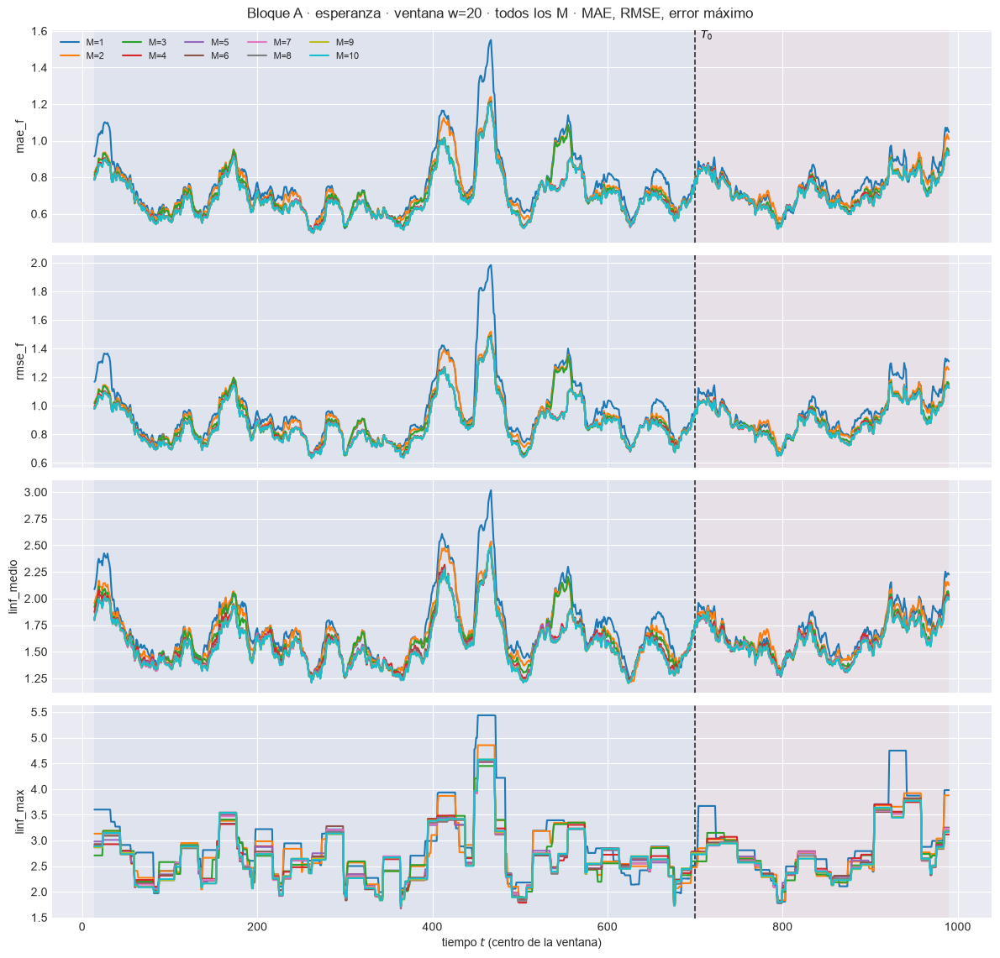

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.1s eta=0.2s  mae_f: w=30 train=0.666  w=30 test=0.7169


  2/4 (50.0%) t=0.1s eta=0.1s  rmse_f: w=30 train=0.8385  w=30 test=0.894


  3/4 (75.0%) t=0.2s eta=0.1s  linf_medio: w=30 train=1.544  w=30 test=1.589


  4/4 (100.0%) t=0.2s eta=0.0s  linf_max: w=30 train=2.755  w=30 test=2.768


[plot_ventana_movil] listo: 4 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_barrido_M\85_bloqueA_w30.png


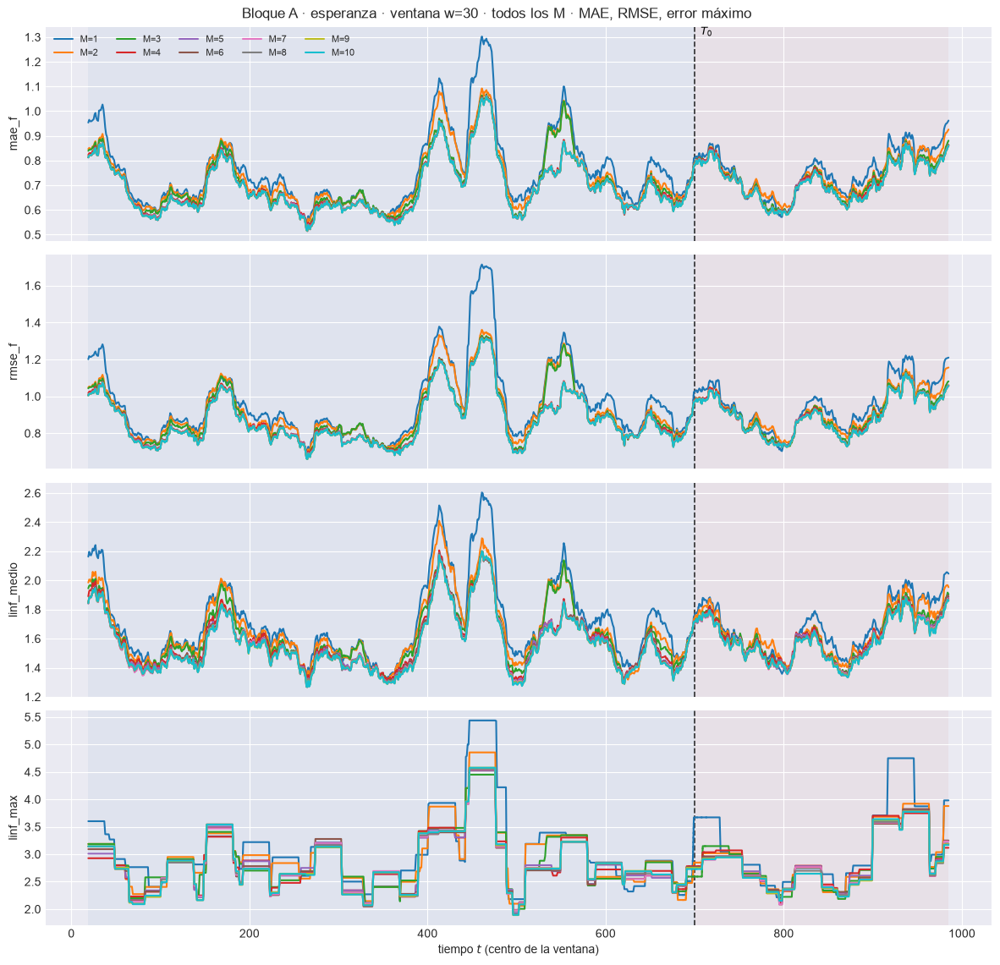

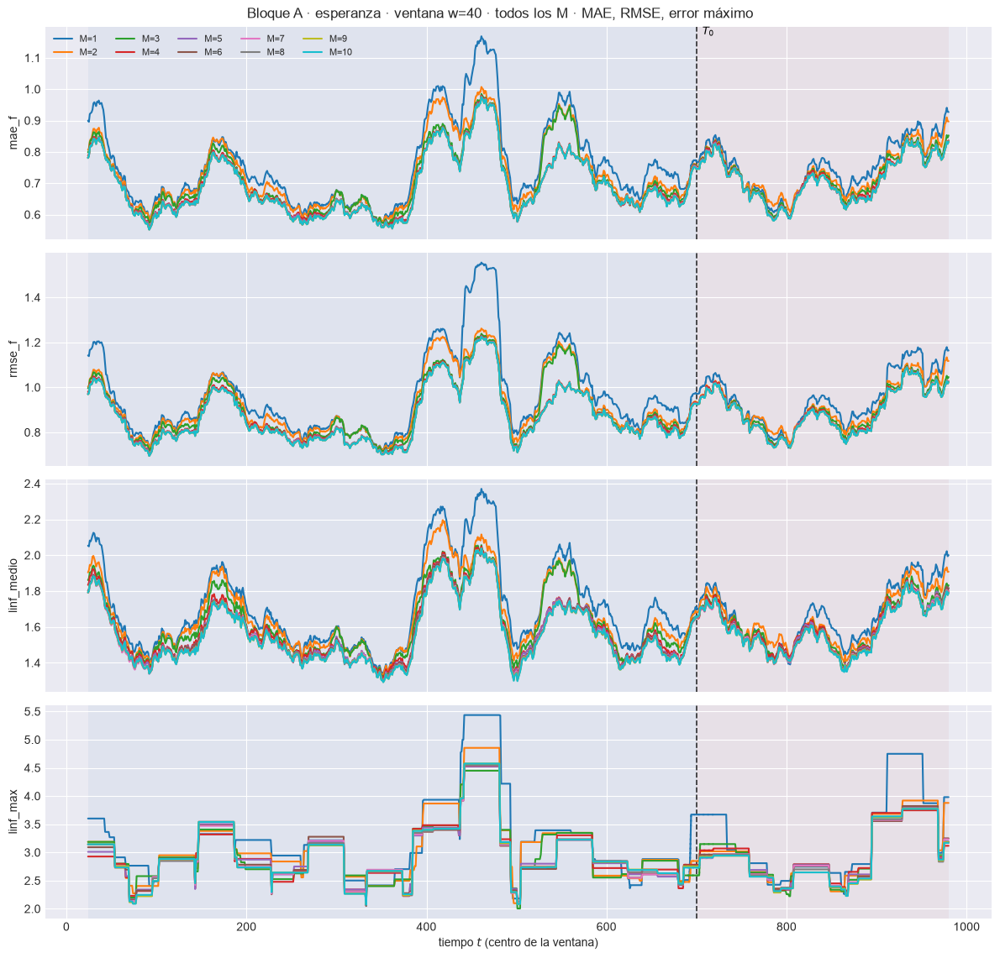

In [8]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU, predictores=PREDICTORES, intervalos=INTERVALOS)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · esperanza · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?

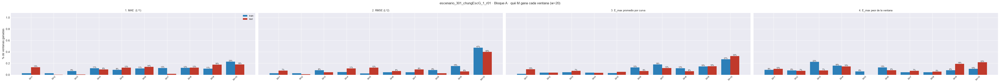

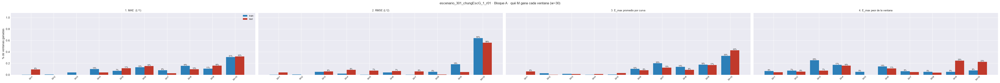

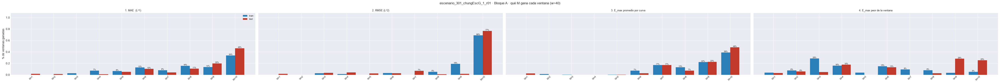

In [9]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

### 4.2 ¿Qué predictor gana cada ventana?

Bajo MAE ganan las medianas si la predictiva es multimodal o asimétrica; bajo RMSE, la esperanza.

In [10]:
for M in M_OK:
    EST[M]["ventana_pred"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas")
GANA_P, REL_P = ganadores_por_ventana(EST, "ventana_pred", "predictor", METRICAS_A, NIVEL)
GANA_P.to_csv(PATH_BARRIDO / "101b_ganador_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(GANA_P[(GANA_P.metrica == etiqueta) & (GANA_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada predictor (w={W_REF})"))

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,56.8%,29.5%,35.4%,46.1%,36.2%,39.5%,42.4%,40.6%,39.9%,40.6%
mediana,0.7%,21.4%,19.6%,29.5%,42.8%,41.3%,33.9%,35.4%,38.7%,36.2%
medoide,10.7%,17.7%,20.7%,6.3%,3.0%,1.8%,5.9%,5.9%,3.3%,5.2%
modal,31.7%,31.4%,24.4%,18.1%,18.1%,17.3%,17.7%,18.1%,18.1%,18.1%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,62.0%,44.6%,51.3%,62.7%,56.5%,56.1%,61.3%,59.0%,60.9%,63.1%
mediana,4.1%,13.7%,9.6%,21.0%,32.8%,31.4%,26.6%,31.7%,30.3%,28.0%
medoide,9.6%,16.6%,25.1%,7.0%,1.5%,3.7%,3.3%,0.4%,0.0%,0.0%
modal,24.4%,25.1%,14.0%,9.2%,9.2%,8.9%,8.9%,8.9%,8.9%,8.9%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,66.8%,40.6%,50.6%,54.6%,53.1%,63.1%,60.9%,61.3%,63.8%,62.7%
mediana,8.1%,5.9%,14.4%,22.5%,25.8%,22.5%,28.8%,24.4%,26.9%,28.0%
medoide,10.0%,14.4%,12.5%,4.4%,1.8%,0.7%,0.0%,0.4%,0.0%,0.0%
modal,15.1%,39.1%,22.5%,18.5%,19.2%,13.7%,10.3%,14.0%,9.2%,9.2%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,56.8%,46.9%,49.4%,38.7%,41.3%,36.5%,39.9%,41.7%,53.5%,53.9%
mediana,14.0%,6.6%,1.5%,3.3%,9.2%,11.1%,8.1%,1.8%,6.6%,6.3%
medoide,0.0%,21.0%,24.7%,36.9%,34.3%,35.8%,27.3%,30.3%,21.8%,16.2%
modal,29.2%,25.5%,24.4%,21.0%,15.1%,16.6%,24.7%,26.2%,18.1%,23.6%


### 4.3 Los cuatro predictores en la ventana móvil

`58_ventana_predictores_w<w>.png` por $M$ y `108_predictores_ventana_w30.png` en el barrido.

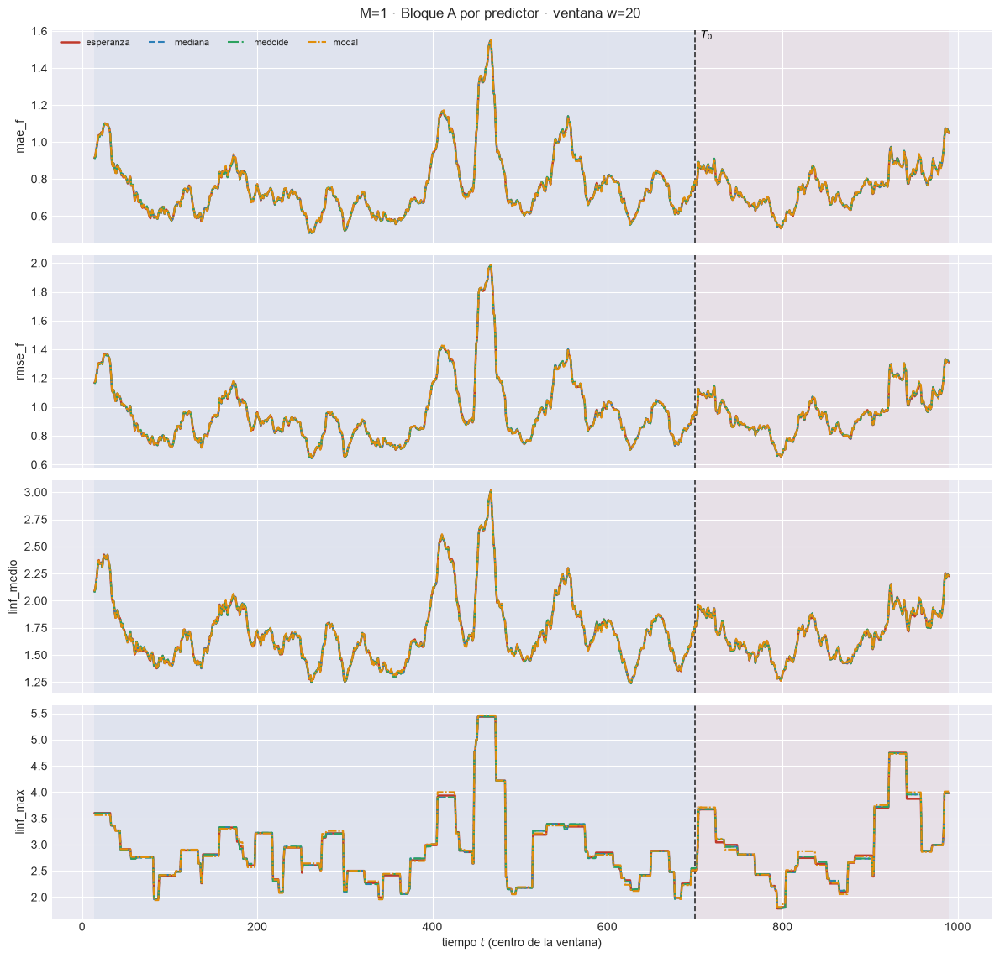

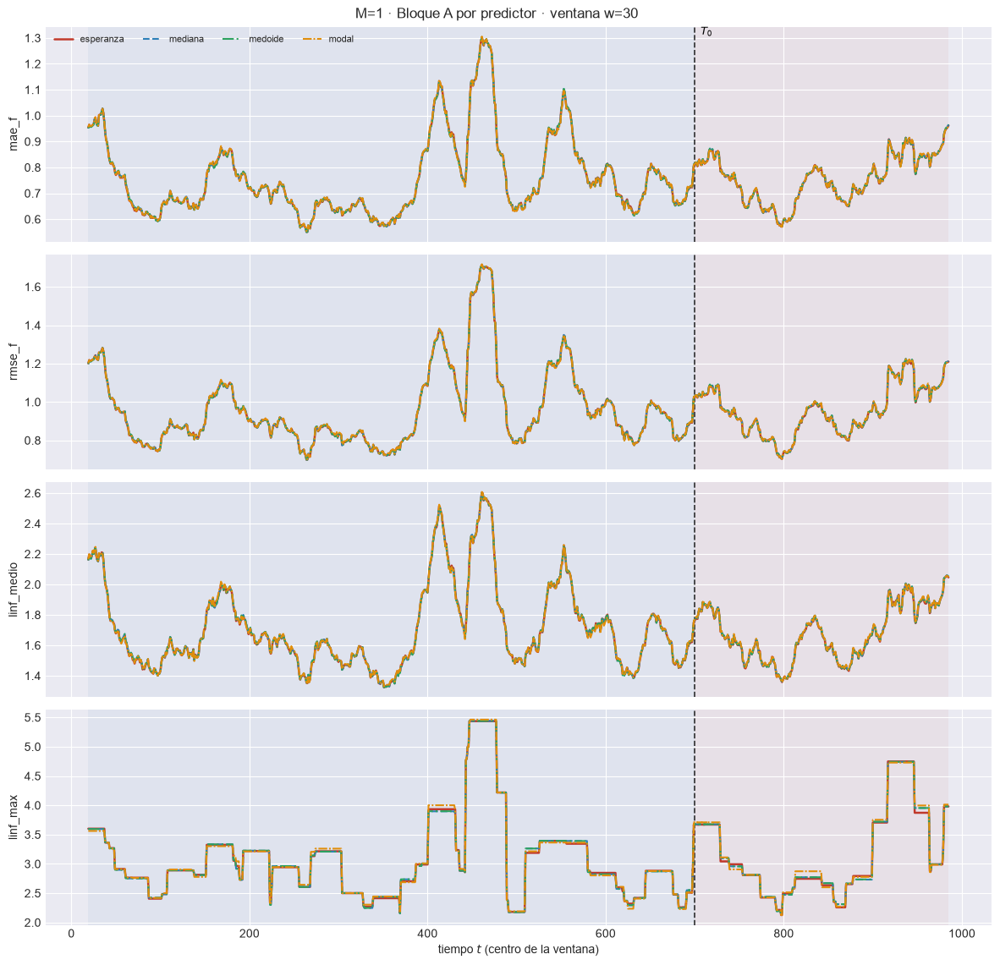

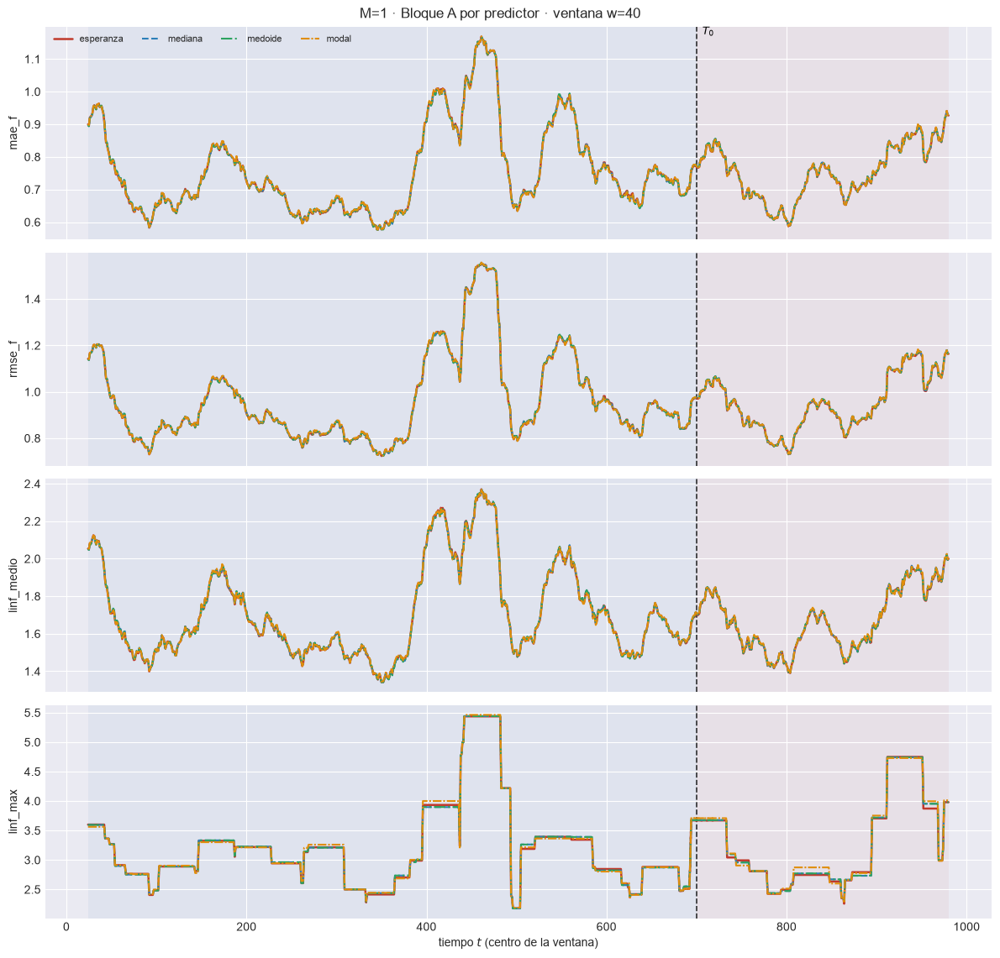

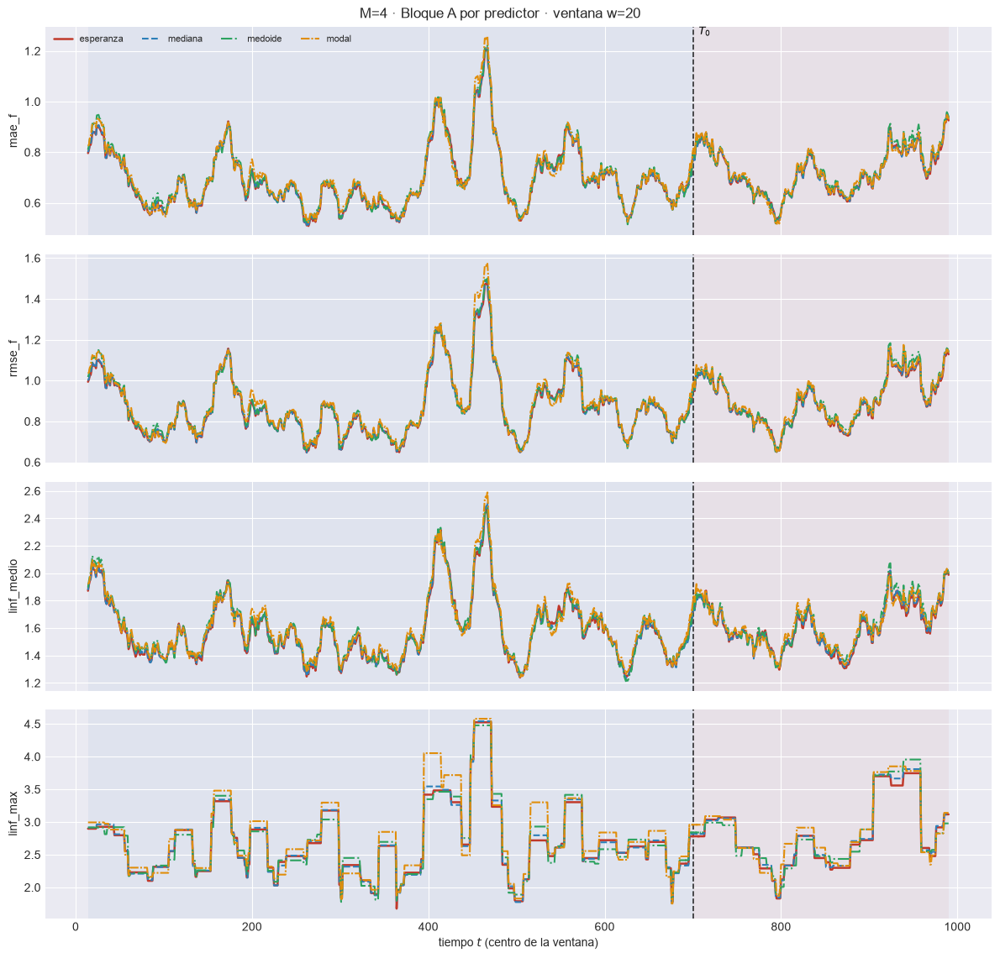

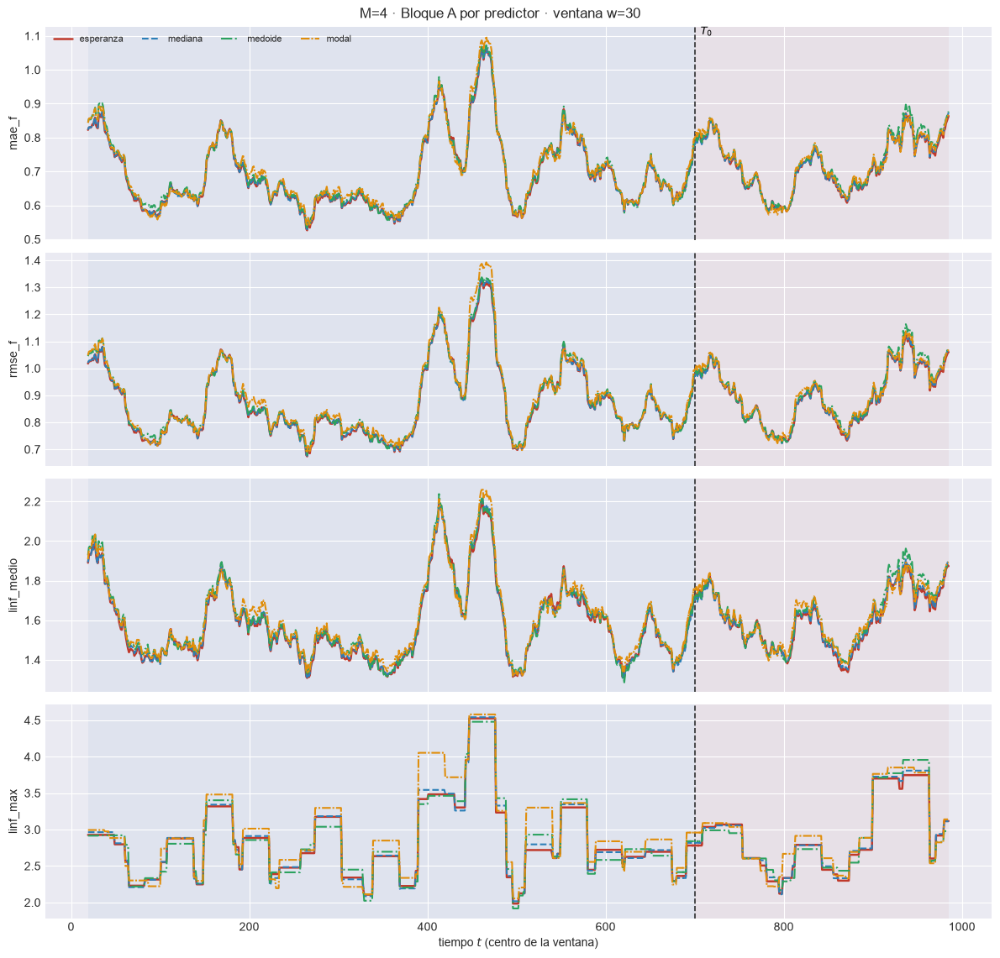

...

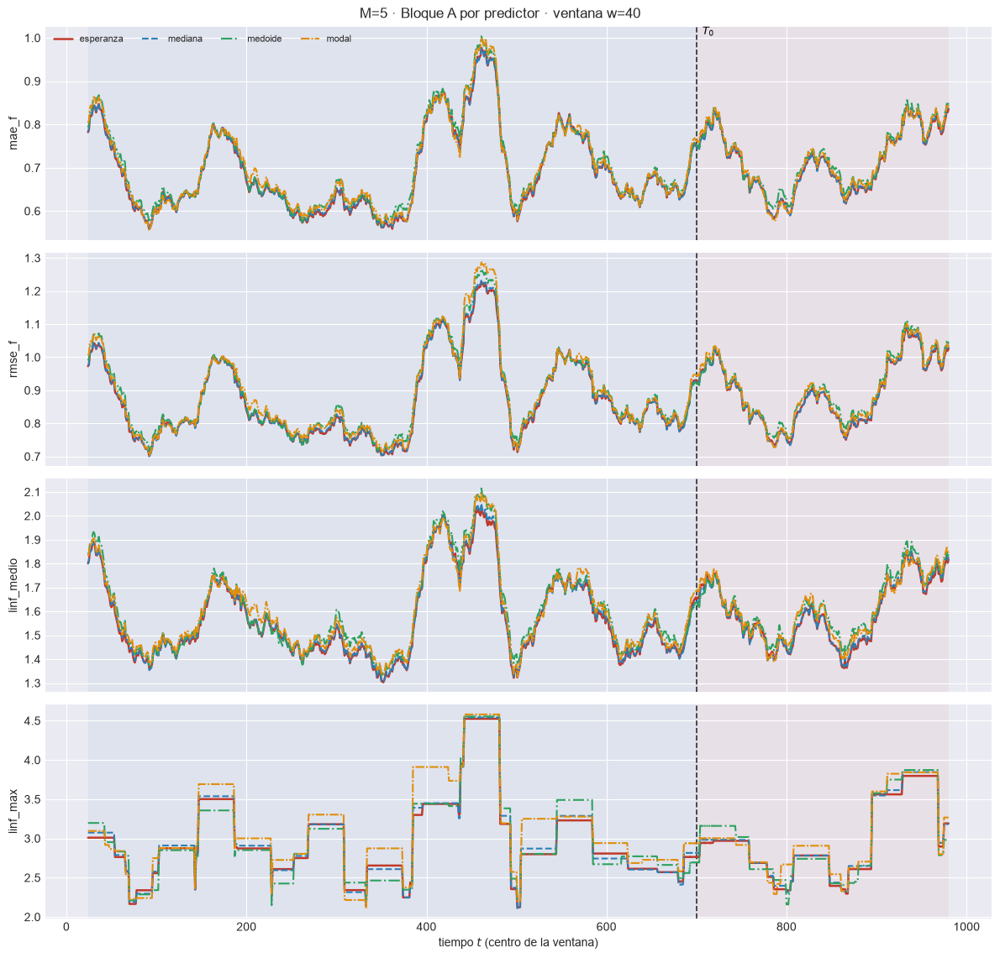

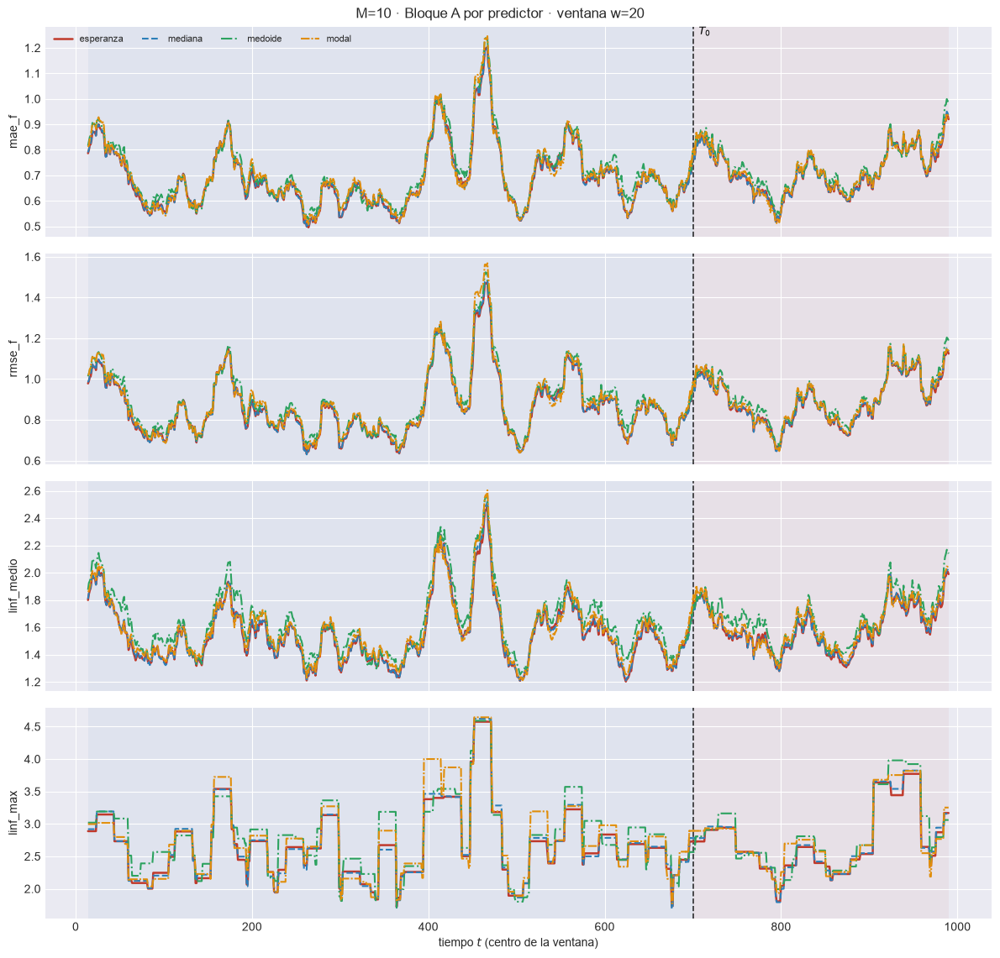

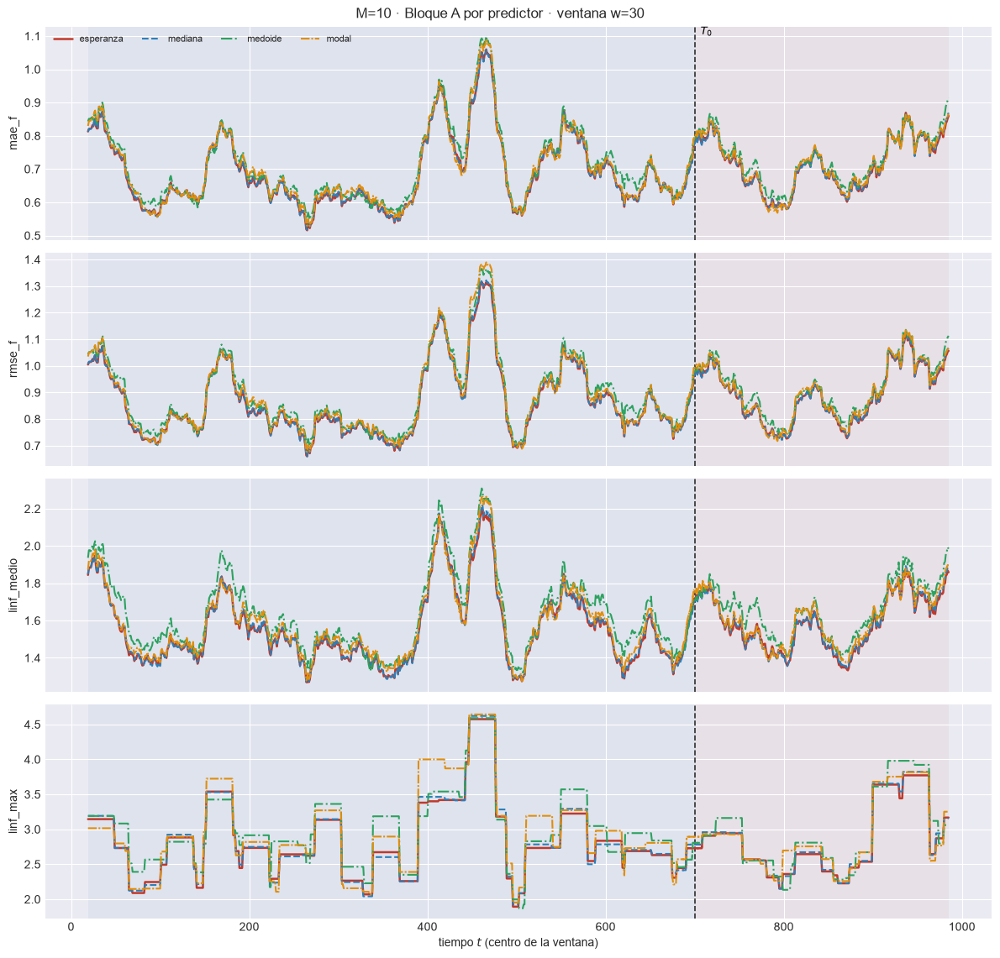

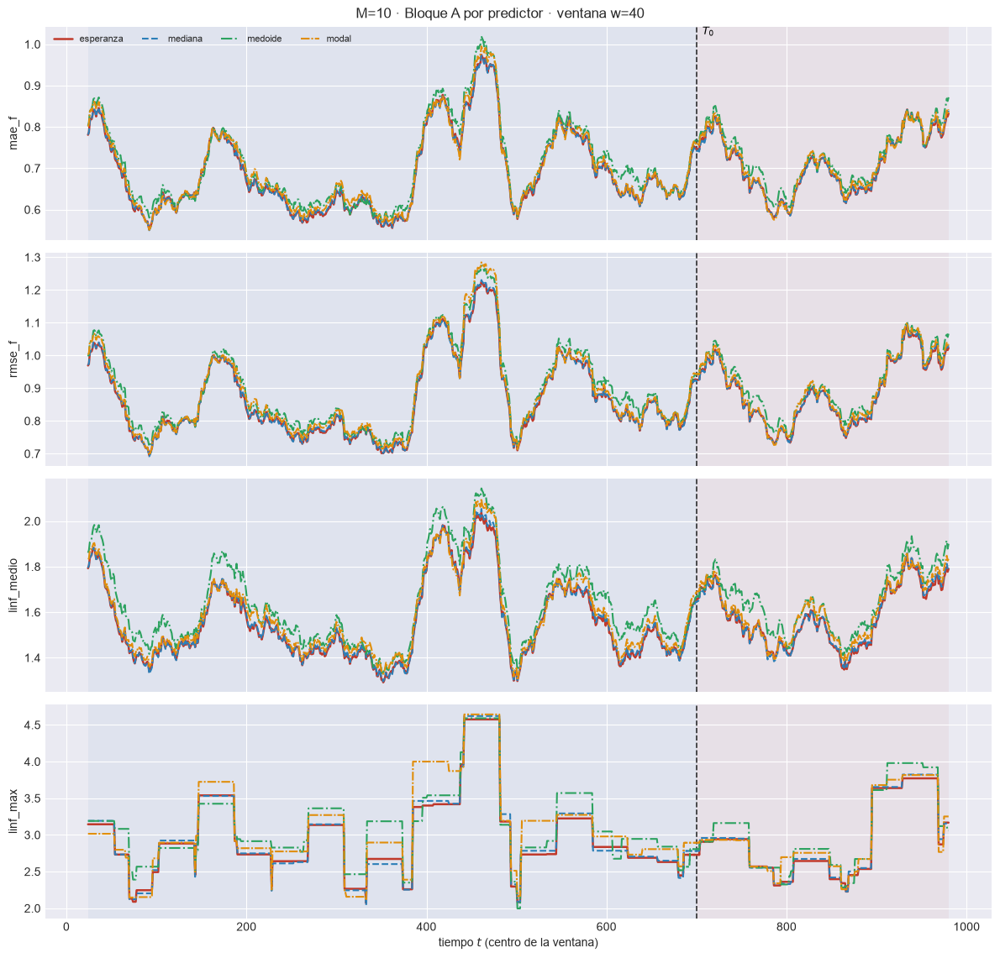

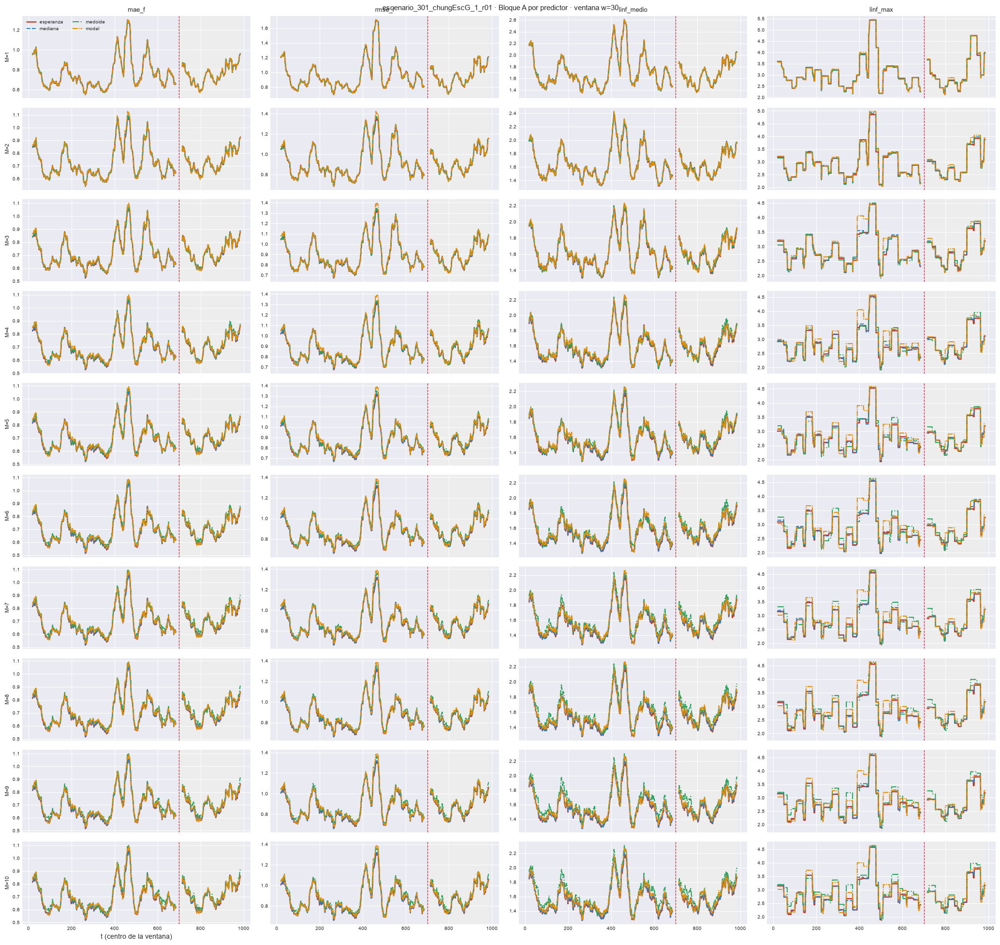

In [11]:
# Los cuatro predictores en la ventana móvil (con la equi-colas).
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        plot_ventana_movil(
            filtrar_ventana(EST[M]["tablas_fun"][w], intervalo="equicolas"), T0, METRICAS_A_COLS,
            columna_grupo="predictor", estilos=ESTILOS_PREDICTORES,
            title=f"M={M} · Bloque A por predictor · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"58_ventana_predictores_w{w}.png"), verbose=False)
        plt.show()
plot_ventana_grupos_por_M({M: filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas") for M in M_OK},
                          METRICAS_A_COLS, "predictor", T0, estilos=ESTILOS_PREDICTORES,
                          title=f"{EXPERIMENT_BASE} · Bloque A por predictor · ventana w={W_REF}",
                          save_path=PATH_BARRIDO / f"108_predictores_ventana_w{W_REF}.png")
plt.show()

## 5. Bloque B por construcción de intervalo

Equi-colas, banda simultánea y HDR puntual (docs §03_05_05) sobre las mismas extracciones; las seis métricas van sobre la unión de tramos. Las figuras de los $M$ superpuestos son de la equi-colas.

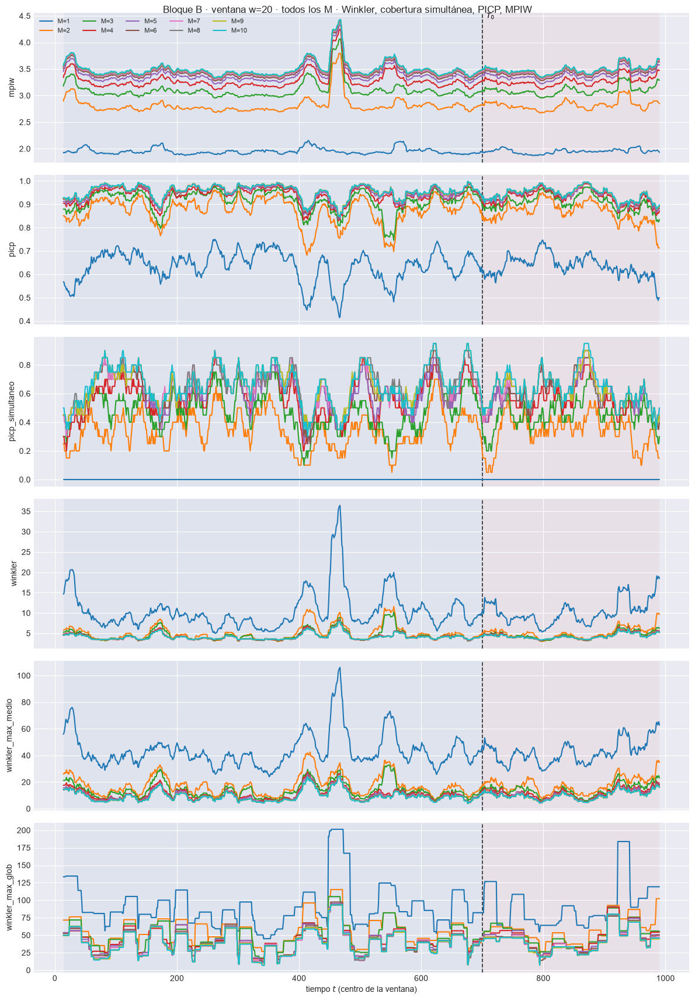

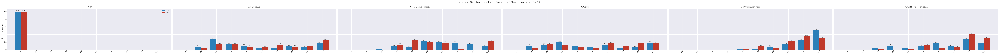

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.376  w=30 test=3.378


  2/6 (33.3%) t=0.1s eta=0.1s  picp: w=30 train=0.944  w=30 test=0.932


  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0.6  w=30 test=0.5667


  4/6 (66.7%) t=0.1s eta=0.1s  winkler: w=30 train=4.084  w=30 test=4.261


  5/6 (83.3%) t=0.2s eta=0.0s  winkler_max_medio: w=30 train=10.32  w=30 test=11.41


  6/6 (100.0%) t=0.2s eta=0.0s  winkler_max_glob: w=30 train=51.61  w=30 test=47.52


[plot_ventana_movil] listo: 6 pasos en 1.1s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_barrido_M\86_bloqueB_w30.png


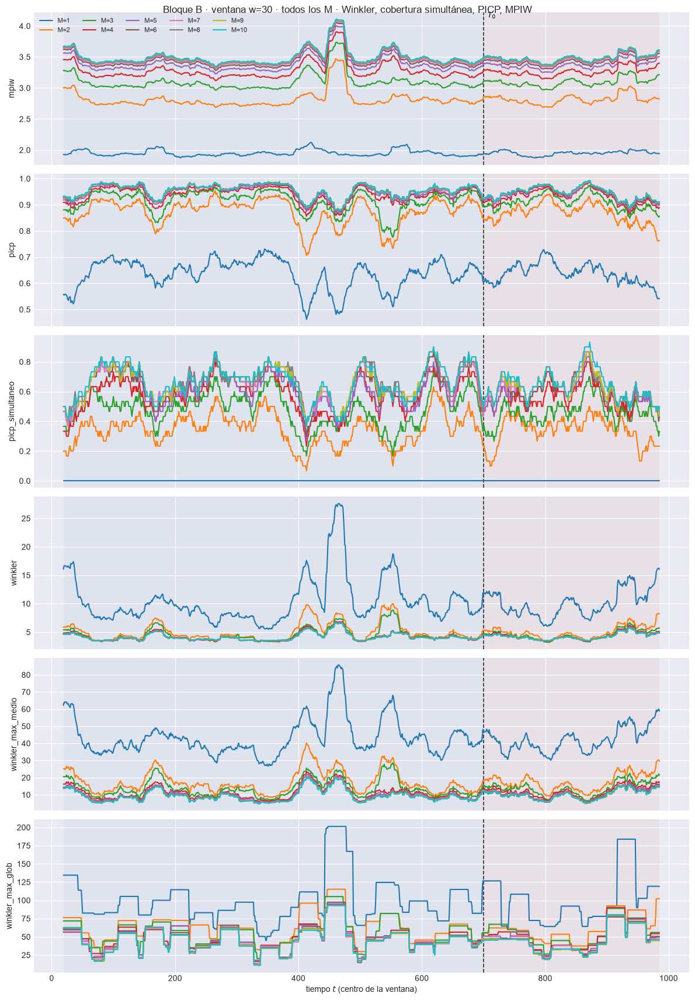

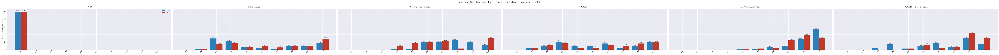

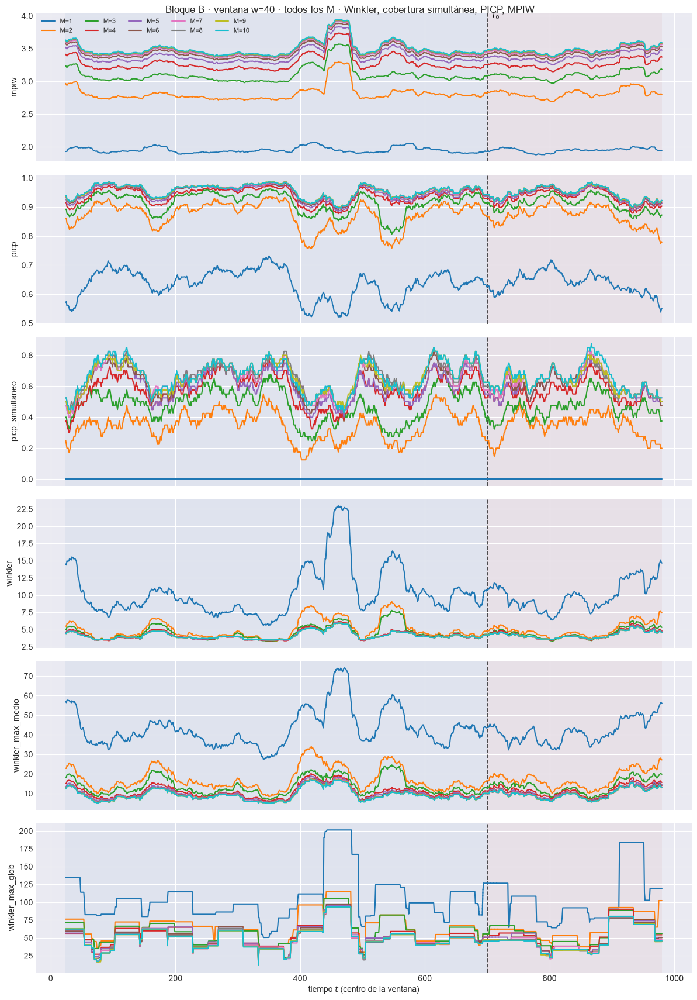

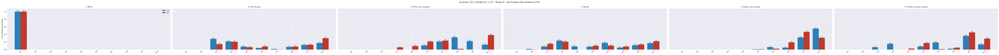

In [12]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

### 5.1 Las tres construcciones en la ventana móvil

`59_ventana_intervalos_w<w>.png` por $M$ y quién gana cada ventana (`109_*`). En PICP y PICPB gana la más cercana al nominal.

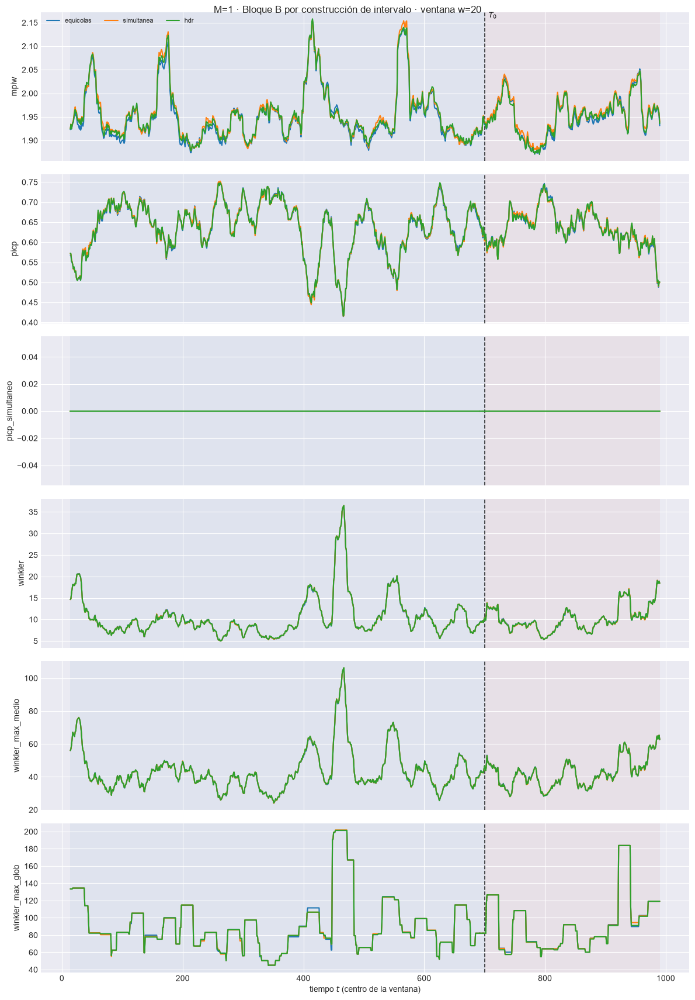

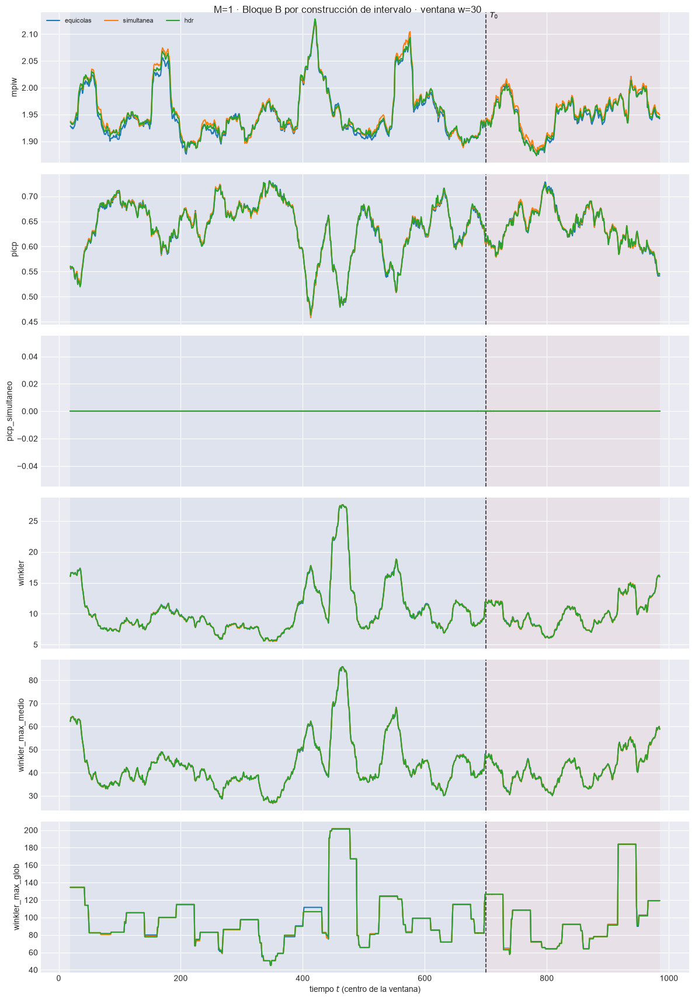

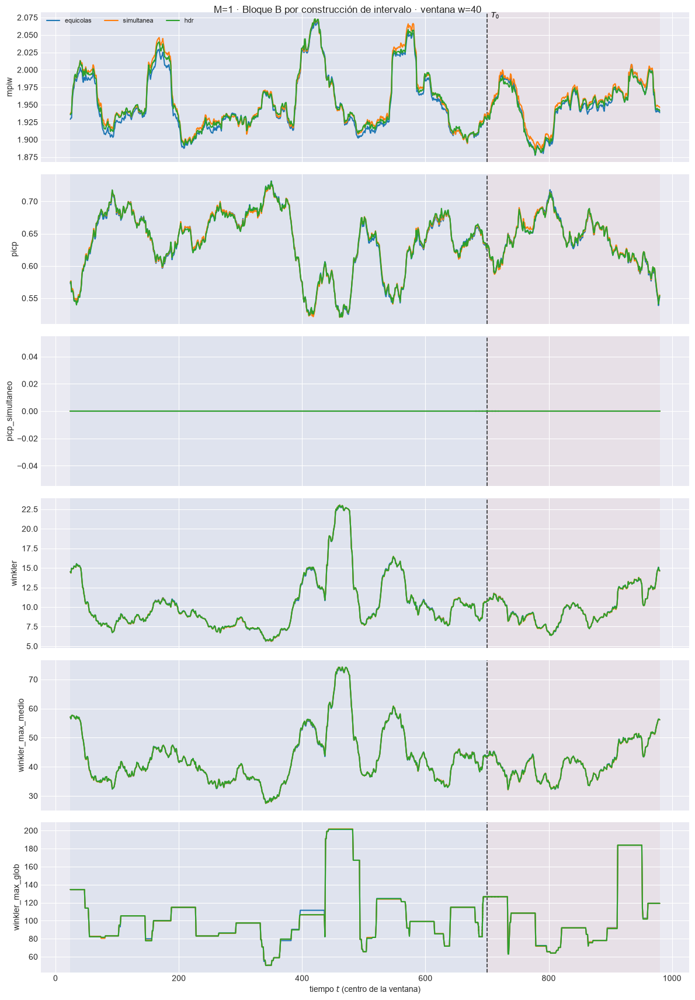

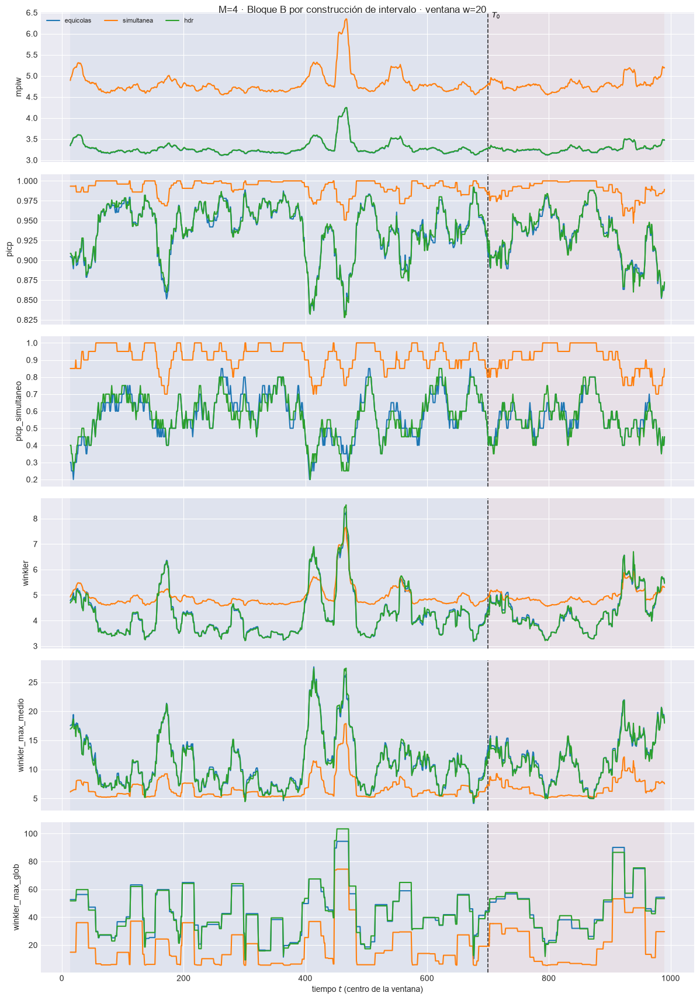

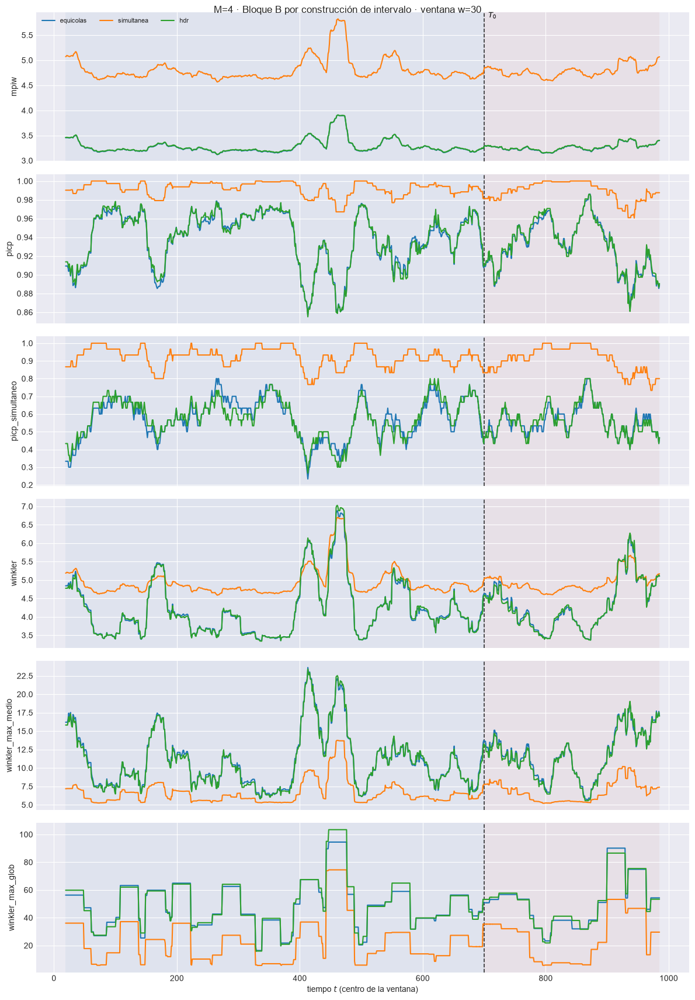

...

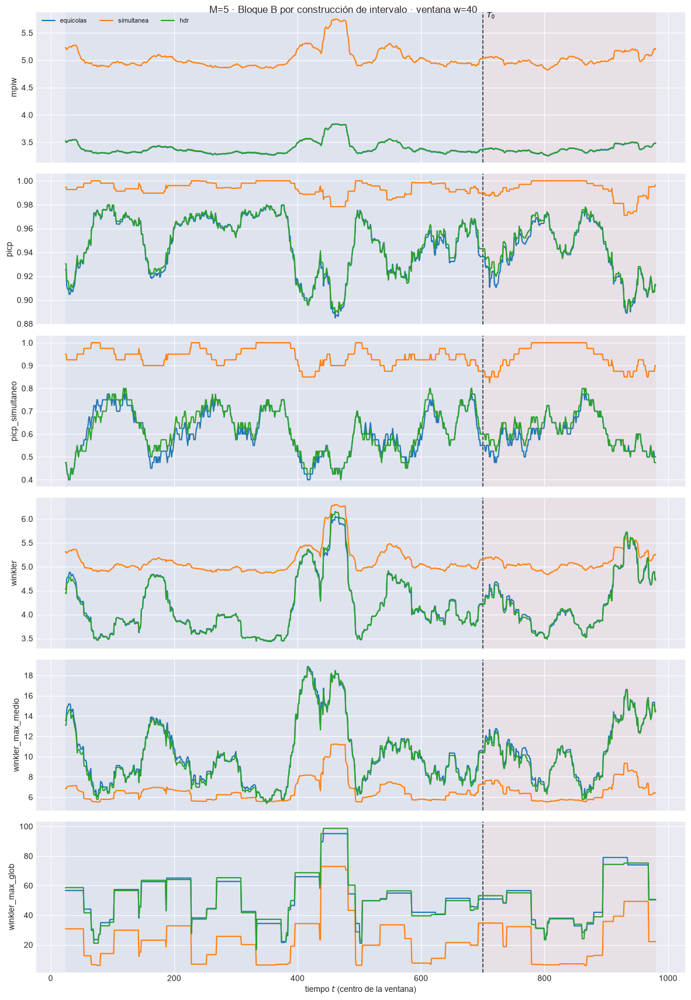

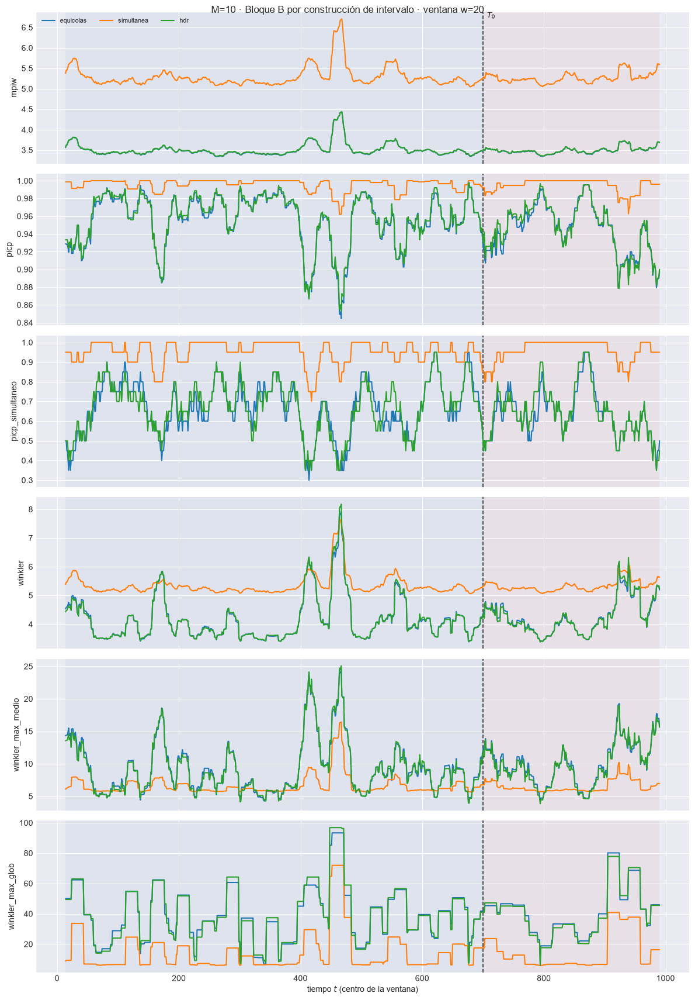

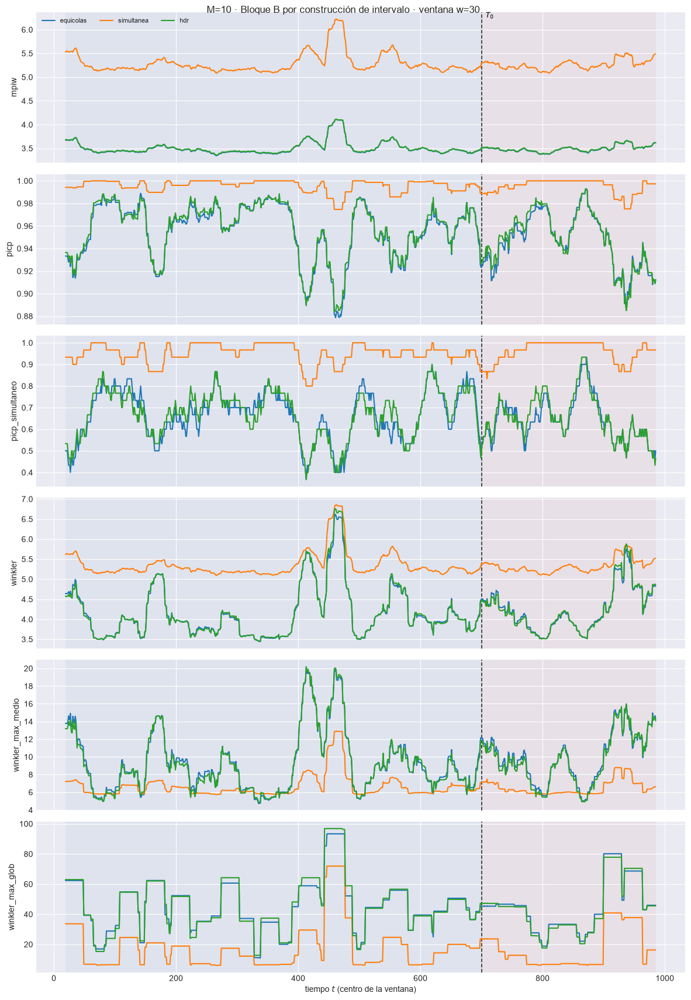

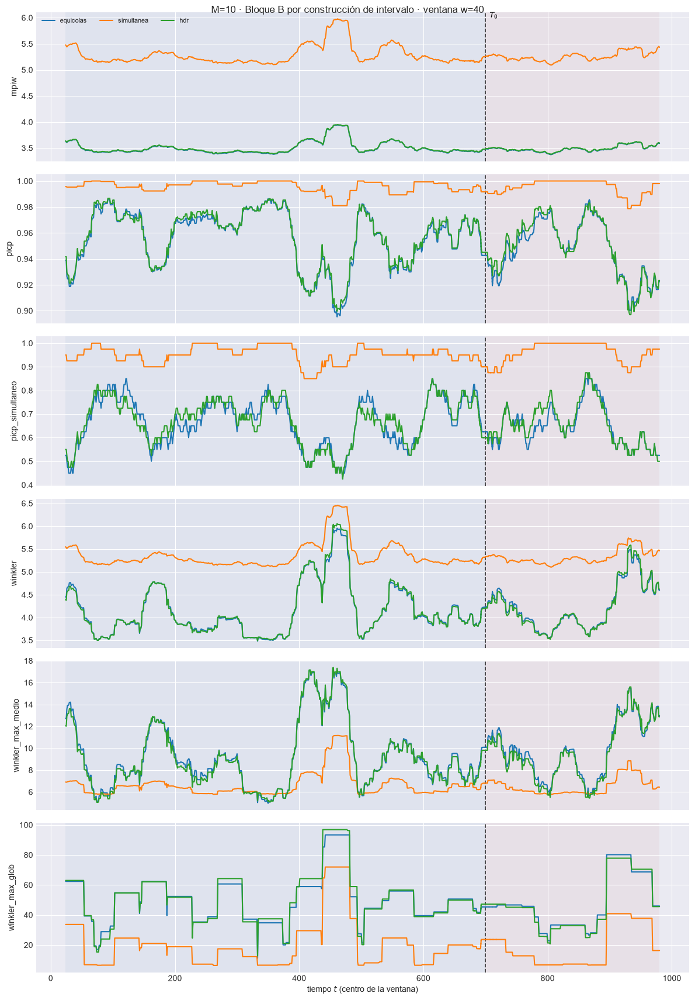

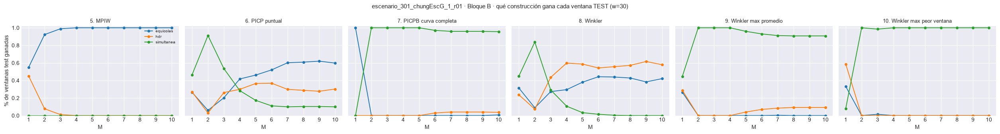

M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,55.0%,92.3%,98.9%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
simultanea,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
hdr,45.0%,7.7%,1.1%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,26.6%,5.9%,20.3%,41.7%,46.1%,52.0%,60.1%,60.9%,62.0%,59.8%
simultanea,46.5%,91.1%,53.5%,28.4%,17.3%,11.1%,10.0%,10.3%,10.3%,10.0%
hdr,26.9%,3.0%,26.2%,29.9%,36.5%,36.9%,29.9%,28.8%,27.7%,30.3%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.7%
simultanea,0.0%,100.0%,100.0%,100.0%,100.0%,97.0%,95.9%,95.9%,95.9%,95.6%
hdr,0.0%,0.0%,0.0%,0.0%,0.0%,3.0%,4.1%,4.1%,4.1%,3.7%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,31.4%,8.9%,27.3%,29.5%,38.0%,44.3%,43.9%,42.8%,38.4%,42.1%
simultanea,45.0%,83.8%,29.2%,10.7%,3.3%,1.5%,0.4%,0.0%,0.0%,0.0%
hdr,23.6%,7.4%,43.5%,59.8%,58.7%,54.2%,55.7%,57.2%,61.6%,57.9%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,26.6%,0.0%,0.0%,0.0%,0.0%,0.0%,0.4%,0.0%,0.0%,0.0%
simultanea,44.6%,100.0%,100.0%,100.0%,95.9%,93.0%,91.1%,90.8%,90.8%,90.8%
hdr,28.8%,0.0%,0.0%,0.0%,4.1%,7.0%,8.5%,9.2%,9.2%,9.2%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,33.2%,0.0%,1.5%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
simultanea,8.1%,100.0%,98.5%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
hdr,58.7%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


In [13]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        plot_ventana_movil(
            filtrar_ventana(EST[M]["tablas_fun"][w], predictor="esperanza"), T0, METRICAS_B_COLS,
            columna_grupo="intervalo", title=f"M={M} · Bloque B por construcción de intervalo · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"59_ventana_intervalos_w{w}.png"), verbose=False)
        plt.show()

for M in M_OK:
    EST[M]["ventana_int"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], predictor="esperanza")
GANA_I, REL_I = ganadores_por_ventana(EST, "ventana_int", "intervalo", METRICAS_B, NIVEL)
GANA_I.to_csv(PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.csv", index=False)
plot_ganador_grupo_vs_M(GANA_I, "intervalo", METRICAS_B,
                        f"{EXPERIMENT_BASE} · Bloque B · qué construcción gana cada ventana TEST (w={W_REF})",
                        save_path=PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.png")
plt.show()
for etiqueta, _c in METRICAS_B:
    display(GANA_I[(GANA_I.metrica == etiqueta) & (GANA_I.bloque == "test")]
            .pivot(index="intervalo", columns="M", values="pct_ventanas_ganadas").loc[list(INTERVALOS)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST que gana cada construcción (w={W_REF})"))

## 6. Muestra de predicciones

Ventana de detalle, frontera train/test y ventanas con peor `METRICA_PEORES`.

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=931 [test] cob=0.427 rmse=1.534


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.253 rmse=3.188


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=0.293 rmse=1.866


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=0.693 rmse=0.7897


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=0.853 rmse=0.4881


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=0.840 rmse=0.4882


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=0.680 rmse=0.5271


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=0.600 rmse=0.7667


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=0.733 rmse=0.6297


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.600 rmse=0.9808


[plot_extractos_curvas] listo: 10 pasos en 1.0s  cob media train=nan test=0.597 (nominal 0.95)


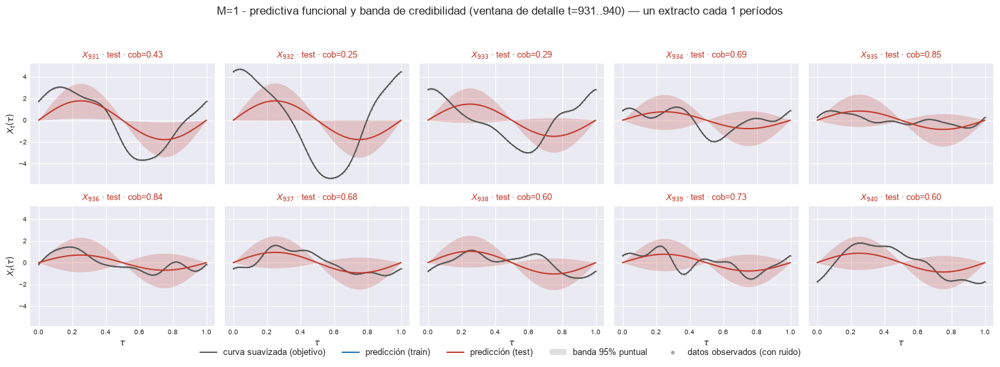

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=931 [test] cob=1.000 rmse=1.018


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.427 rmse=2.402


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=1.000 rmse=0.8701


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=1.000 rmse=0.79


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=1.000 rmse=0.4914


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=1.000 rmse=0.4569


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=1.000 rmse=0.6512


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=1.000 rmse=0.6487


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=0.920 rmse=0.7374


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.760 rmse=1.064


[plot_extractos_curvas] listo: 10 pasos en 1.2s  cob media train=nan test=0.911 (nominal 0.95)


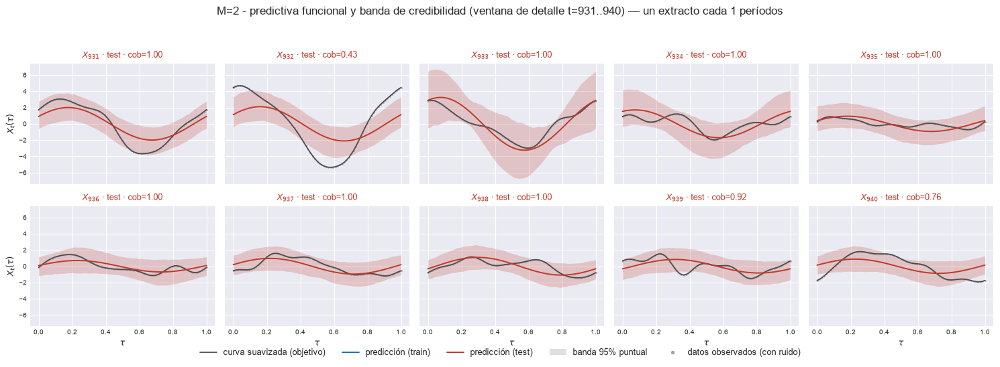

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=931 [test] cob=1.000 rmse=1.04


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.440 rmse=2.371


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=1.000 rmse=0.8238


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=1.000 rmse=0.7484


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=1.000 rmse=0.5924


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=1.000 rmse=0.4313


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=1.000 rmse=0.6685


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=1.000 rmse=0.6707


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=1.000 rmse=0.6608


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.787 rmse=1.061


[plot_extractos_curvas] listo: 10 pasos en 1.0s  cob media train=nan test=0.923 (nominal 0.95)


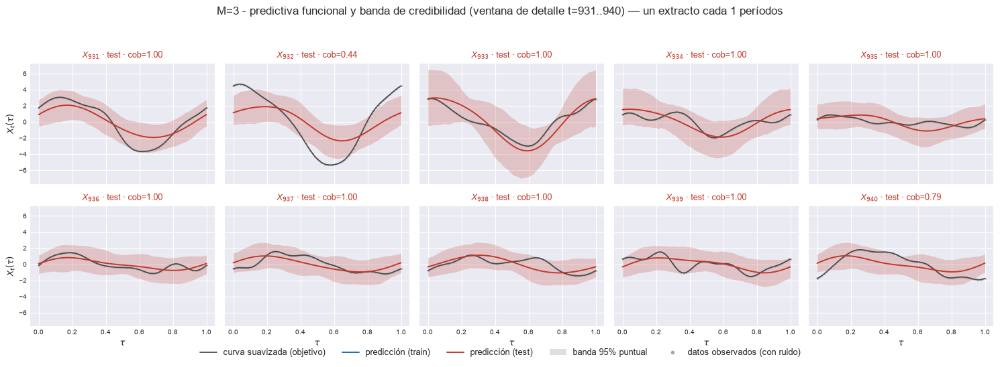

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=931 [test] cob=0.987 rmse=1.04


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.440 rmse=2.371


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=1.000 rmse=0.8246


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=1.000 rmse=0.77


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=1.000 rmse=0.597


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=1.000 rmse=0.4241


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=1.000 rmse=0.6616


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=1.000 rmse=0.6579


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=1.000 rmse=0.7029


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.853 rmse=1.091


[plot_extractos_curvas] listo: 10 pasos en 1.0s  cob media train=nan test=0.928 (nominal 0.95)


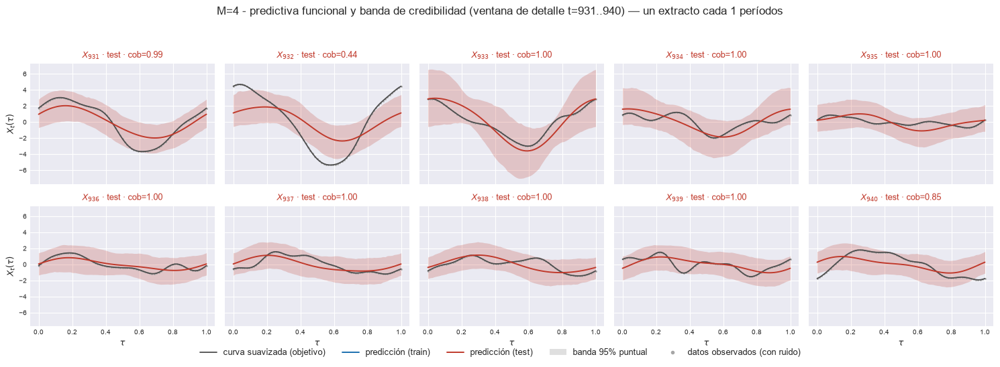

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=931 [test] cob=1.000 rmse=1.025


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.453 rmse=2.37


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=1.000 rmse=0.8175


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=1.000 rmse=0.7441


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=1.000 rmse=0.5837


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=1.000 rmse=0.4224


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=1.000 rmse=0.6632


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=1.000 rmse=0.6554


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=1.000 rmse=0.6932


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.867 rmse=1.087


[plot_extractos_curvas] listo: 10 pasos en 1.1s  cob media train=nan test=0.932 (nominal 0.95)


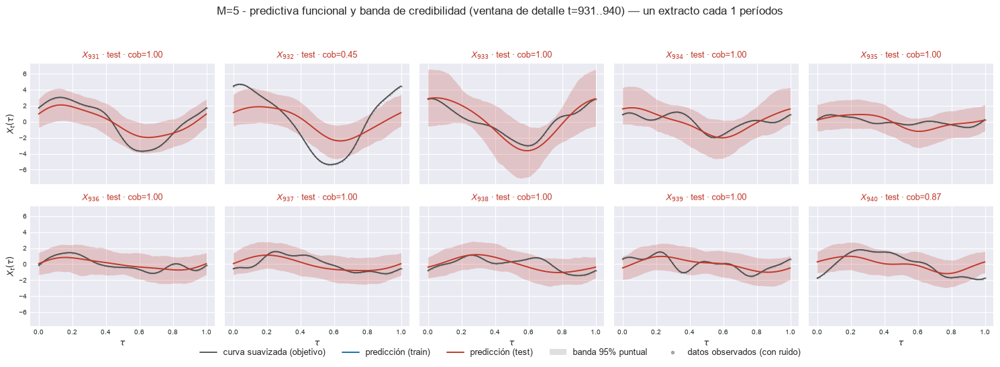

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=931 [test] cob=1.000 rmse=1.025


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.453 rmse=2.37


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=1.000 rmse=0.8165


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=1.000 rmse=0.7343


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=1.000 rmse=0.5868


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=1.000 rmse=0.4301


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=1.000 rmse=0.6617


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=1.000 rmse=0.6575


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=1.000 rmse=0.6987


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.867 rmse=1.084


[plot_extractos_curvas] listo: 10 pasos en 1.0s  cob media train=nan test=0.932 (nominal 0.95)


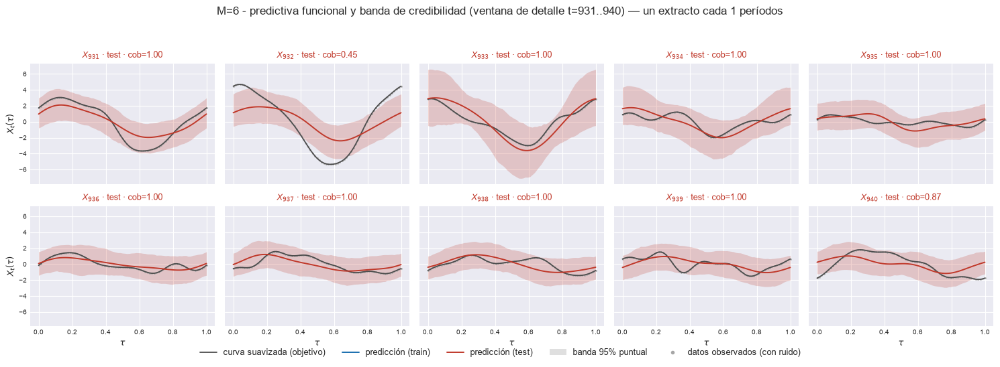

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=931 [test] cob=1.000 rmse=1.025


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.467 rmse=2.37


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=1.000 rmse=0.8151


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=1.000 rmse=0.7328


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=1.000 rmse=0.5875


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=1.000 rmse=0.4317


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=1.000 rmse=0.6634


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=1.000 rmse=0.6575


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=1.000 rmse=0.6983


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.867 rmse=1.082


[plot_extractos_curvas] listo: 10 pasos en 1.3s  cob media train=nan test=0.933 (nominal 0.95)


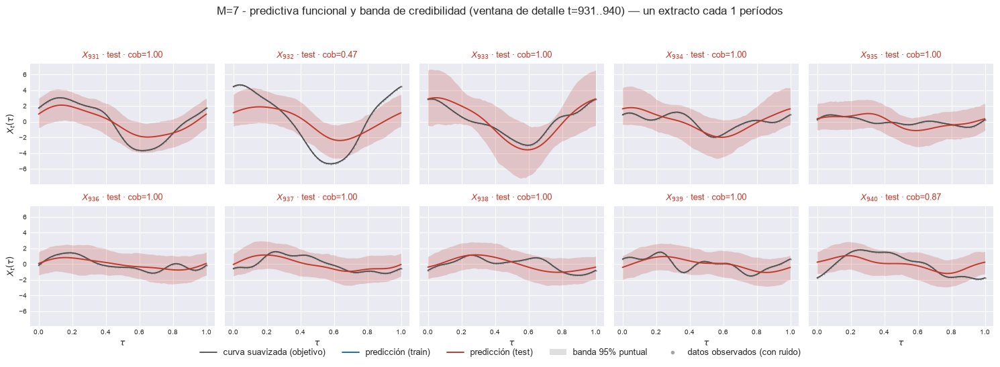

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=931 [test] cob=1.000 rmse=1.021


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.480 rmse=2.372


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=1.000 rmse=0.8172


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=1.000 rmse=0.7338


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=1.000 rmse=0.5877


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=1.000 rmse=0.4318


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=1.000 rmse=0.6643


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=1.000 rmse=0.656


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=1.000 rmse=0.6956


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.867 rmse=1.087


[plot_extractos_curvas] listo: 10 pasos en 1.0s  cob media train=nan test=0.935 (nominal 0.95)


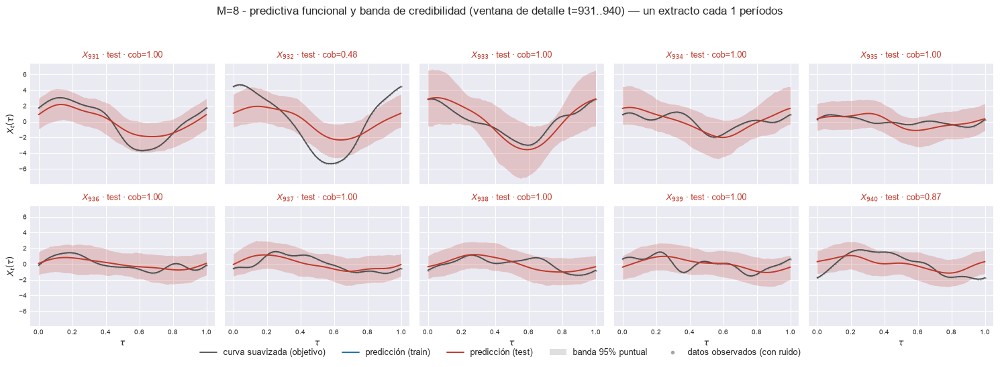

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.1s  t=931 [test] cob=1.000 rmse=1.023


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.480 rmse=2.372


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=1.000 rmse=0.8179


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=1.000 rmse=0.735


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=1.000 rmse=0.586


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=1.000 rmse=0.4301


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=1.000 rmse=0.6626


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=1.000 rmse=0.6537


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=1.000 rmse=0.6895


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.867 rmse=1.084


[plot_extractos_curvas] listo: 10 pasos en 1.0s  cob media train=nan test=0.935 (nominal 0.95)


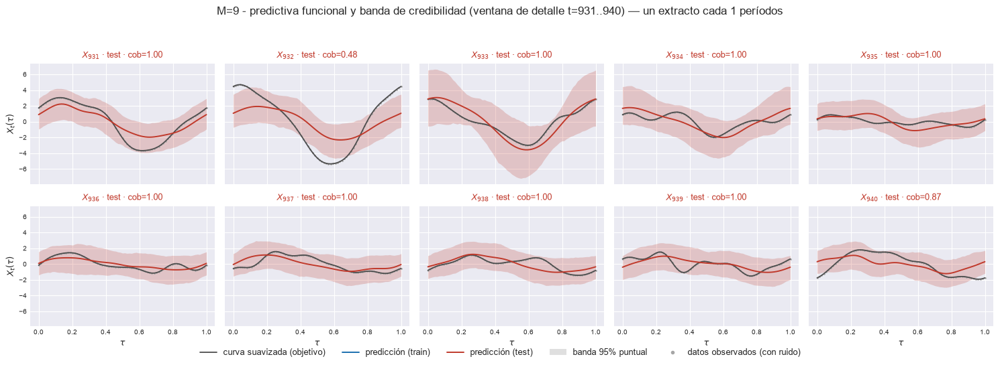

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=931 [test] cob=1.000 rmse=1.023


  2/10 (20.0%) t=0.0s eta=0.0s  t=932 [test] cob=0.493 rmse=2.371


  3/10 (30.0%) t=0.0s eta=0.0s  t=933 [test] cob=1.000 rmse=0.8174


  4/10 (40.0%) t=0.0s eta=0.0s  t=934 [test] cob=1.000 rmse=0.7348


  5/10 (50.0%) t=0.0s eta=0.0s  t=935 [test] cob=1.000 rmse=0.5859


  6/10 (60.0%) t=0.0s eta=0.0s  t=936 [test] cob=1.000 rmse=0.4297


  7/10 (70.0%) t=0.0s eta=0.0s  t=937 [test] cob=1.000 rmse=0.6613


  8/10 (80.0%) t=0.0s eta=0.0s  t=938 [test] cob=1.000 rmse=0.6552


  9/10 (90.0%) t=0.0s eta=0.0s  t=939 [test] cob=1.000 rmse=0.69


  10/10 (100.0%) t=0.0s eta=0.0s  t=940 [test] cob=0.867 rmse=1.085


[plot_extractos_curvas] listo: 10 pasos en 1.2s  cob media train=nan test=0.936 (nominal 0.95)


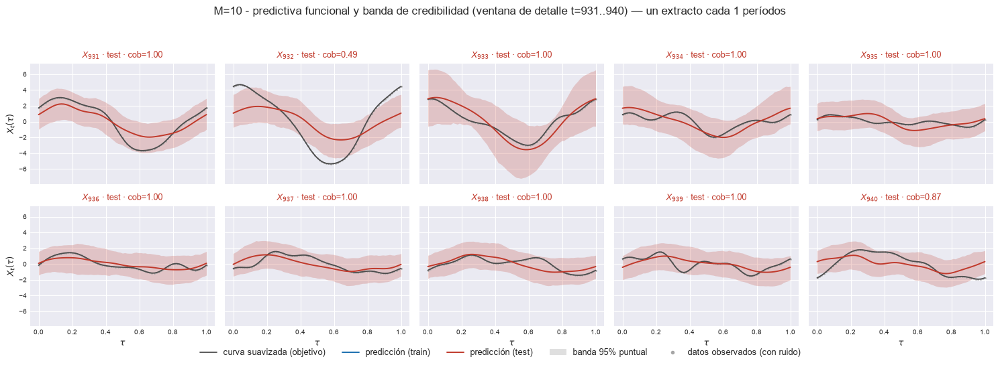

In [14]:
# Los orígenes de la ventana de detalle.
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[MASK_DET], e["X_pred"][MASK_DET], e["li_f"][MASK_DET], e["ls_f"][MASK_DET],
        grilla, T0, t=t_orig[MASK_DET], cada=1, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[MASK_DET],
        title=f"M={M} - predictiva funcional y banda de credibilidad (ventana de detalle t={T0_DET}..{T0_DET + N_DETALLE - 1})",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=0.613 rmse=0.8088


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.547 rmse=1.062


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.733 rmse=0.7137


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.653 rmse=0.7625


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.600 rmse=0.8485


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.520 rmse=0.908


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.600 rmse=1.024


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=0.637 test=0.573 (nominal 0.95)


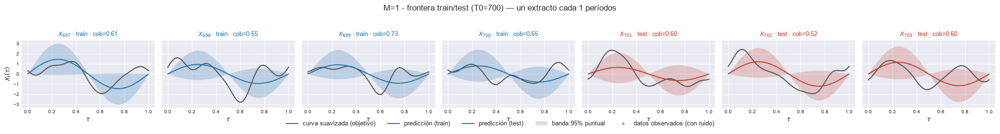

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.7386


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.800 rmse=0.9506


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.947 rmse=0.6236


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.933 rmse=0.6589


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.907 rmse=0.8176


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.947 rmse=0.8014


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.827 rmse=0.9649


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=0.920 test=0.893 (nominal 0.95)


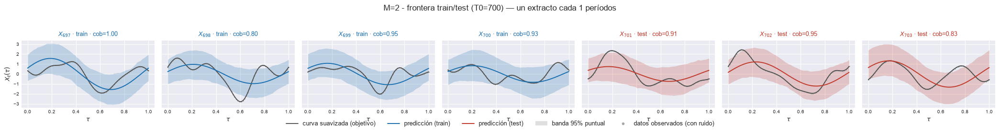

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.8499


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.960 rmse=0.8772


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.960 rmse=0.5598


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.6779


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.947 rmse=0.8124


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=1.000 rmse=0.8069


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.867 rmse=0.9579


[plot_extractos_curvas] listo: 7 pasos en 0.9s  cob media train=0.980 test=0.938 (nominal 0.95)


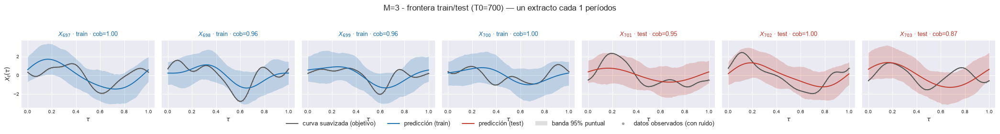

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.8616


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=1.000 rmse=0.8628


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=1.000 rmse=0.5049


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.7026


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.933 rmse=0.8351


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=1.000 rmse=0.8765


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.893 rmse=1.008


[plot_extractos_curvas] listo: 7 pasos en 1.0s  cob media train=1.000 test=0.942 (nominal 0.95)


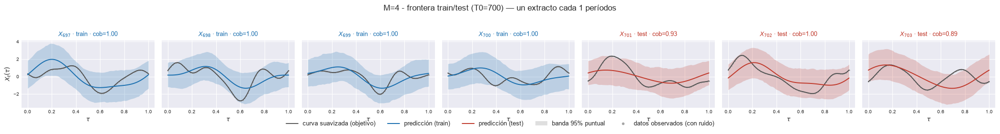

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.8628


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=1.000 rmse=0.8527


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=1.000 rmse=0.3912


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.987 rmse=0.7709


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.8267


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=1.000 rmse=0.8826


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.893 rmse=1.006


[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.997 test=0.964 (nominal 0.95)


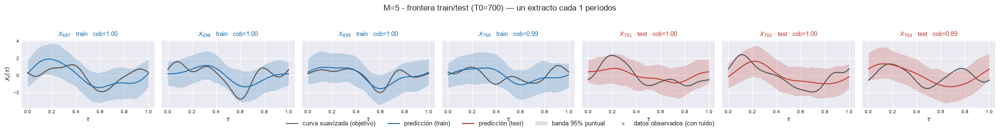

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.8622


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=1.000 rmse=0.8527


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=1.000 rmse=0.3913


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.987 rmse=0.7722


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.8321


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=1.000 rmse=0.8859


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.907 rmse=1.003


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=0.997 test=0.969 (nominal 0.95)


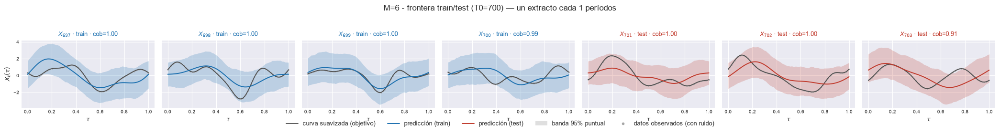

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.8611


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=1.000 rmse=0.8625


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=1.000 rmse=0.4


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.987 rmse=0.7711


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.8303


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=1.000 rmse=0.8881


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.907 rmse=1.002


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=0.997 test=0.969 (nominal 0.95)


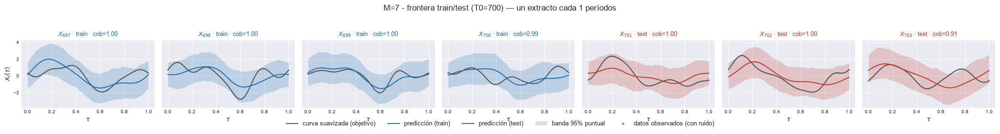

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.8615


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=1.000 rmse=0.8639


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=1.000 rmse=0.3919


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.7711


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.8299


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=1.000 rmse=0.8829


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.907 rmse=0.9998


[plot_extractos_curvas] listo: 7 pasos en 1.0s  cob media train=1.000 test=0.969 (nominal 0.95)


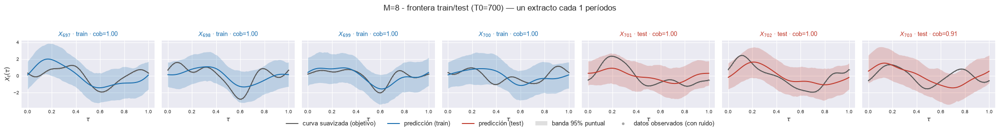

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.8617


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=1.000 rmse=0.8637


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=1.000 rmse=0.3911


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.7712


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.8297


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=1.000 rmse=0.8842


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.893 rmse=1


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=1.000 test=0.964 (nominal 0.95)


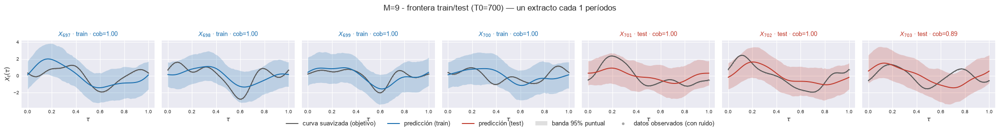

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.8615


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=1.000 rmse=0.8642


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=1.000 rmse=0.3887


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.7703


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.829


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=1.000 rmse=0.884


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.893 rmse=1


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=1.000 test=0.964 (nominal 0.95)


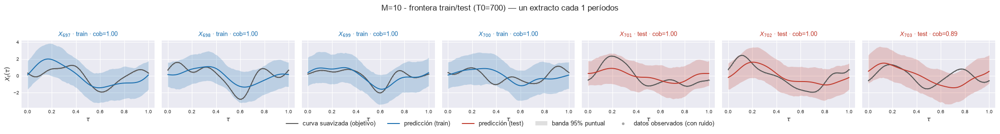

In [15]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=1] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[923, 952]  rmse_f=1.221402


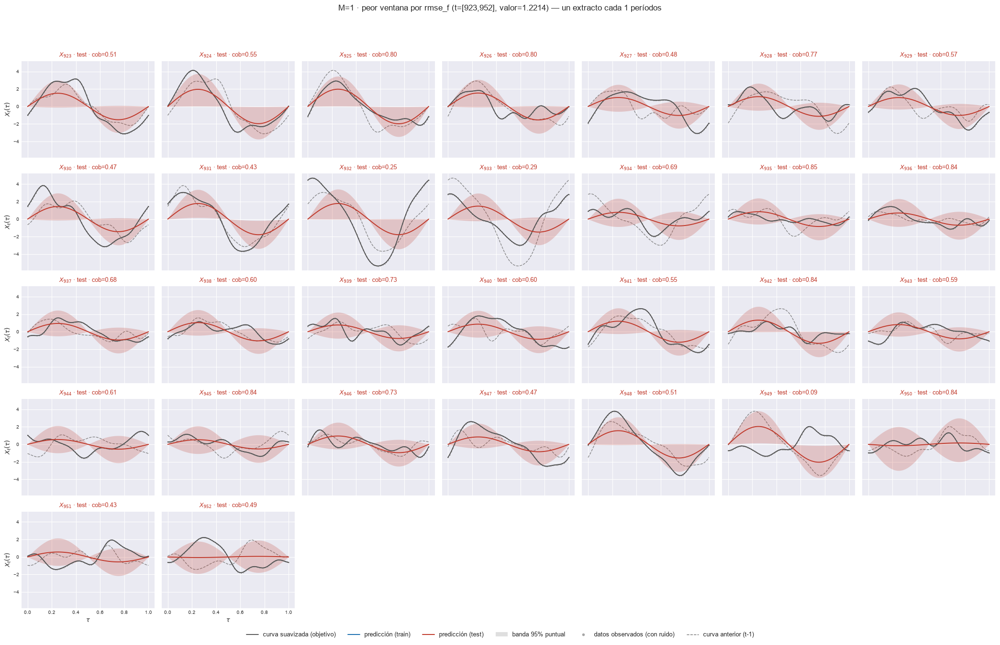

    t=[930, 959]  rmse_f=1.216939


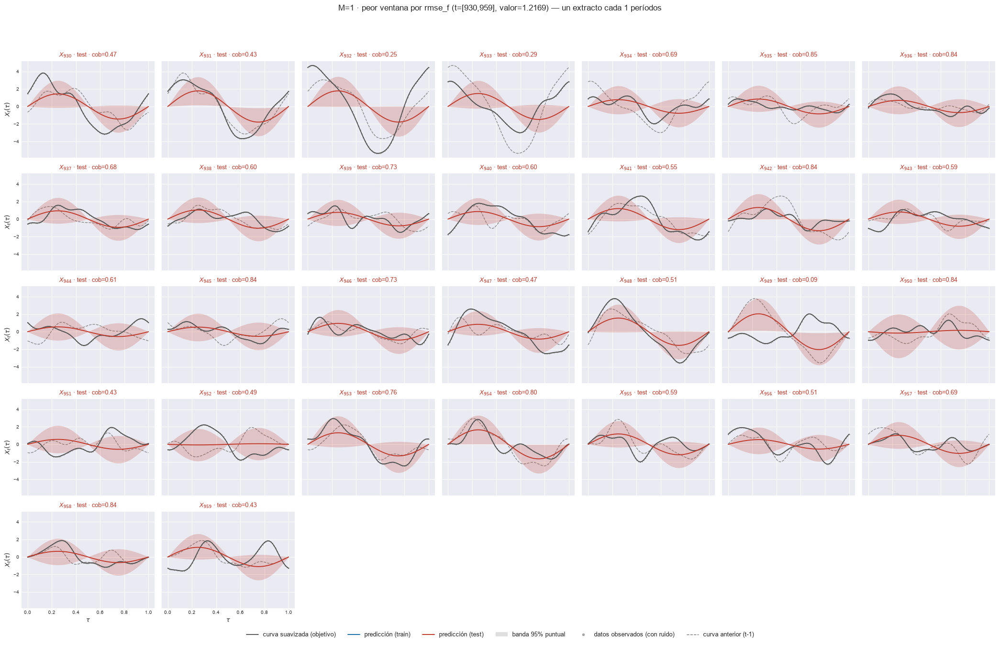

    t=[927, 956]  rmse_f=1.216190


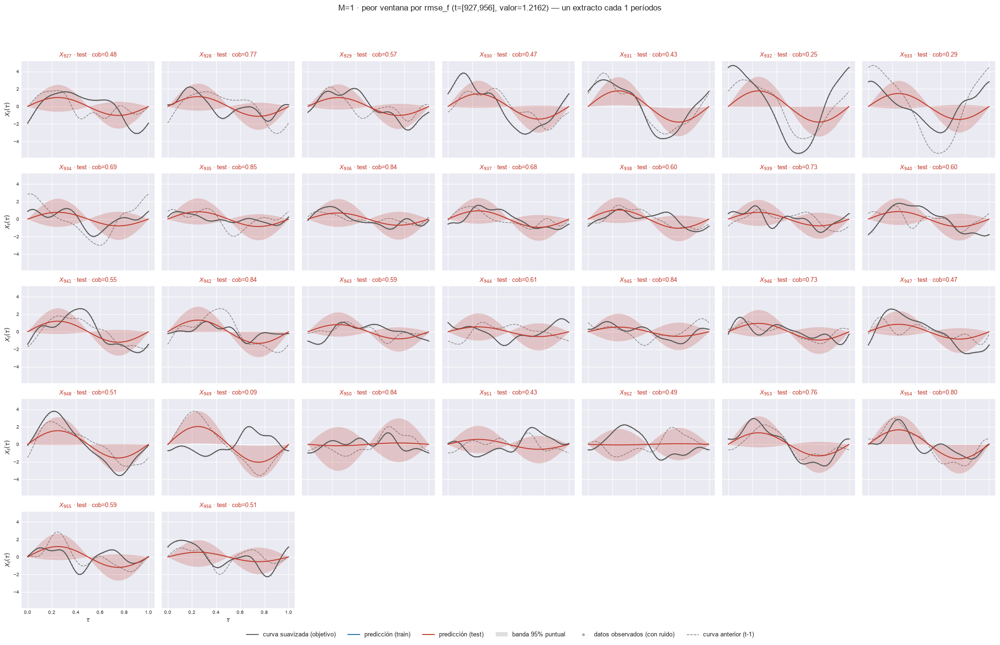

    t=[926, 955]  rmse_f=1.211332


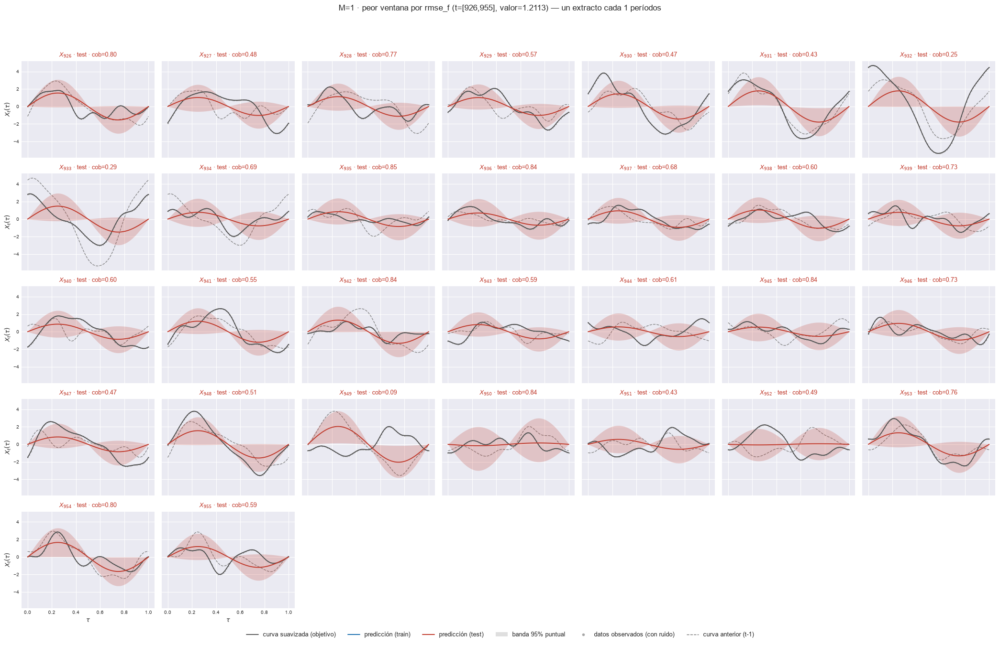

    t=[971, 1000]  rmse_f=1.210217


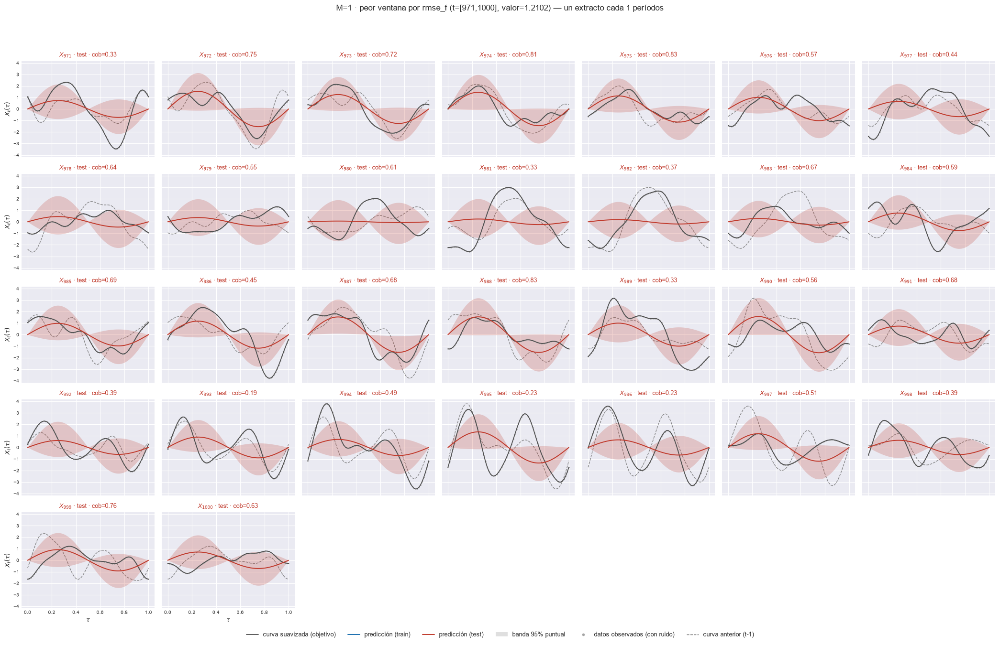

[M=2] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[971, 1000]  rmse_f=1.156413


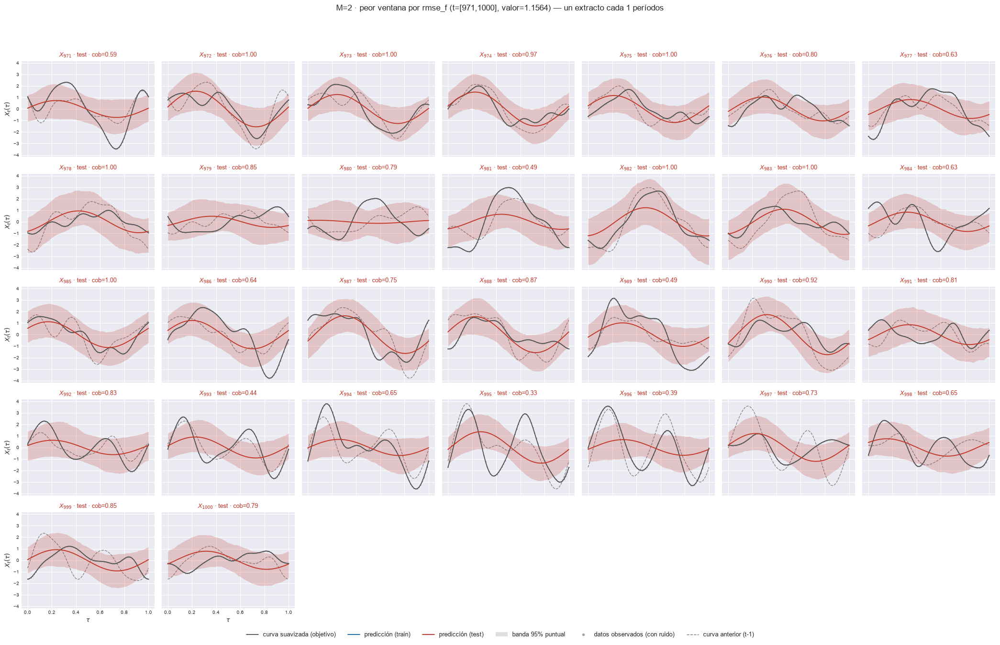

    t=[970, 999]  rmse_f=1.154759


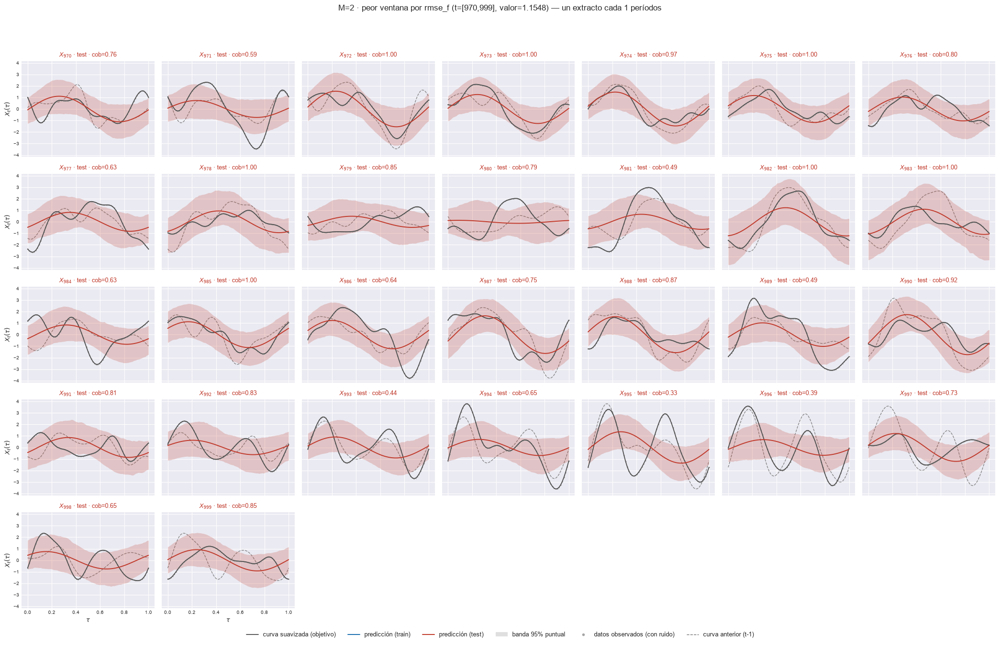

    t=[969, 998]  rmse_f=1.152505


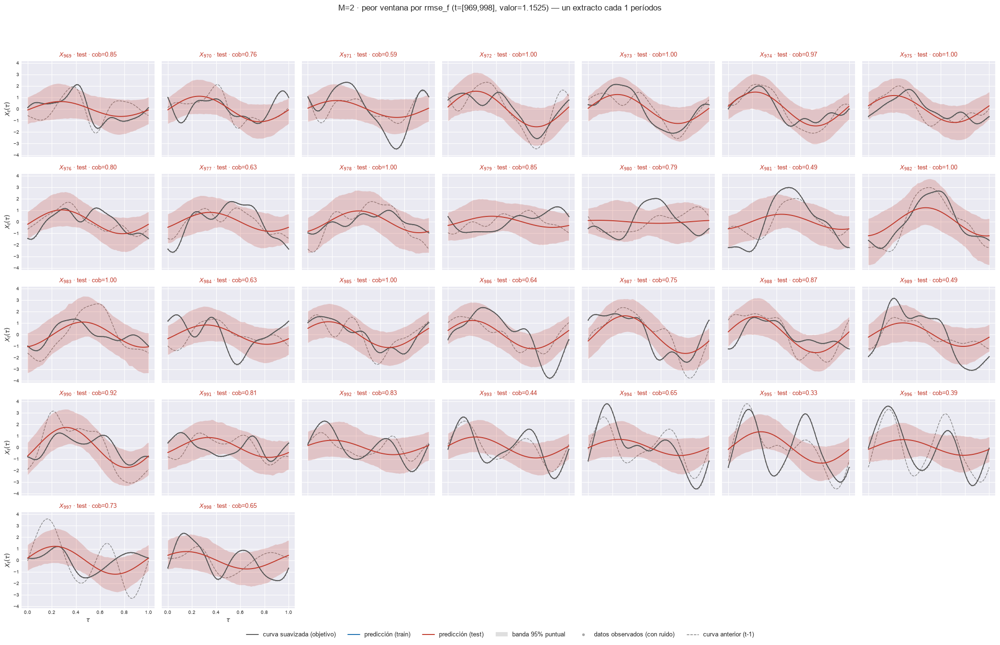

    t=[968, 997]  rmse_f=1.150529


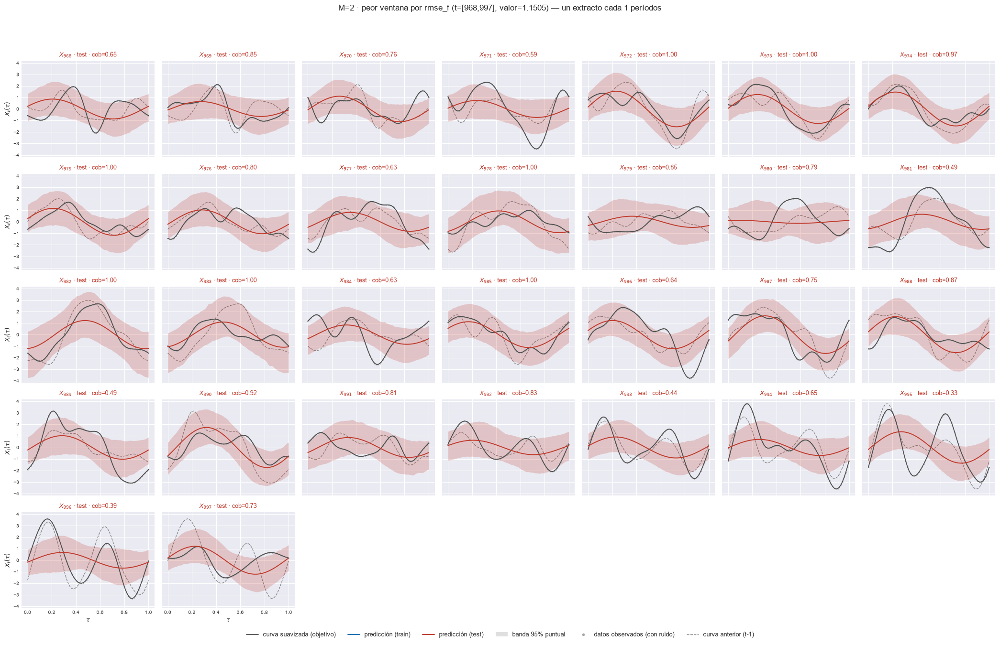

    t=[923, 952]  rmse_f=1.147115


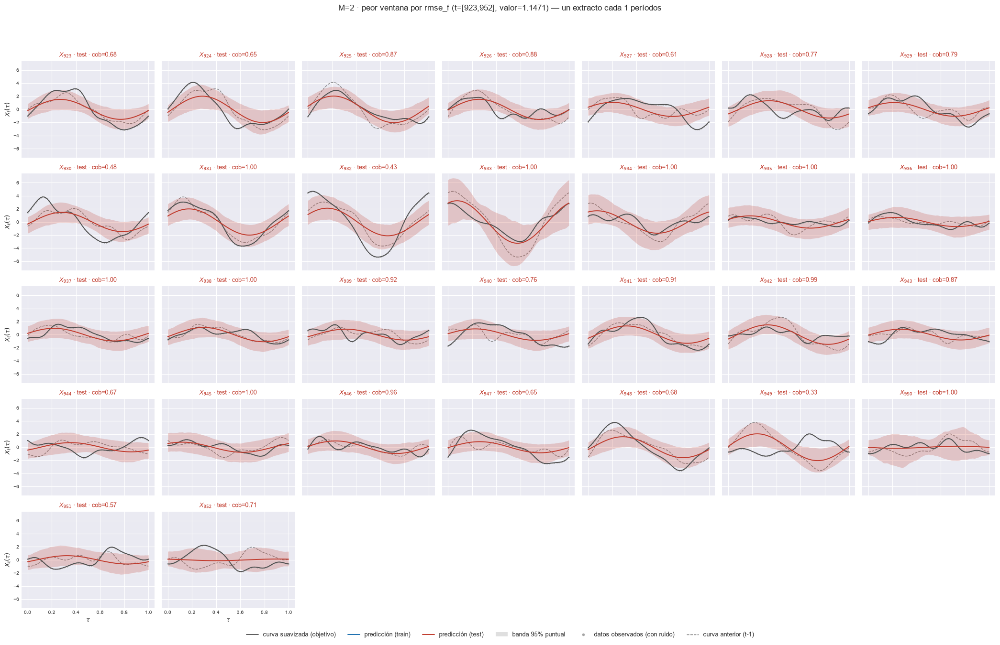

[M=3] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[923, 952]  rmse_f=1.134244


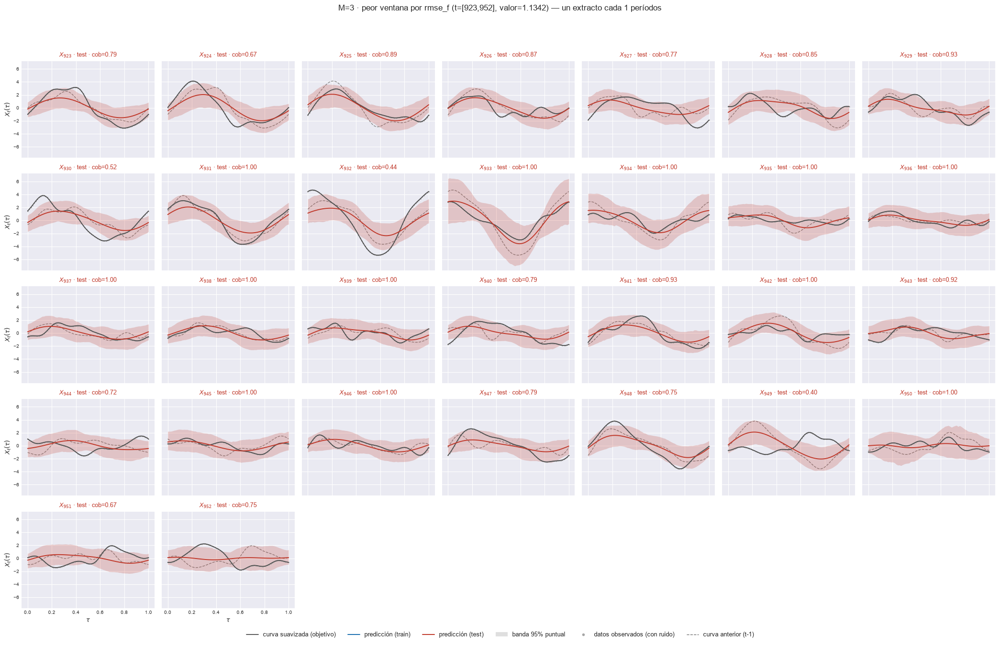

    t=[924, 953]  rmse_f=1.125068


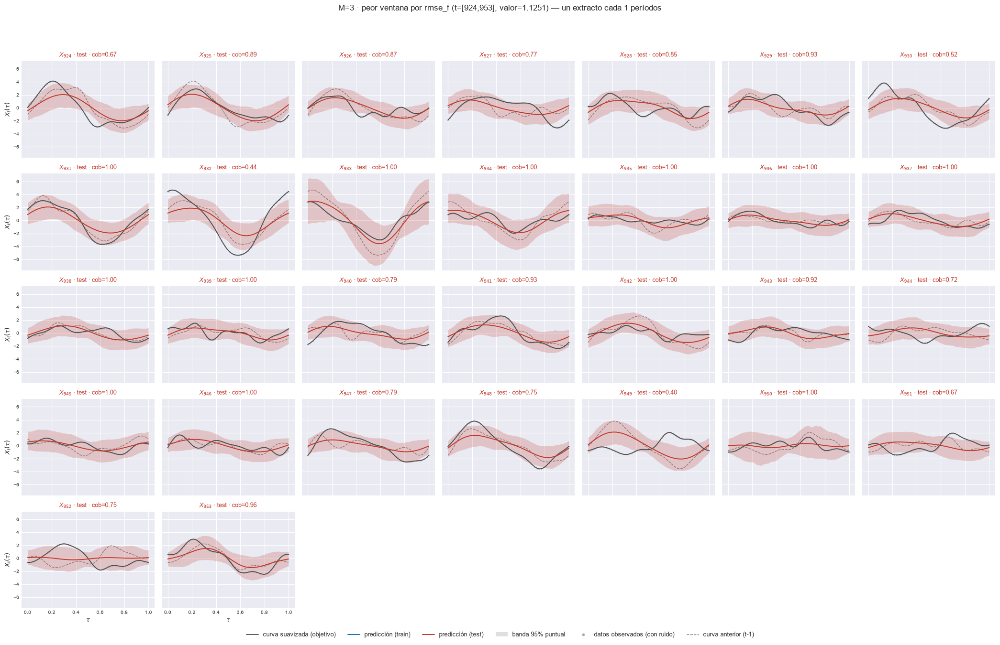

    t=[922, 951]  rmse_f=1.115861


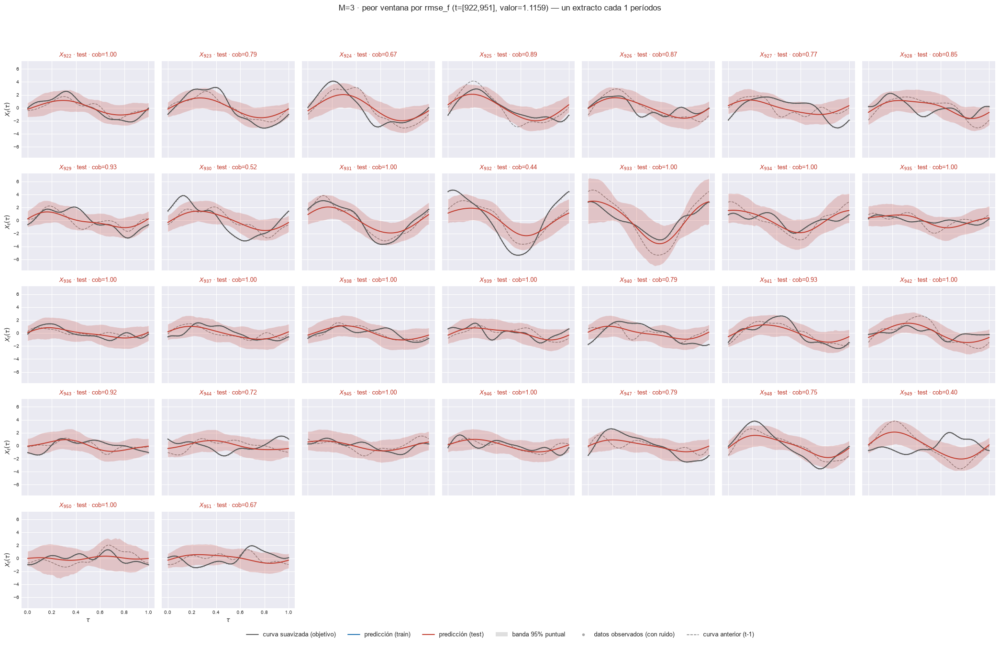

    t=[926, 955]  rmse_f=1.115114


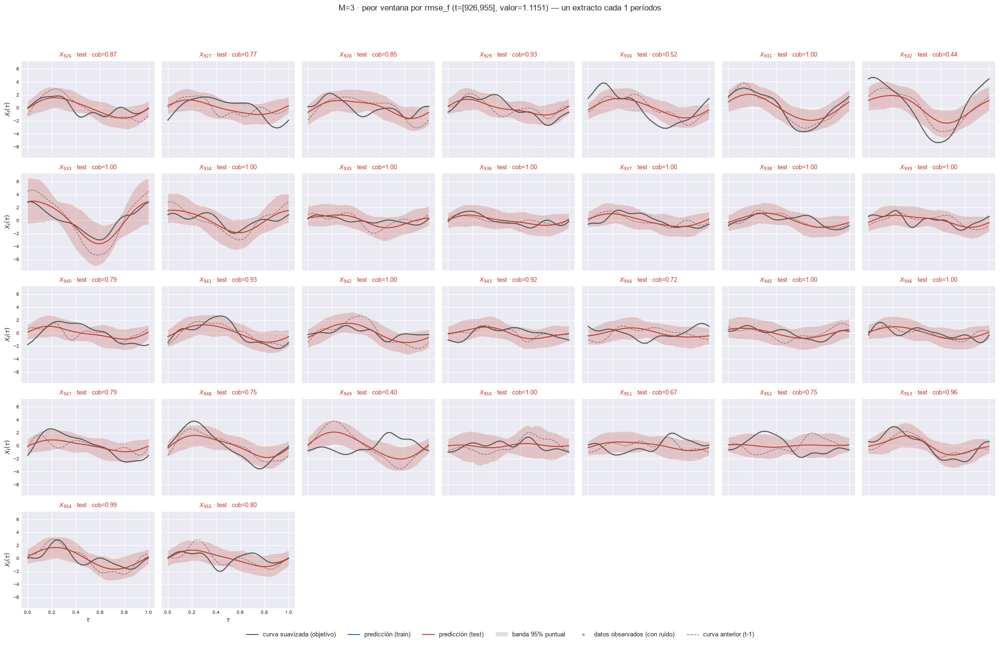

    t=[927, 956]  rmse_f=1.112837


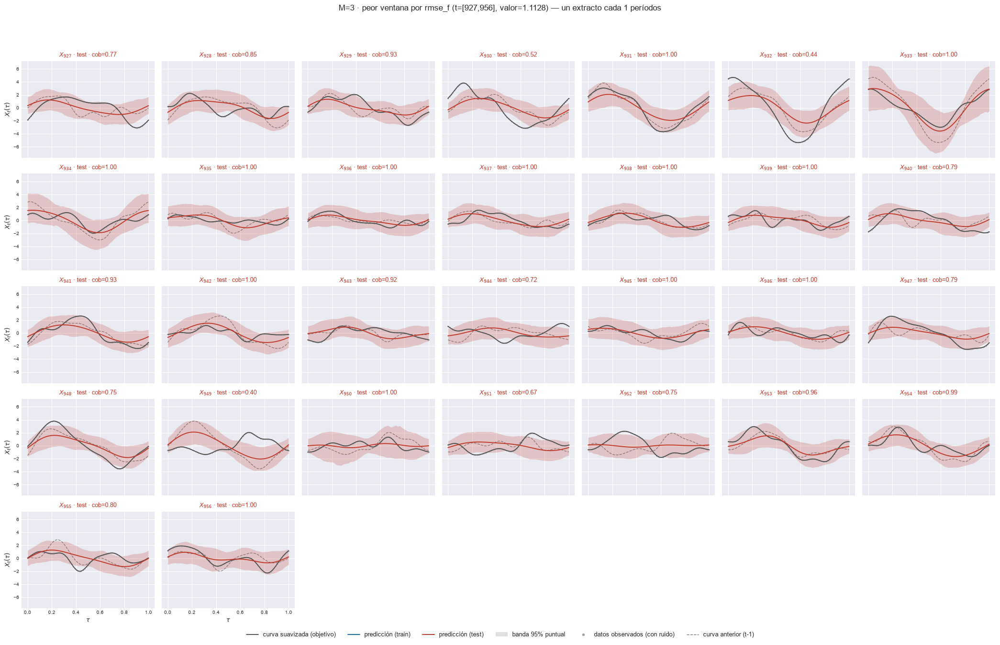

[M=4] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[923, 952]  rmse_f=1.127698


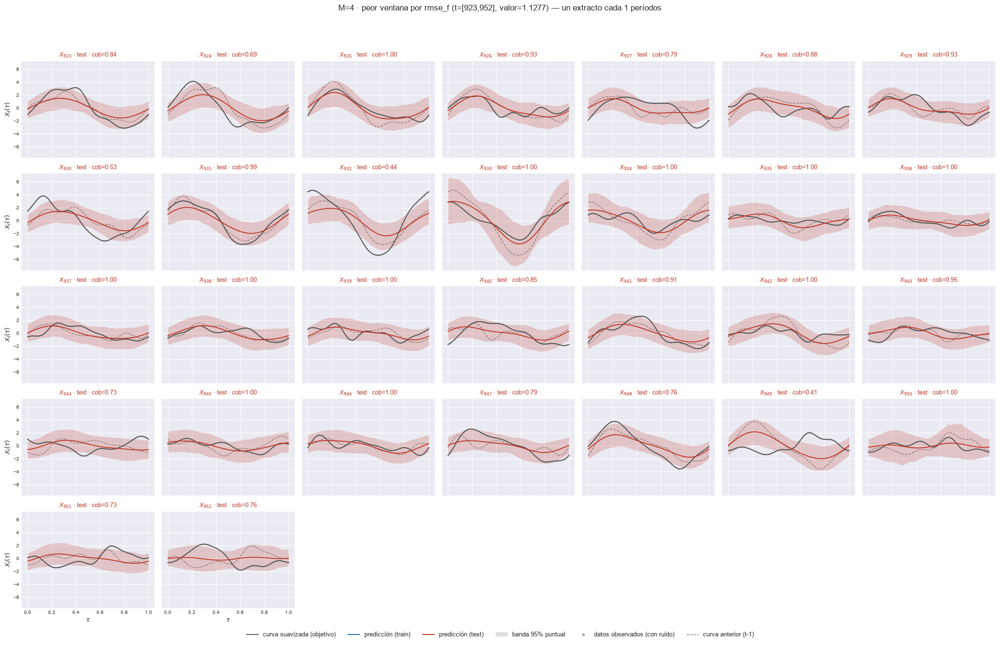

    t=[924, 953]  rmse_f=1.118669


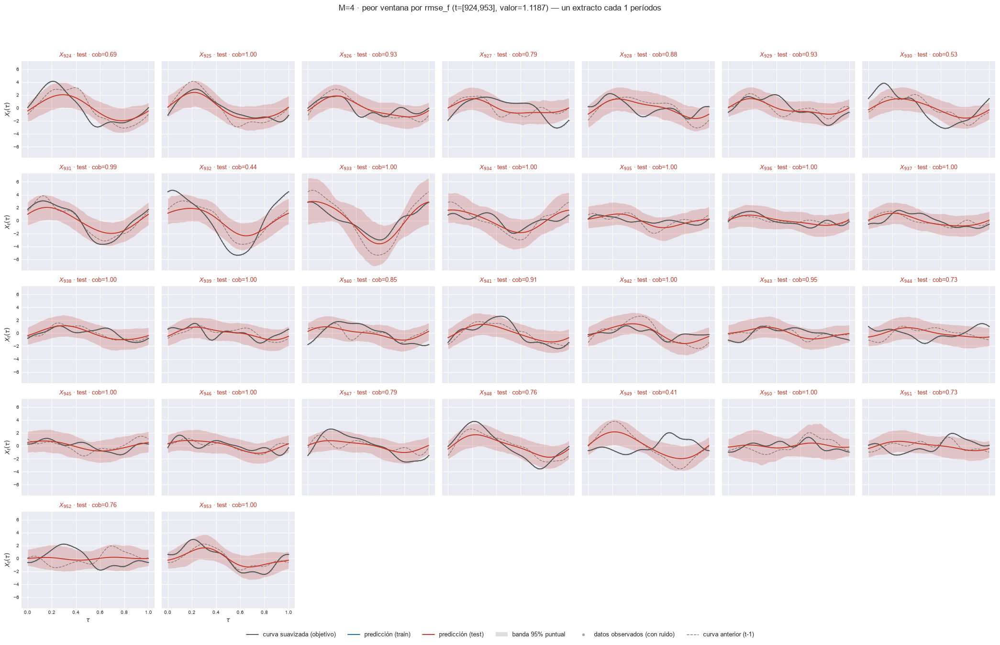

    t=[927, 956]  rmse_f=1.111287


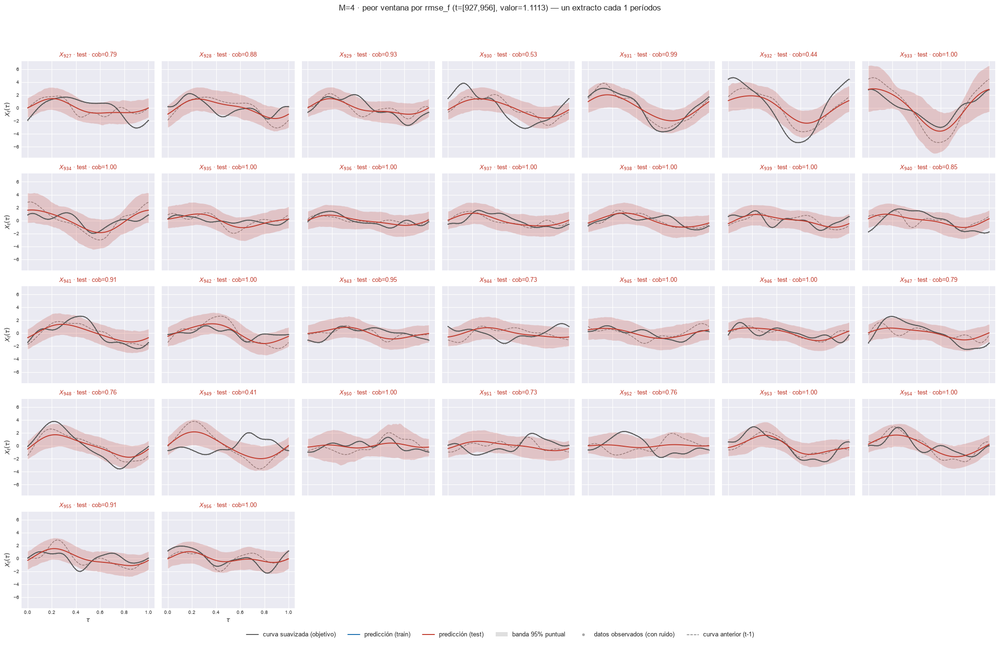

    t=[926, 955]  rmse_f=1.109802


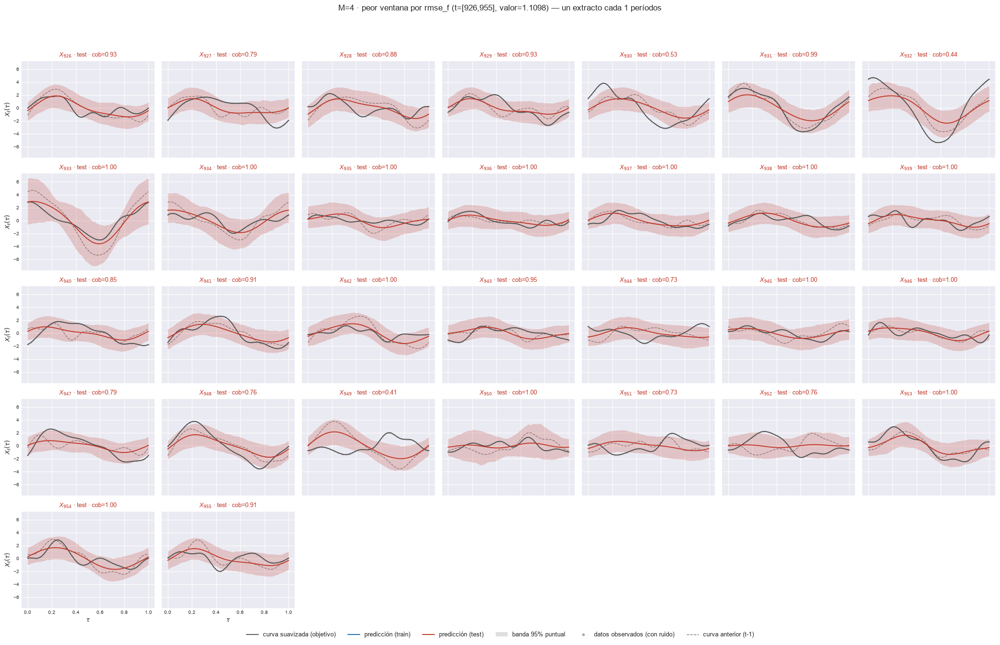

    t=[922, 951]  rmse_f=1.109673


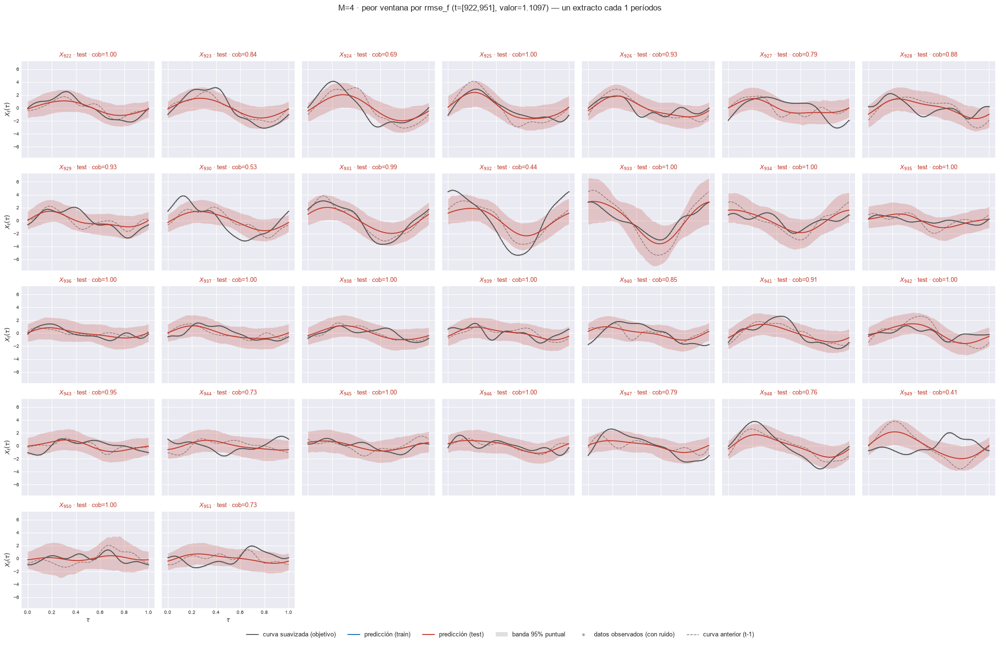

[M=5] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[923, 952]  rmse_f=1.126959


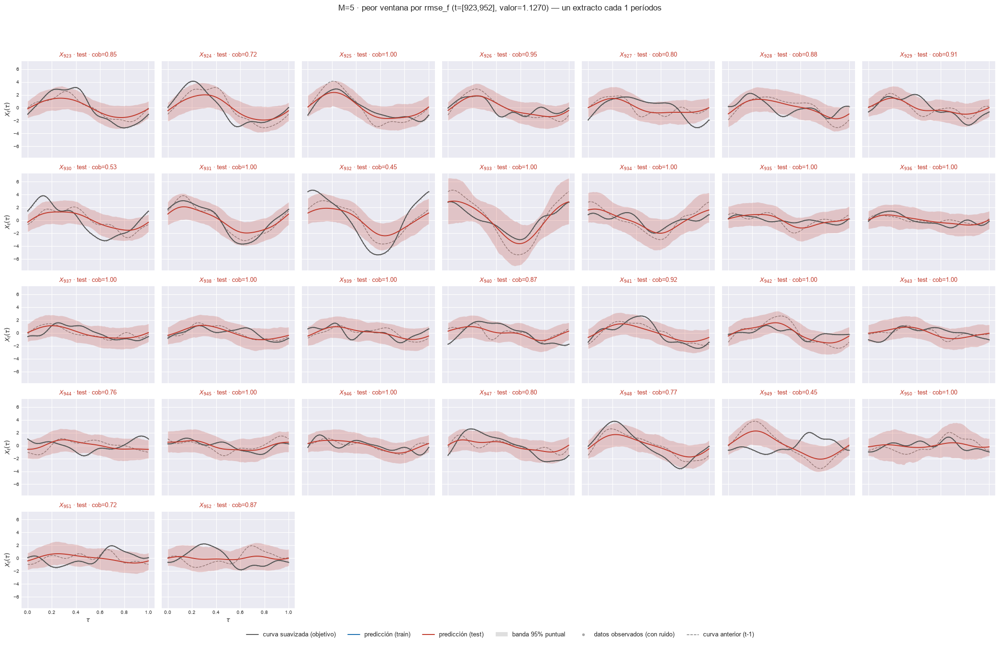

    t=[924, 953]  rmse_f=1.118025


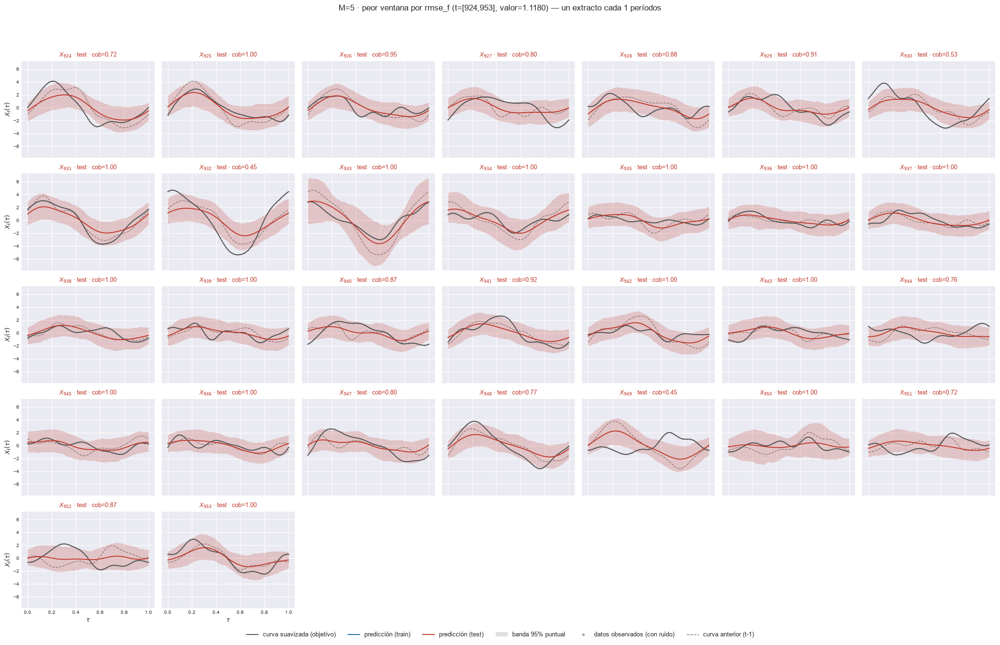

    t=[927, 956]  rmse_f=1.110069


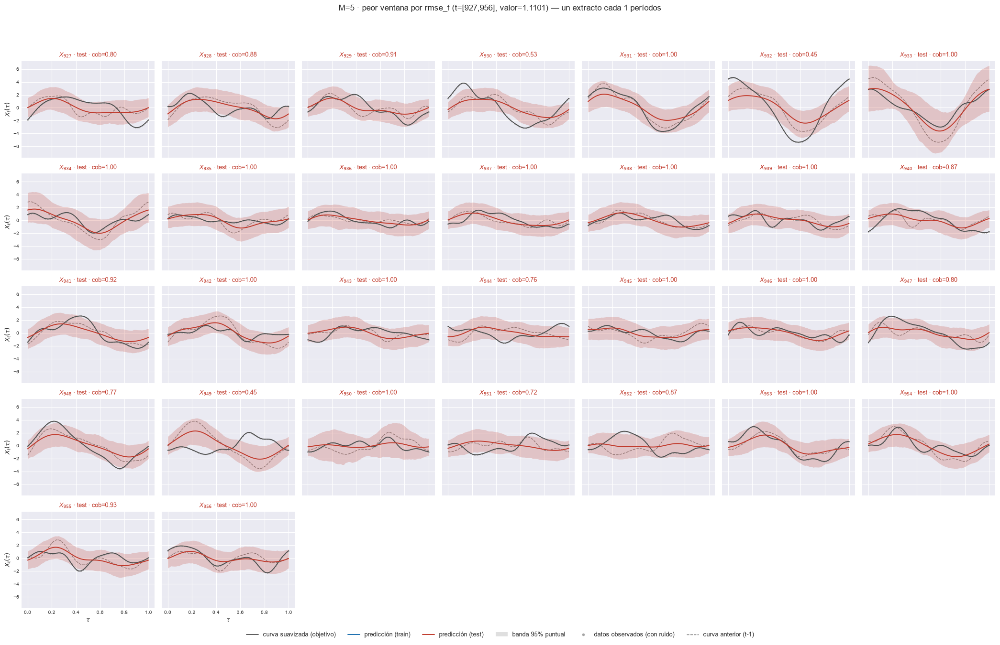

    t=[922, 951]  rmse_f=1.109179


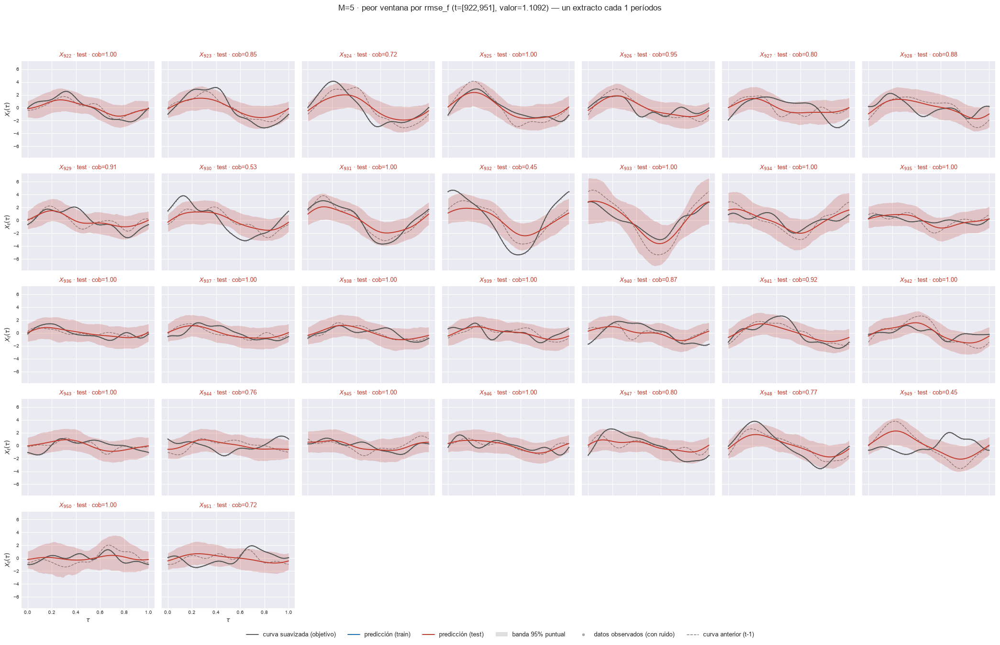

    t=[926, 955]  rmse_f=1.108696


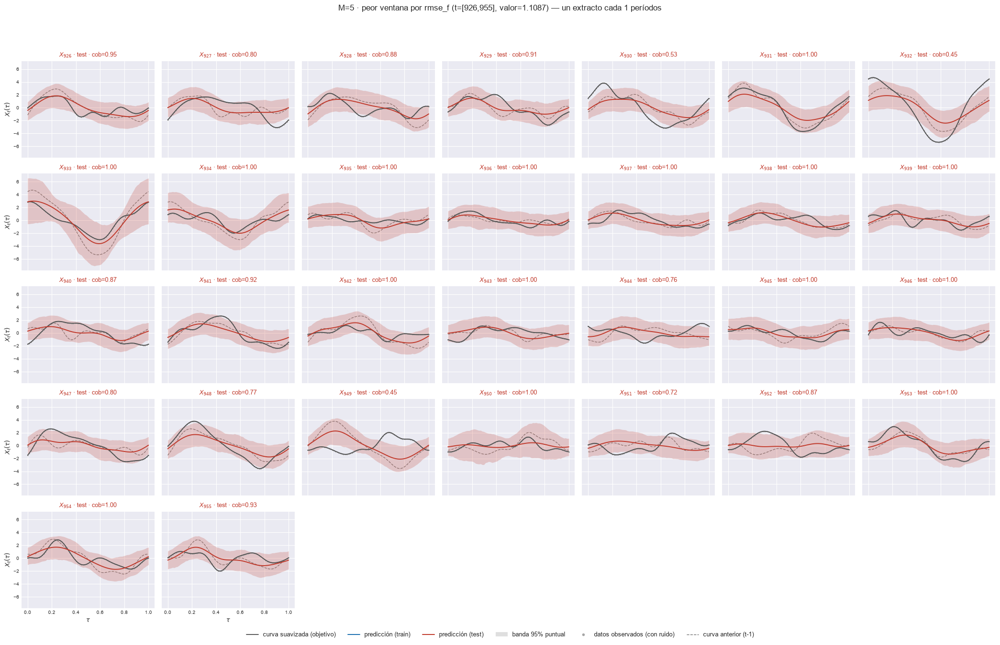

[M=6] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[923, 952]  rmse_f=1.126159


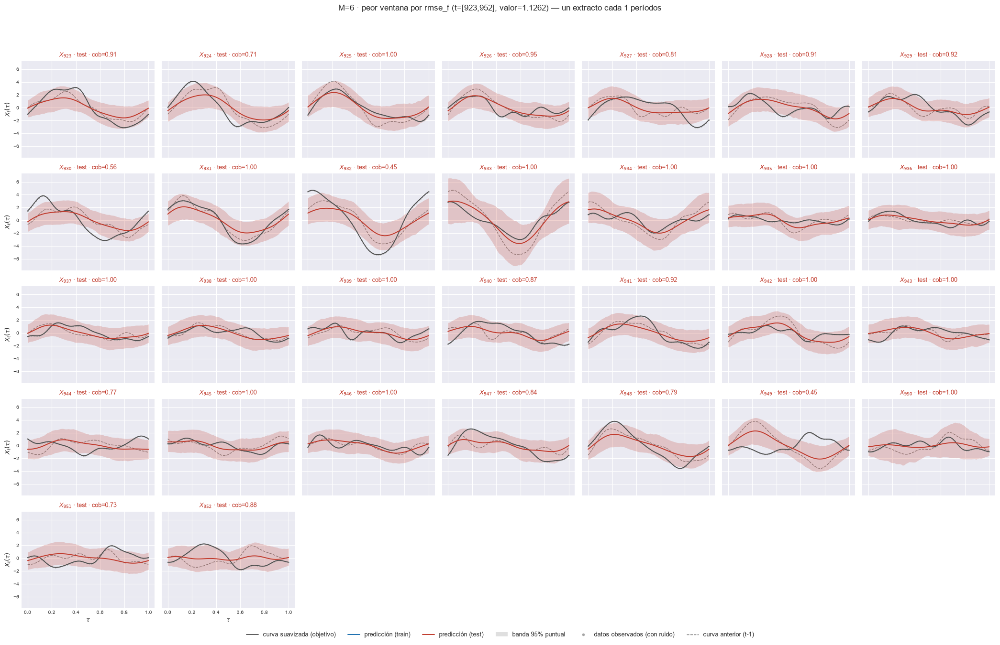

    t=[924, 953]  rmse_f=1.117156


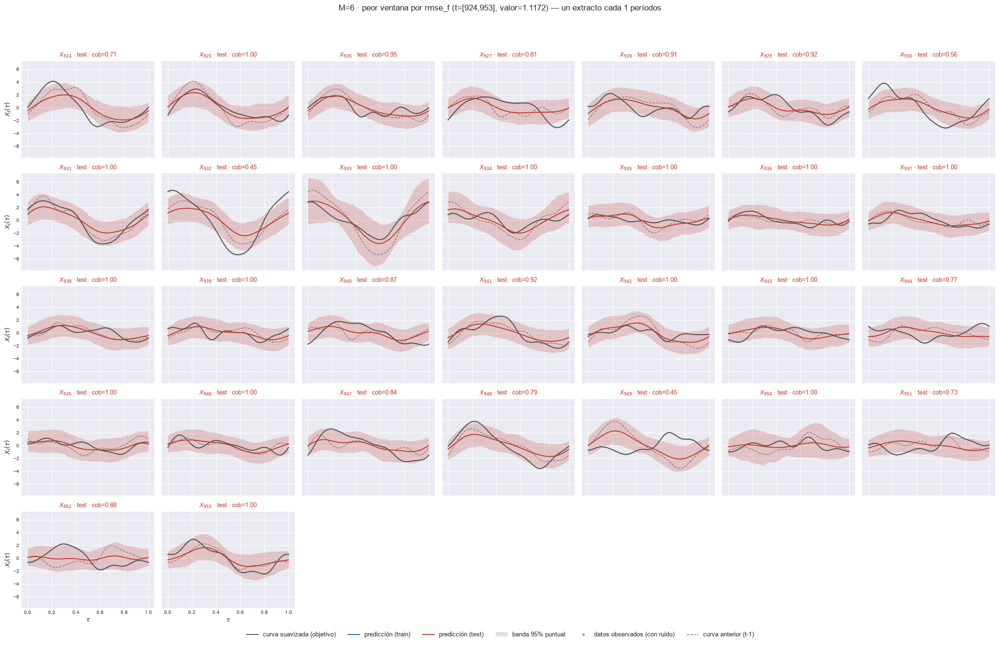

    t=[927, 956]  rmse_f=1.108649


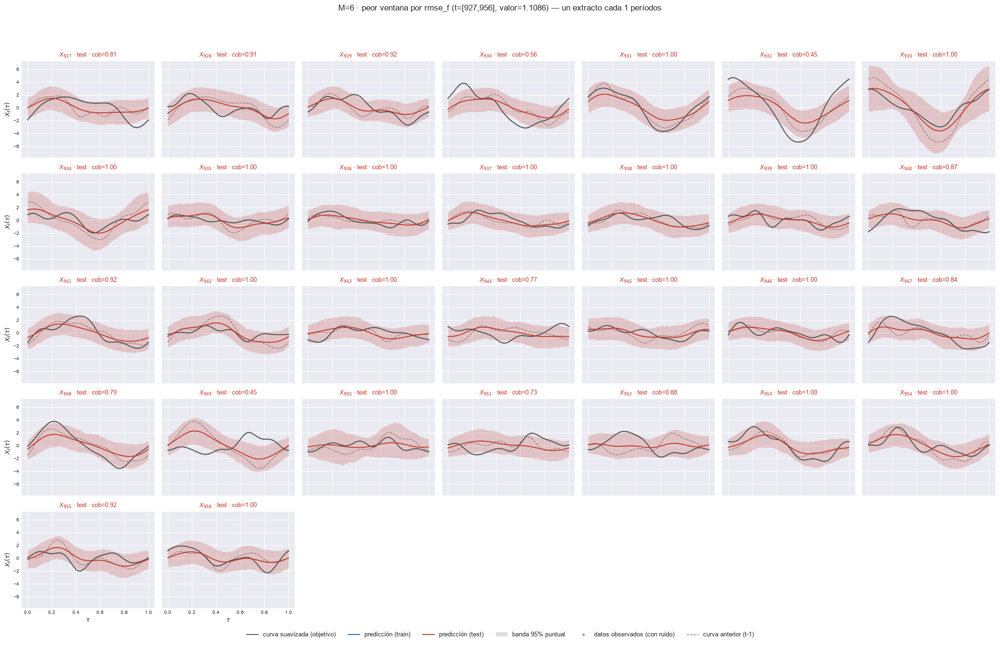

    t=[922, 951]  rmse_f=1.108354


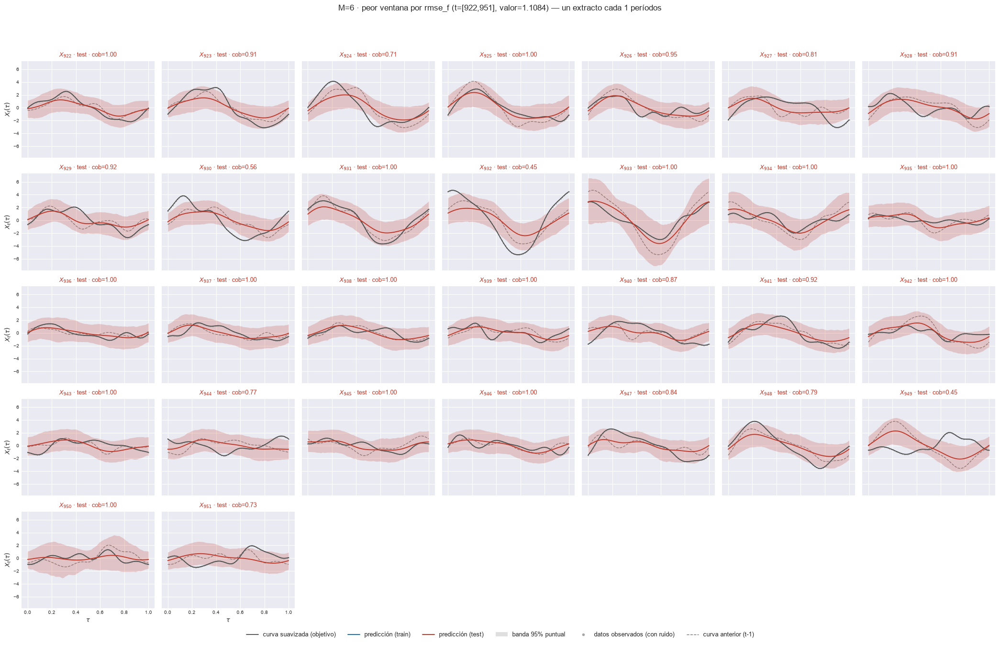

    t=[926, 955]  rmse_f=1.107567


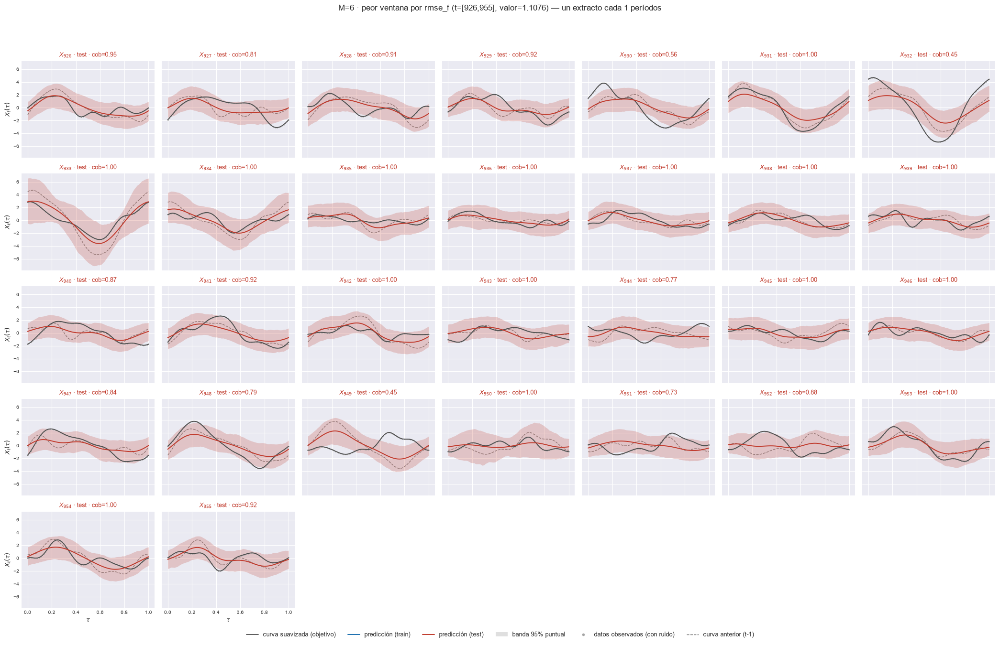

[M=7] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[923, 952]  rmse_f=1.125845


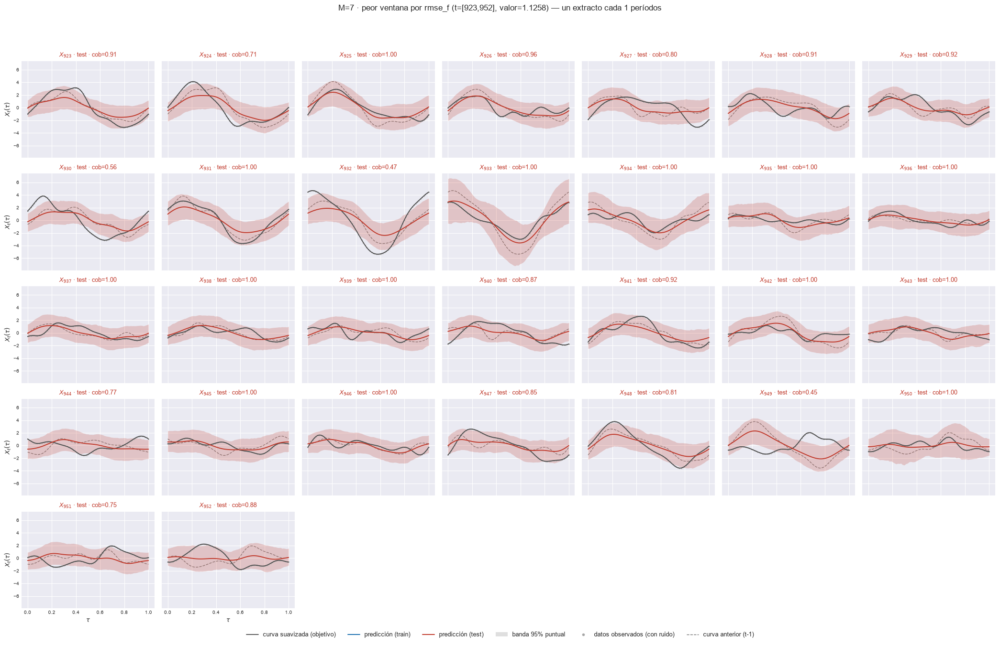

    t=[924, 953]  rmse_f=1.116042


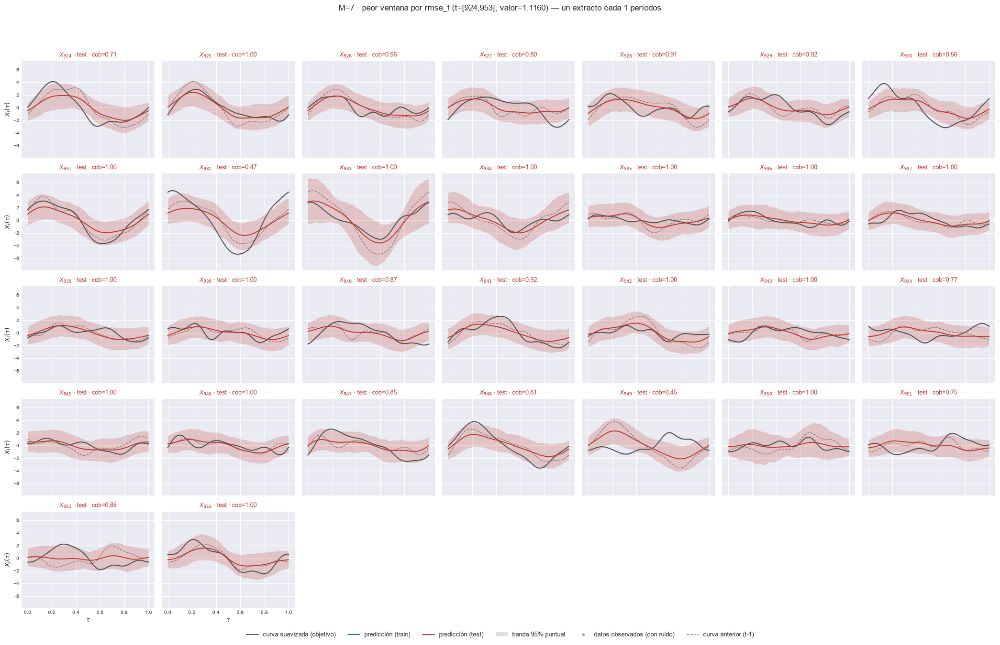

    t=[927, 956]  rmse_f=1.108151


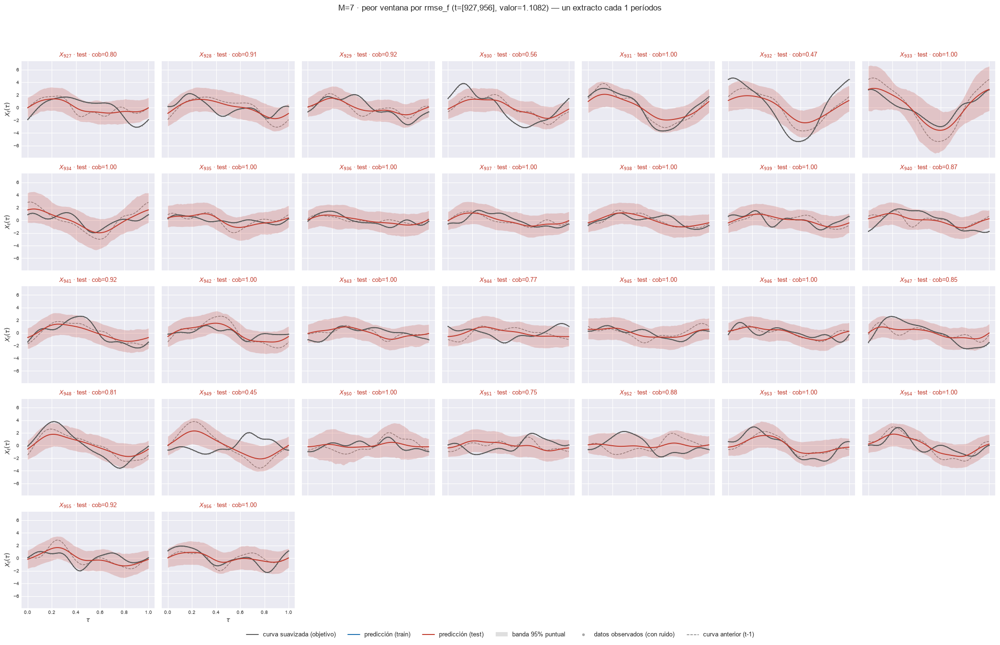

    t=[922, 951]  rmse_f=1.107904


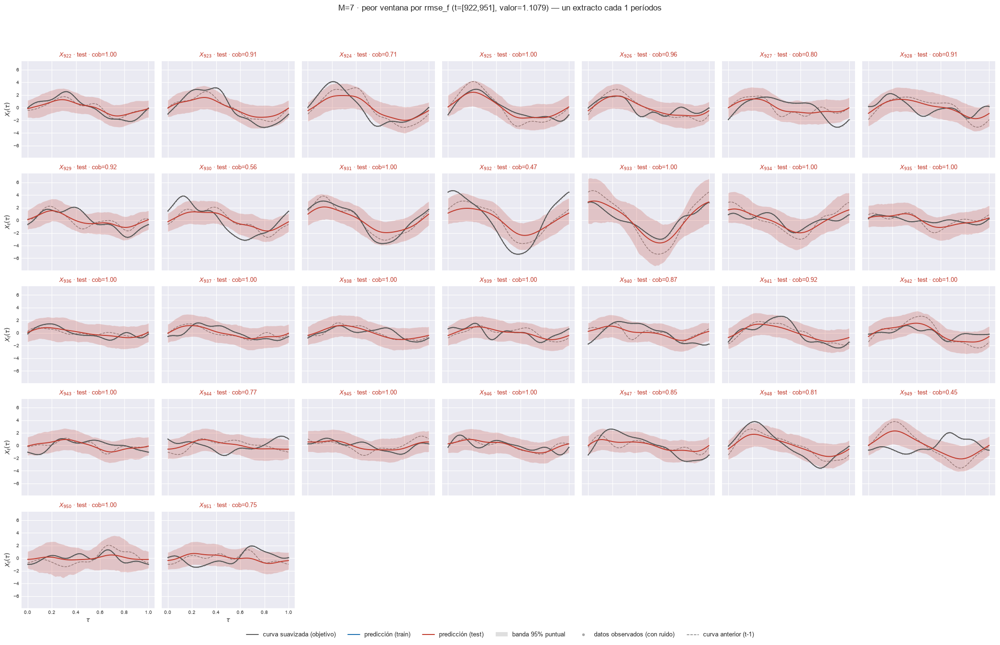

    t=[926, 955]  rmse_f=1.106696


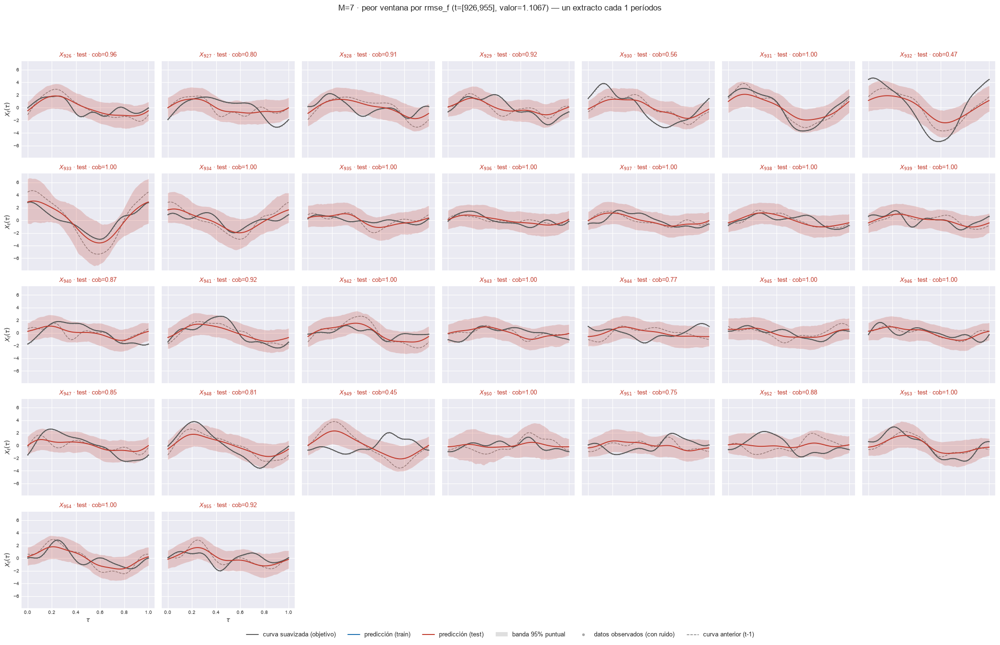

[M=8] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[923, 952]  rmse_f=1.124999


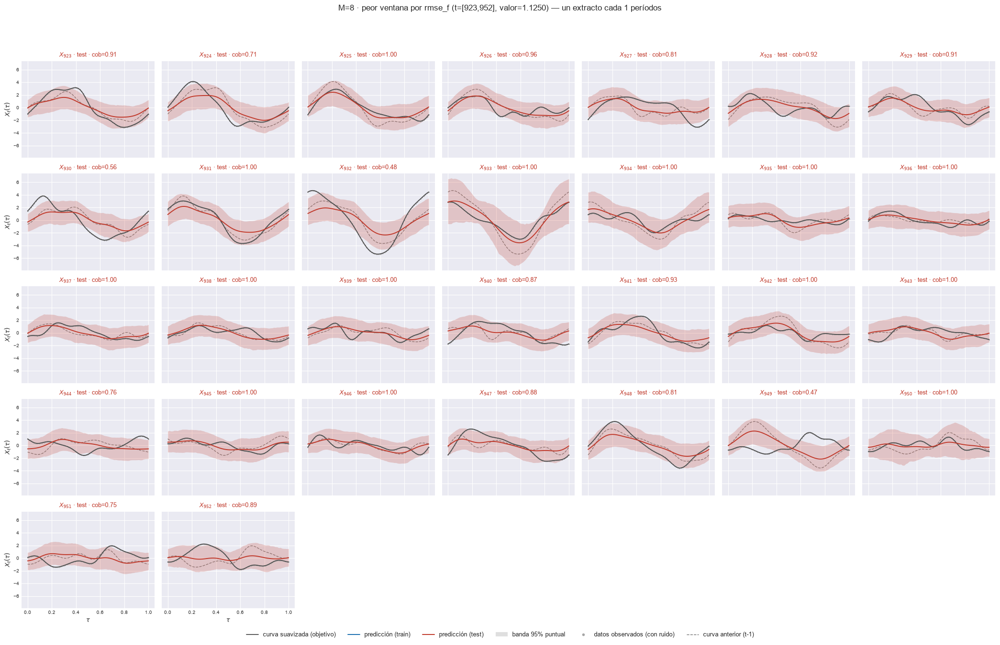

    t=[924, 953]  rmse_f=1.115167


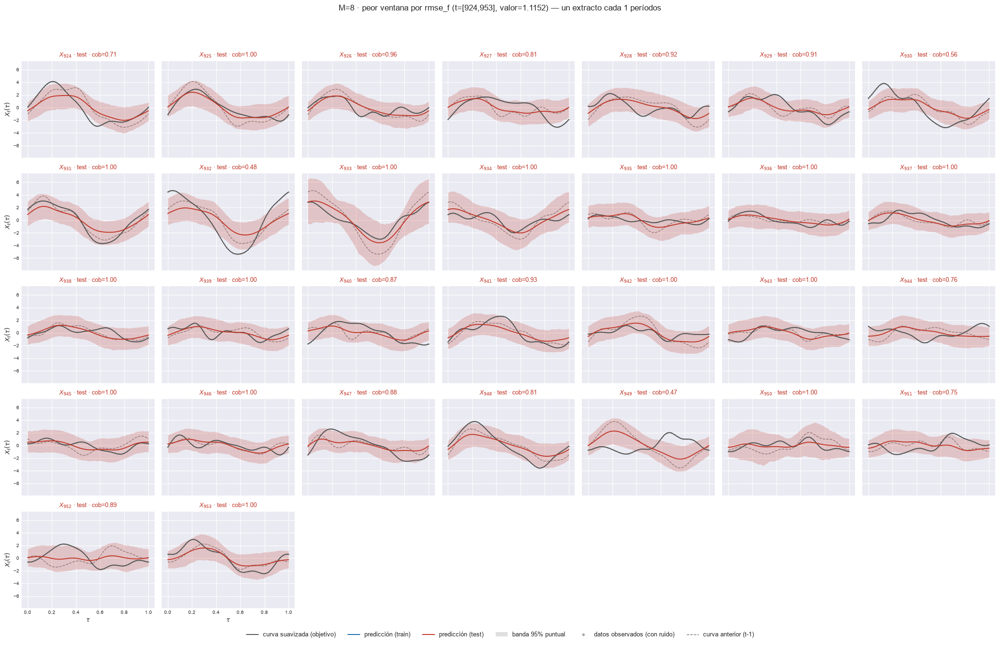

    t=[922, 951]  rmse_f=1.107026


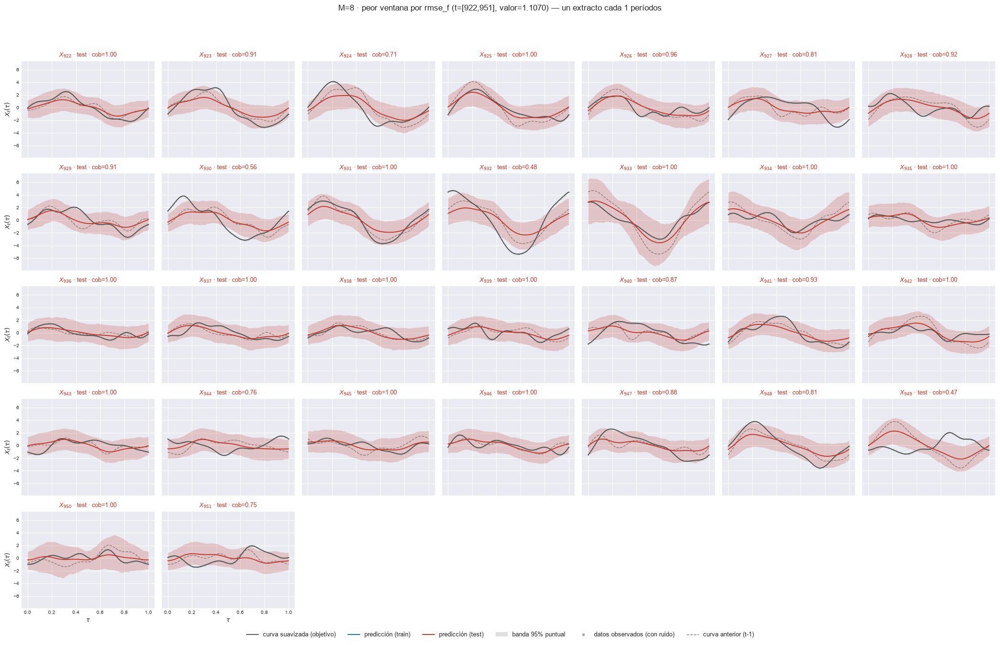

    t=[927, 956]  rmse_f=1.106936


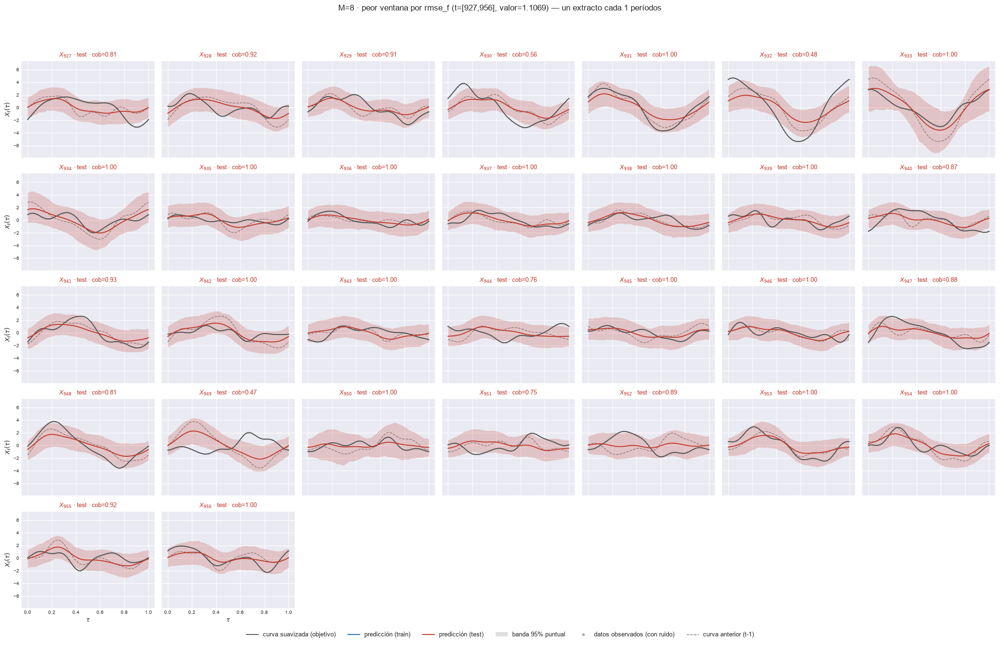

    t=[920, 949]  rmse_f=1.105674


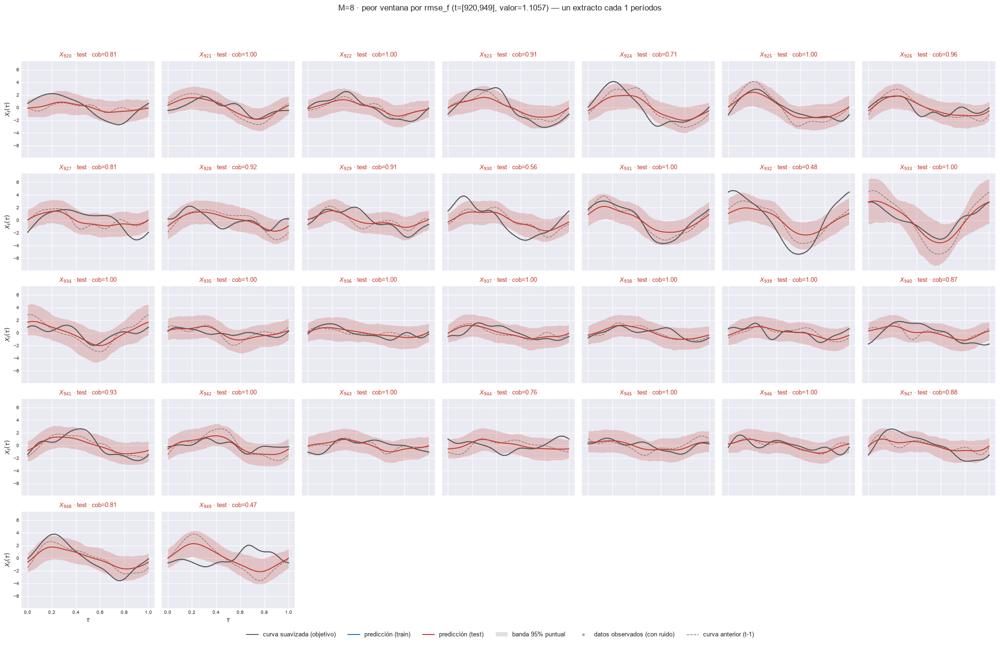

[M=9] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[923, 952]  rmse_f=1.124480


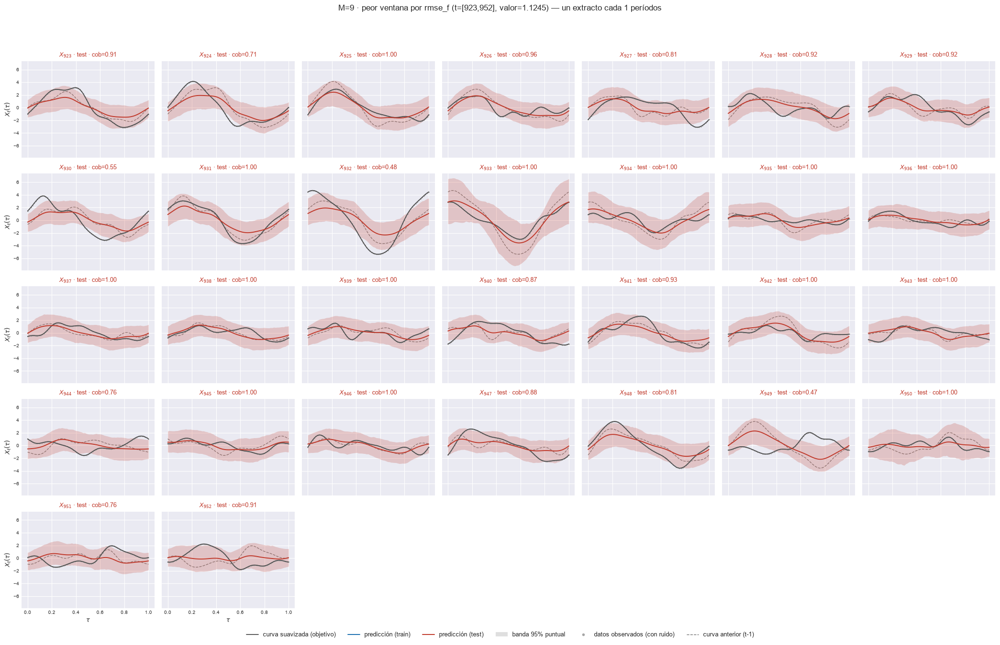

    t=[924, 953]  rmse_f=1.114578


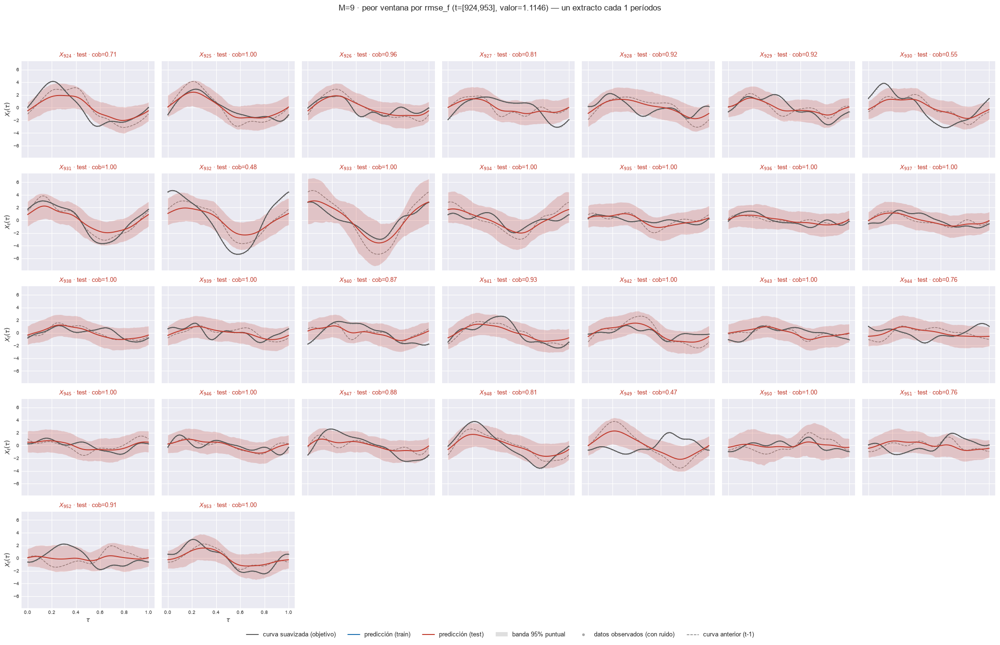

    t=[922, 951]  rmse_f=1.106482


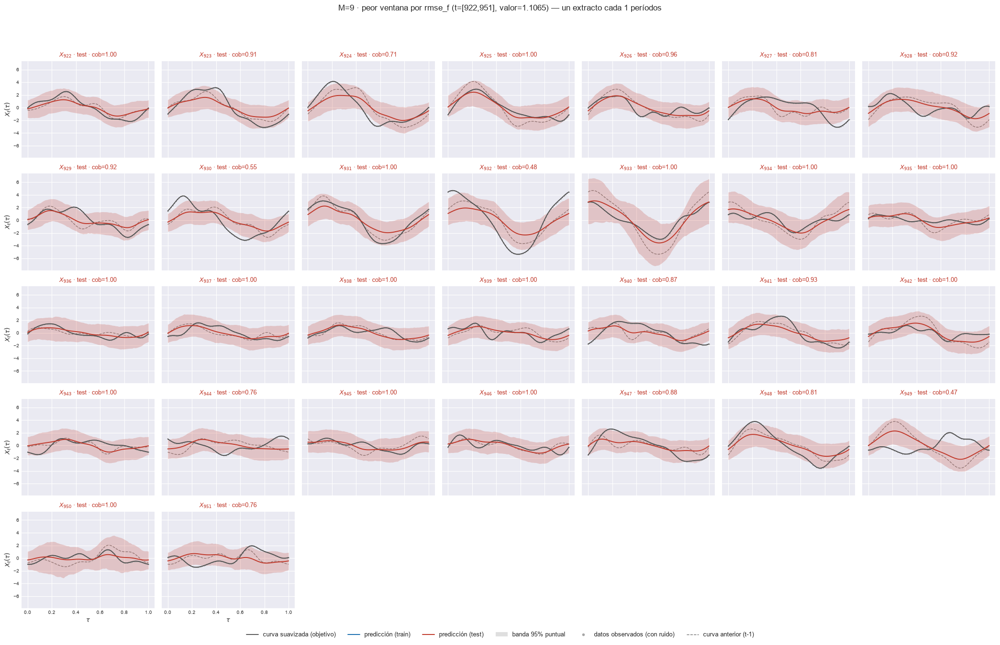

    t=[927, 956]  rmse_f=1.106339


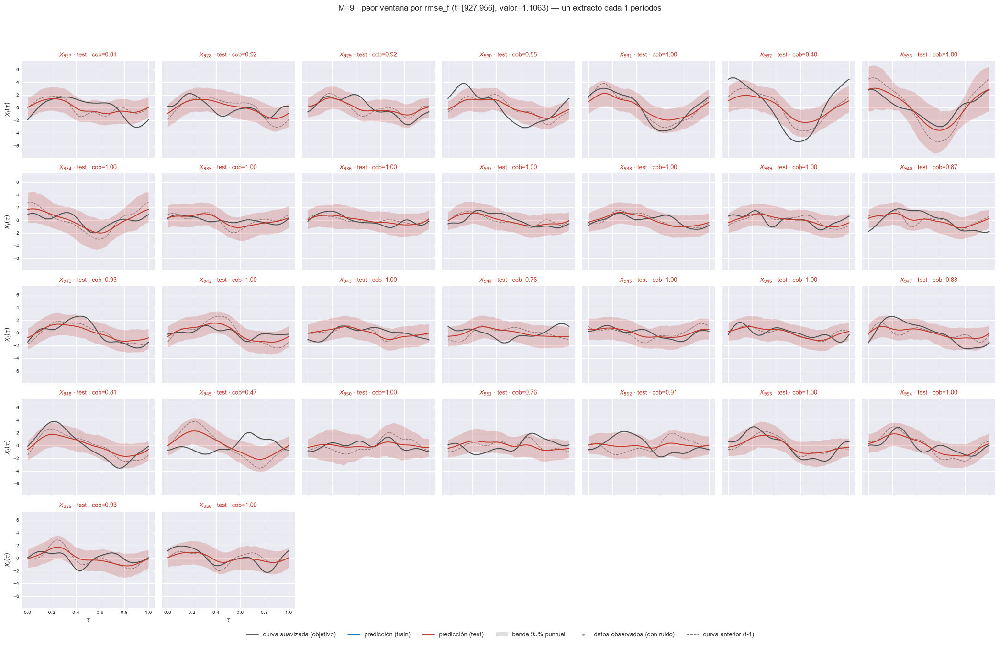

    t=[920, 949]  rmse_f=1.105321


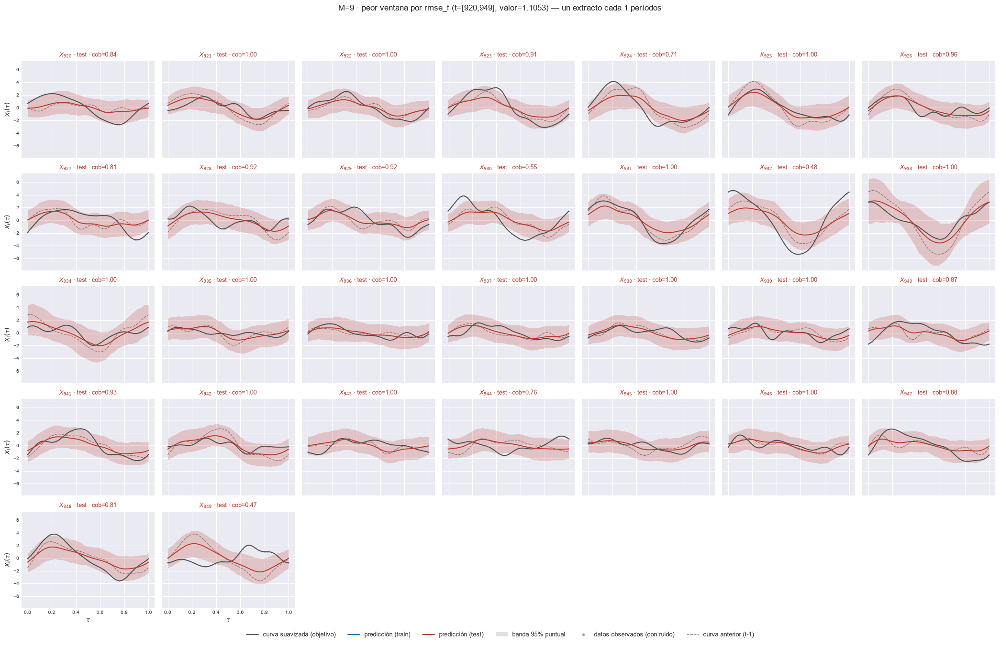

[M=10] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[923, 952]  rmse_f=1.124391


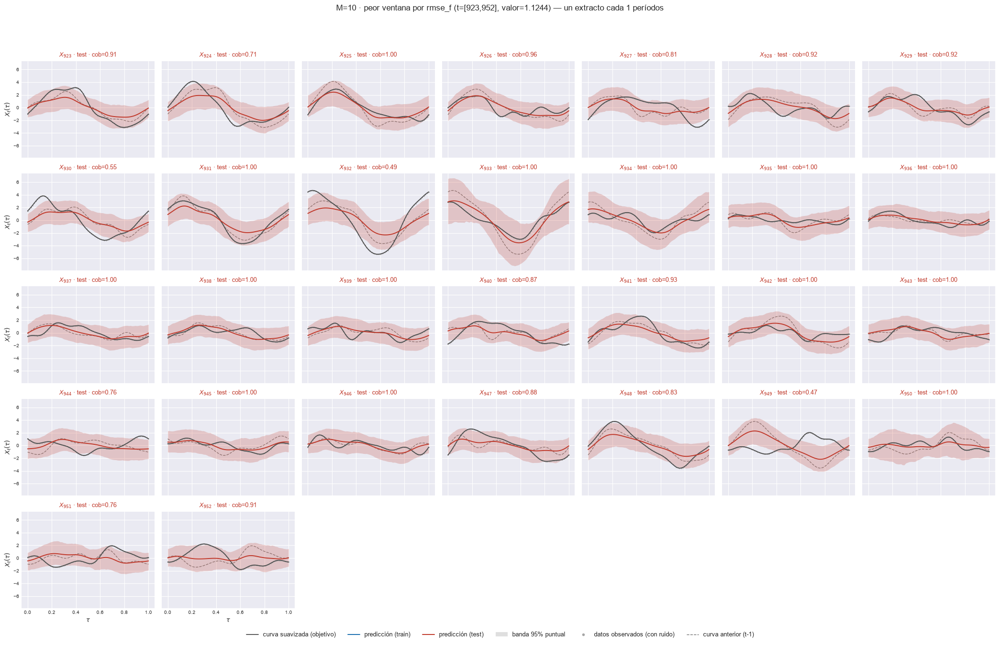

    t=[924, 953]  rmse_f=1.114484


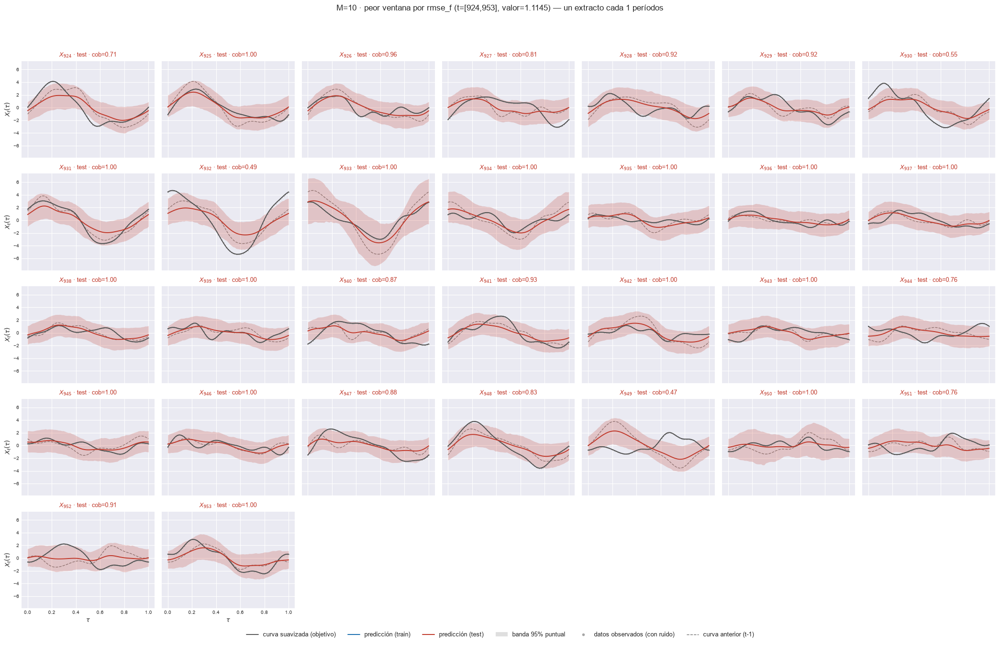

    t=[922, 951]  rmse_f=1.106429


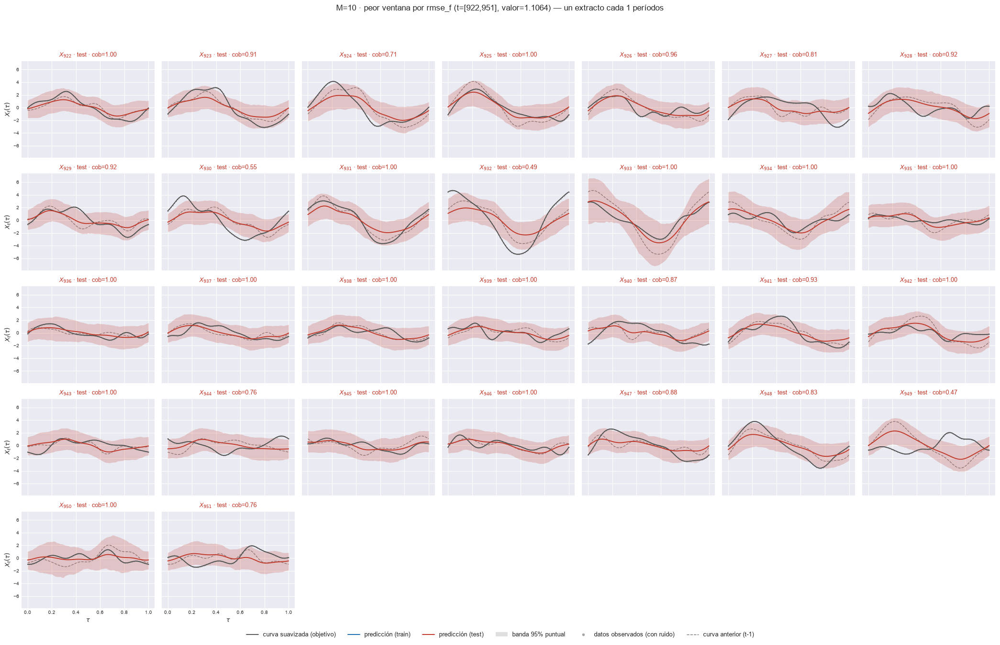

    t=[927, 956]  rmse_f=1.106255


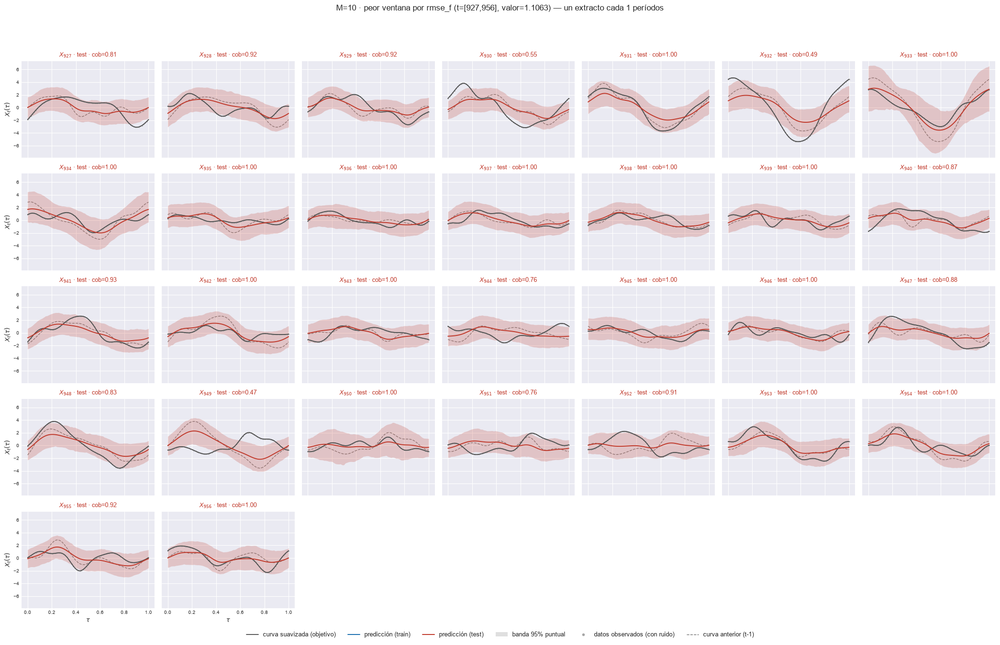

    t=[920, 949]  rmse_f=1.105289


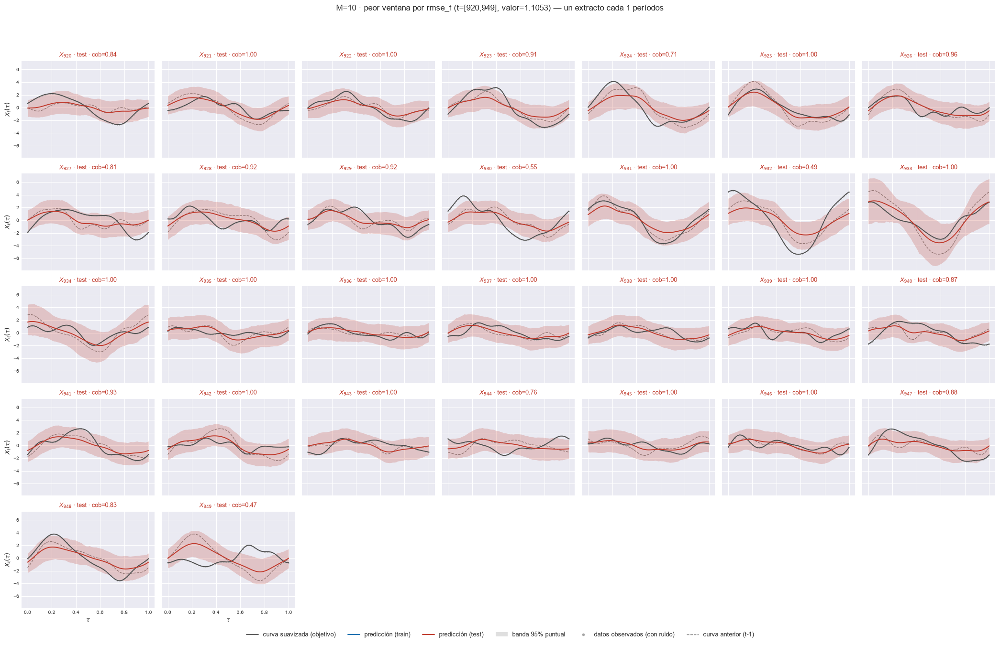

In [16]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

Soporte verdadero de `internos["soporte"]`; sensibilidad, especificidad y AUC.

In [17]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (1 pasos)


  1/1 (100.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]


[matriz_pip] listo: 1 pasos en 0.0s  tabla 4x2


[M=1] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd
variable,,
fpc_1_lag1,1.000,0.000
fpc_1_lag2,0.281,0.237
fpc_1_lag3,0.102,0.029
fpc_1_lag4,0.101,0.037


[matriz_pip] inicio (2 pasos)


  1/2 (50.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]


  2/2 (100.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.068, 1.000]


[matriz_pip] listo: 2 pasos en 0.0s  tabla 8x4


[M=2] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd
variable,,,,
fpc_1_lag1,1.000,0.000,nan,nan
fpc_1_lag2,0.281,0.237,nan,nan
fpc_1_lag3,0.102,0.029,nan,nan
fpc_1_lag4,0.101,0.037,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000
fpc_2_lag2,nan,nan,0.269,0.145
fpc_2_lag3,nan,nan,0.069,0.024
fpc_2_lag4,nan,nan,0.068,0.025


[matriz_pip] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]


  2/3 (66.7%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.068, 1.000]


  3/3 (100.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.059, 1.000]


[matriz_pip] listo: 3 pasos en 0.0s  tabla 12x6


[M=3] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd
variable,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan
fpc_1_lag2,0.281,0.237,nan,nan,nan,nan
fpc_1_lag3,0.102,0.029,nan,nan,nan,nan
fpc_1_lag4,0.101,0.037,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan
fpc_2_lag2,nan,nan,0.269,0.145,nan,nan
fpc_2_lag3,nan,nan,0.069,0.024,nan,nan
fpc_2_lag4,nan,nan,0.068,0.025,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000


[matriz_pip] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]


  2/4 (50.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.068, 1.000]


  3/4 (75.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.059, 1.000]


  4/4 (100.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.061, 1.000]


[matriz_pip] listo: 4 pasos en 0.0s  tabla 16x8


[M=4] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd
variable,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.281,0.237,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.102,0.029,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.101,0.037,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.269,0.145,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.069,0.024,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.068,0.025,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan


[matriz_pip] inicio (5 pasos)


  1/5 (20.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]


  2/5 (40.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.068, 1.000]


  3/5 (60.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.059, 1.000]


  4/5 (80.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.061, 1.000]


  5/5 (100.0%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.063, 1.000]


[matriz_pip] listo: 5 pasos en 0.0s  tabla 20x10


[M=5] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd
variable,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.281,0.237,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.102,0.029,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.101,0.037,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.269,0.145,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.069,0.024,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.068,0.025,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan


[matriz_pip] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]


  2/6 (33.3%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.068, 1.000]


  3/6 (50.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.059, 1.000]


  4/6 (66.7%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.061, 1.000]


  5/6 (83.3%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.063, 1.000]


  6/6 (100.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.069, 1.000]


[matriz_pip] listo: 6 pasos en 0.0s  tabla 24x12


[M=6] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd
variable,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.281,0.237,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.102,0.029,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.101,0.037,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.269,0.145,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.069,0.024,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.068,0.025,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]


  2/7 (28.6%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.068, 1.000]


  3/7 (42.9%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.059, 1.000]


  4/7 (57.1%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.061, 1.000]


  5/7 (71.4%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.063, 1.000]


  6/7 (85.7%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.069, 1.000]


  7/7 (100.0%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.065, 1.000]


[matriz_pip] listo: 7 pasos en 0.0s  tabla 28x14


[M=7] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion

,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd
variable,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.281,0.237,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.102,0.029,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.101,0.037,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.269,0.145,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.069,0.024,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.068,0.025,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (8 pasos)


  1/8 (12.5%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]


  2/8 (25.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.068, 1.000]

  3/8 (37.5%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.059, 1.000]


  4/8 (50.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.061, 1.000]


  5/8 (62.5%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.063, 1.000]

  6/8 (75.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.069, 1.000]


  7/8 (87.5%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.065, 1.000]


  8/8 (100.0%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 4 variables, PIP en [0.036, 1.000]

[matriz_pip] listo: 8 pasos en 0.0s  tabla 32x16


[M=8] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd
variable,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.281,0.237,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.102,0.029,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.101,0.037,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.269,0.145,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.069,0.024,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.068,0.025,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (9 pasos)


  1/9 (11.1%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]

  2/9 (22.2%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.068, 1.000]


  3/9 (33.3%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.059, 1.000]


  4/9 (44.4%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.061, 1.000]


  5/9 (55.6%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.063, 1.000]


  6/9 (66.7%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.069, 1.000]


  7/9 (77.8%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.065, 1.000]

  8/9 (88.9%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 4 variables, PIP en [0.036, 1.000]


  9/9 (100.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 4 variables, PIP en [0.045, 1.000]


[matriz_pip] listo: 9 pasos en 0.0s  tabla 36x18


[M=9] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion

,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd
variable,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.281,0.237,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.102,0.029,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.101,0.037,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.269,0.145,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.069,0.024,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.068,0.025,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.101, 1.000]

  2/10 (20.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.068, 1.000]


  3/10 (30.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.059, 1.000]


  4/10 (40.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.061, 1.000]


  5/10 (50.0%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.063, 1.000]


  6/10 (60.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.069, 1.000]


  7/10 (70.0%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.065, 1.000]


  8/10 (80.0%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 4 variables, PIP en [0.036, 1.000]


  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 4 variables, PIP en [0.045, 1.000]


  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 3 cadenas, 4 variables, PIP en [0.053, 1.000]


[matriz_pip] listo: 10 pasos en 0.0s  tabla 40x20


[M=10] dispersion maxima entre cadenas: 0.237   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_10_lag1,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1.000,0.000
fpc_10_lag2,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.064,0.017
fpc_10_lag3,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.053,0.007
fpc_10_lag4,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.053,0.016
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.281,0.237,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.102,0.029,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.101,0.037,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


In [18]:
for M in M_OK:
    contraste = contraste_generador(EST[M], ESCENARIO_ID, UMBRAL_PIP, COS_MIN)
    if not contraste.empty:
        display(contraste.style.format("{:.3f}", subset=[
            c for c in contraste.columns if contraste[c].dtype.kind == "f"])
            .set_caption(f"M={M} - selección de variables vs soporte del generador "
                         f"(umbral {UMBRAL_PIP})"))

[M=1] |cos(psi_k, phi_k)| = [1.]

,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161


[M=2] |cos(psi_k, phi_k)| = [1. 1.]

,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.135


[M=3] |cos(psi_k, phi_k)| = [1. 1. 1.]

,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.135
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065


[M=4] |cos(psi_k, phi_k)| = [1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.135
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.137


[M=5] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.135
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.137
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.069


[M=6] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.135
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.137
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.069
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.076


[M=7] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.135
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.137
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.069
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.076
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.070


[M=8] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.135
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.137
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.069
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.076
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.070
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.048


[M=9] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.135
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.137
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.069
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.076
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.070
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.048
FPC 9,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.052


[M=10] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.161
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.135
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.137
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.069
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.076
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.070
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.048
FPC 9,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.052


## 8. Cuadro resumen: mínimo, máximo y promedio

Por métrica y bloque train/test, sin las ventanas que cruzan $T_0$.

In [19]:
# Los dos objetivos, los cuatro predictores y los tres intervalos en 66_metricas_resumen.csv (por M) y 89_resumen_por_M.csv.
for M in M_OK:
    resumen_metricas(EST[M], M, DIS, ORIG)
resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)

_esp = resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")
                   & (resumen_bar.predictor == "esperanza") & (resumen_bar.intervalo == "equicolas")]
display(_esp.pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Esperanza · promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=1] curva_suavizada      PICP puntual test = 0.6396 (nominal 0.95)  ·  PICP simultaneo test = 0.0000


[M=1] representacion_fpca  PICP puntual test = 0.9483 (nominal 0.95)  ·  PICP simultaneo test = 0.9483


[M=2] curva_suavizada      PICP puntual test = 0.8694 (nominal 0.95)  ·  PICP simultaneo test = 0.3506


[M=2] representacion_fpca  PICP puntual test = 0.9399 (nominal 0.95)  ·  PICP simultaneo test = 0.8192


[M=3] curva_suavizada      PICP puntual test = 0.9101 (nominal 0.95)  ·  PICP simultaneo test = 0.4669


[M=3] representacion_fpca  PICP puntual test = 0.9419 (nominal 0.95)  ·  PICP simultaneo test = 0.7451


[M=4] curva_suavizada      PICP puntual test = 0.9316 (nominal 0.95)  ·  PICP simultaneo test = 0.5647


[M=4] representacion_fpca  PICP puntual test = 0.9469 (nominal 0.95)  ·  PICP simultaneo test = 0.7123


[M=5] curva_suavizada      PICP puntual test = 0.9390 (nominal 0.95)  ·  PICP simultaneo test = 0.6017


[M=5] representacion_fpca  PICP puntual test = 0.9449 (nominal 0.95)  ·  PICP simultaneo test = 0.6681


[M=6] curva_suavizada      PICP puntual test = 0.9433 (nominal 0.95)  ·  PICP simultaneo test = 0.6180


[M=6] representacion_fpca  PICP puntual test = 0.9469 (nominal 0.95)  ·  PICP simultaneo test = 0.6563


[M=7] curva_suavizada      PICP puntual test = 0.9455 (nominal 0.95)  ·  PICP simultaneo test = 0.6299


[M=7] representacion_fpca  PICP puntual test = 0.9462 (nominal 0.95)  ·  PICP simultaneo test = 0.6244


[M=8] curva_suavizada      PICP puntual test = 0.9462 (nominal 0.95)  ·  PICP simultaneo test = 0.6258


[M=8] representacion_fpca  PICP puntual test = 0.9466 (nominal 0.95)  ·  PICP simultaneo test = 0.6309


[M=9] curva_suavizada      PICP puntual test = 0.9464 (nominal 0.95)  ·  PICP simultaneo test = 0.6295


[M=9] representacion_fpca  PICP puntual test = 0.9467 (nominal 0.95)  ·  PICP simultaneo test = 0.6309


[M=10] curva_suavizada      PICP puntual test = 0.9470 (nominal 0.95)  ·  PICP simultaneo test = 0.6483


[M=10] representacion_fpca  PICP puntual test = 0.9470 (nominal 0.95)  ·  PICP simultaneo test = 0.6483


M,1,2,3,4,5,6,7,8,9,10
metrica,,,,,,,,,,
1. MAE (L^1),0.754279,0.738672,0.723873,0.716459,0.713758,0.712997,0.712291,0.711667,0.711327,0.711303
10. Winkler max peor ventana,99.849153,62.614570,55.591549,52.103022,48.908373,47.114677,46.369076,45.138627,44.952911,45.100264
2. RMSE (L^2),0.951141,0.922764,0.903066,0.895064,0.892564,0.891302,0.890566,0.890205,0.890029,0.889910
3. E_max promedio por curva,1.672564,1.644402,1.608826,1.599913,1.592064,1.587706,1.582945,1.580712,1.579391,1.578699
4. E_max peor de la ventana,3.141043,2.948595,2.914197,2.918992,2.893183,2.883109,2.869115,2.859112,2.851390,2.853634
5. MPIW,1.950669,2.815506,3.091868,3.262339,3.368368,3.425640,3.454541,3.470863,3.481092,3.486541
6. PICP puntual,0.639638,0.869440,0.910065,0.931597,0.939046,0.943269,0.945473,0.946227,0.946416,0.946990
7. PICPB curva completa,0.000000,0.350554,0.466913,0.564699,0.601722,0.617958,0.629889,0.625830,0.629520,0.648339
8. Winkler,9.944500,4.977540,4.488285,4.315688,4.269538,4.243188,4.231991,4.232375,4.230996,4.232916


### 8.1 Bloque A por predictor

Promedio en test por predictor y $M$ (`101_*`); cambio relativo contra la esperanza.

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.7543,0.7387,0.7239,0.7165,0.7138,0.7130,0.7123,0.7117,0.7113,0.7113
mediana,0.7552,0.7386,0.7238,0.7169,0.7140,0.7132,0.7126,0.7119,0.7116,0.7116
medoide,0.7552,0.7387,0.7258,0.7259,0.7254,0.7285,0.7316,0.7302,0.7298,0.7291
modal,0.7551,0.7389,0.7258,0.7218,0.7193,0.7183,0.7176,0.7170,0.7166,0.7166


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.9511,0.9228,0.9031,0.8951,0.8926,0.8913,0.8906,0.8902,0.8900,0.8899
mediana,0.9530,0.9238,0.9042,0.8967,0.8936,0.8924,0.8918,0.8914,0.8913,0.8913
medoide,0.9529,0.9243,0.9066,0.9077,0.9096,0.9119,0.9156,0.9145,0.9151,0.9149
modal,0.9531,0.9248,0.9083,0.9052,0.9029,0.9019,0.9011,0.9008,0.9006,0.9005


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,1.6726,1.6444,1.6088,1.5999,1.5921,1.5877,1.5829,1.5807,1.5794,1.5787
mediana,1.6745,1.6459,1.6111,1.6035,1.5937,1.5913,1.5861,1.5845,1.5835,1.5826
medoide,1.6744,1.6450,1.6154,1.6285,1.6262,1.6388,1.6414,1.6464,1.6516,1.6549
modal,1.6766,1.6432,1.6205,1.6216,1.6139,1.6131,1.6104,1.6085,1.6075,1.6063


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,3.1410,2.9486,2.9142,2.9190,2.8932,2.8831,2.8691,2.8591,2.8514,2.8536
mediana,3.1492,2.9708,2.9378,2.9384,2.9130,2.9054,2.8855,2.8760,2.8727,2.8721
medoide,3.1494,2.9682,2.9545,2.9430,2.9215,2.9345,2.9678,2.9524,2.9668,2.9718
modal,3.1627,3.0000,2.9671,2.9858,2.9579,2.9523,2.9319,2.9195,2.9127,2.9127


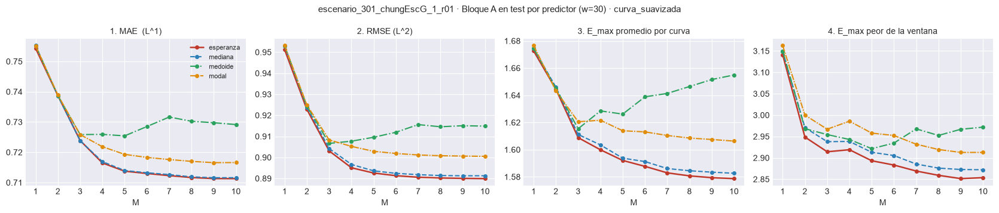

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.4196,0.5934,0.6424,0.6733,0.6882,0.6993,0.7053,0.7087,0.7107,0.7113
mediana,0.4205,0.5928,0.6424,0.6736,0.6883,0.6995,0.7055,0.7088,0.7108,0.7116
medoide,0.4205,0.5932,0.6446,0.6834,0.6994,0.7144,0.7247,0.7275,0.7291,0.7291
modal,0.4209,0.5924,0.6462,0.6802,0.6951,0.7061,0.7112,0.7142,0.7160,0.7166


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.5716,0.7460,0.8039,0.8389,0.8620,0.8747,0.8825,0.8863,0.8888,0.8899
mediana,0.5745,0.7474,0.8052,0.8406,0.8631,0.8759,0.8837,0.8875,0.8900,0.8913
medoide,0.5744,0.7477,0.8079,0.8523,0.8796,0.8958,0.9077,0.9108,0.9138,0.9149
modal,0.5748,0.7483,0.8097,0.8497,0.8726,0.8855,0.8931,0.8969,0.8994,0.9005


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.6588,0.9318,1.2192,1.3498,1.4516,1.5035,1.5467,1.5594,1.5709,1.5787
mediana,0.6604,0.9362,1.2240,1.3549,1.4543,1.5090,1.5513,1.5639,1.5747,1.5826
medoide,0.6603,0.9314,1.2238,1.3742,1.4912,1.5523,1.6086,1.6243,1.6436,1.6549
modal,0.6609,0.9303,1.2314,1.3670,1.4745,1.5263,1.5721,1.5856,1.5976,1.6063


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,1.9212,2.2197,2.4808,2.6667,2.7947,2.8206,2.8115,2.8101,2.8300,2.8536
mediana,1.9368,2.2491,2.4922,2.6952,2.8139,2.8448,2.8396,2.8299,2.8453,2.8721
medoide,1.9368,2.2493,2.5238,2.6968,2.7924,2.8584,2.9275,2.9162,2.9424,2.9718
modal,1.9482,2.2829,2.5407,2.7561,2.8728,2.8835,2.8799,2.8738,2.8813,2.9127


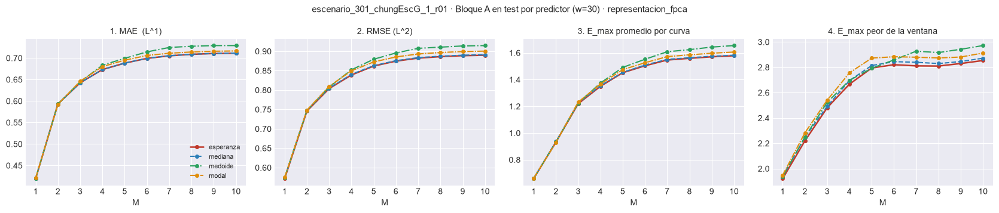

In [20]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_PRED = tabla_predictores(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_A:
        display(TAB_PRED.loc[col].style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    rel = TAB_PRED.div(TAB_PRED.xs("esperanza", level="predictor"), level="columna") - 1
    display(rel.style.format("{:+.1%}").background_gradient(cmap="RdYlGn_r", vmin=-0.1, vmax=0.1)
            .set_caption(f"Cambio relativo contra la esperanza · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_PRED, METRICAS_A,
                          f"{EXPERIMENT_BASE} · Bloque A en test por predictor (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"101_bloqueA_predictores_vs_M_{objetivo}.png")
    plt.show()

### 8.2 Bloque B por intervalo

Seis métricas en test por construcción y $M$ (`110_*`), con la esperanza.

M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,1.9507,2.8155,3.0919,3.2623,3.3684,3.4256,3.4545,3.4709,3.4811,3.4865
simultanea,1.9572,3.7002,4.3943,4.7844,5.0146,5.1160,5.1898,5.2273,5.2532,5.2621
hdr,1.9513,2.8185,3.0960,3.2684,3.3744,3.4319,3.4616,3.4778,3.4876,3.4933


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.6396,0.8694,0.9101,0.9316,0.9390,0.9433,0.9455,0.9462,0.9464,0.9470
simultanea,0.6406,0.9528,0.9790,0.9896,0.9930,0.9944,0.9952,0.9953,0.9953,0.9954
hdr,0.6401,0.8719,0.9107,0.9322,0.9415,0.9453,0.9470,0.9477,0.9485,0.9484


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.0000,0.3506,0.4669,0.5647,0.6017,0.6180,0.6299,0.6258,0.6295,0.6483
simultanea,0.0000,0.6422,0.8071,0.9116,0.9403,0.9520,0.9578,0.9633,0.9659,0.9659
hdr,0.0000,0.3653,0.4806,0.5661,0.6169,0.6364,0.6475,0.6631,0.6690,0.6583


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,9.9445,4.9775,4.4883,4.3157,4.2695,4.2432,4.2320,4.2324,4.2310,4.2329
simultanea,9.9206,4.4382,4.6814,4.9236,5.1104,5.1937,5.2612,5.2950,5.3205,5.3266
hdr,9.9336,4.9365,4.4628,4.3031,4.2629,4.2421,4.2317,4.2315,4.2298,4.2314


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,41.7160,17.3981,13.7427,11.7858,10.7425,10.2787,10.0147,9.8918,9.8298,9.8481
simultanea,41.6446,10.3161,7.8535,6.7270,6.5642,6.4493,6.4758,6.4563,6.4944,6.4729
hdr,41.6761,17.0035,13.4973,11.5997,10.5118,10.1359,9.8417,9.7260,9.6072,9.5978


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,99.8492,62.6146,55.5915,52.1030,48.9084,47.1147,46.3691,45.1386,44.9529,45.1003
simultanea,99.7722,47.4829,33.9221,25.2701,21.5911,19.1480,18.1407,17.1796,17.0427,16.8093
hdr,99.6182,61.7925,55.1840,52.3066,48.0650,47.0083,45.8408,44.7014,44.0555,44.1415


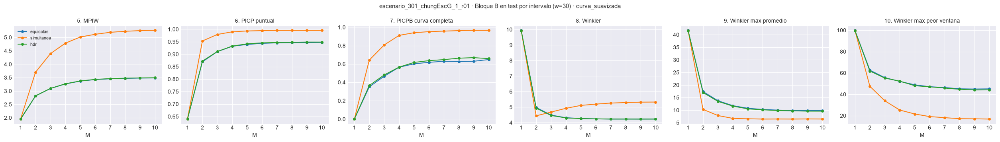

M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,1.9507,2.8155,3.0919,3.2623,3.3684,3.4256,3.4545,3.4709,3.4811,3.4865
simultanea,1.9572,3.7002,4.3943,4.7844,5.0146,5.1160,5.1898,5.2273,5.2532,5.2621
hdr,1.9513,2.8185,3.0960,3.2684,3.3744,3.4319,3.4616,3.4778,3.4876,3.4933


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.9483,0.9399,0.9419,0.9469,0.9449,0.9469,0.9462,0.9466,0.9467,0.9470
simultanea,0.9446,0.9856,0.9908,0.9924,0.9936,0.9947,0.9954,0.9954,0.9953,0.9954
hdr,0.9606,0.9385,0.9428,0.9489,0.9460,0.9472,0.9466,0.9483,0.9484,0.9484


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.9483,0.8192,0.7451,0.7123,0.6681,0.6563,0.6244,0.6309,0.6309,0.6483
simultanea,0.9446,0.9545,0.9519,0.9517,0.9519,0.9597,0.9670,0.9659,0.9659,0.9659
hdr,0.9594,0.8260,0.7483,0.7287,0.6674,0.6641,0.6423,0.6528,0.6593,0.6583


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,2.4408,3.5698,3.8300,3.9609,4.1367,4.1707,4.2003,4.2154,4.2267,4.2329
simultanea,2.4358,3.9137,4.5243,4.8769,5.0989,5.1906,5.2571,5.2926,5.3176,5.3266
hdr,2.4057,3.5563,3.8149,3.9567,4.1309,4.1696,4.2043,4.2183,4.2269,4.2314


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,3.8328,5.6188,7.2050,8.0620,9.0876,9.2466,9.5269,9.6271,9.7488,9.8481
simultanea,3.8249,5.0078,5.8333,6.1696,6.3327,6.3574,6.3802,6.3862,6.4408,6.4729
hdr,3.7777,5.5536,7.0013,7.9107,8.8704,9.0380,9.3667,9.4961,9.5256,9.5978


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,18.9510,30.3933,35.8431,42.1557,44.3989,44.5275,44.0248,44.1465,44.0428,45.1003
simultanea,19.3564,18.9983,18.1687,18.8716,18.1113,17.7309,16.9624,15.9048,16.2913,16.8093
hdr,18.2814,30.3543,35.6776,42.4715,43.5432,44.0596,43.4043,43.5668,43.0714,44.1415


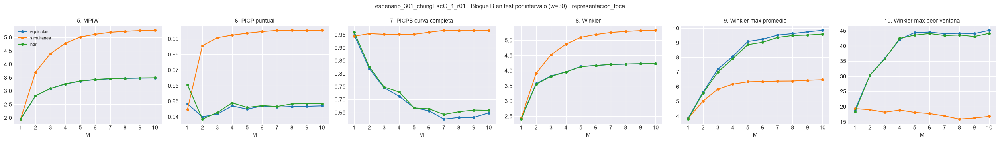

In [21]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_INT = tabla_intervalos(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_B:
        display(TAB_INT.loc[col].style.format("{:.4f}")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_INT, METRICAS_B,
                          f"{EXPERIMENT_BASE} · Bloque B en test por intervalo (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"110_intervalos_vs_M_{objetivo}.png")
    plt.show()

## 9. Monitoreo univariado por componente FPCA

MAE, RMSE y MISE del score por componente sobre la ventana móvil. Solo monitoreo.

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5236


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


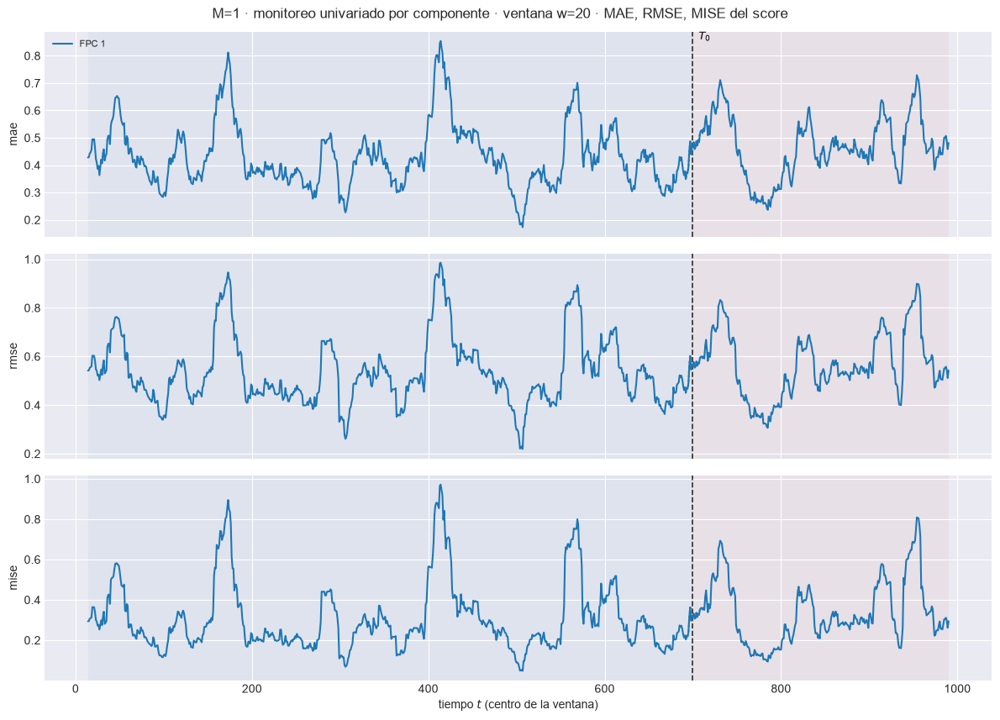

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.4073  w=30 test=0.4721


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.5081  w=30 test=0.5765


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.2581  w=30 test=0.3324


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m01\91_ventana_univariado_w30.png


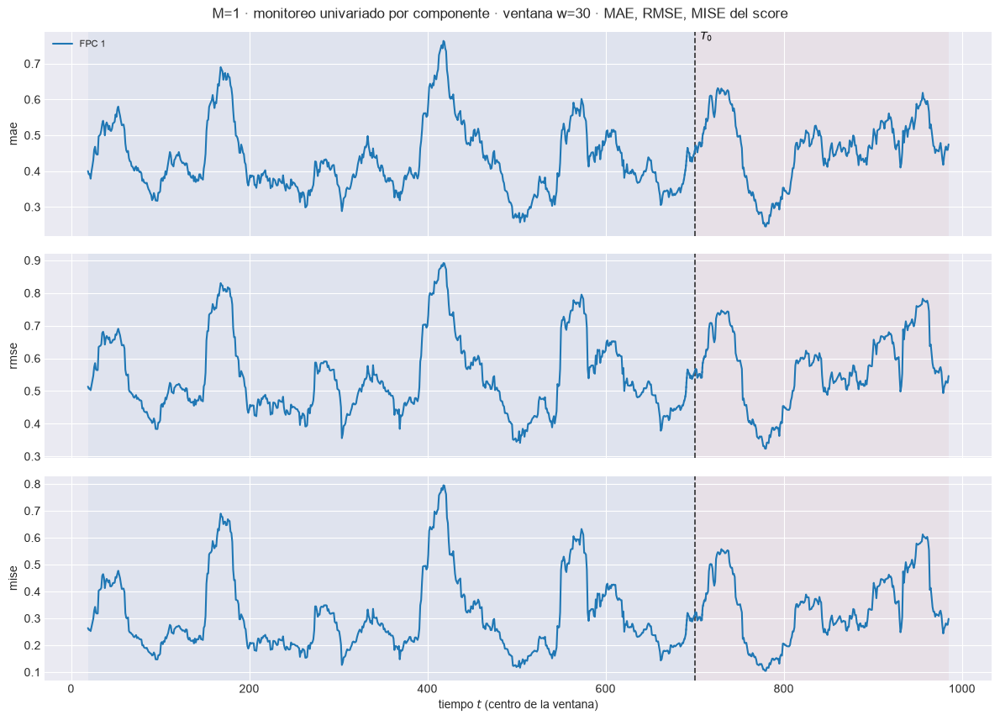

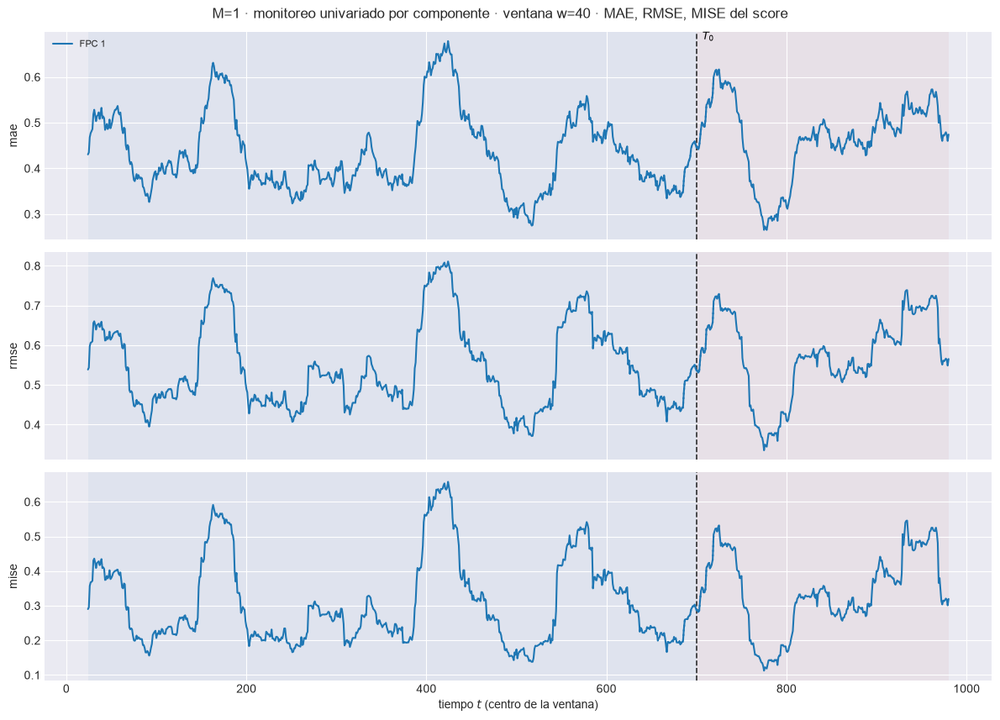

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.5236


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 2, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] rmse=0.6424


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.4152


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.4882


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.3694


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3412


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.3558


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3247


  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] rmse=0.2278


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4108


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.8868


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3942


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4436


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4087


  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] rmse=0.4845


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.4514


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.3551


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.4536


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.5588


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.3416


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.75


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.5814


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.582


[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


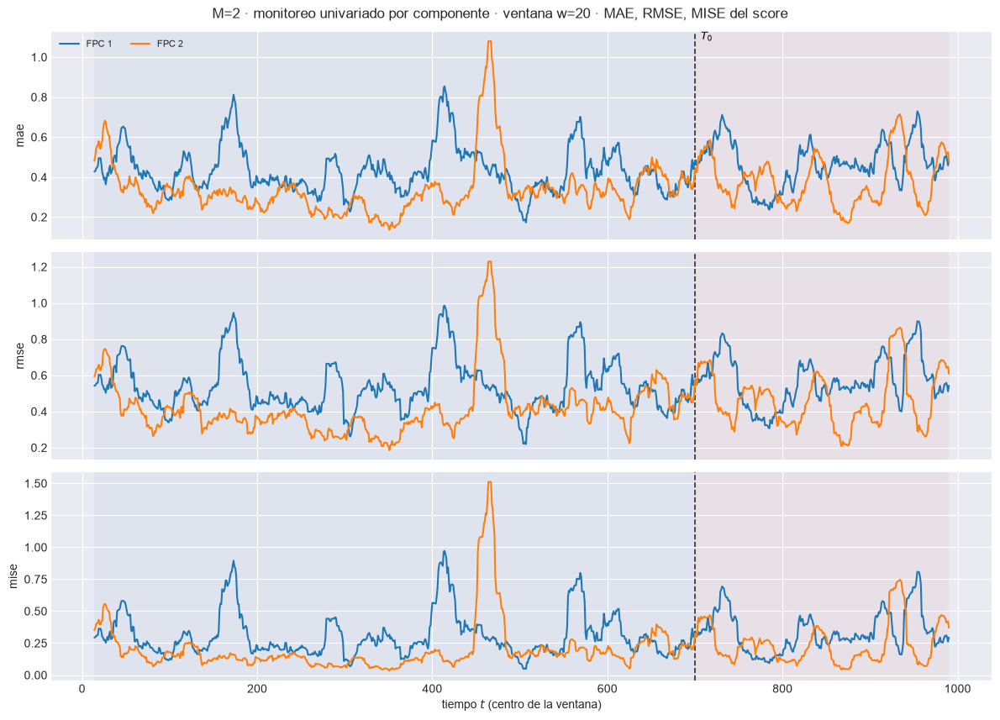

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.3589  w=30 test=0.435


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.4465  w=30 test=0.5229


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.1993  w=30 test=0.2734


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m02\91_ventana_univariado_w30.png


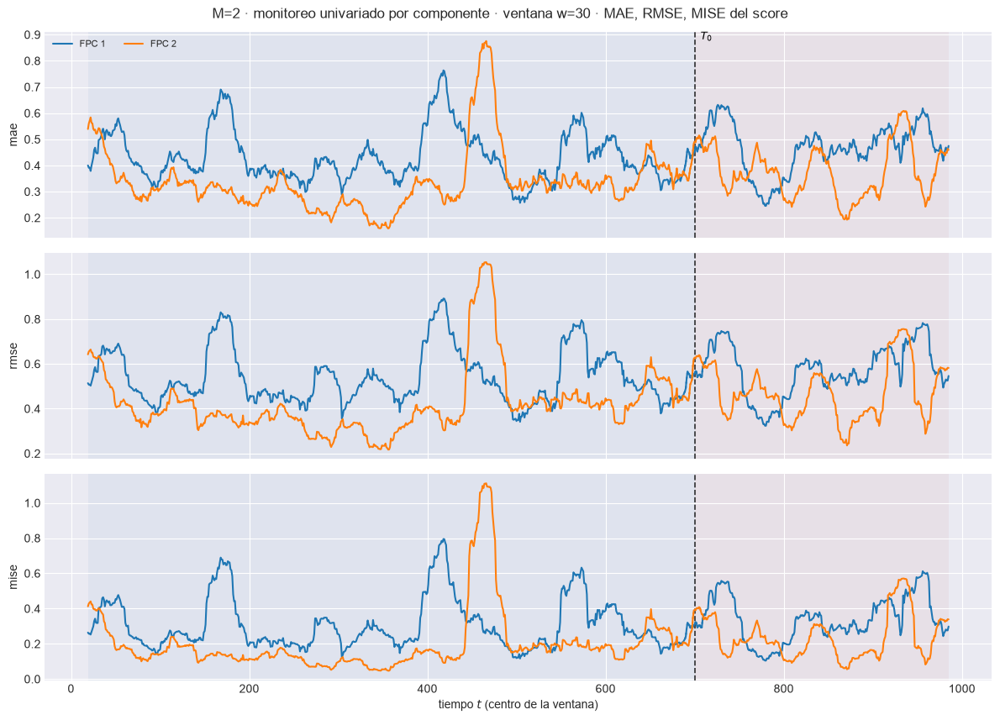

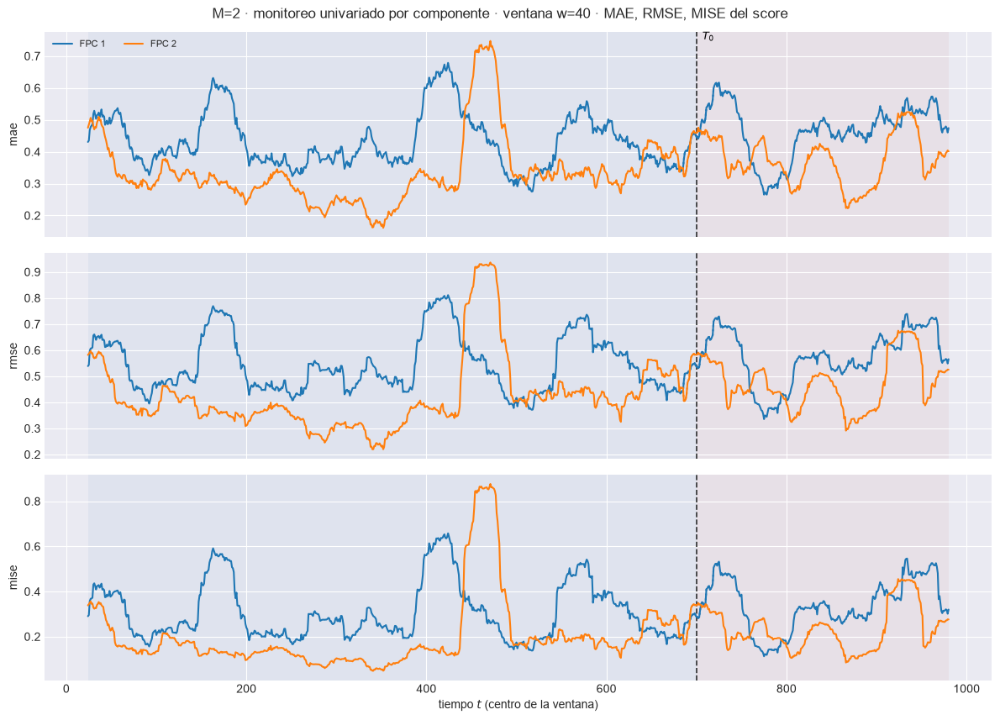

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.5236


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 2, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=0.9s  t=19 [train] rmse=0.6424


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4152


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4882


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.3694


  192/967 (19.9%) t=0.1s eta=0.2s  t=210 [train] rmse=0.3412


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.3558


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.3247


  336/967 (34.7%) t=0.1s eta=0.2s  t=354 [train] rmse=0.2278


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4108


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.8868


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3942


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4436


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4087


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4845


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.4514


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.3551


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.4536


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.5588


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.3416


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.75


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5814


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.582


[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 3, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] rmse=0.4023


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.2729


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.1997


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.265


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3449


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.3565


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3274


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2261


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4799


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3308


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.2989


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.3402


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2425


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.234


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.2275


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2312


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.2923


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.2545


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.2956


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.2028


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.4259


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.5646


[ventana_movil_scores[FPC 3, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


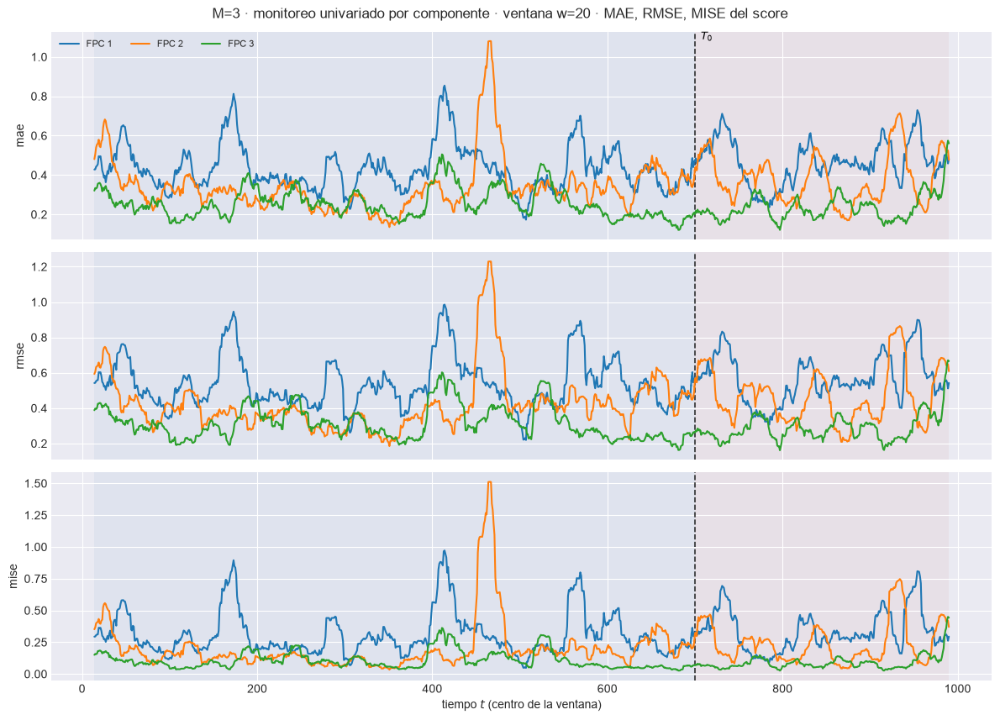

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.3264  w=30 test=0.3365


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.4104  w=30 test=0.4119


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.1684  w=30 test=0.1697


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m03\91_ventana_univariado_w30.png


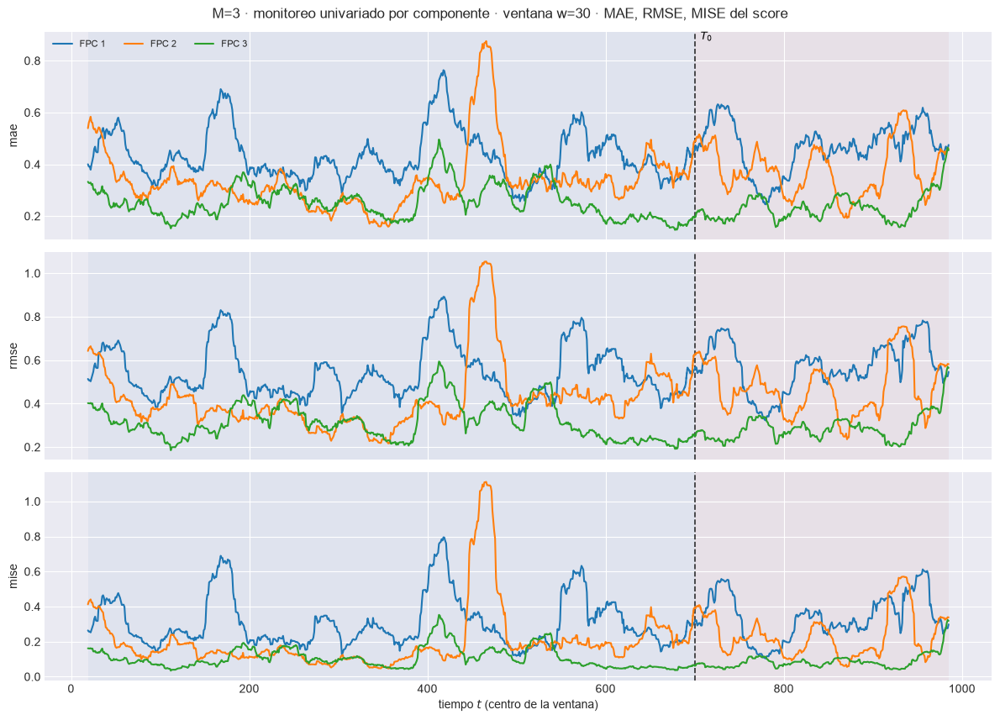

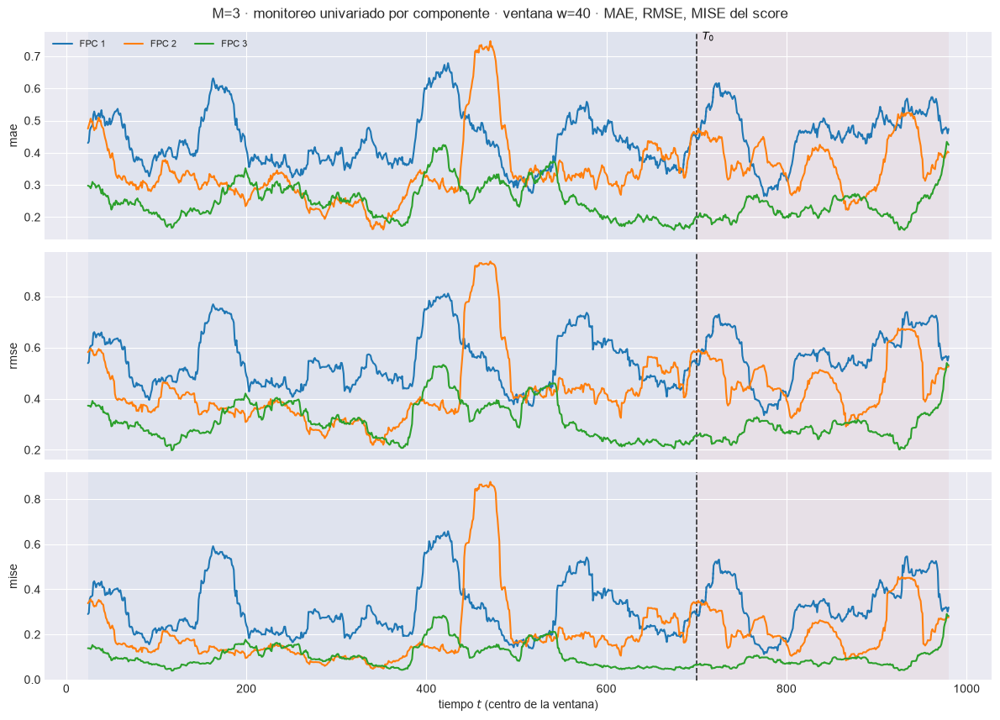

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.4s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5236


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 2, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.6424


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4152


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.4882


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.3694


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3412


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.3558


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3247


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2278


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4108


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.8868


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3942


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4436


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4087


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4845


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.4514


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.3551


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.4536


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.5588


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.3416


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.75


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5814


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.582


[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 3, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=0.9s  t=19 [train] rmse=0.4023


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.2729


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.1997


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.265


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3449


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.3565


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3274


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2261


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4799


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3308


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.2989


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.3402


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2425


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.234


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2275


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2312


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.2923


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.2545


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2956


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.2028


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.4259


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5646


[ventana_movil_scores[FPC 3, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 4, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.6s  t=19 [train] rmse=0.2597


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1958


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.2329


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.2989


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3555


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.1831


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3268


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2233


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.2064


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.2823


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1824


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4675


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2906


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.2729


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1709


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.2167


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1871


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.2605


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.208


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2527


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2506


[ventana_movil_scores[FPC 4, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


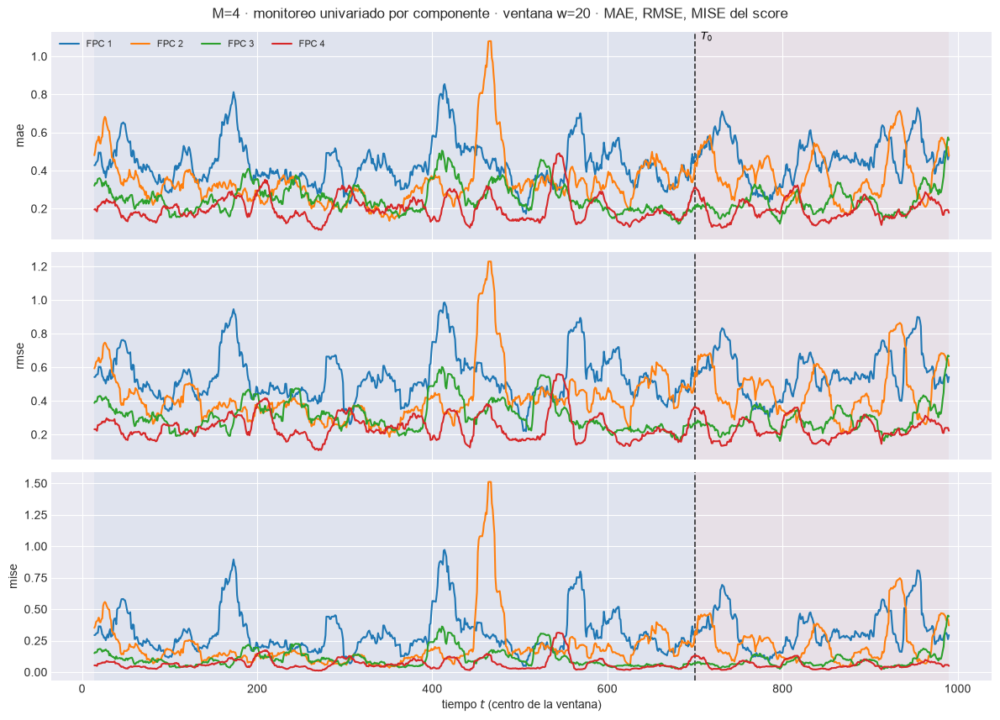

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.2865  w=30 test=0.2748


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.3567  w=30 test=0.3392


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.1272  w=30 test=0.1151


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m04\91_ventana_univariado_w30.png


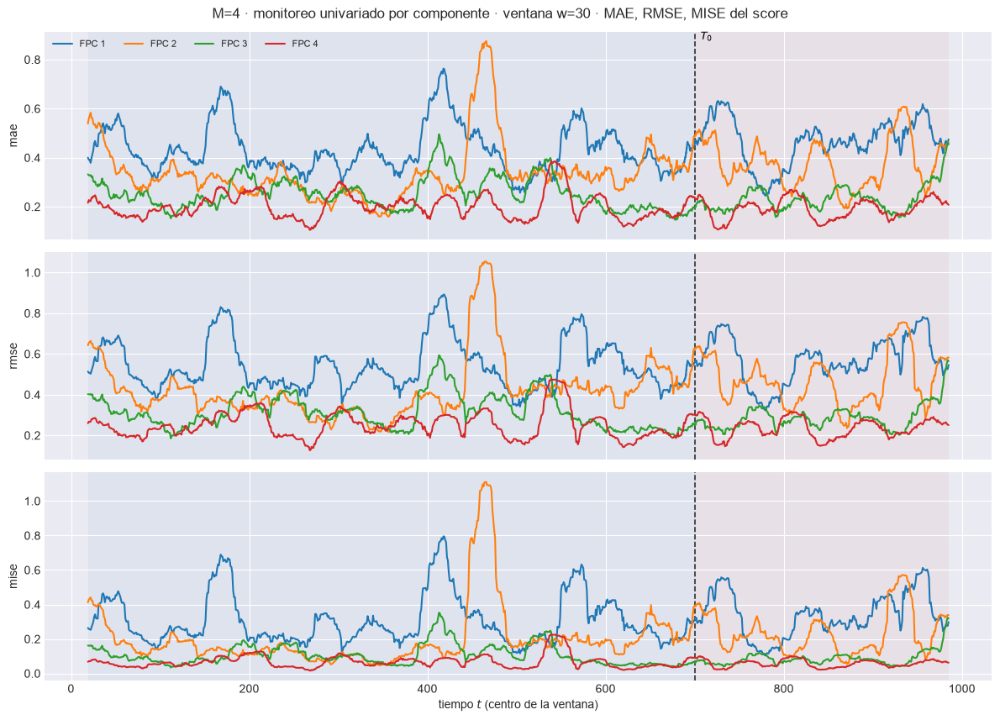

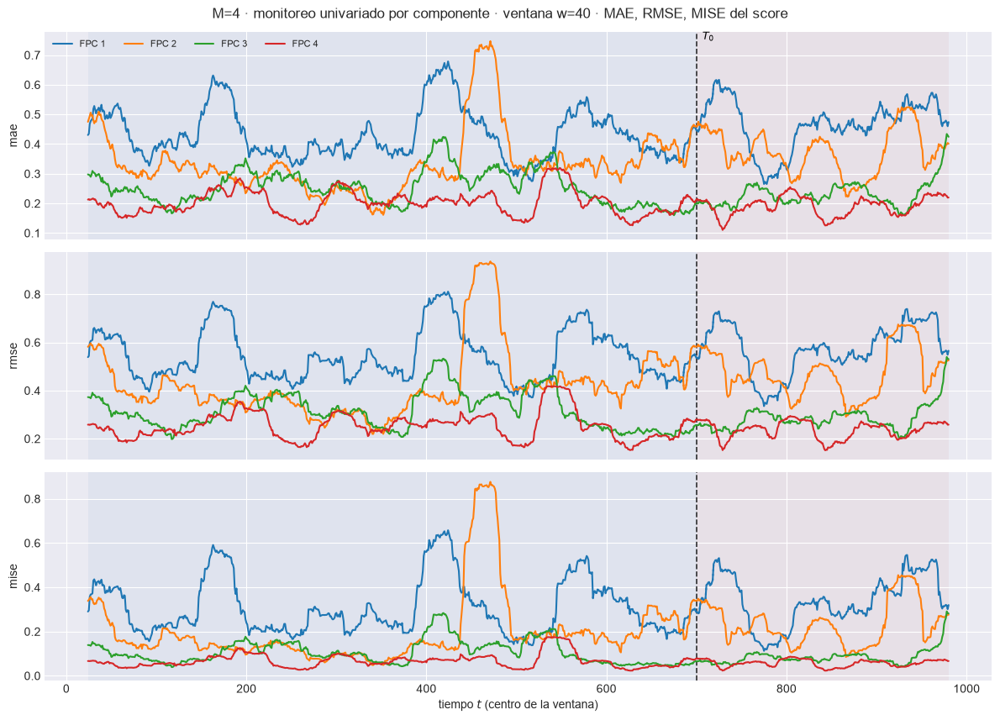

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=0.9s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.5236


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 2, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=0.9s  t=19 [train] rmse=0.6424


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4152


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.4882


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.3694


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3412


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.3558


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3247


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2278


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4108


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.8868


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3942


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4436


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4087


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4845


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.4514


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.3551


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.4536


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.5588


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.3416


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.75


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5814


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.582


[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 3, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.0s  t=19 [train] rmse=0.4023


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.2729


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.1997


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.265


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3449


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.3565


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3274


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2261


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4799


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3308


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.2989


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.3402


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2425


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.234


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.2275


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2312


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.2923


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.2545


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.2956


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.2028


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.4259


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.5646


[ventana_movil_scores[FPC 3, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 4, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.2597


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1958


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.2329


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.2989


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3555


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.1831


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3268


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2233


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.2064


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.2823


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1824


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4675


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2906


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.2729


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1709


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.2167


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1871


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.2605


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.208


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2527


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2506


[ventana_movil_scores[FPC 4, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 5, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.2307


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1932


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.2077


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.2151


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.2306


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.2154


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.1891


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2239


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1859


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1784


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1882


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.2092


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2141


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.2057


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2435


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1861


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1985


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.1685


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.1799


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2594


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2259


[ventana_movil_scores[FPC 5, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


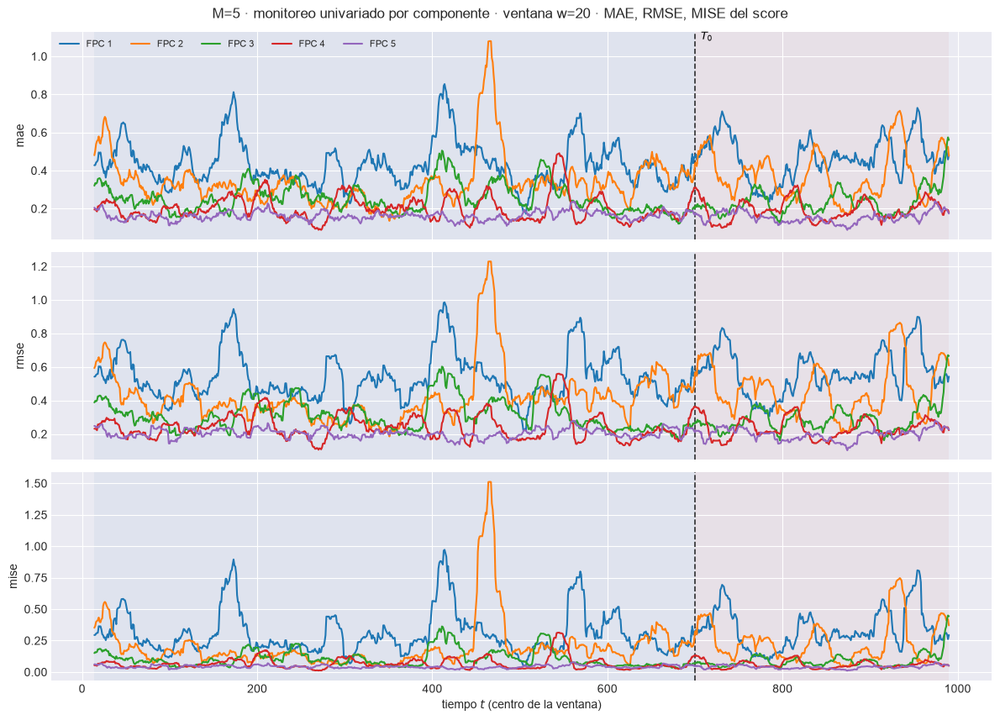

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.2499  w=30 test=0.2377


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.309  w=30 test=0.2893


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.09551  w=30 test=0.08367


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m05\91_ventana_univariado_w30.png


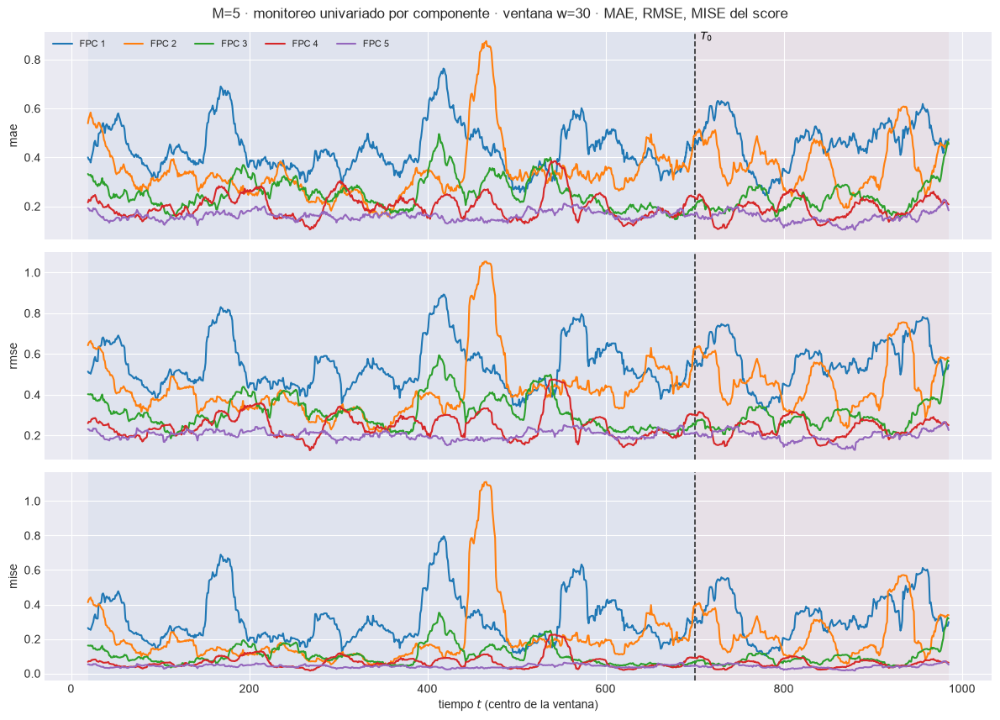

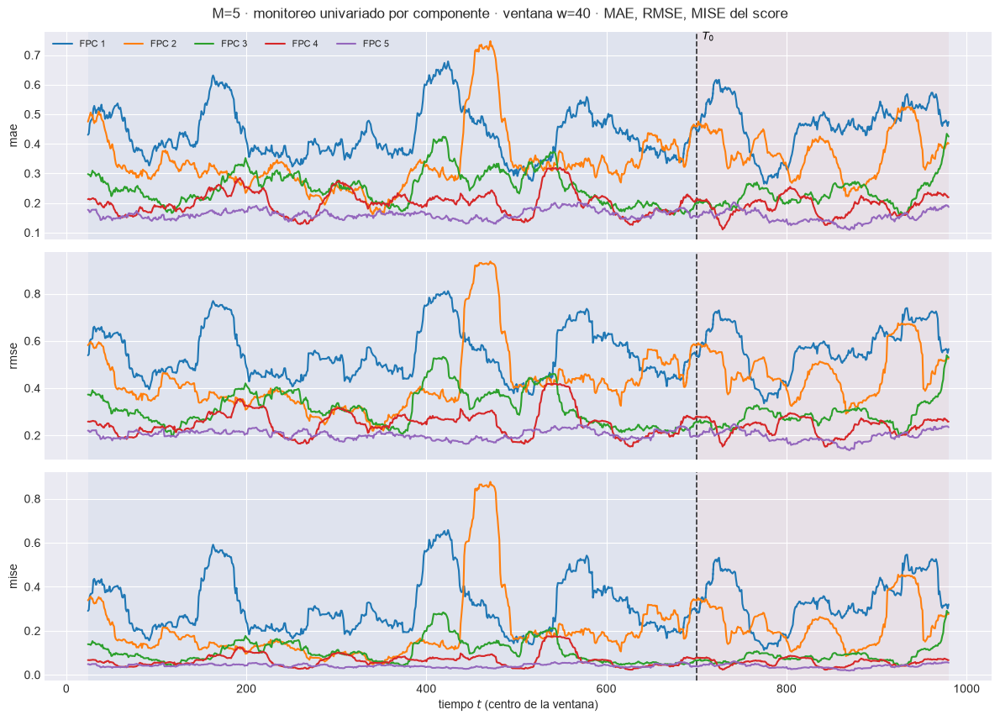

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.6s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5236


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 2, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.0s  t=19 [train] rmse=0.6424


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4152


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4882


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.3694


  192/967 (19.9%) t=0.1s eta=0.2s  t=210 [train] rmse=0.3412


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.3558


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.3247


  336/967 (34.7%) t=0.1s eta=0.2s  t=354 [train] rmse=0.2278


  384/967 (39.7%) t=0.1s eta=0.2s  t=402 [train] rmse=0.4108


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.8868


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3942


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4436


  576/967 (59.6%) t=0.2s eta=0.1s  t=594 [train] rmse=0.4087


  624/967 (64.5%) t=0.2s eta=0.1s  t=642 [train] rmse=0.4845


  672/967 (69.5%) t=0.2s eta=0.1s  t=690 [train] rmse=0.4514


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.3551


  768/967 (79.4%) t=0.2s eta=0.1s  t=786 [test] rmse=0.4536


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.5588

  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.3416

  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.75


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5814


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.582


[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.3s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 3, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.4s  t=19 [train] rmse=0.4023


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.2729


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1997


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.265


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.3449


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.3565


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3274


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2261


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4799


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3308


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.2989


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.3402


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2425


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.234


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2275


  720/967 (74.5%) t=0.1s eta=0.1s  t=738 [test] rmse=0.2312


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.2923


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.2545


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2956


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.2028


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.4259


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5646


[ventana_movil_scores[FPC 3, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0

[ventana_movil_scores[FPC 4, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] rmse=0.2597


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1958


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.2329


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.2989


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3555


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.1831


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3268


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2233


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.2064


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.2823


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1824


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4675


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2906


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2729


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1709


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.2167


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.1871


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2605


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.208


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2527


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2506


[ventana_movil_scores[FPC 4, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 5, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.0s  t=19 [train] rmse=0.2307


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.1932


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.2077


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.2151


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.2306


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.2154


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.1891


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2239


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1859


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1784


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1882


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.2092


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2141


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.2057


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2435


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1861


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1985


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.1685


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.1799


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2594


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2259


[ventana_movil_scores[FPC 5, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 6, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.7s  t=19 [train] rmse=0.1675


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1244


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1501


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.1597


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.1386


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.1538


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.1535


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.1601


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1318


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1417


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1384


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.1248


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.1181


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1828


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.1165


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1401


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.1659


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.1561


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.1683


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1191


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.1588


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.1597


[ventana_movil_scores[FPC 6, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0

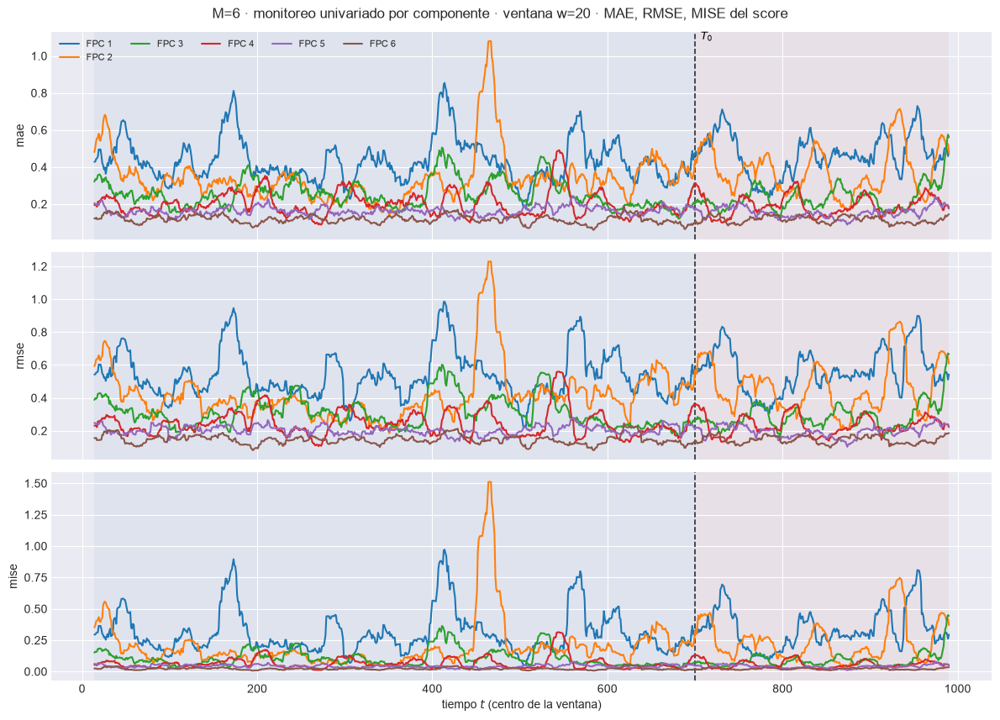

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.2149  w=30 test=0.2082


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.2653  w=30 test=0.2596


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.07039  w=30 test=0.06737


[plot_ventana_movil] listo: 3 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m06\91_ventana_univariado_w30.png


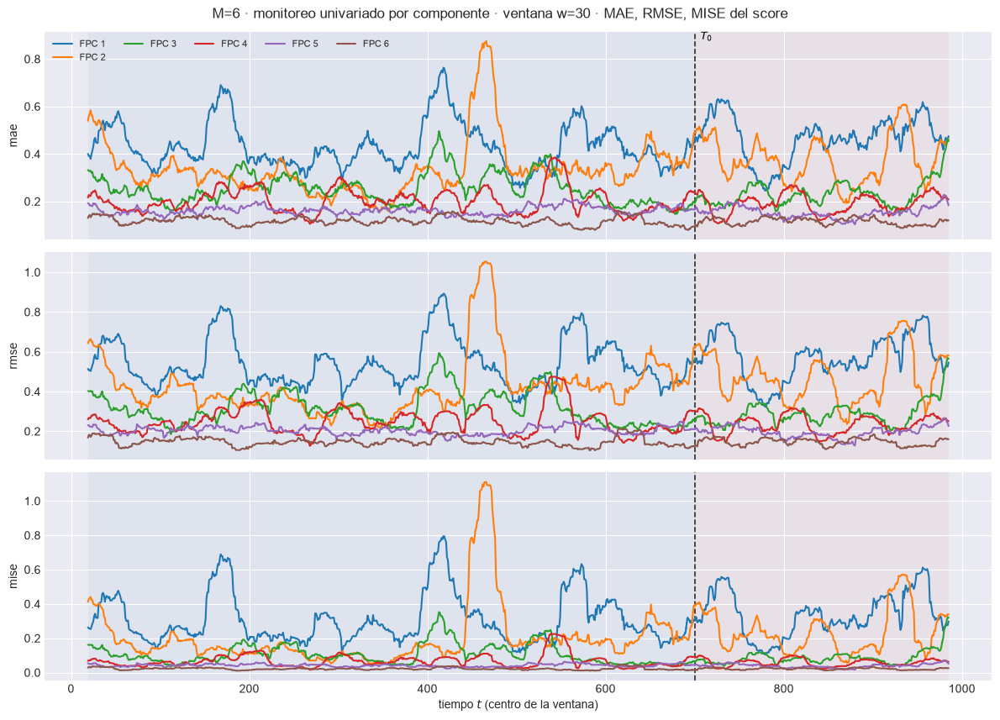

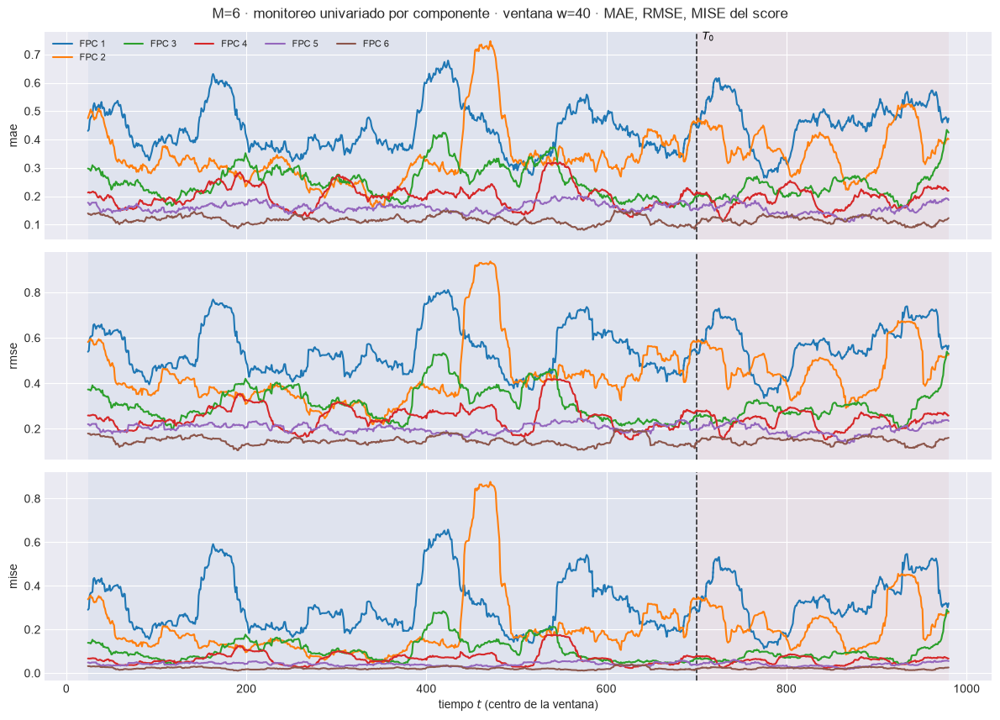

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.7s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.1s eta=0.2s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5236


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0

[ventana_movil_scores[FPC 2, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] rmse=0.6424


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4152


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4882


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.3694


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.3412


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.3558


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.3247


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2278


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4108


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.8868


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3942


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4436


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4087


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4845


  672/967 (69.5%) t=0.2s eta=0.1s  t=690 [train] rmse=0.4514


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.3551


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.4536


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.5588


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.3416


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.75

  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5814


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.582

[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0

[ventana_movil_scores[FPC 3, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.6s  t=19 [train] rmse=0.4023


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.2729


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1997


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.265


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.3449


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.3565


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3274


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2261


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4799


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3308


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.2989


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.3402


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2425


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.234


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2275


  720/967 (74.5%) t=0.1s eta=0.1s  t=738 [test] rmse=0.2312


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.2923


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.2545


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2956


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.2028


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.4259


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5646


[ventana_movil_scores[FPC 3, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 4, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.2597


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1958


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.2329


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.2989


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.3555


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.1831


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3268


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2233


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.2064


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.2823


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1824


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4675


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2906


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2729


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1709


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.2167


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.1871


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2605


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.208


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2527


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2506


[ventana_movil_scores[FPC 4, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 5, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.5s  t=19 [train] rmse=0.2307


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1932


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.2077


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.2151


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.2306


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.2154


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.1891


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2239


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1859


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1784


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1882


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.2092


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2141


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2057


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2435


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1861


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1985


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.1685


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1799


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2594


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2259


[ventana_movil_scores[FPC 5, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 6, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.4s  t=19 [train] rmse=0.1675


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1244


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1501


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.1597


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.1386


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.1538


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.1535


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.1601


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1318


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1417


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1384


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.1248


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.1181


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1828


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.1165


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1401


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1659


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1561


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.1683


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.1191


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.1588


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.1597


[ventana_movil_scores[FPC 6, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 7, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.1043


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1131


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1267


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.1124


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.1164


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.08862


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.09084


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.08852


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.09659


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1188


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1274


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.1125


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.1072


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1388


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.08814


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1098


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1226


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1116


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.08719


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.1163


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.1131


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.09842


[ventana_movil_scores[FPC 7, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


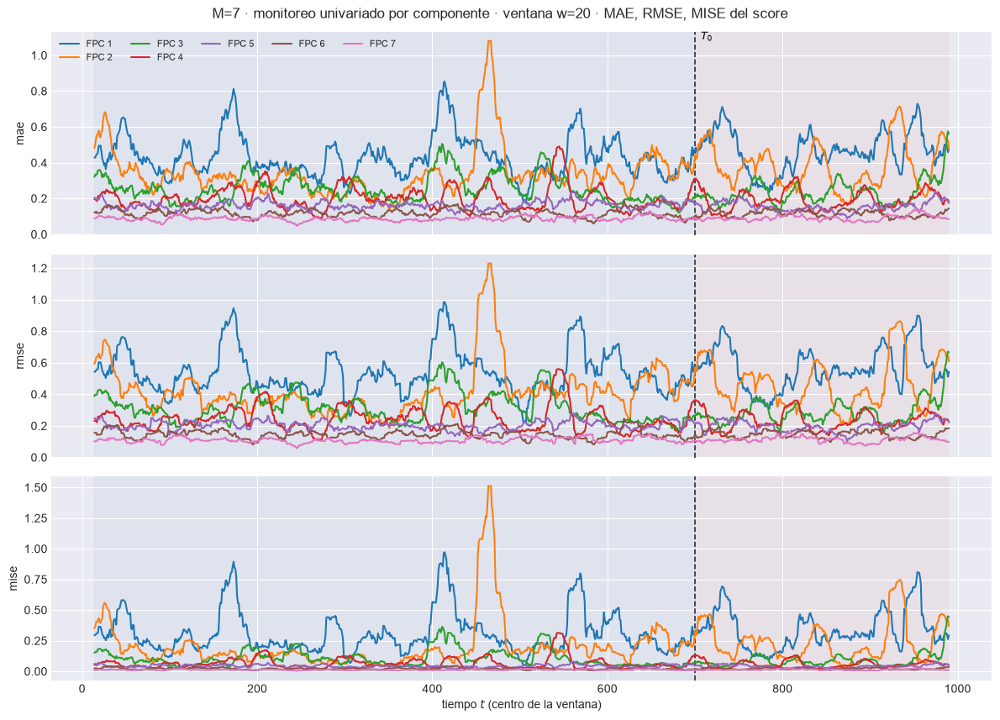

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1862  w=30 test=0.1841


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.2303  w=30 test=0.2294


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.05303  w=30 test=0.05264


[plot_ventana_movil] listo: 3 pasos en 0.9s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m07\91_ventana_univariado_w30.png


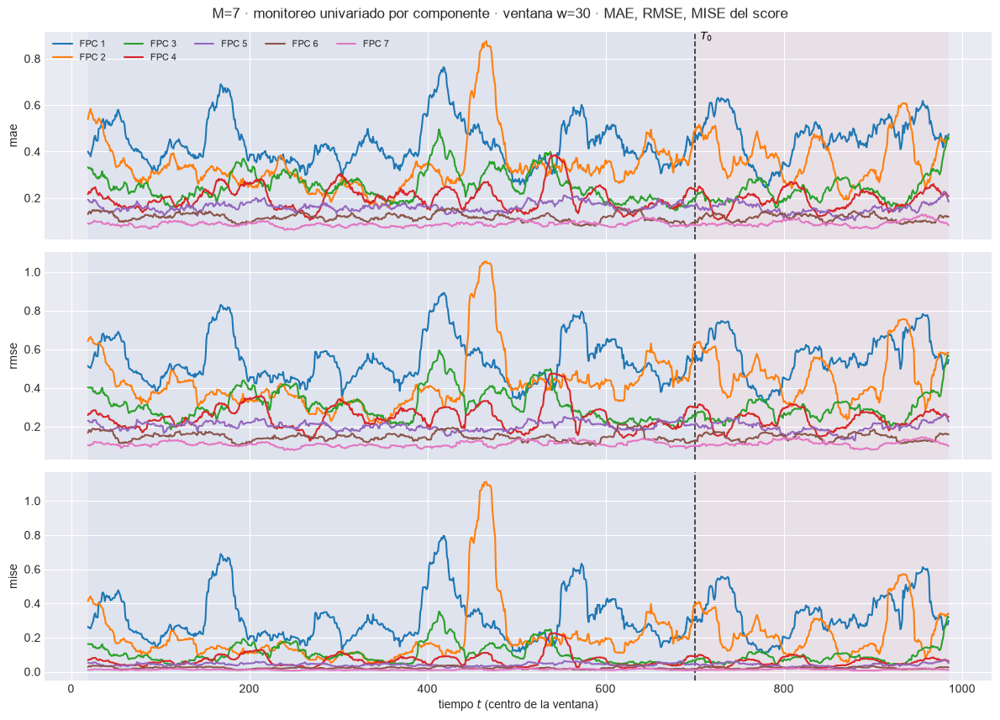

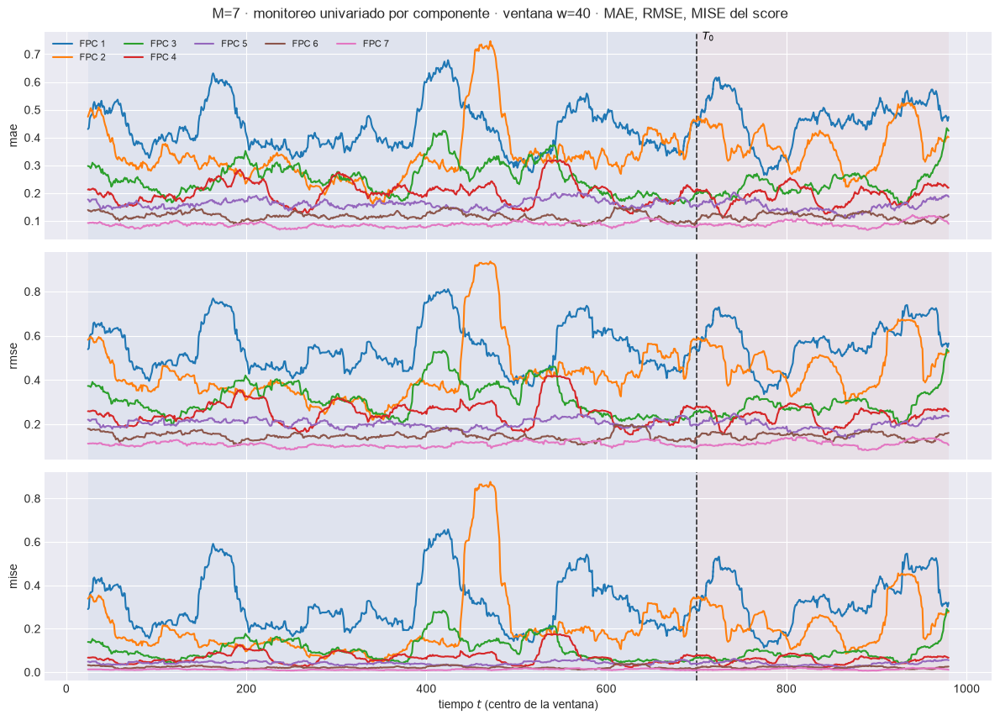

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.7s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5236


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 2, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.8s  t=19 [train] rmse=0.6424


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4152


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4882


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.3694


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.3412


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.3558


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3247


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2278


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4108


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.8868


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3942


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4436


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4087


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4845


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.4514


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.3551


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.4536


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.5588


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.3416


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.75


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5814


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.582


[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 3, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] rmse=0.4023


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.2729


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1997


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.265


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.3449


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.3565


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3274


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2261


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4799


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3308


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.2989


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.3402


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2425


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.234


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2275


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.2312


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.2923


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.2545


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2956


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.2028


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.4259


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5646


[ventana_movil_scores[FPC 3, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0

[ventana_movil_scores[FPC 4, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=2.0s  t=19 [train] rmse=0.2597


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1958


  96/967 ( 9.9%) t=0.0s eta=0.3s  t=114 [train] rmse=0.2329


  144/967 (14.9%) t=0.0s eta=0.3s  t=162 [train] rmse=0.2989


  192/967 (19.9%) t=0.1s eta=0.2s  t=210 [train] rmse=0.3555


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.1831


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.3268


  336/967 (34.7%) t=0.1s eta=0.2s  t=354 [train] rmse=0.2233


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.2064


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.2823


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1824


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4675


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2906


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2729


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.1709


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.2167


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.1871


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2605


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.208


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2527


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2506


[ventana_movil_scores[FPC 4, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 5, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.2307


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.1932


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.2077


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.2151


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.2306


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.2154


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.1891


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2239


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1859


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1784


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1882


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.2092


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2141


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2057


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2435


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1861


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1985


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.1685


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1799


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2594


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2259


[ventana_movil_scores[FPC 5, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 6, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.0s  t=19 [train] rmse=0.1675


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1244


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.1501


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.1597


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.1386


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.1538


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.1535


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.1601


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1318


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1417


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1384


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.1248


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.1181


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1828


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.1165


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1401


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1659


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.1561


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.1683


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1191


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.1588


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.1597


[ventana_movil_scores[FPC 6, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 7, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] rmse=0.1043


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1131


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1267


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.1124


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.1164


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.08862


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.09084


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.08852


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.09659


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1188


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1274


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.1125


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.1072


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1388


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.08814


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1098


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1226


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.1116


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.08719


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1163


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.1131


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.09842


[ventana_movil_scores[FPC 7, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 8, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.4s  t=19 [train] rmse=0.07796


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.08179


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.06255


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.08401


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.07751


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.08033


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.06606


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.07179


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.09417


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.08622


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.07901


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.09076


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.0821


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.0845


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.1027


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.0732


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.07804


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.08433


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.08697


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.08738


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.07733


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.07704


[ventana_movil_scores[FPC 8, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


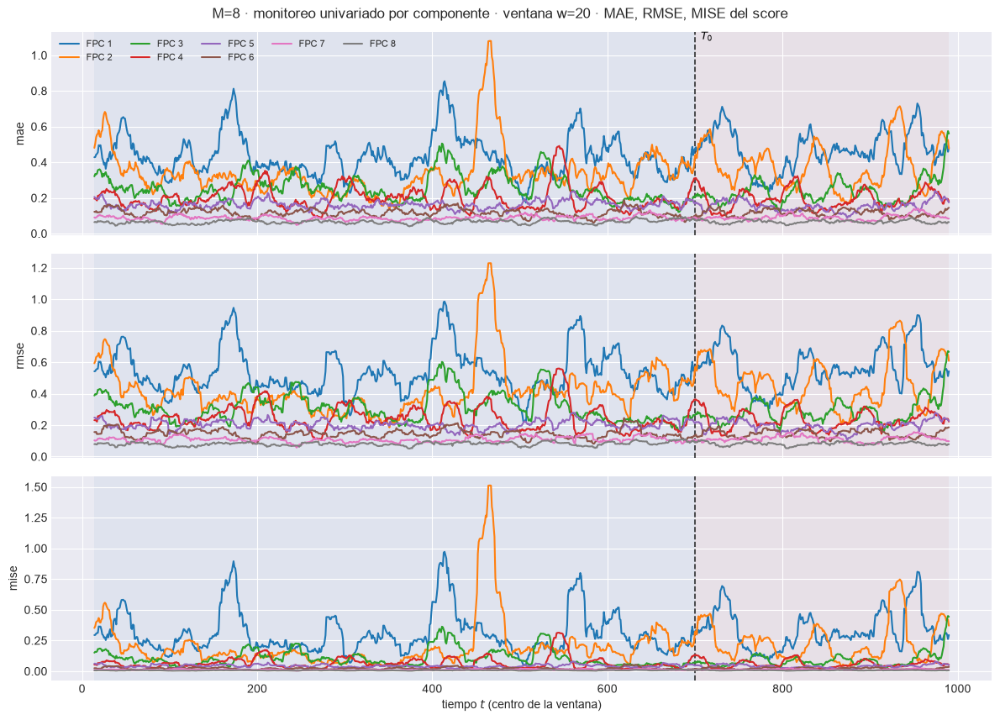

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.1s eta=0.1s  mae: w=30 train=0.1676  w=30 test=0.1637


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.2122  w=30 test=0.2082


  3/3 (100.0%) t=0.2s eta=0.0s  mise: w=30 train=0.04502  w=30 test=0.04337


[plot_ventana_movil] listo: 3 pasos en 1.0s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m08\91_ventana_univariado_w30.png


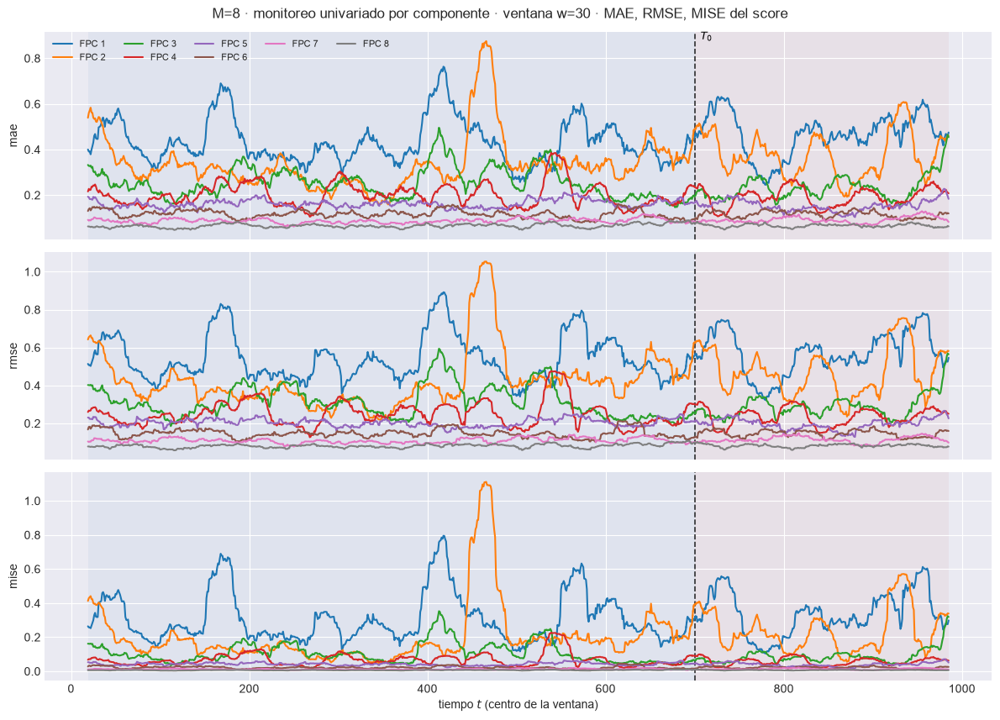

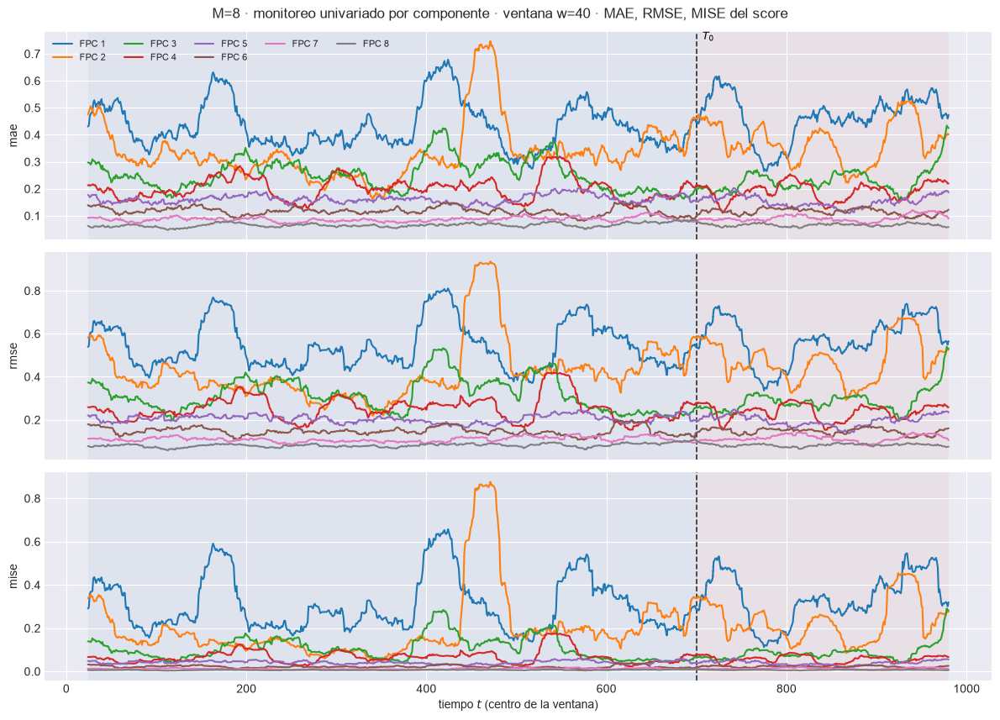

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.6s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5236

  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0

[ventana_movil_scores[FPC 2, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=3.0s  t=19 [train] rmse=0.6424


  48/967 ( 5.0%) t=0.0s eta=0.3s  t=66 [train] rmse=0.4152


  96/967 ( 9.9%) t=0.0s eta=0.3s  t=114 [train] rmse=0.4882


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.3694


  192/967 (19.9%) t=0.1s eta=0.2s  t=210 [train] rmse=0.3412


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.3558


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.3247


  336/967 (34.7%) t=0.1s eta=0.2s  t=354 [train] rmse=0.2278


  384/967 (39.7%) t=0.1s eta=0.2s  t=402 [train] rmse=0.4108


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.8868


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3942


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4436


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4087


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4845


  672/967 (69.5%) t=0.2s eta=0.1s  t=690 [train] rmse=0.4514


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.3551


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.4536


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.5588


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.3416


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.75


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5814


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.582


[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 3, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=2.3s  t=19 [train] rmse=0.4023


  48/967 ( 5.0%) t=0.0s eta=0.3s  t=66 [train] rmse=0.2729


  96/967 ( 9.9%) t=0.0s eta=0.3s  t=114 [train] rmse=0.1997


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.265


  192/967 (19.9%) t=0.1s eta=0.2s  t=210 [train] rmse=0.3449


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.3565


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.3274


  336/967 (34.7%) t=0.1s eta=0.2s  t=354 [train] rmse=0.2261


  384/967 (39.7%) t=0.1s eta=0.2s  t=402 [train] rmse=0.4799


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3308


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.2989


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.3402


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2425


  624/967 (64.5%) t=0.2s eta=0.1s  t=642 [train] rmse=0.234


  672/967 (69.5%) t=0.2s eta=0.1s  t=690 [train] rmse=0.2275


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.2312


  768/967 (79.4%) t=0.2s eta=0.1s  t=786 [test] rmse=0.2923


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.2545


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2956


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.2028


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.4259


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5646


[ventana_movil_scores[FPC 3, w=30]] listo: 967 pasos en 0.3s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 4, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=2.1s  t=19 [train] rmse=0.2597


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1958


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.2329


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.2989


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.3555


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.1831


  288/967 (29.8%) t=0.1s eta=0.2s  t=306 [train] rmse=0.3268


  336/967 (34.7%) t=0.1s eta=0.2s  t=354 [train] rmse=0.2233


  384/967 (39.7%) t=0.1s eta=0.2s  t=402 [train] rmse=0.2064


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.2823


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1824


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4675


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2906


  624/967 (64.5%) t=0.2s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.2s eta=0.1s  t=690 [train] rmse=0.2729


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.1709


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.2167


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.1871


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2605


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.208

  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2527


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2506


[ventana_movil_scores[FPC 4, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 5, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=2.0s  t=19 [train] rmse=0.2307


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1932


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.2077


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.2151


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.2306


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.2154


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.1891


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2239


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1859


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1784


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1882


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.2092


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2141


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2057


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2435


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1861


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1985


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.1685


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1799


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2594


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2259


[ventana_movil_scores[FPC 5, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 6, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=2.0s  t=19 [train] rmse=0.1675


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1244


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1501


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.1597


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.1386


  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.1538


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.1535


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.1601


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1318


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1417


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1384


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.1248


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.1181


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1828


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.1165


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.1401


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.1659


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.1561


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.1683


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1191


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.1588


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.1597


[ventana_movil_scores[FPC 6, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 7, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.1043


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1131


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1267


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.1124


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.1164


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.08862


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.09084


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.08852


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.09659


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1188


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1274


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.1125


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.1072


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1388


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.08814


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1098


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1226


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1116


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.08719


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1163


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.1131


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.09842


[ventana_movil_scores[FPC 7, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 8, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] rmse=0.07796


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.08179


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.06255


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.08401


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.07751


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.08033


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.06606


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.07179


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.09417


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.08622


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.07901


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.09076


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.0821


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.0845


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.1027


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.0732


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.07804


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.08433


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.08697


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.08738


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.07733


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.07704


[ventana_movil_scores[FPC 8, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 9, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.5s  t=19 [train] rmse=0.06477


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.05723


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.07762


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.05897


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.06344


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.06257


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.07903


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.0629


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.0747


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.0413


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.07318


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.06109


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.06478


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.0562


  672/967 (69.5%) t=0.2s eta=0.1s  t=690 [train] rmse=0.06233


  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [test] rmse=0.0484


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.07617


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.06561

  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.06658


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.07842


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.05446


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.05521


[ventana_movil_scores[FPC 9, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


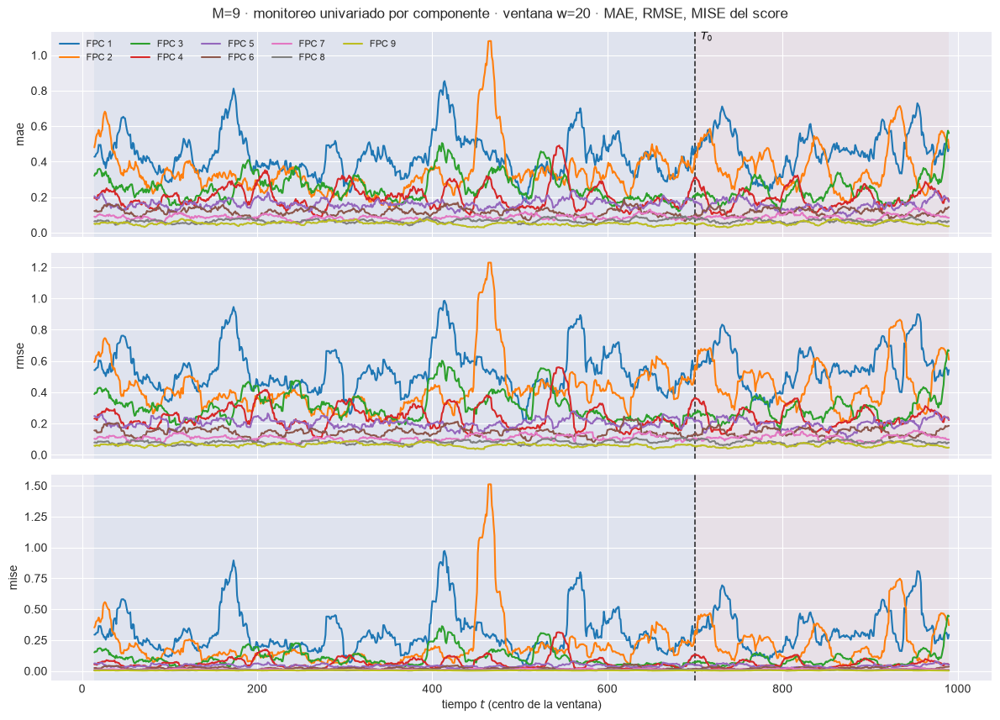

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.1s eta=0.1s  mae: w=30 train=0.1536  w=30 test=0.143


  2/3 (66.7%) t=0.1s eta=0.1s  rmse: w=30 train=0.1936  w=30 test=0.1873


  3/3 (100.0%) t=0.2s eta=0.0s  mise: w=30 train=0.0375  w=30 test=0.03507


[plot_ventana_movil] listo: 3 pasos en 0.9s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m09\91_ventana_univariado_w30.png


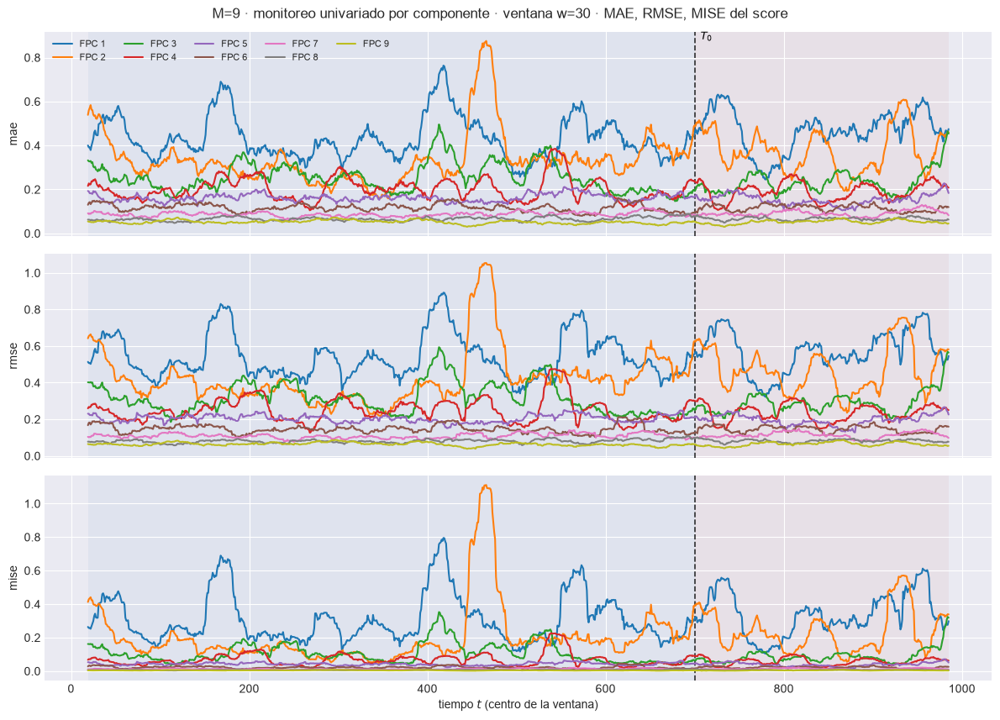

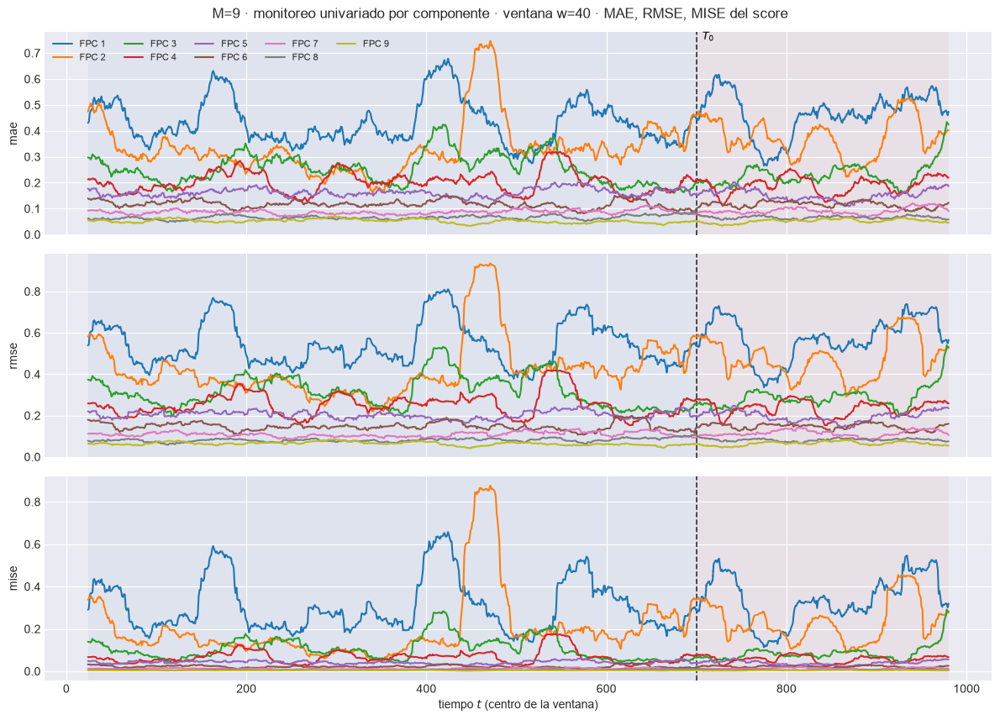

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.5137


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.4974


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.4955


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.7557


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.4747


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4228


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3932


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.4981


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.791


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.5863


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3533


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5215


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.5862


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4964


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.4908


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.7422


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.3747


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.597


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.5323


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.5474


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5236


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5462


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 2, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=0.9s  t=19 [train] rmse=0.6424


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.4152


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.4882


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.3694


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3412


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.3558


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3247


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2278


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4108


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.8868


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.3942


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4436


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4087


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.4845


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.4514


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.3551


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.4536


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.5588


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.3416


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.75


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.5814


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.582


[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 3, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.4023


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.2729


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1997


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.265


  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.3449


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.3565


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.3274


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2261


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4799


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3308


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.2989


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.3402


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2425


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.234


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2275


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2312


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.2923


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.2545


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2956


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.2028


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.4259


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.5646


[ventana_movil_scores[FPC 3, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 4, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.2597


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1958


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.2329


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.2989


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3555


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.1831


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.3268


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2233


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.2064


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.2823


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1824


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.4675


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2906


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.2729


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1709


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.2167


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.1871


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.2605


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.208


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2527


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2506


[ventana_movil_scores[FPC 4, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 5, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.2307


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1932


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.2077


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.2151


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.2306


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.2154


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.1891


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.2239


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1859


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1784


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1882


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.2092


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.2141


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1931


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.2057


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.2435


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1861


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1985


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.1685


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1799


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.2594


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2259


[ventana_movil_scores[FPC 5, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 6, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.1675


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1244


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1501


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.1597


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.1386


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.1538


  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.1535


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.1601


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.1318


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1417


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1384


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.1248


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.1181


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1828


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.1165


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1401


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1659


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1561


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.1683


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1191


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.1588


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.1597


[ventana_movil_scores[FPC 6, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 7, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.1043


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.1131


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.1267


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.1124


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.1164


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.08862


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.09084


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.08852


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.09659


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.1188


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.1274


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.1125


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.1072


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.1388


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.08814


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.1098


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.1226


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.1116


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.08719


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.1163


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.1131


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.09842


[ventana_movil_scores[FPC 7, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 8, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.07796


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.08179


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.06255


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.08401


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.07751


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.08033


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.06606


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.07179


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.09417


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.08622


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.07901


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.09076


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.0821


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.0845


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.1027


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.0732


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.07804


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.08433


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.08697


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.08738


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.07733


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.07704


[ventana_movil_scores[FPC 8, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 9, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=0.9s  t=19 [train] rmse=0.06477


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.05723


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.07762


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.05897


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.06344


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.06257


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.07903


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.0629


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.0747


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.0413


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.07318


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.06109


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.06478


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.0562


  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.06233


  720/967 (74.5%) t=0.1s eta=0.1s  t=738 [test] rmse=0.0484


  768/967 (79.4%) t=0.2s eta=0.0s  t=786 [test] rmse=0.07617


  816/967 (84.4%) t=0.2s eta=0.0s  t=834 [test] rmse=0.06561


  864/967 (89.3%) t=0.2s eta=0.0s  t=882 [test] rmse=0.06658


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.07842


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.05446


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.05521


[ventana_movil_scores[FPC 9, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


[ventana_movil_scores[FPC 10, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.5s  t=19 [train] rmse=0.04244


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.04734


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.03583


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.05834


  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.04489


  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.0459


  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.05026


  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.04615


  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.05409


  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.04209


  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.04836


  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.04743


  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.05203


  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.04731


  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.04486


  720/967 (74.5%) t=0.1s eta=0.0s  t=738 [test] rmse=0.04235


  768/967 (79.4%) t=0.1s eta=0.0s  t=786 [test] rmse=0.04493


  816/967 (84.4%) t=0.1s eta=0.0s  t=834 [test] rmse=0.0472


  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.03891


  912/967 (94.3%) t=0.2s eta=0.0s  t=930 [test] rmse=0.03665


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.05062


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.0523


[ventana_movil_scores[FPC 10, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


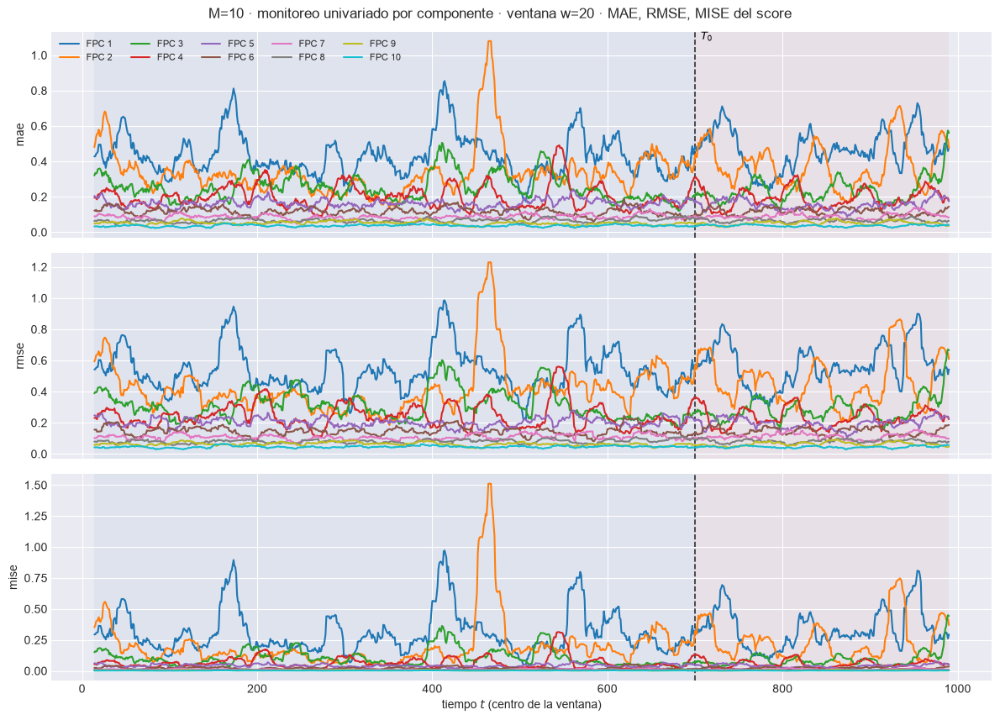

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.1s eta=0.1s  mae: w=30 train=0.139  w=30 test=0.128


  2/3 (66.7%) t=0.1s eta=0.1s  rmse: w=30 train=0.1743  w=30 test=0.1623


  3/3 (100.0%) t=0.2s eta=0.0s  mise: w=30 train=0.03037  w=30 test=0.02633


[plot_ventana_movil] listo: 3 pasos en 0.9s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m10\91_ventana_univariado_w30.png


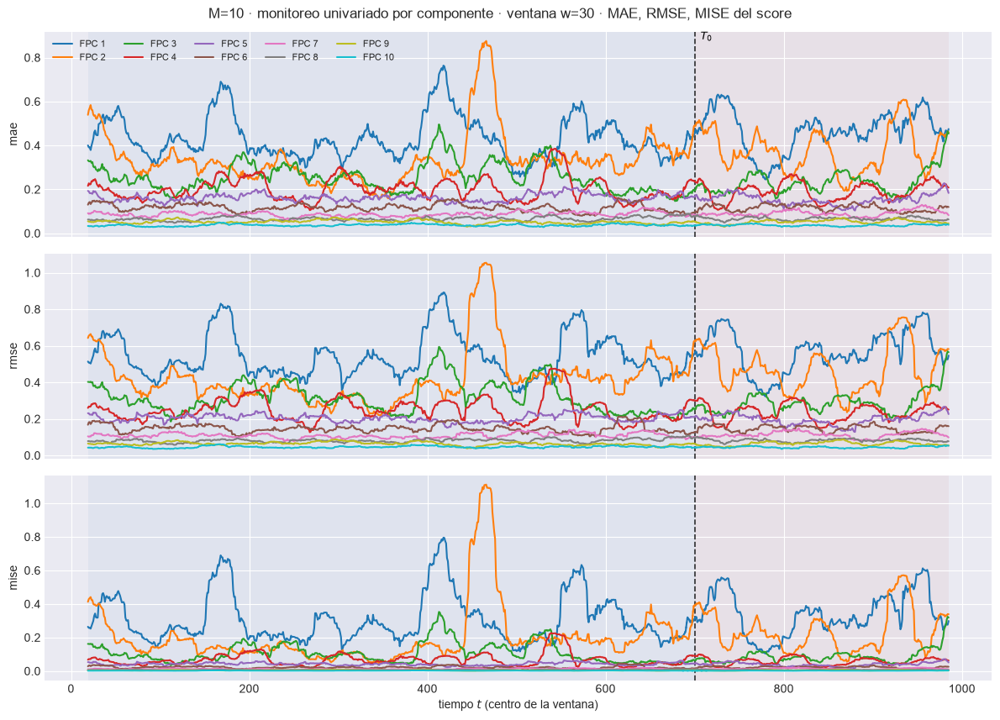

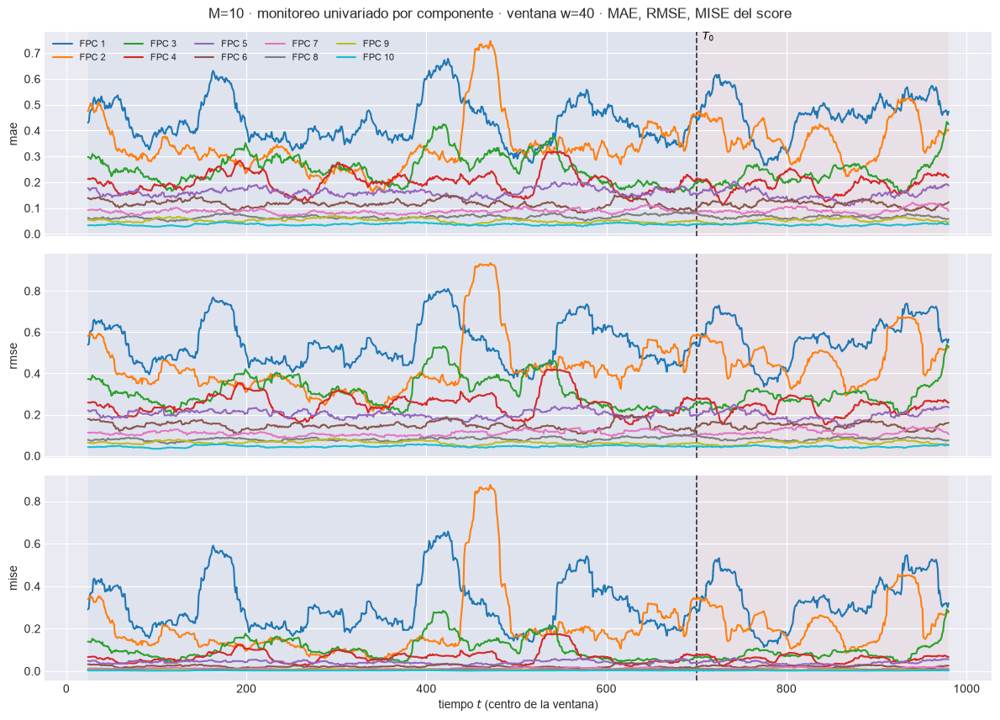

In [22]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

La banda es `li_s`/`ls_s` de §3, antes de propagar.

### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

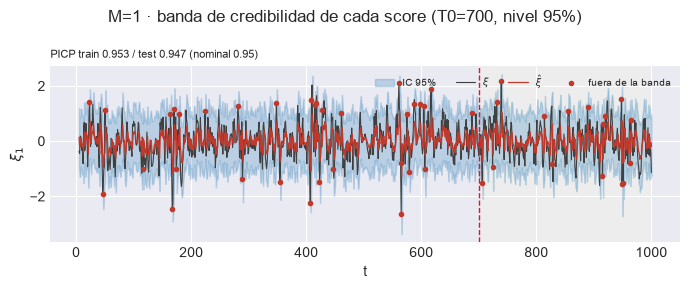

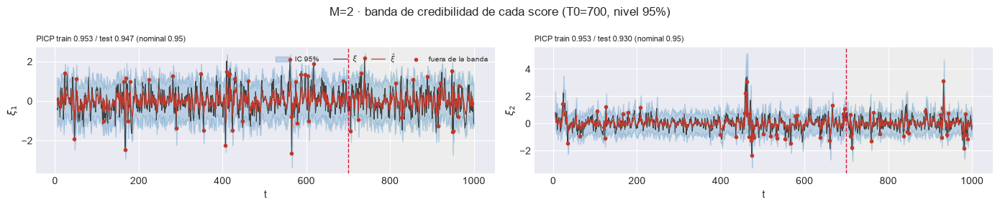

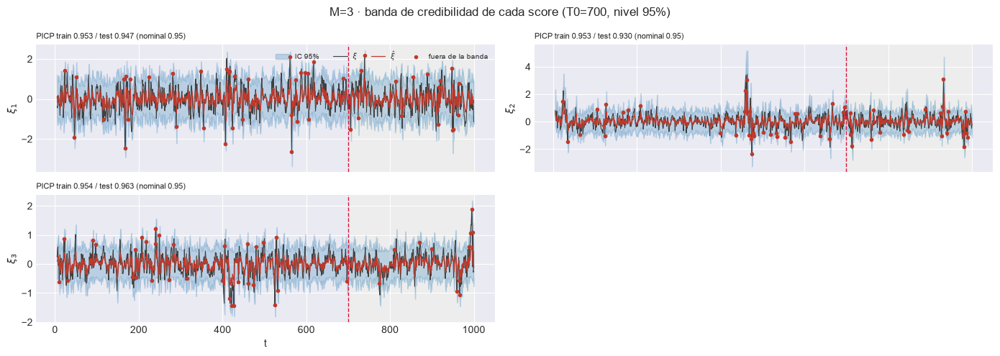

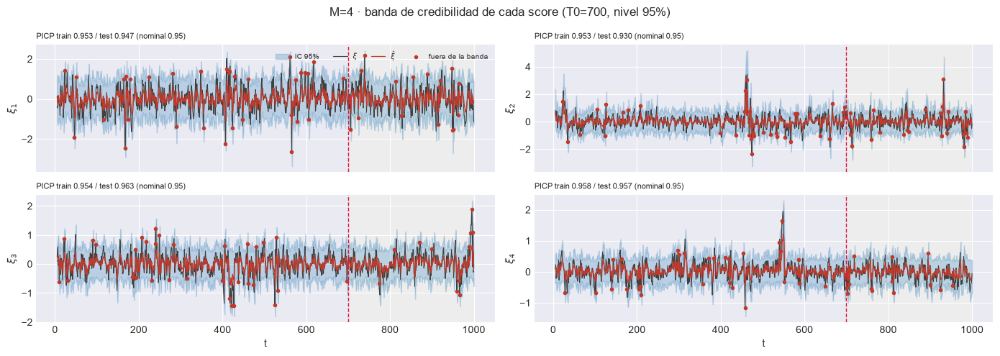

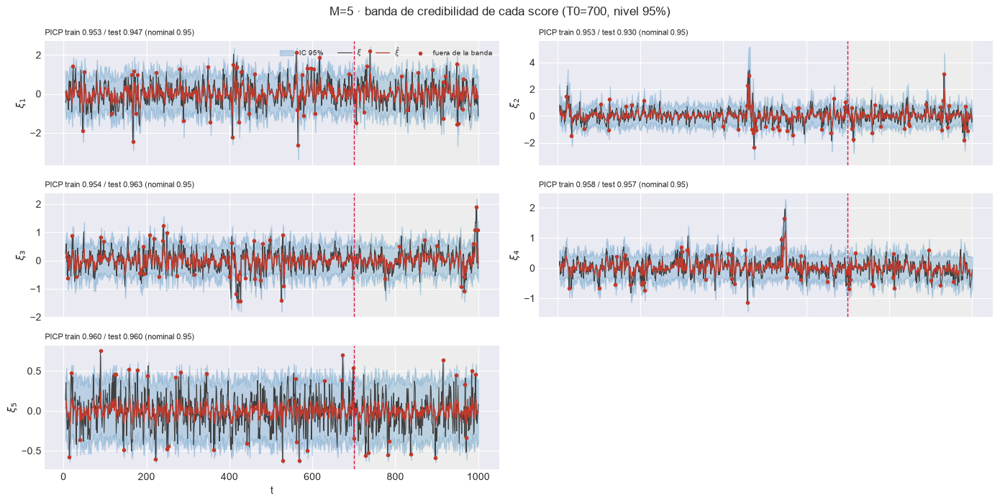

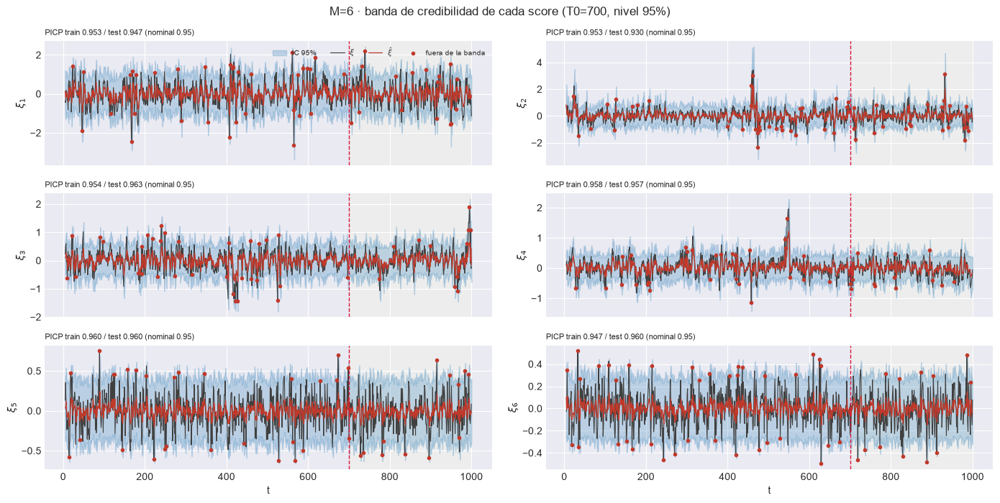

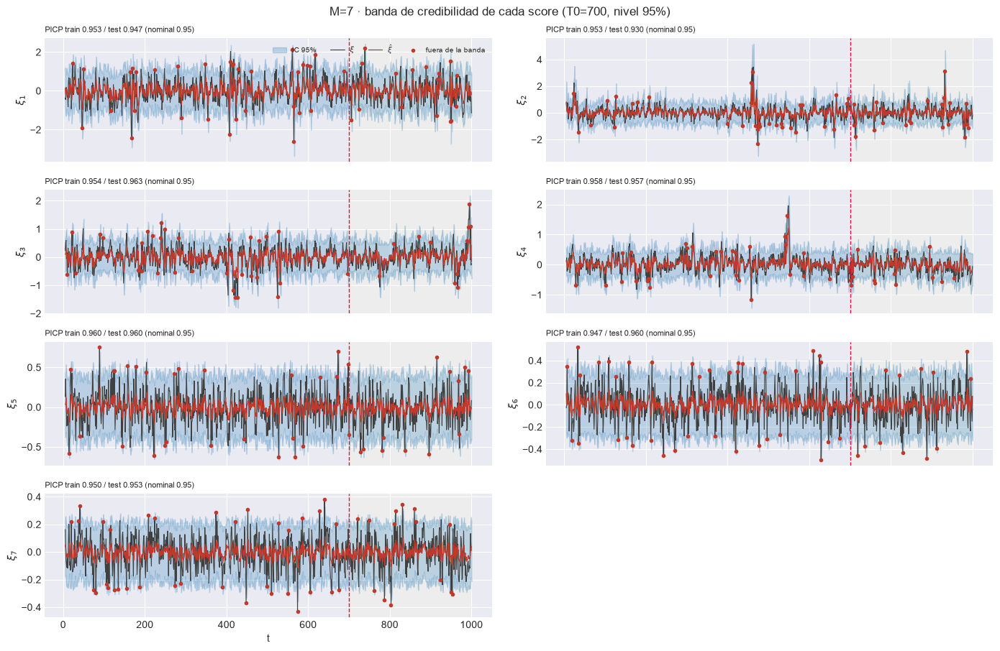

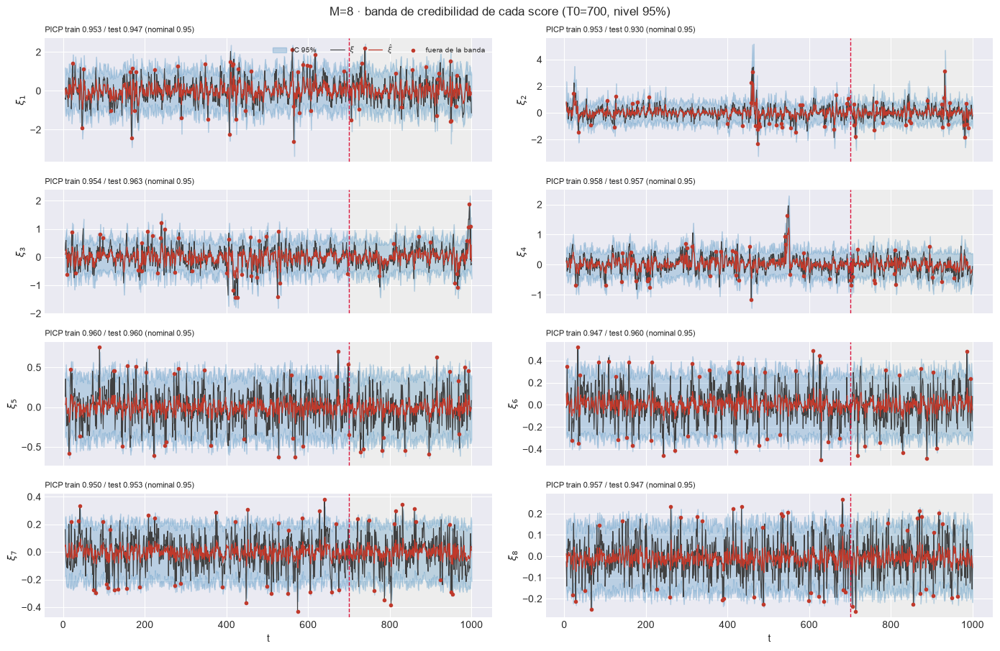

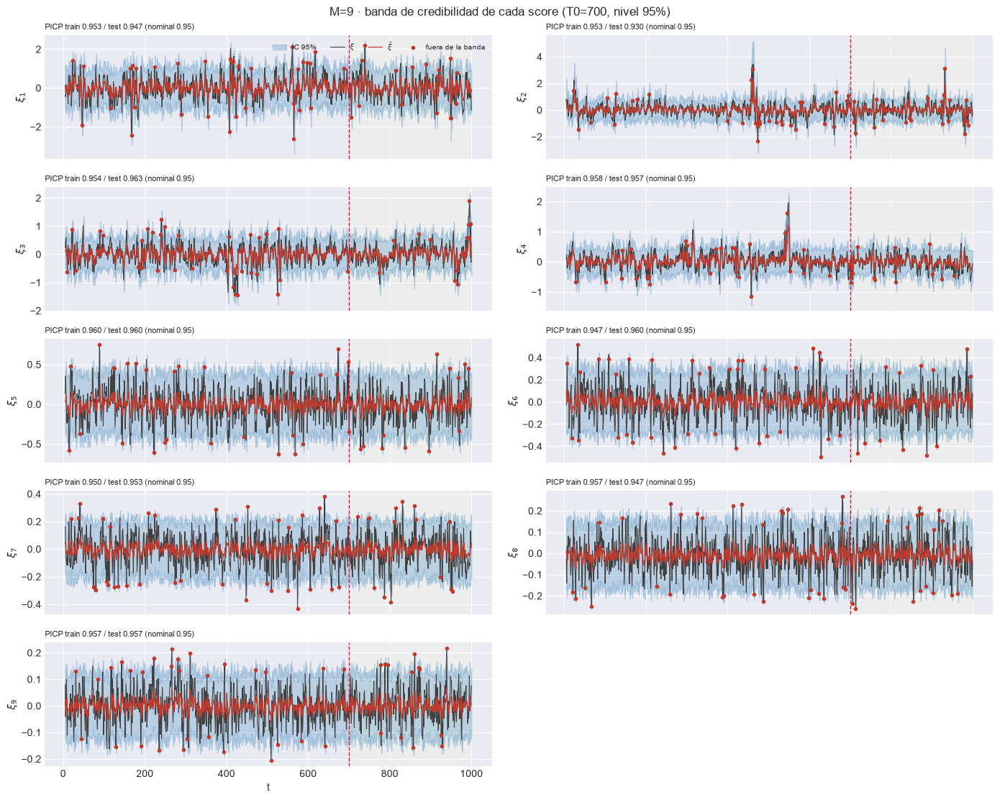

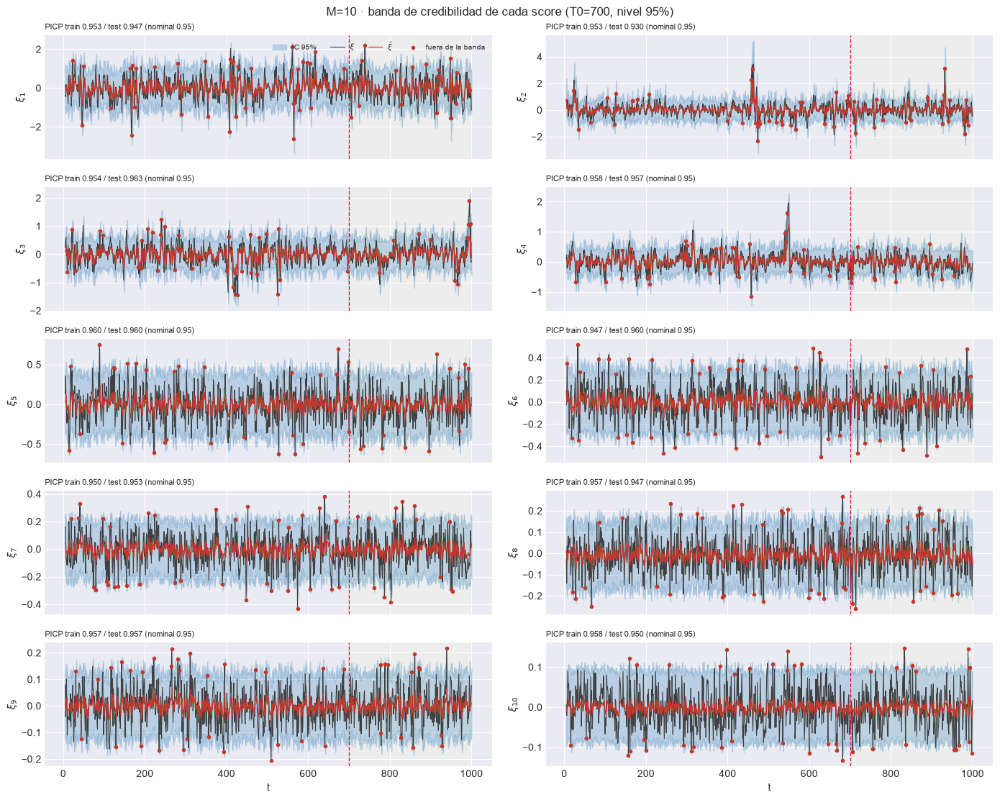

In [23]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

PICP, MPIW, Winkler y ACE por componente; global por bloque y sobre la ventana móvil.

OK ninguna componente se aleja mas de 0.1 del nominal en test.


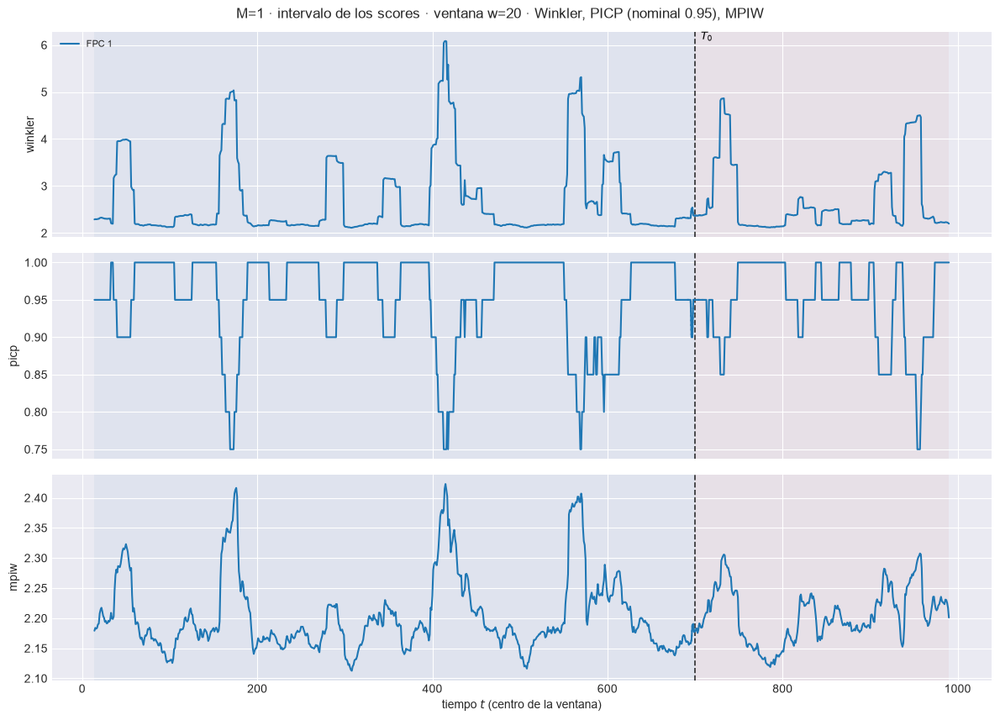

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=2.291  w=30 test=2.4


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=2.183  w=30 test=2.209


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m01\93_ventana_scores_intervalo_w30.png


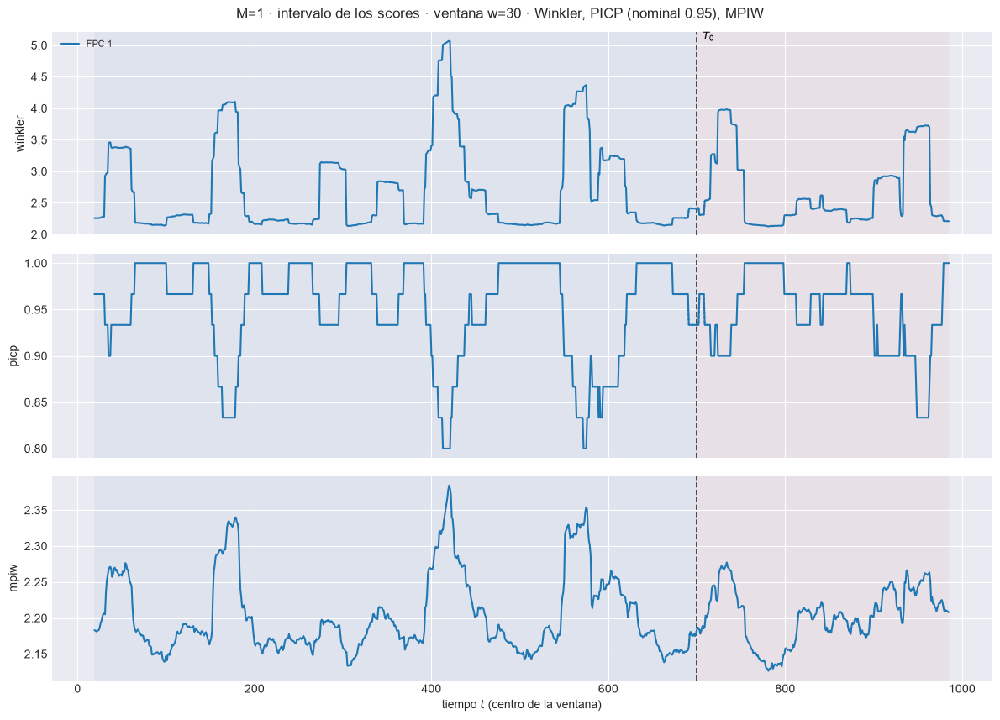

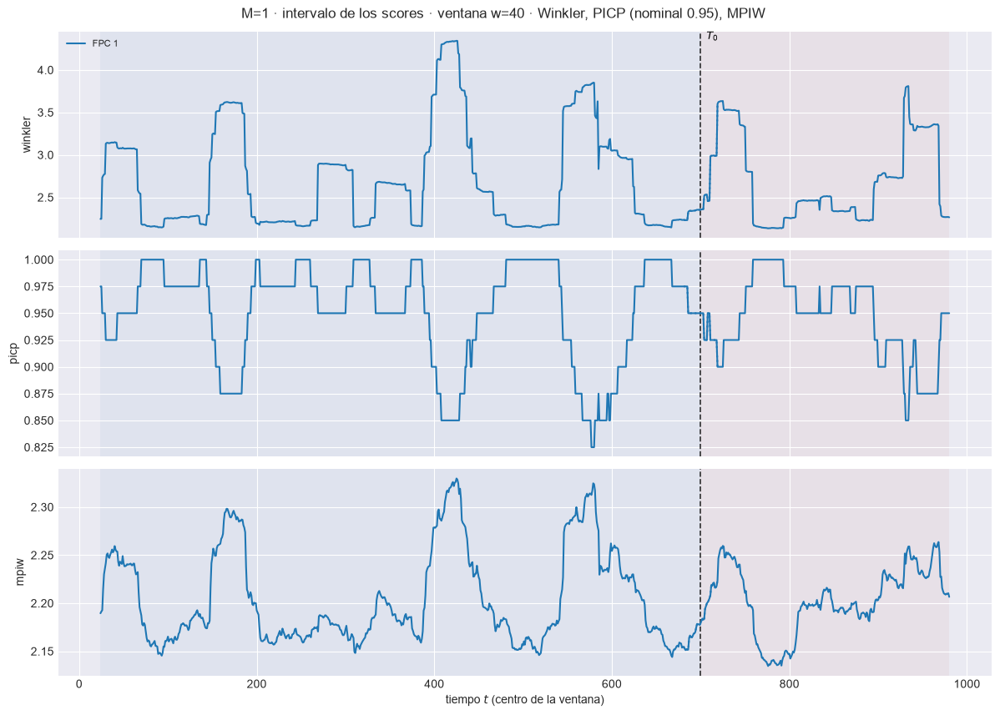

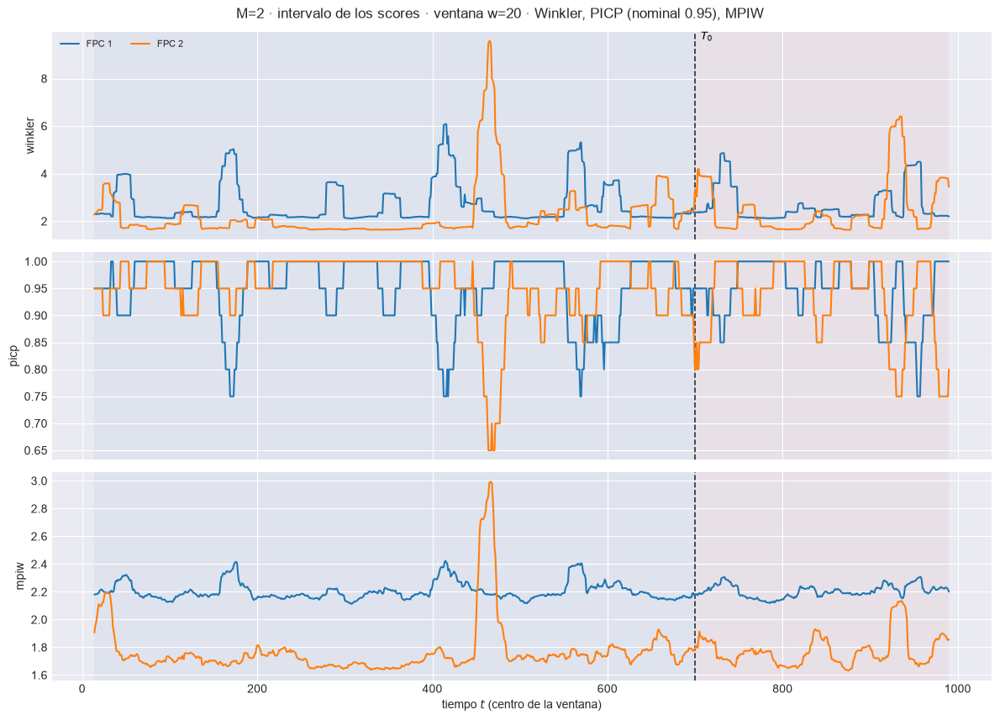

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=2.182  w=30 test=2.298


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=2.148  w=30 test=2.058


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m02\93_ventana_scores_intervalo_w30.png


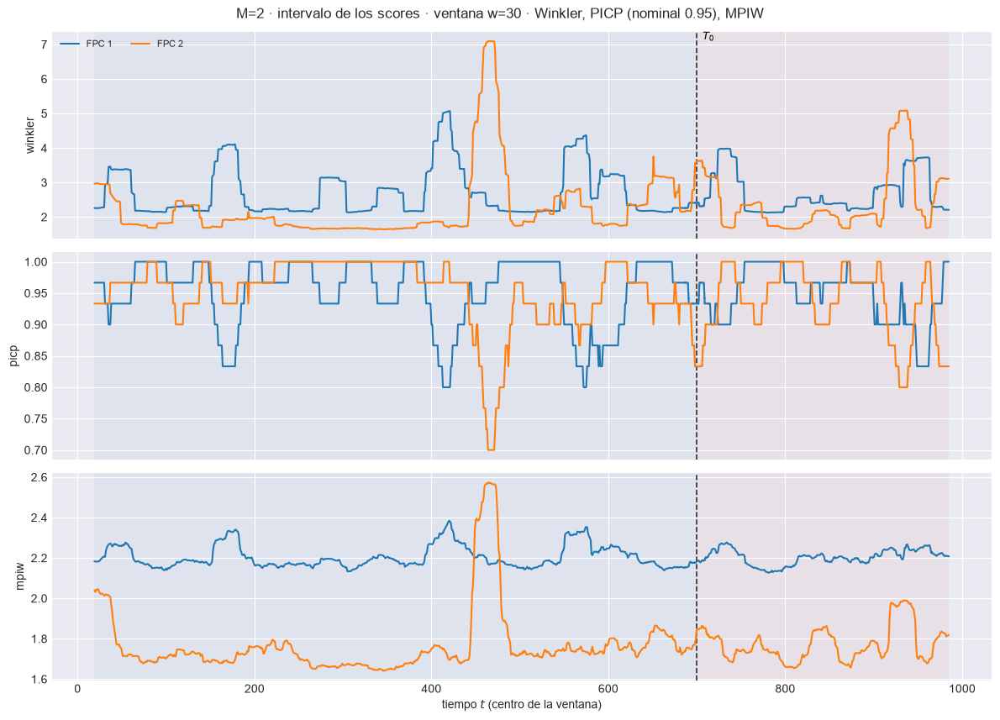

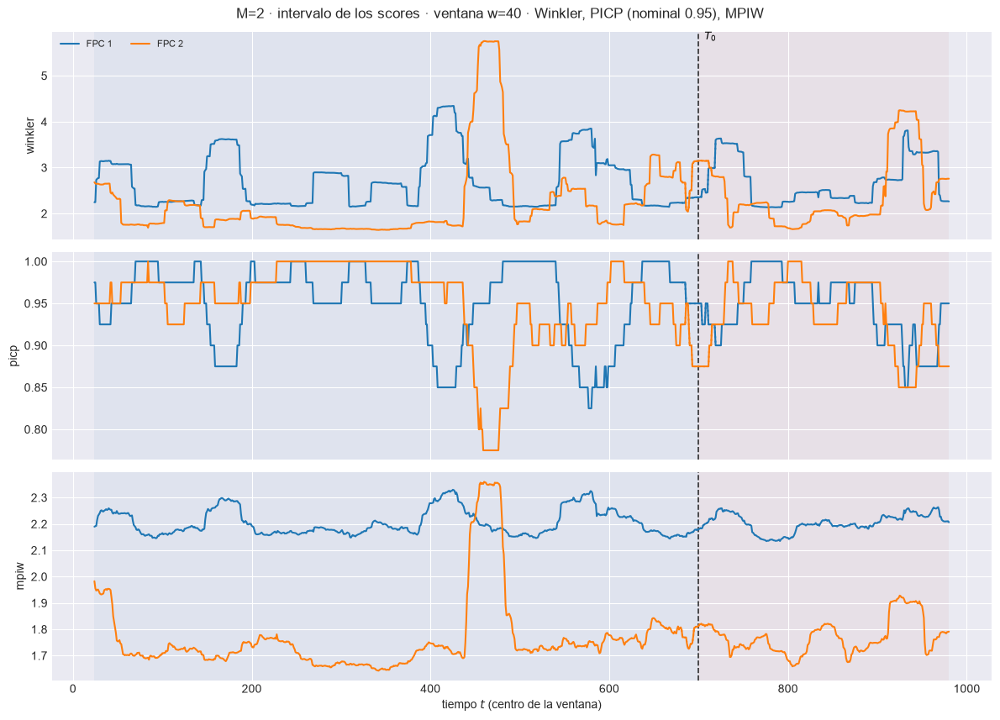

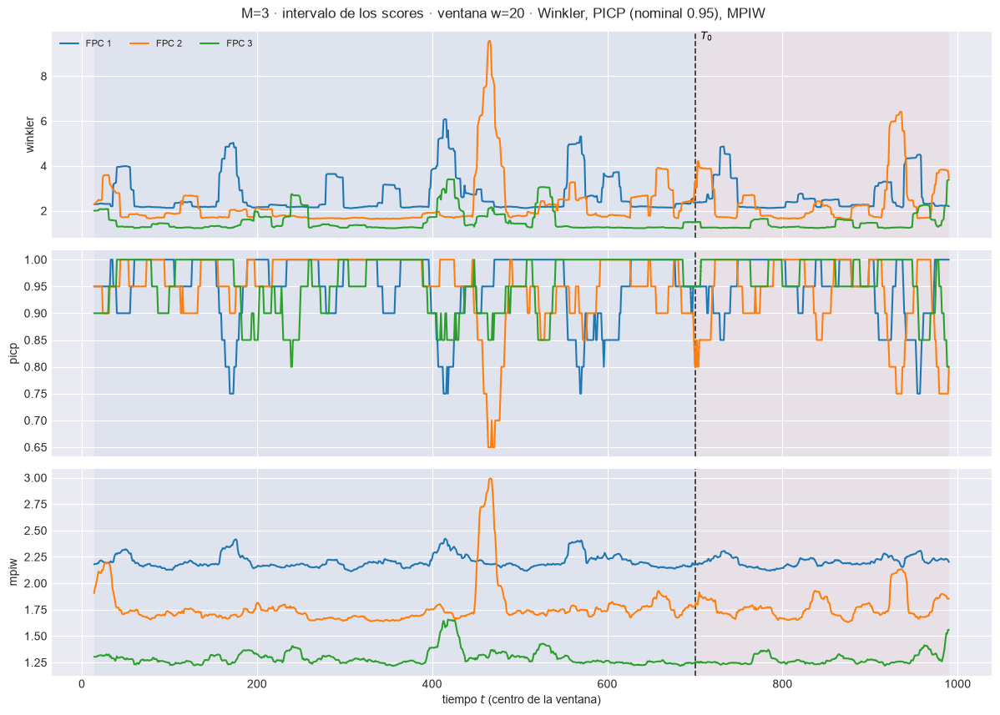

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.976  w=30 test=2.085


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.726  w=30 test=1.745


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m03\93_ventana_scores_intervalo_w30.png


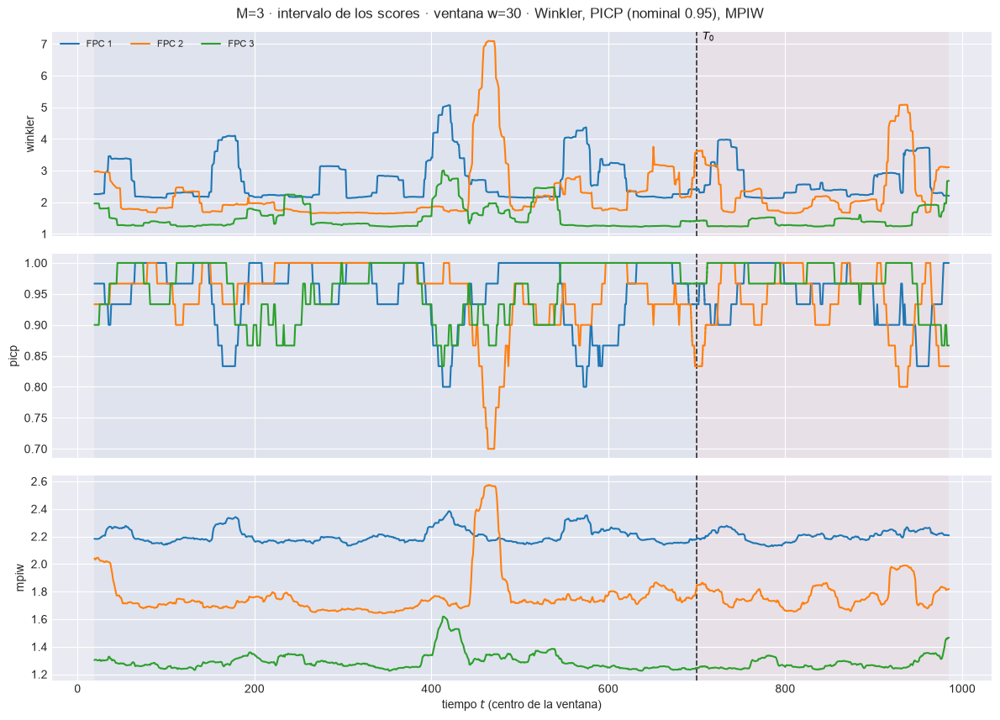

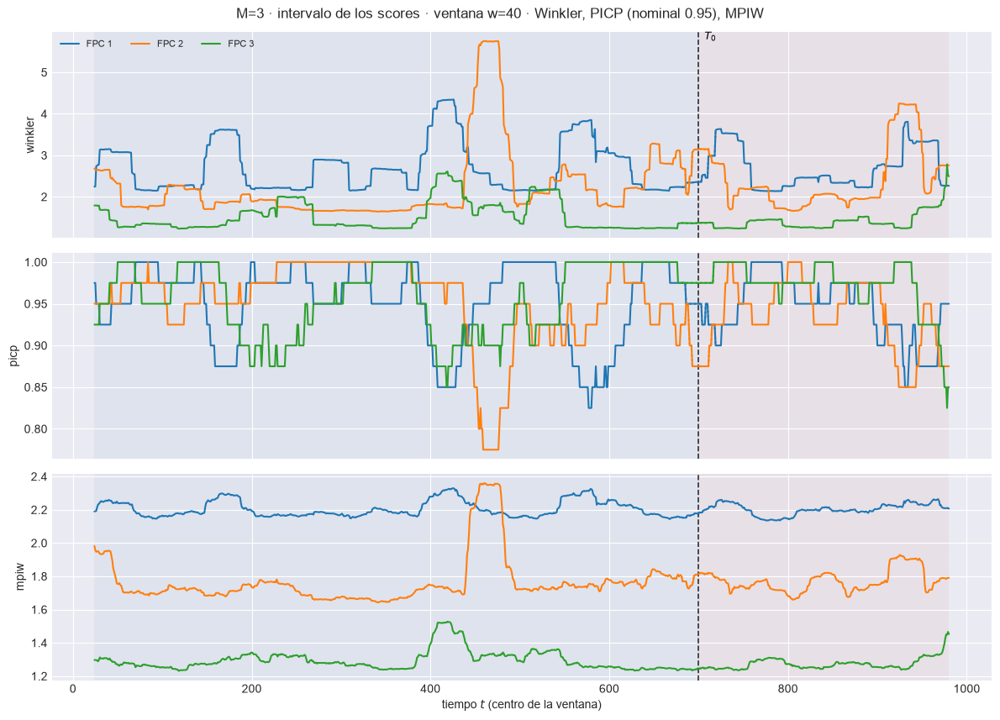

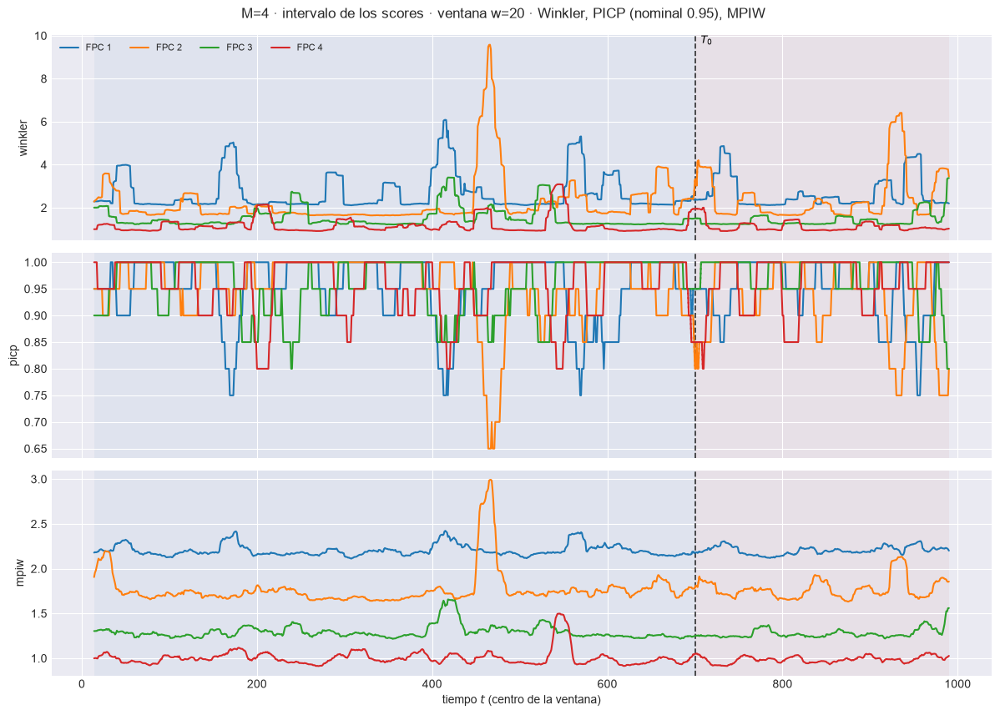

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.744  w=30 test=1.685


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.63  w=30 test=1.56


[plot_ventana_movil] listo: 3 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m04\93_ventana_scores_intervalo_w30.png


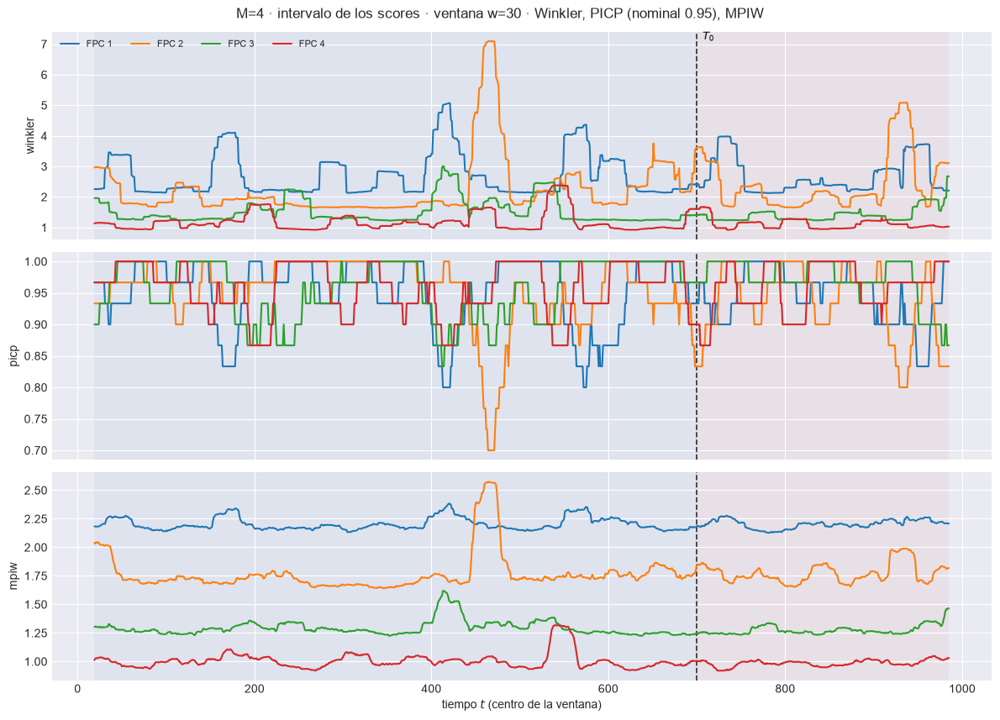

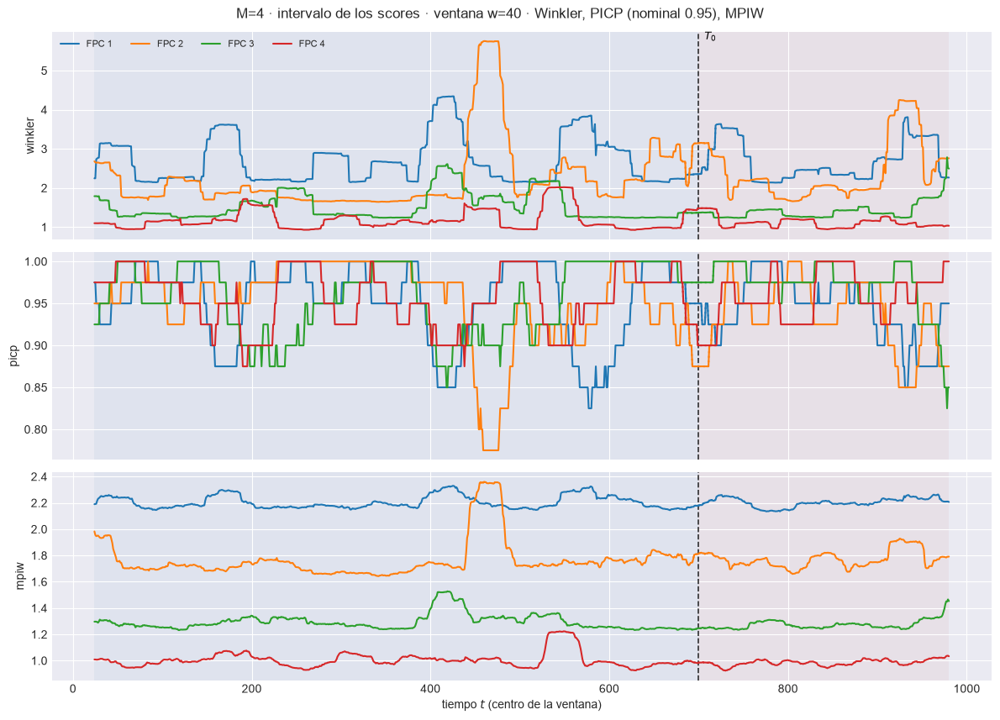

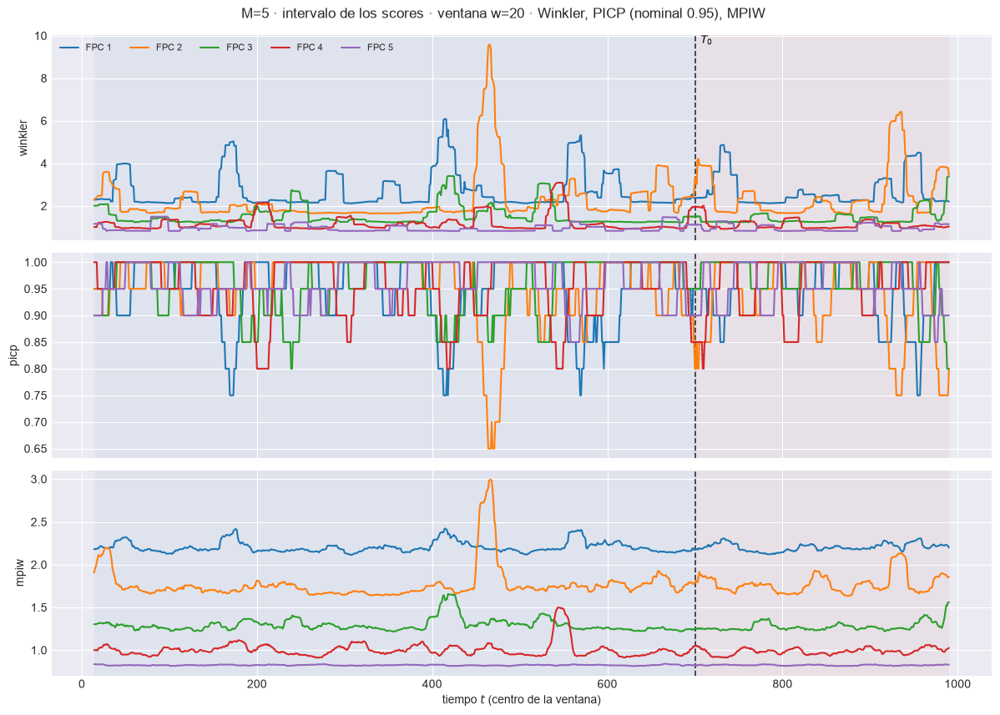

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=1.475  w=30 test=1.315


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.281  w=30 test=1.262


[plot_ventana_movil] listo: 3 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m05\93_ventana_scores_intervalo_w30.png


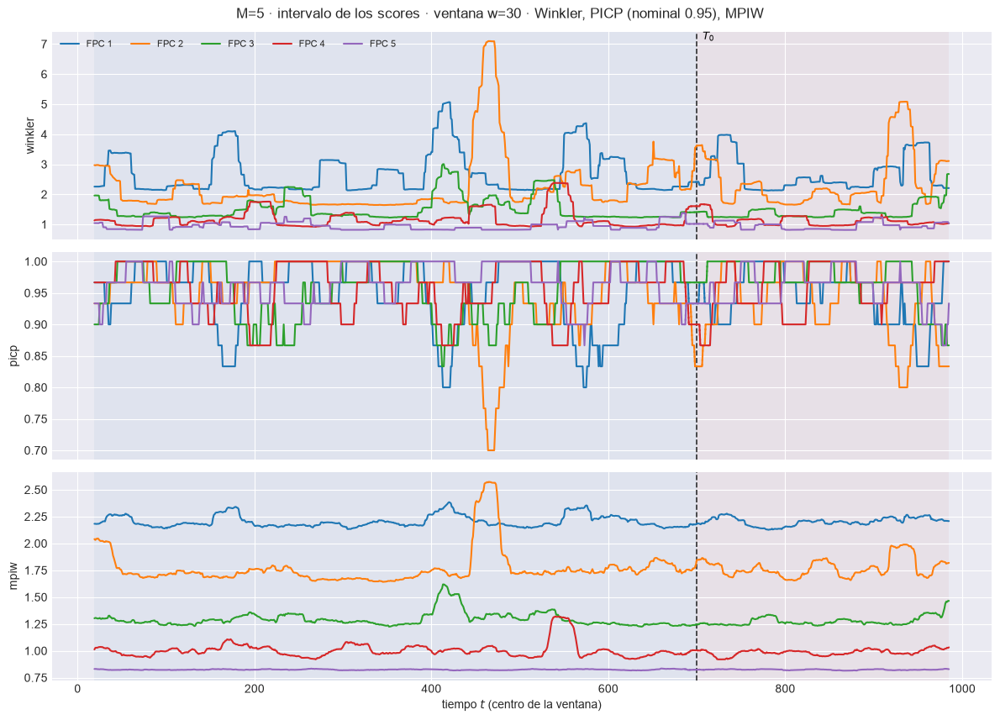

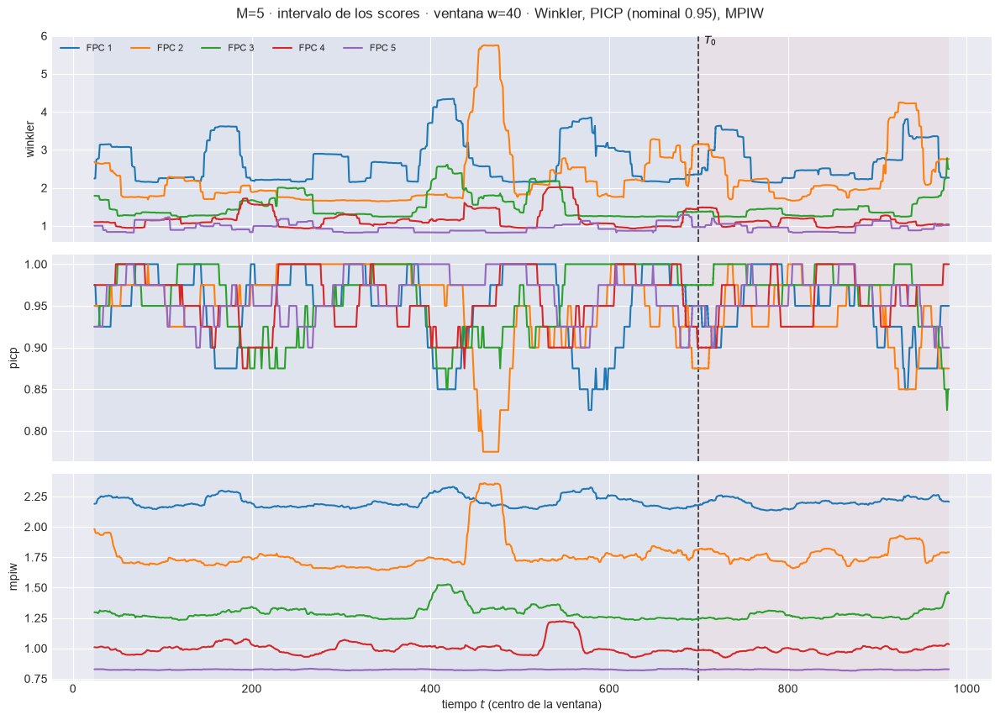

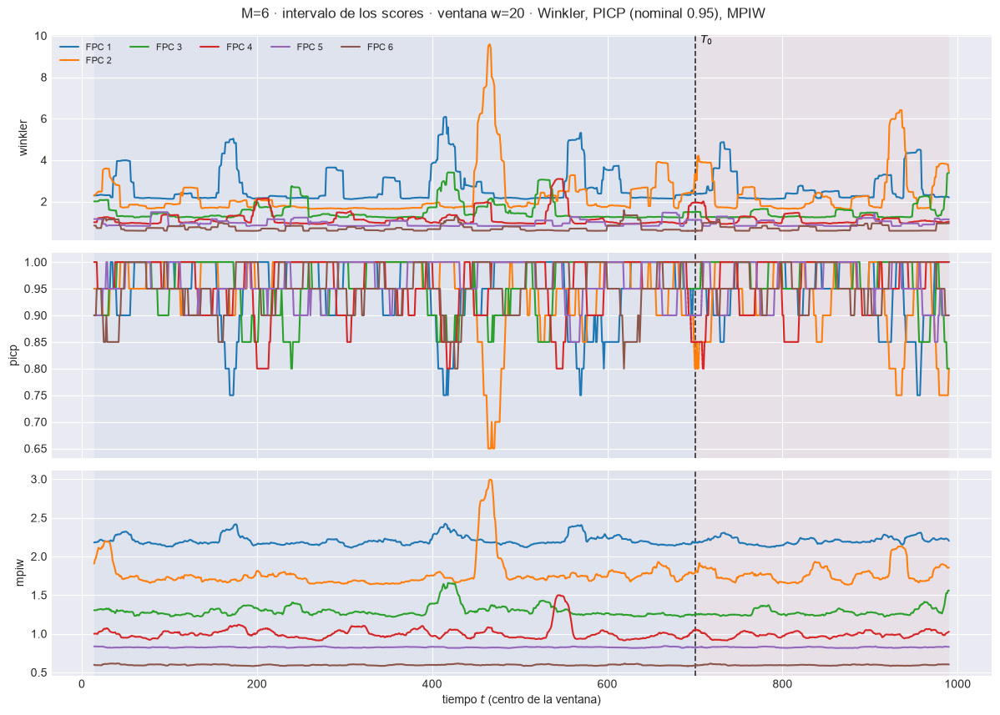

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=1.257  w=30 test=1.242


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.234  w=30 test=1.142


[plot_ventana_movil] listo: 3 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m06\93_ventana_scores_intervalo_w30.png


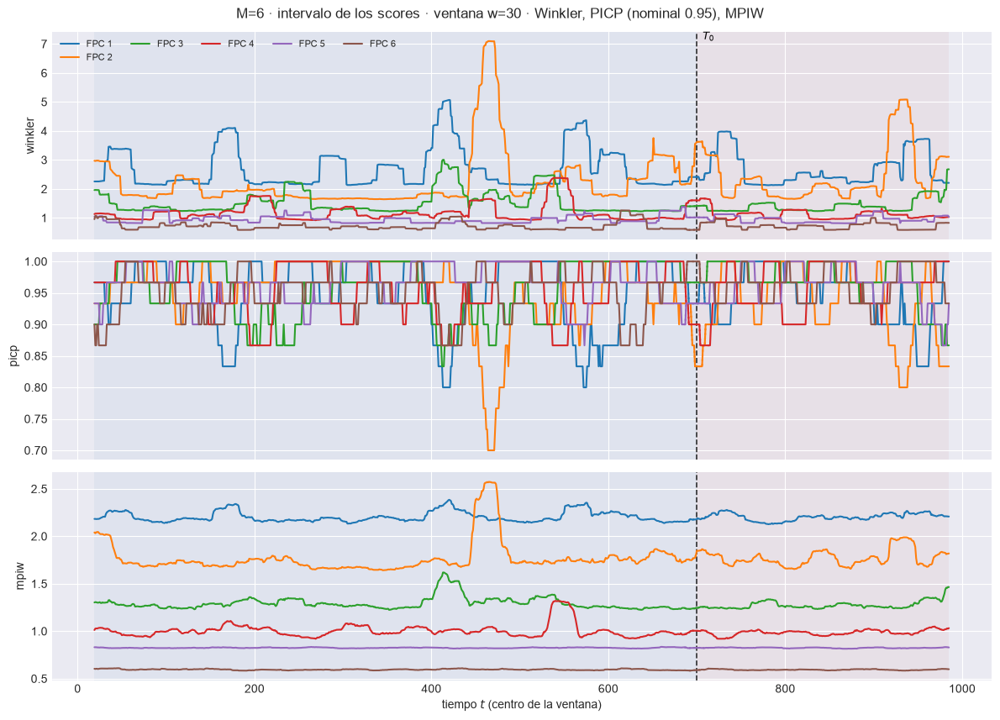

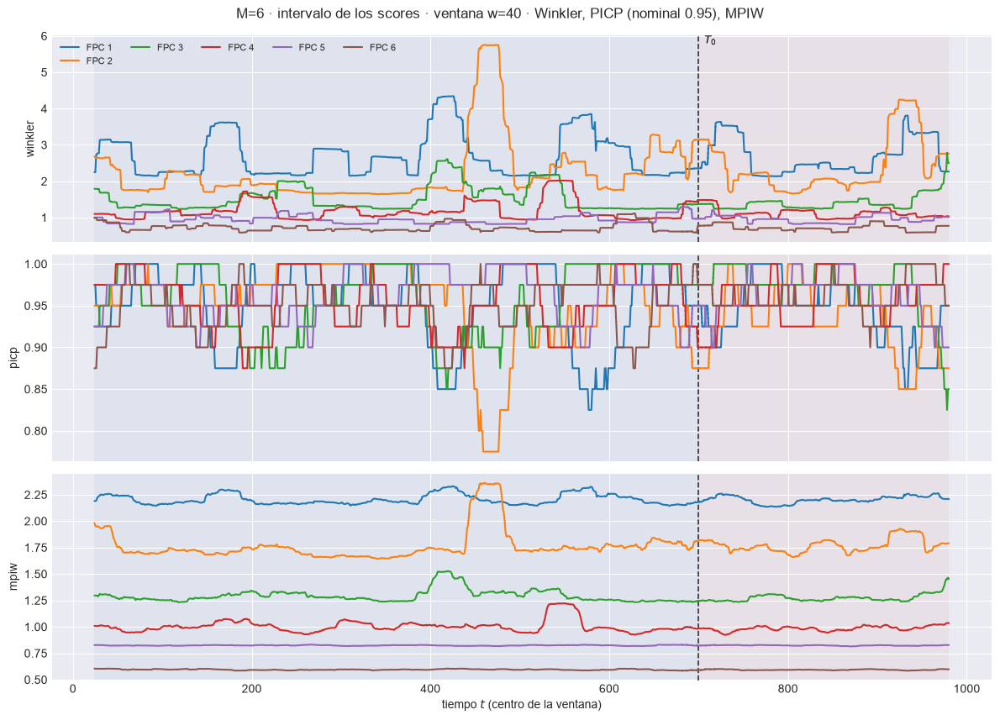

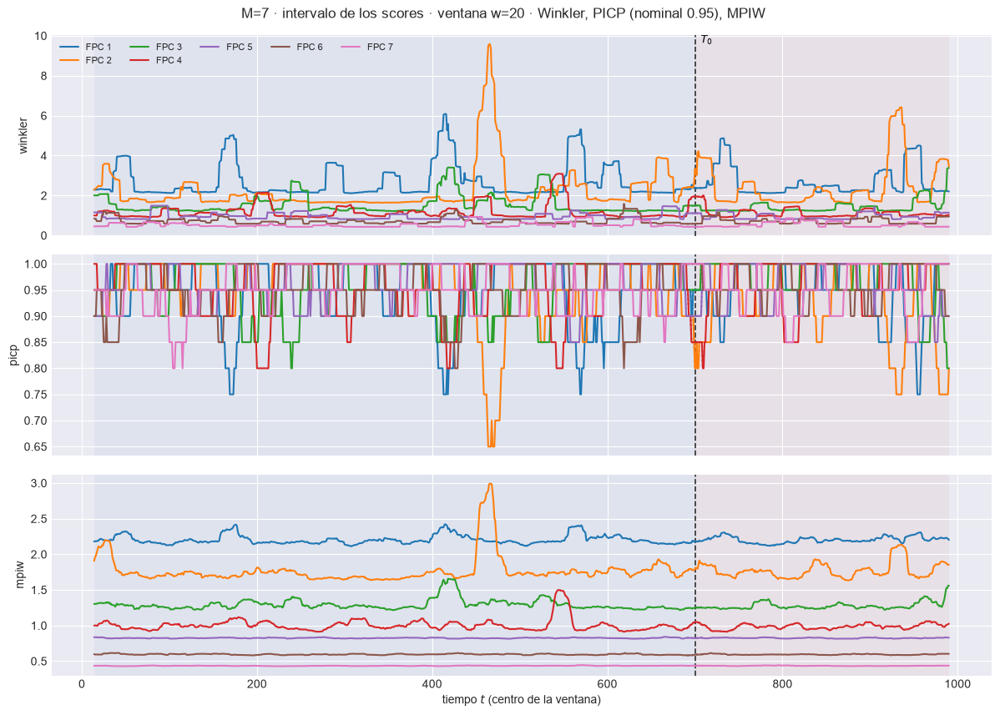

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=1.147  w=30 test=1.11


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.9941  w=30 test=0.9844


[plot_ventana_movil] listo: 3 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m07\93_ventana_scores_intervalo_w30.png


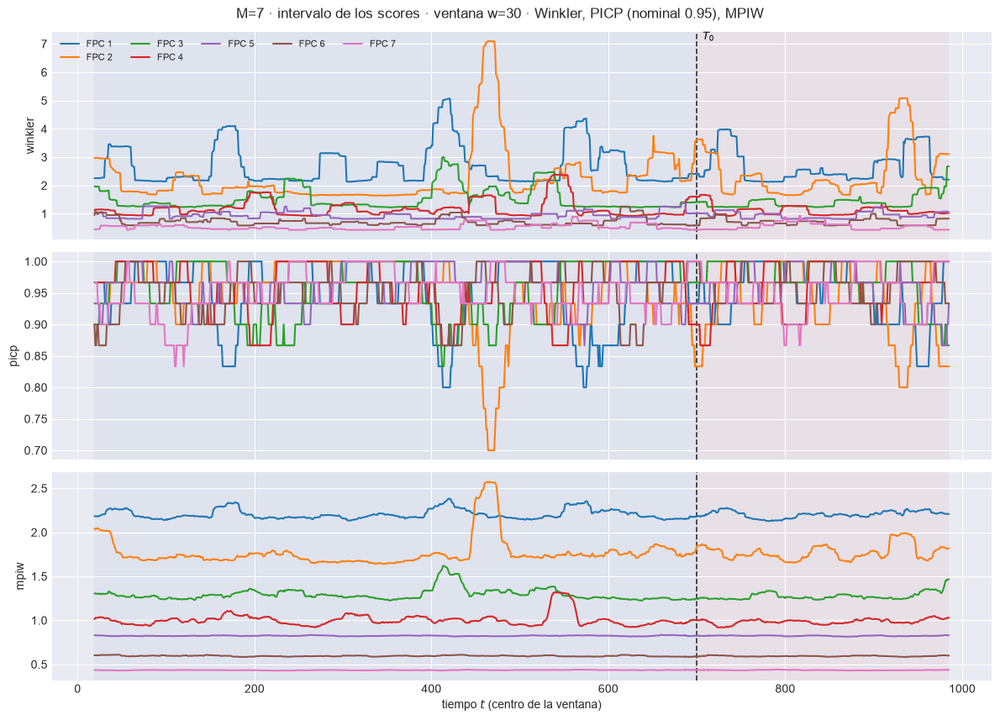

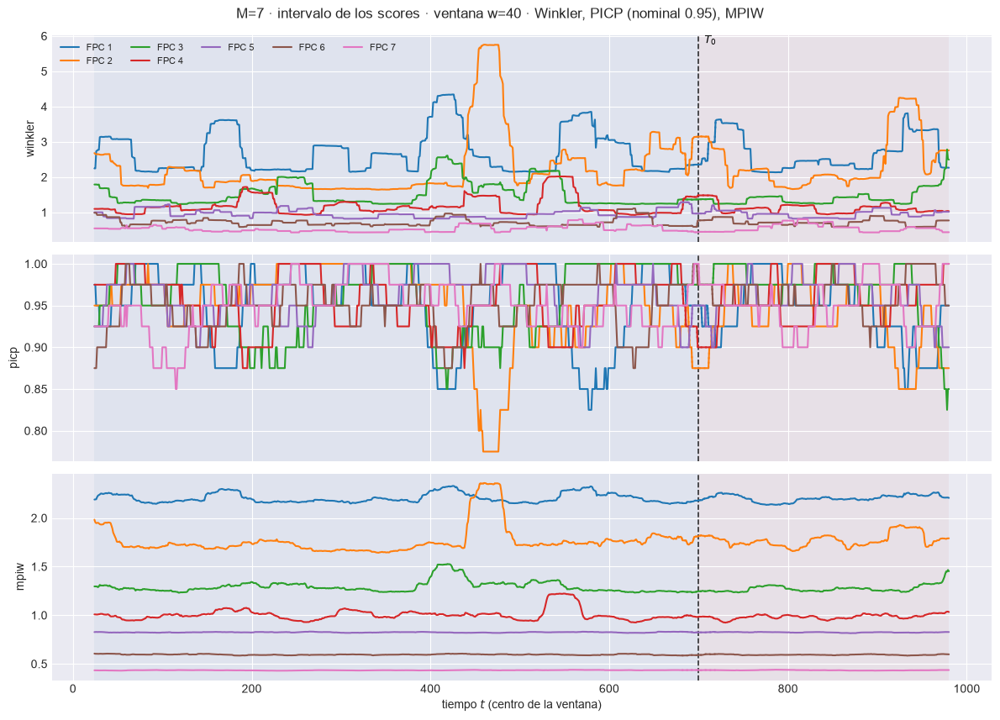

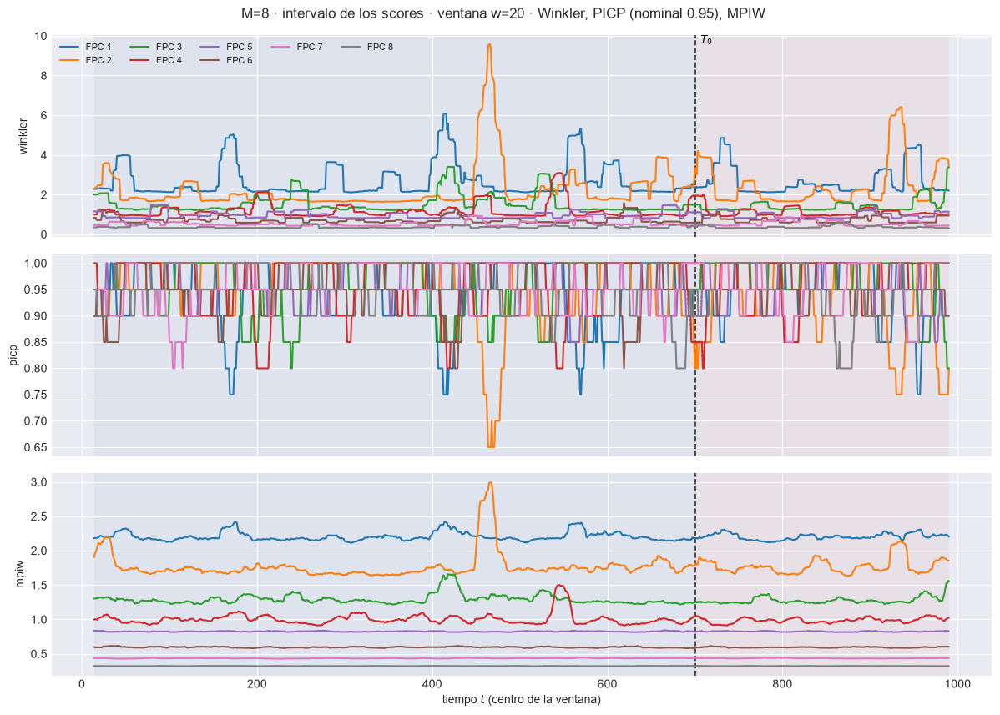

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.9975  w=30 test=1.001


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.8775  w=30 test=0.876


[plot_ventana_movil] listo: 3 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m08\93_ventana_scores_intervalo_w30.png


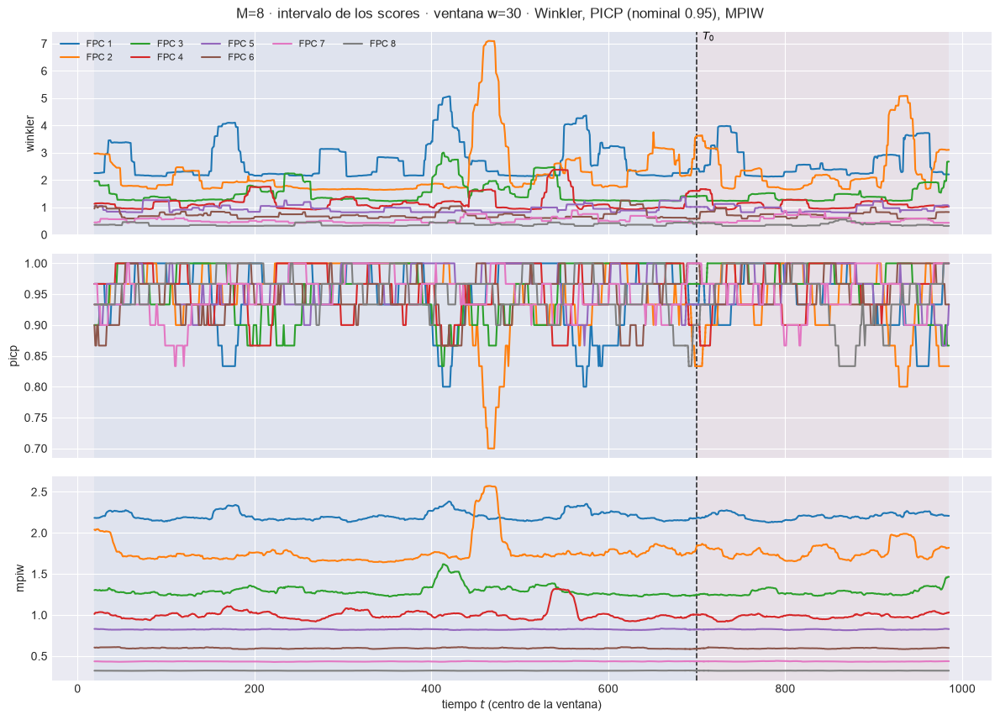

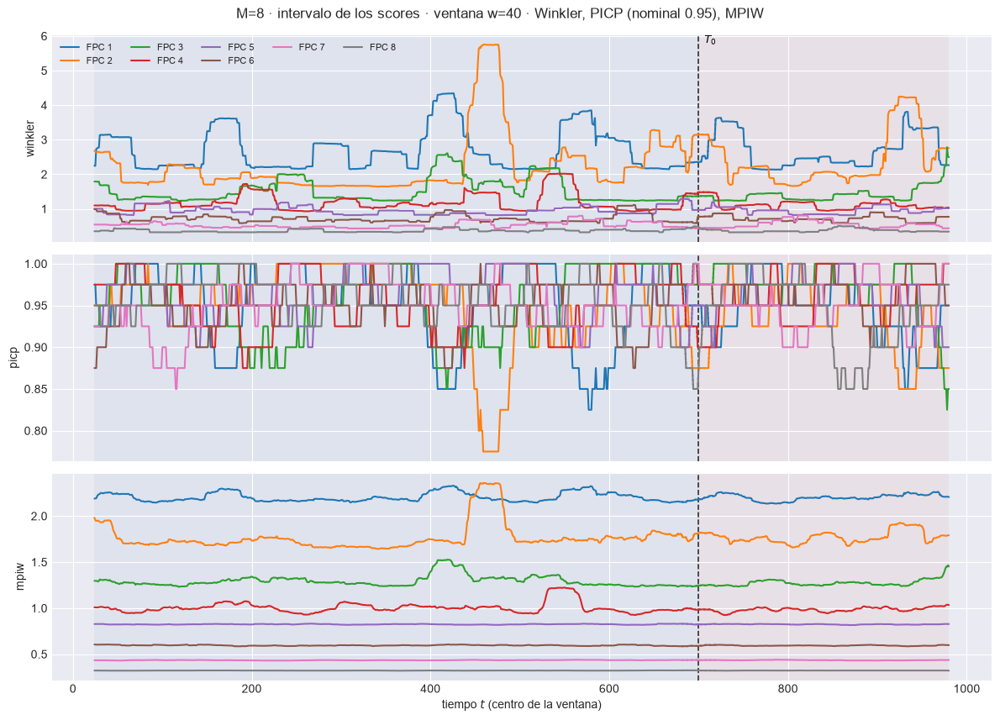

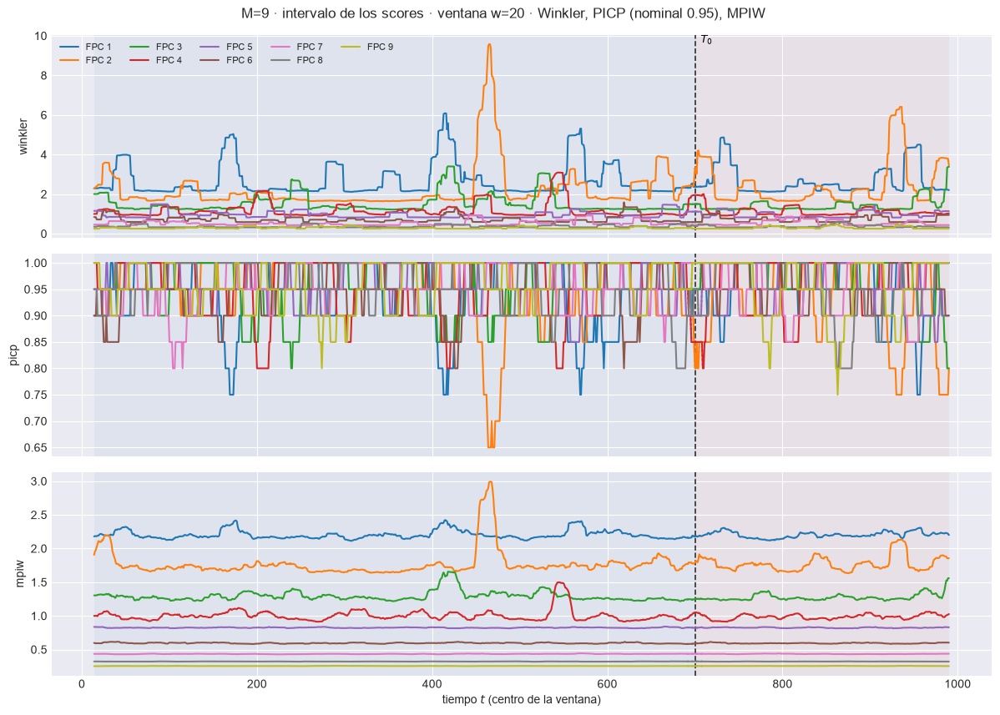

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.9358  w=30 test=0.9483


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.8243  w=30 test=0.8245


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m09\93_ventana_scores_intervalo_w30.png


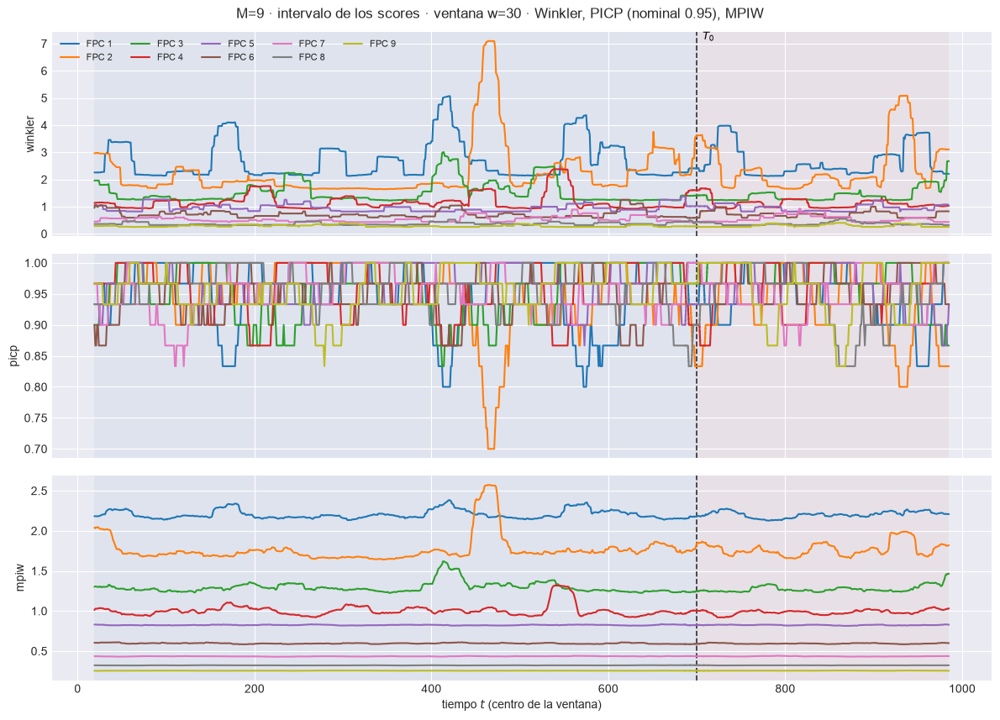

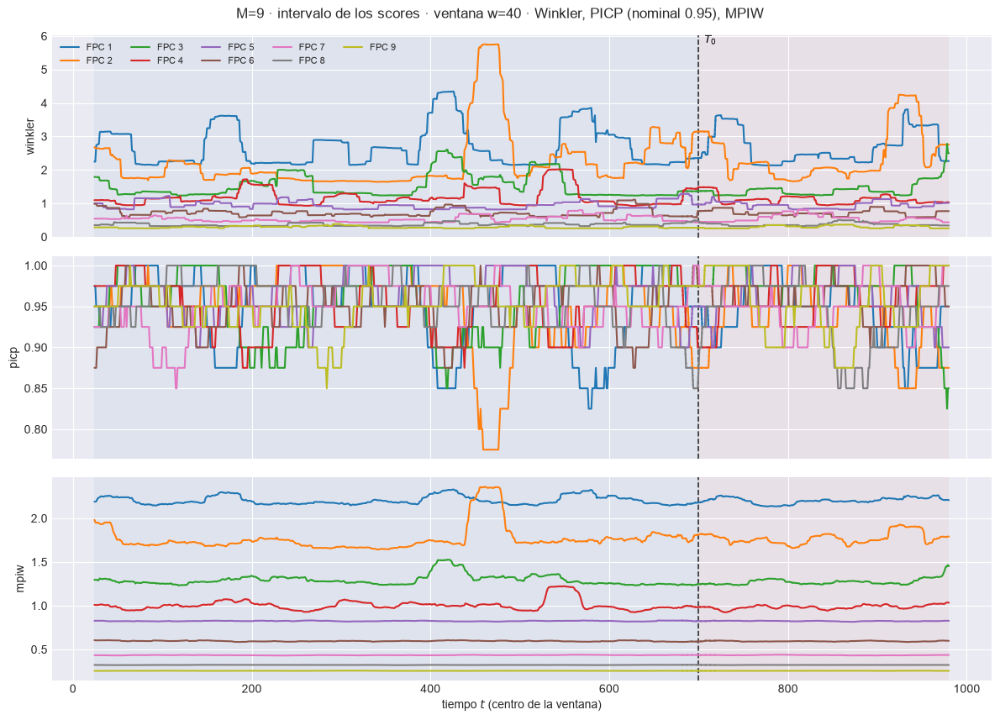

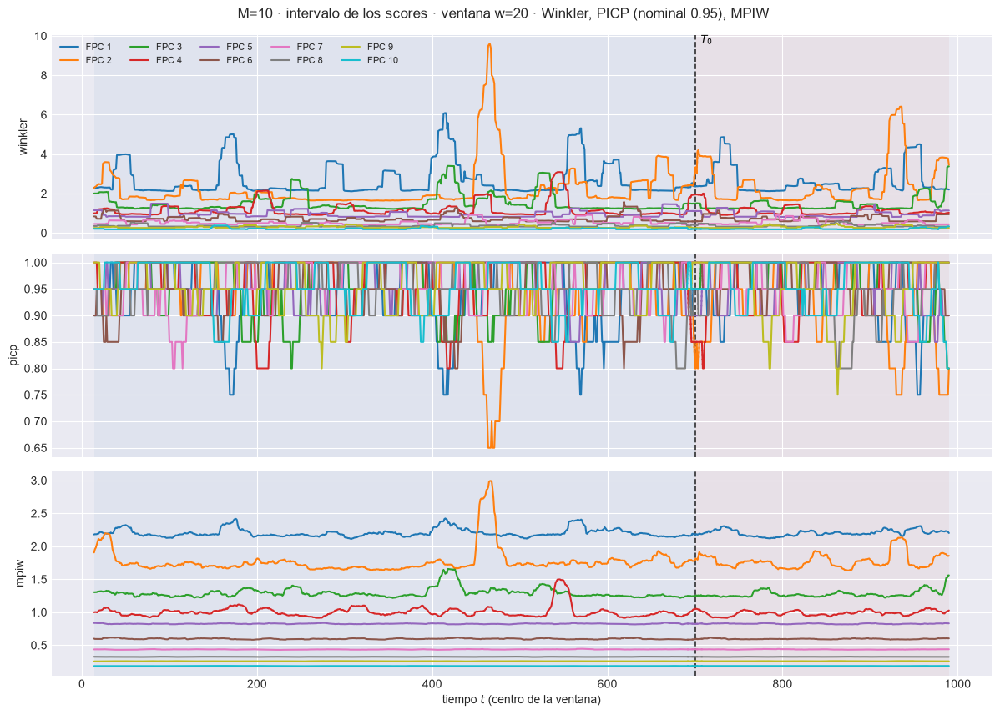

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.8248  w=30 test=0.823


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.7134  w=30 test=0.7102


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_301_chungEscG_1_r01_m10\93_ventana_scores_intervalo_w30.png


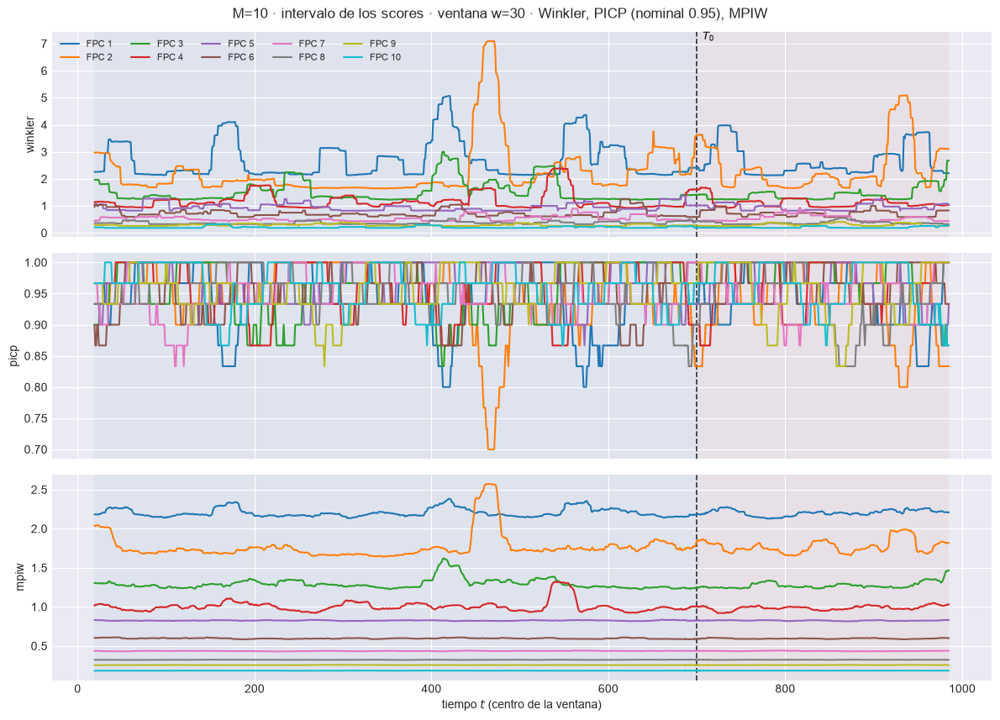

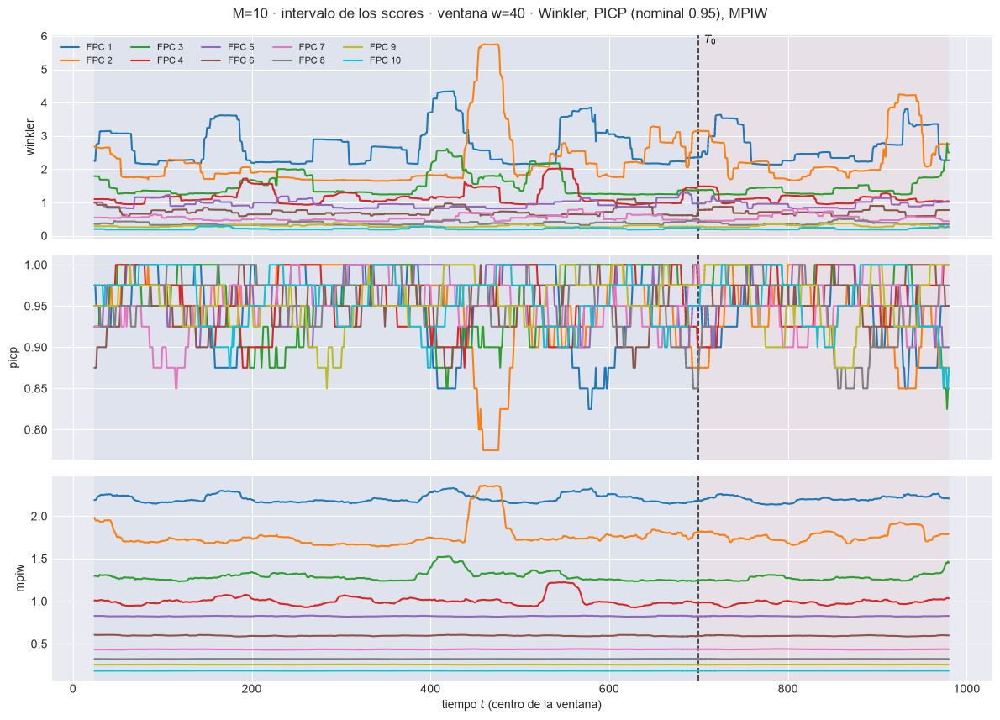

In [24]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente con la diagonal; train y test con marcador distinto.

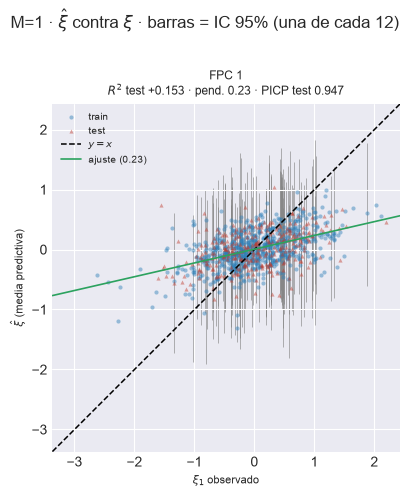

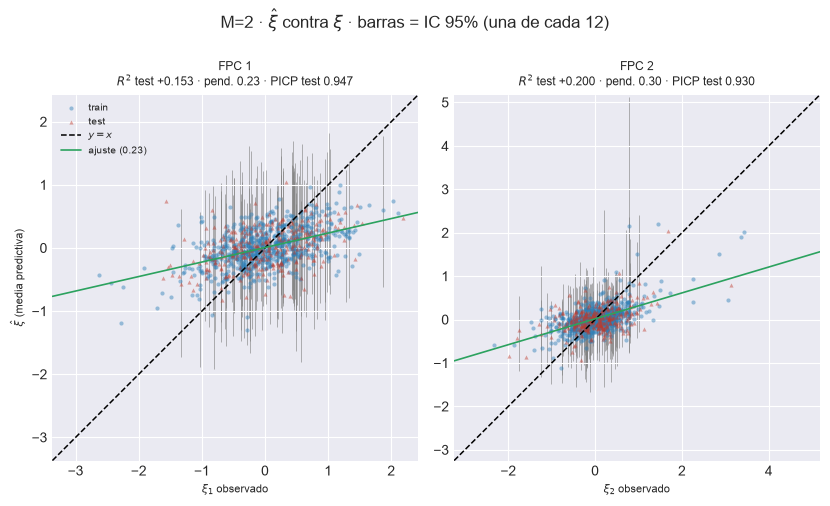

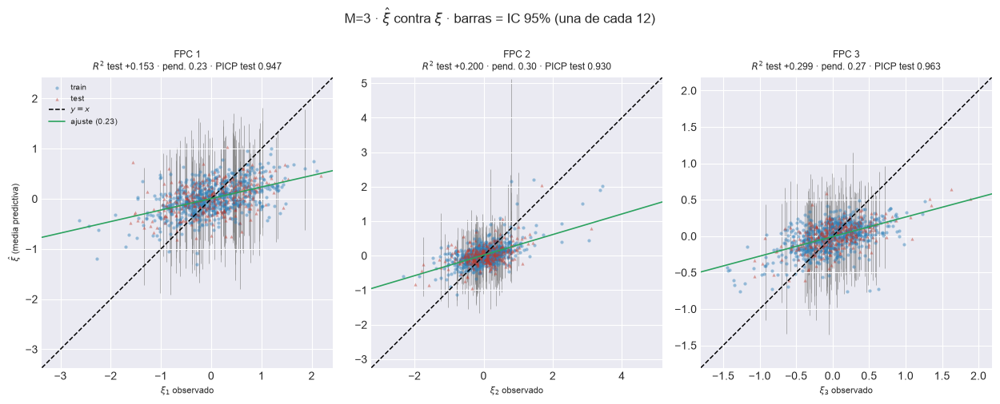

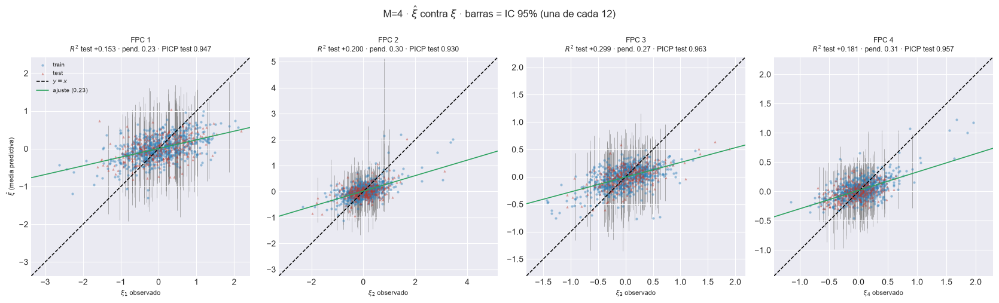

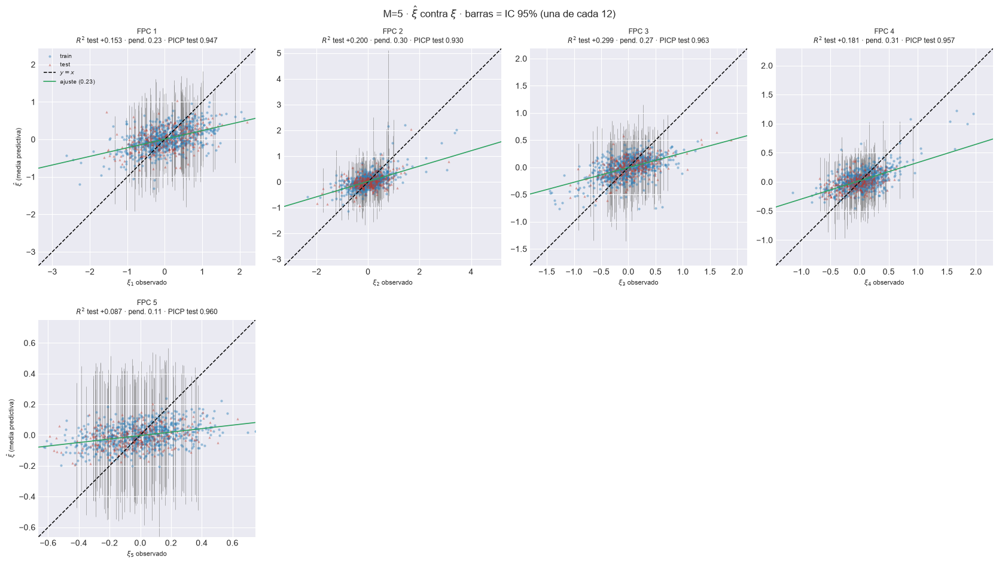

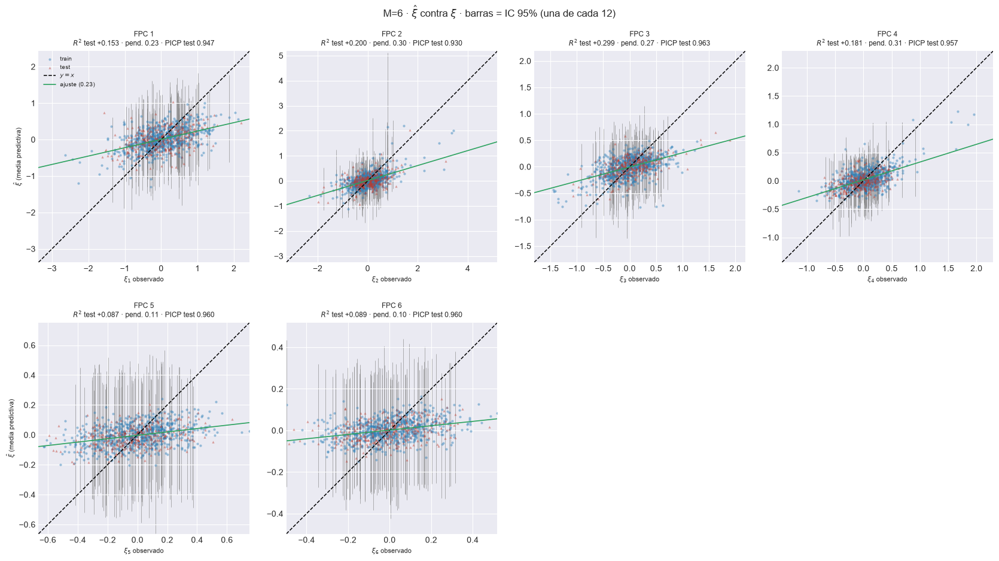

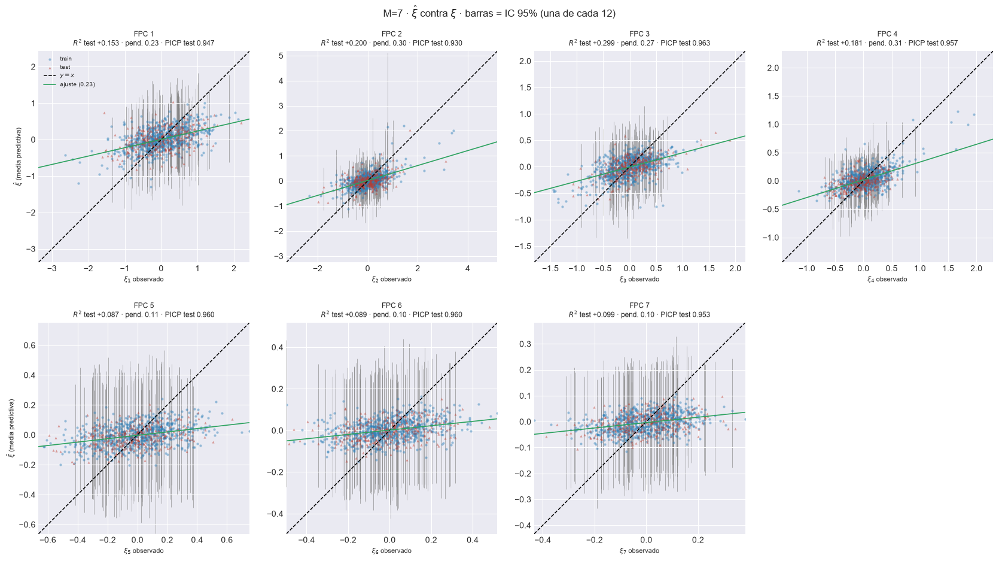

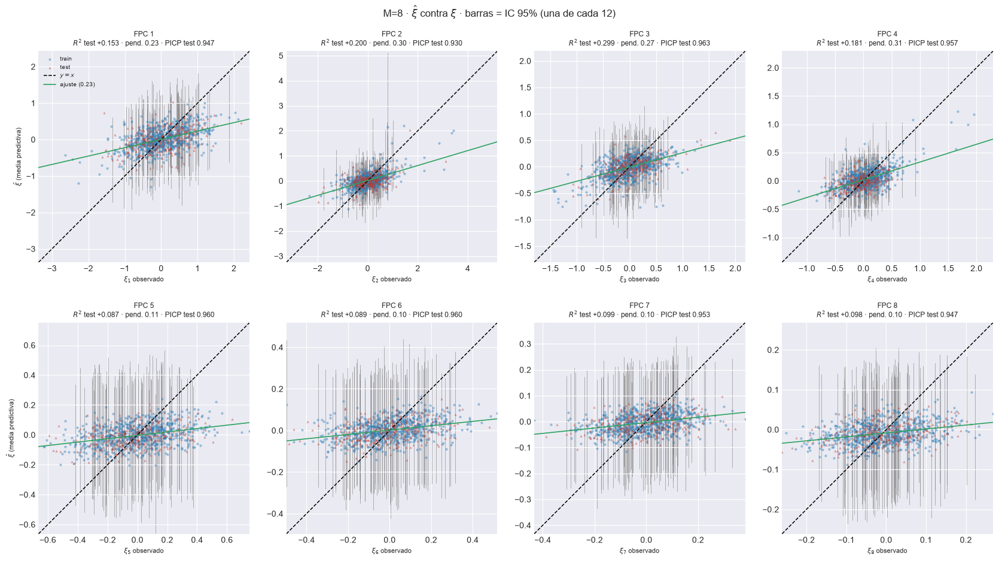

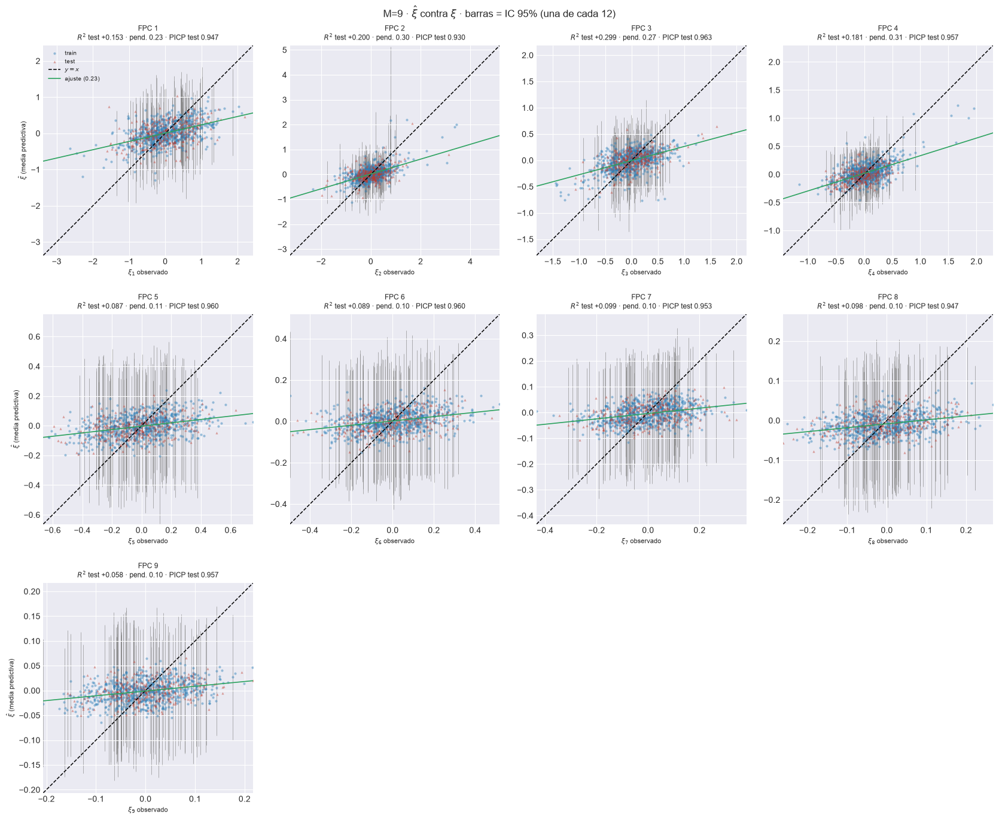

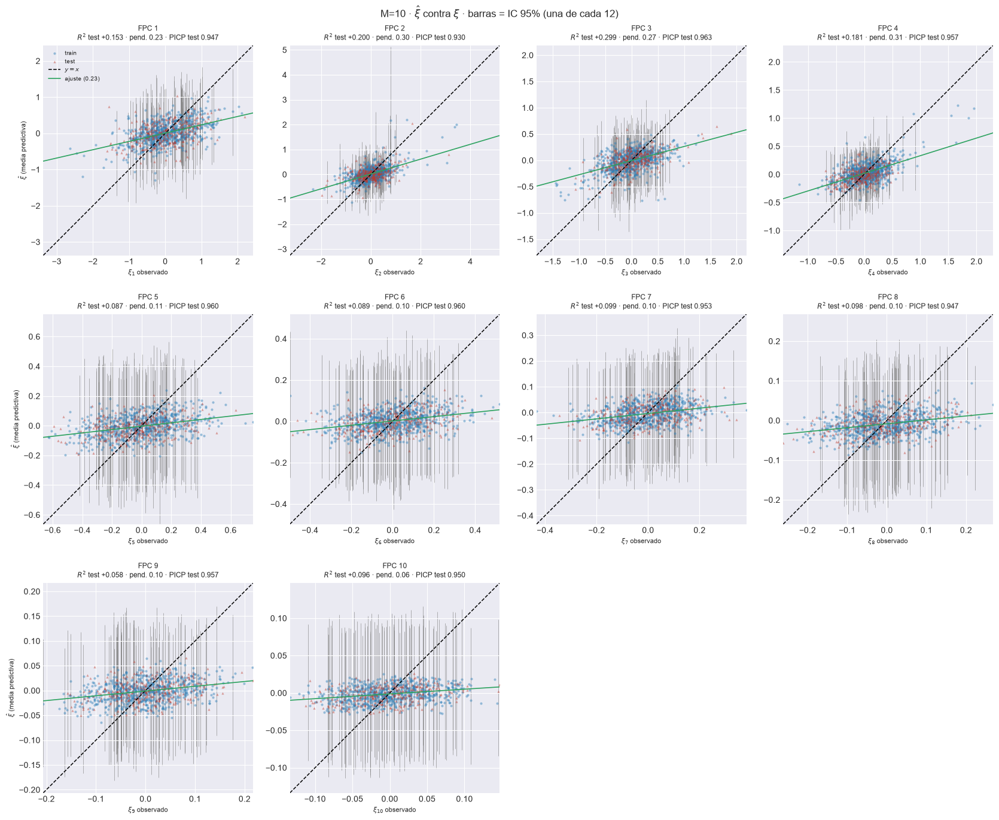

In [25]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()

## 11. Diagnóstico de multimodalidad

En la ventana de detalle, como cuentas: por score, orígenes con $|\hat E - \mathrm{mediana}| > 0.25\,\hat s$; por origen, distancia de la mediana puntual a la extracción más cercana contra la de vecinas. En la 301 es una verificación: la brecha debe ser pequeña.

In [26]:
# ORIG_DET: el bloque "test" de diagnostico_multimodalidad es la ventana; se reetiqueta "detalle".
MULTI = {M: diagnostico_multimodalidad(EST[M], DIS, ORIG_DET, UMBRAL_SEP, N_REF_NN, SEED_PRED, PESOS_TAU)
         for M in M_OK}
for M in M_OK:
    ps = MULTI[M][0]
    ps = ps[ps.bloque == "test"].assign(bloque="detalle", n_origenes=N_DETALLE)
    ps.to_csv(EST[M]["paths"]["out_report"] / "60_multimodalidad_por_score.csv", index=False)
    MULTI[M] = (ps, MULTI[M][1])
multi_bar = pd.concat([MULTI[M][0].assign(M=M) for M in M_OK], ignore_index=True)
multi_bar.to_csv(PATH_BARRIDO / "100_multimodalidad_por_M.csv", index=False)
_FPC = [f"FPC {k}" for k in range(1, max(M_OK) + 1)]
display((multi_bar.pivot(index="componente", columns="M", values=f"frac_sep_gt_{UMBRAL_SEP}") * N_DETALLE)
        .round().reindex(_FPC).style.format("{:.0f}", na_rep="-").background_gradient(cmap="Reds", axis=None)
        .set_caption(f"Ventana de detalle · orígenes (de {N_DETALLE}) con |esperanza − mediana| > {UMBRAL_SEP} sd robusta"))
for col, txt in (("sep_mediana", "mediana"), ("sep_p90", "percentil 90")):
    display(multi_bar.pivot(index="componente", columns="M", values=col).reindex(_FPC)
            .style.format("{:.3f}", na_rep="-").background_gradient(cmap="Reds", vmin=0, vmax=UMBRAL_SEP, axis=None)
            .set_caption(f"Ventana de detalle · brecha |esperanza − mediana| / sd robusta por score: {txt} sobre los {N_DETALLE} orígenes"))
nn = pd.DataFrame({M: MULTI[M][1].set_index("t")["razon"] for M in M_OK})
display(nn.style.format("{:.3f}")
        .set_caption("Ventana de detalle · razón d(mediana puntual, extracción más cercana) / d típica, por origen"))

M,1,2,3,4,5,6,7,8,9,10
componente,,,,,,,,,,
FPC 1,0,0,0,0,0,0,0,0,0,0
FPC 2,-,1,1,1,1,1,1,1,1,1
FPC 3,-,-,0,0,0,0,0,0,0,0
FPC 4,-,-,-,0,0,0,0,0,0,0
FPC 5,-,-,-,-,0,0,0,0,0,0
FPC 6,-,-,-,-,-,0,0,0,0,0
FPC 7,-,-,-,-,-,-,0,0,0,0
FPC 8,-,-,-,-,-,-,-,0,0,0
FPC 9,-,-,-,-,-,-,-,-,0,0


M,1,2,3,4,5,6,7,8,9,10
componente,,,,,,,,,,
FPC 1,0.011,0.011,0.011,0.011,0.011,0.011,0.011,0.011,0.011,0.011
FPC 2,-,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048
FPC 3,-,-,0.015,0.015,0.015,0.015,0.015,0.015,0.015,0.015
FPC 4,-,-,-,0.013,0.013,0.013,0.013,0.013,0.013,0.013
FPC 5,-,-,-,-,0.010,0.010,0.010,0.010,0.010,0.010
FPC 6,-,-,-,-,-,0.008,0.008,0.008,0.008,0.008
FPC 7,-,-,-,-,-,-,0.017,0.017,0.017,0.017
FPC 8,-,-,-,-,-,-,-,0.013,0.013,0.013
FPC 9,-,-,-,-,-,-,-,-,0.008,0.008


M,1,2,3,4,5,6,7,8,9,10
componente,,,,,,,,,,
FPC 1,0.023,0.023,0.023,0.023,0.023,0.023,0.023,0.023,0.023,0.023
FPC 2,-,0.215,0.215,0.215,0.215,0.215,0.215,0.215,0.215,0.215
FPC 3,-,-,0.033,0.033,0.033,0.033,0.033,0.033,0.033,0.033
FPC 4,-,-,-,0.033,0.033,0.033,0.033,0.033,0.033,0.033
FPC 5,-,-,-,-,0.017,0.017,0.017,0.017,0.017,0.017
FPC 6,-,-,-,-,-,0.022,0.022,0.022,0.022,0.022
FPC 7,-,-,-,-,-,-,0.040,0.040,0.040,0.040
FPC 8,-,-,-,-,-,-,-,0.036,0.036,0.036
FPC 9,-,-,-,-,-,-,-,-,0.017,0.017


,1,2,3,4,5,6,7,8,9,10
t,,,,,,,,,,
931,1.075,0.935,0.618,0.851,0.710,0.552,0.520,0.531,0.669,0.651
932,0.841,0.907,0.738,0.548,0.413,0.375,0.460,0.565,0.553,0.540
933,0.715,2.568,1.253,0.919,0.922,0.937,0.992,0.961,0.919,0.894
934,0.268,0.825,0.876,0.944,0.856,0.802,0.788,0.702,0.697,0.676
935,1.416,0.678,0.413,0.297,0.492,0.651,0.648,0.681,0.678,0.653
936,0.568,0.622,0.794,0.818,0.666,0.617,0.588,0.650,0.661,0.633
937,1.417,0.487,0.691,0.786,0.685,0.733,0.700,0.690,0.680,0.667
938,0.292,0.668,0.885,0.678,0.645,0.640,0.576,0.538,0.603,0.633
939,0.553,1.966,0.847,0.752,0.904,0.907,0.835,0.790,0.766,0.760


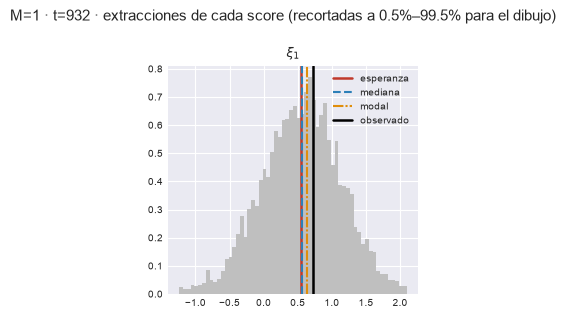

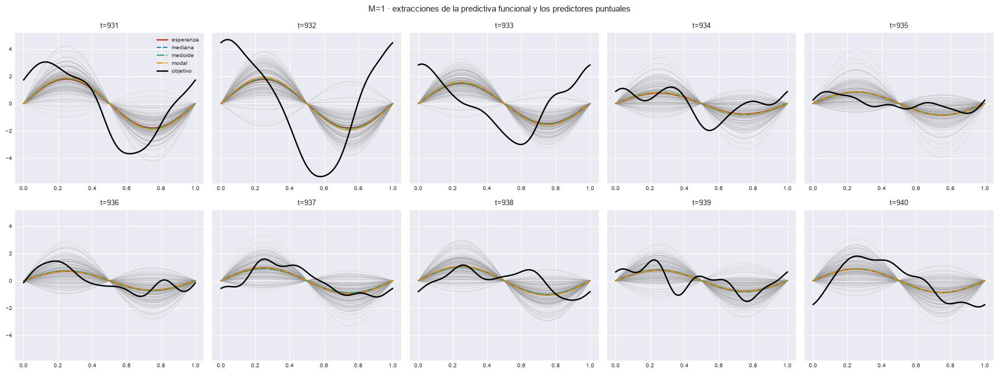

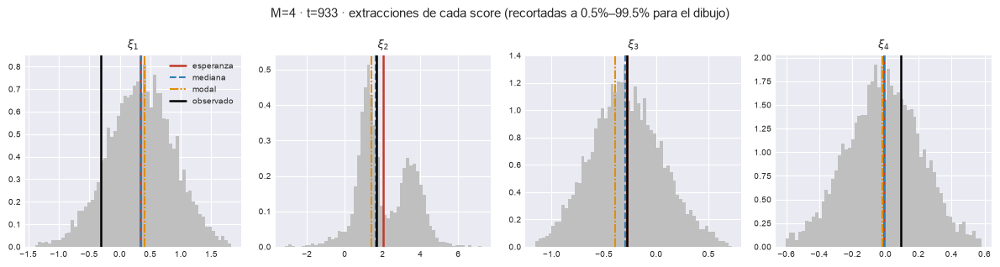

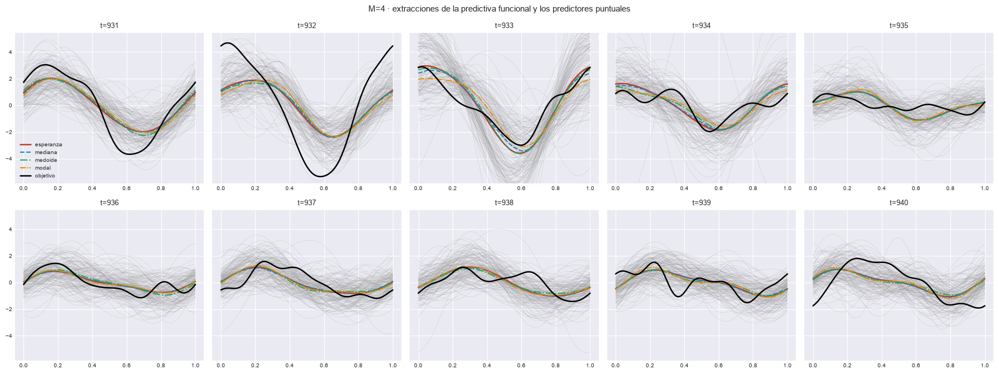

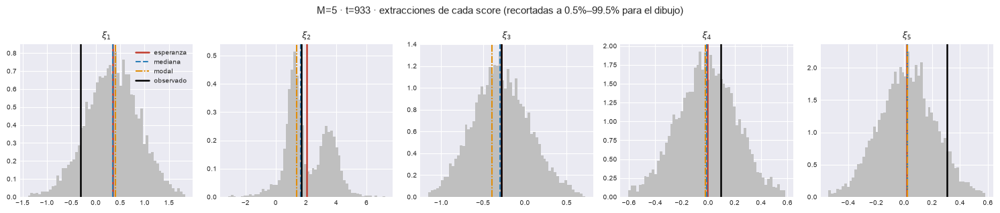

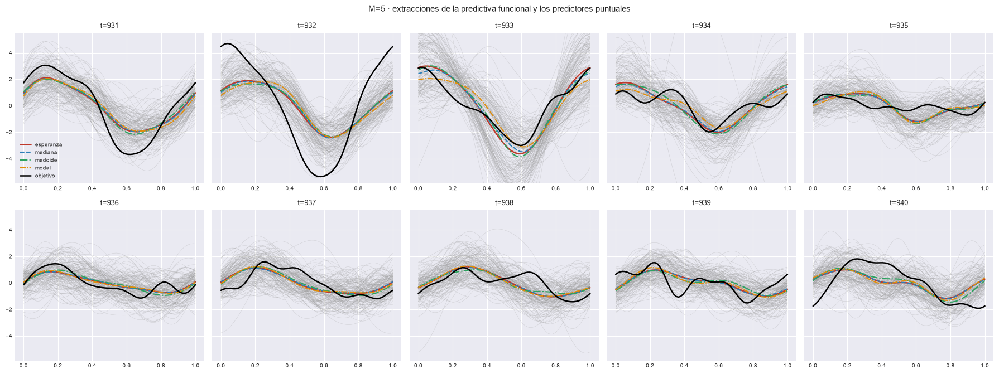

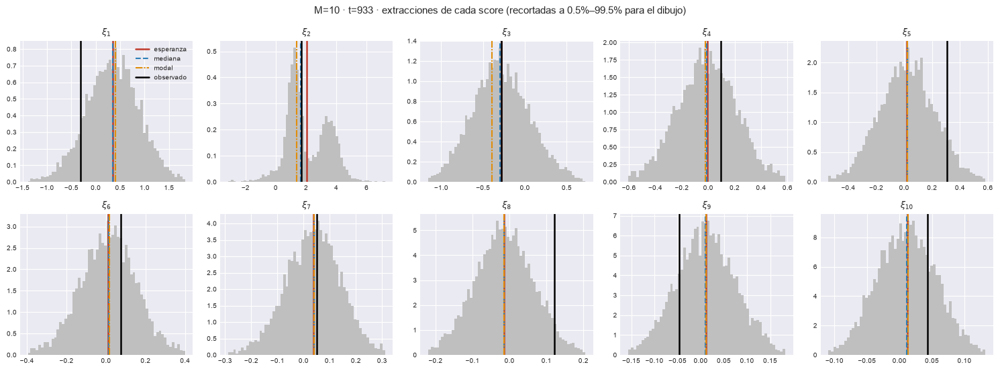

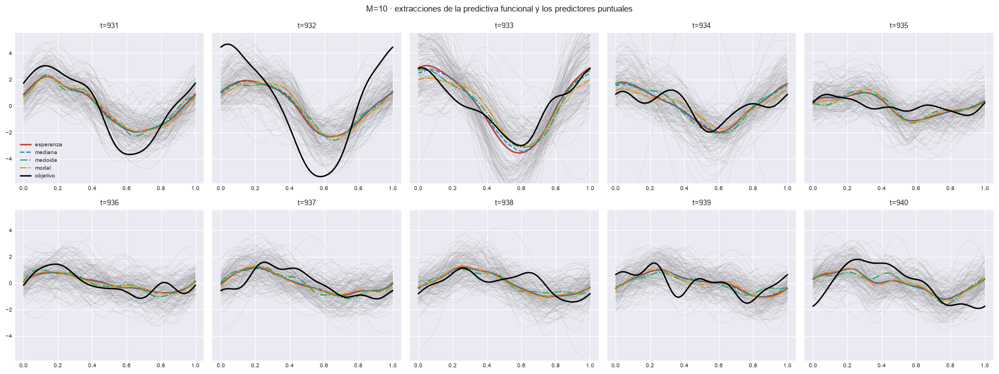

In [27]:
# Ventana de detalle: extracciones por score del origen más separado y curvas con los predictores.
for M in (m for m in M_DETALLE if m in M_OK):
    e, po = EST[M], MULTI[M][1]
    t_sep = int(po.loc[po["sep_max_score"].idxmax(), "t"])
    i_sep = int(np.searchsorted(t_orig, t_sep))
    marcas = {"esperanza": e["Y_hat"], "mediana": np.median(e["SC_draws"], axis=0),
              "modal": e["Y_mod"], "observado": e["Y_obs"]}
    plot_histogramas_draws(e["SC_draws"], i_sep, marcas, t_sep, M,
                           save_path=e["paths"]["out_report"] / f"61_histogramas_draws_t{t_sep}.png")
    plt.show()
    plot_curvas_predictores(curvas_draws(e, DIS, IDX_DET), {p: e["X_PRED"][p][IDX_DET] for p in PREDICTORES},
                            X_obj_ev[IDX_DET], grilla, T_DET, M, ncols=5,
                            save_path=e["paths"]["out_report"] / "61b_curvas_predictores.png")
    plt.show()

## 12. Comportamientos predictivos

k-medias sobre las extracciones de scores por origen; $K$ con las reglas de docs §03_06_02 (valle, crecimiento, masa); con $a_\tau \le 1$ se recortan los draws al 0.5–99.5 %. §12.1 sobre toda la serie; §12.2–§12.5 sobre la ventana de detalle. Se persiste en `comportamientos_psbp.npz`.

### 12.1 Número de comportamientos por origen

    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 1: K en test  K=1: 100.0%   (recorte si, 58 s)


    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 2: K en test  K=1: 99.7%  K=2: 0.3%   (recorte si, 69 s)


    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 3: K en test  K=1: 99.7%  K=2: 0.3%   (recorte si, 67 s)


    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 4: K en test  K=1: 99.7%  K=2: 0.3%   (recorte si, 70 s)


    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 5: K en test  K=1: 99.7%  K=2: 0.3%   (recorte si, 77 s)


    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 6: K en test  K=1: 99.7%  K=2: 0.3%   (recorte si, 87 s)


    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 7: K en test  K=1: 99.7%  K=2: 0.3%   (recorte si, 88 s)


    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 8: K en test  K=1: 99.7%  K=2: 0.3%   (recorte si, 79 s)


    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 9: K en test  K=1: 99.7%  K=2: 0.3%   (recorte si, 82 s)


    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M=10: K en test  K=1: 99.7%  K=2: 0.3%   (recorte si, 81 s)


M,1,2,3,4,5,6,7,8,9,10
K,,,,,,,,,,
1,100.0%,99.4%,99.4%,98.7%,98.7%,98.7%,98.7%,98.7%,98.7%,98.7%
2,0.0%,0.6%,0.6%,1.3%,1.3%,1.3%,1.3%,1.3%,1.3%,1.3%
3,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
4,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
5,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


M,1,2,3,4,5,6,7,8,9,10
K,,,,,,,,,,
1,100.0%,99.7%,99.7%,99.7%,99.7%,99.7%,99.7%,99.7%,99.7%,99.7%
2,0.0%,0.3%,0.3%,0.3%,0.3%,0.3%,0.3%,0.3%,0.3%,0.3%
3,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
4,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
5,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


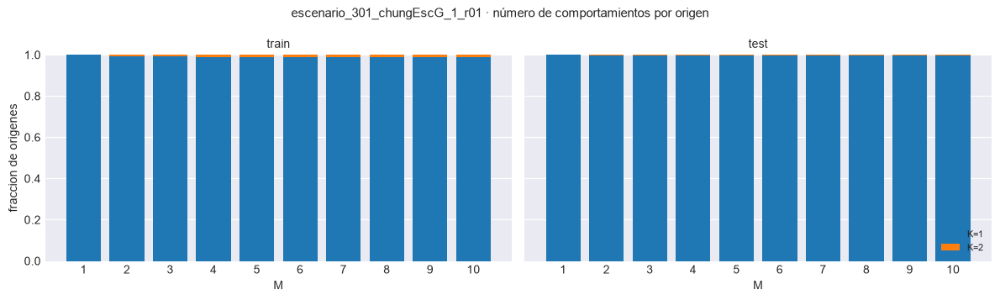

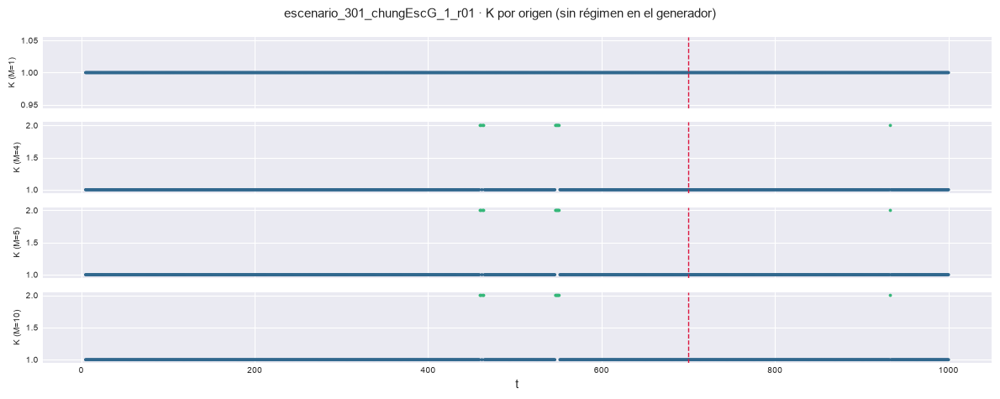

In [28]:
K_BAR = comportamientos_barrido(EST, M_OK, DIS, ORIG, PATH_BARRIDO, solo_test=COMP_SOLO_TEST)
for b in ("train", "test"):
    display(K_BAR[K_BAR.bloque == b].pivot(index="K", columns="M", values="frac")
            .style.format("{:.1%}").set_caption(f"Fracción de orígenes {b.upper()} con K comportamientos (102_K_por_M.csv)"))
plot_K_barrido(K_BAR, f"{EXPERIMENT_BASE} · número de comportamientos por origen", PATH_BARRIDO / "102_K_por_M.png")
plt.show()

plot_K_serie({M: EST[M]["COMP"]["K"] for M in M_DETALLE if M in M_OK}, t_orig, T0,
             titulo=f"{EXPERIMENT_BASE} · K por origen (sin régimen en el generador)",
             save_path=PATH_BARRIDO / "102b_K_serie.png")
plt.show()

### 12.2 Ventana de detalle: curvas típicas, bandas condicionales y tramos de la HDR

Grilla `63_comportamientos_ejemplos.png` y una figura por origen `63_detalle_t<t>.png`.

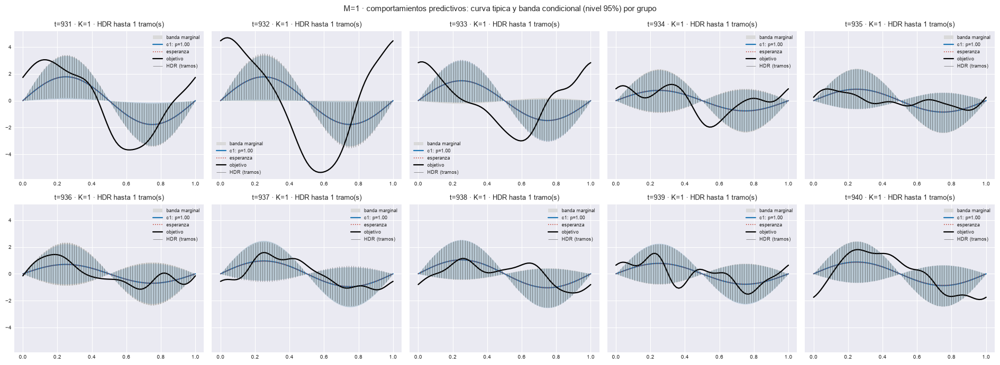

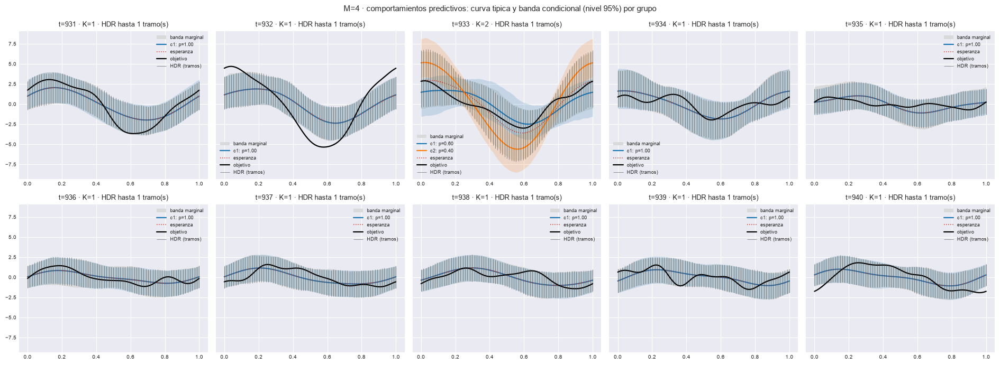

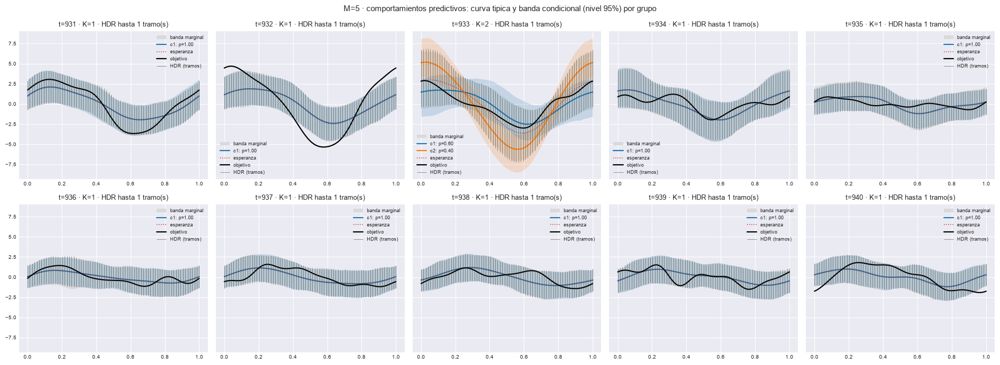

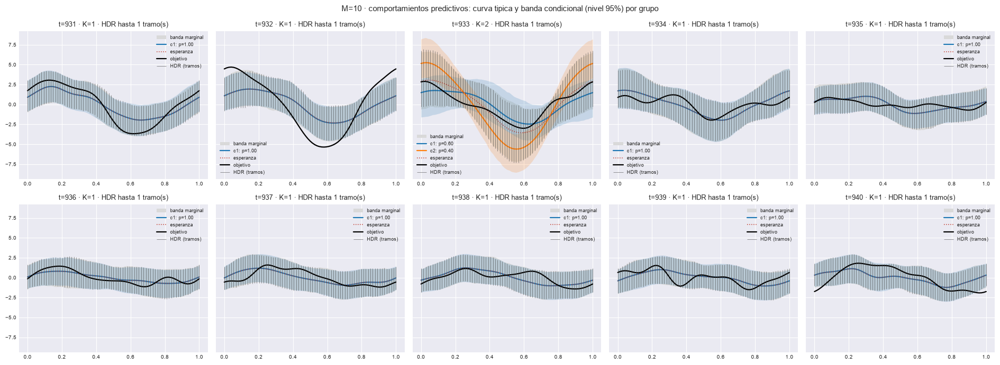

In [29]:
ESTILO_INT = {"equicolas": "#2c7fb8", "simultanea": "#8856a7", "hdr": "#2ca25f"}


def figura_origen(e, i, M, save_path):
    # Un origen: objetivo, los predictores, equi-colas, simultánea, tramos de la HDR y curvas típicas.
    C, (Ls, Us), (Lh, Uh) = e["COMP"], e["INTERVALOS"]["simultanea"], e["INTERVALOS"]["hdr"]
    fig, ax = plt.subplots(figsize=(8.6, 4.6))
    ax.fill_between(grilla, Ls[i, :, 0], Us[i, :, 0], color=ESTILO_INT["simultanea"], alpha=0.12, lw=0,
                    label="banda simultánea")
    ax.fill_between(grilla, e["li_f"][i], e["ls_f"][i], color=ESTILO_INT["equicolas"], alpha=0.22, lw=0,
                    label="equi-colas")
    for k in range(Lh.shape[2]):
        ok = np.isfinite(Lh[i, :, k])
        ax.vlines(grilla[ok], Lh[i, ok, k], Uh[i, ok, k], color=ESTILO_INT["hdr"], lw=1.1, alpha=0.75,
                  label="HDR (tramos)" if k == 0 else None)
    for c in range(int(C["K"][i])):
        ax.plot(grilla, C["curvas"][i, c], color="0.3", lw=0.8 + 2.4 * C["masas"][i, c], ls=(0, (4, 2)),
                label=f"comportamiento {c + 1}: p = {C['masas'][i, c]:.2f}")
    for pr in PREDICTORES:
        ax.plot(grilla, e["X_PRED"][pr][i], label=pr, **ESTILOS_PREDICTORES.get(pr, {}))
    ax.plot(grilla, X_obj_ev[i], color="k", lw=2.0, label="observada (objetivo)")
    ax.set_title(f"M={M} · t={int(t_orig[i])} · K={int(C['K'][i])} · HDR hasta "
                 f"{int(e['hdr_tramos'][i].max())} tramo(s)", fontsize=10)
    ax.set_xlabel(r"$\tau$")
    ax.legend(fontsize=7, ncol=2, loc="best")
    fig.tight_layout()
    fig.savefig(str(save_path), dpi=150, bbox_inches="tight")
    return fig


for M in (m for m in M_DETALLE if m in M_OK):
    e = EST[M]
    plot_comportamientos(e["COMP"], list(IDX_DET), X_obj_ev, e["li_f"], e["ls_f"], grilla, t_orig, M,
                         X_esp=e["X_pred"], hdr=e["INTERVALOS"]["hdr"], ncols=5,
                         save_path=e["paths"]["out_report"] / "63_comportamientos_ejemplos.png")
    plt.show()
    for i in IDX_DET:
        figura_origen(e, i, M, e["paths"]["out_report"] / f"63_detalle_t{int(t_orig[i])}.png")
        plt.close()

### 12.3 Catálogo global

Las mismas reglas sobre los centroides de la ventana, ponderados por masa.

M= 1: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 2: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 3: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 4: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 5: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 6: catalogo global con L=1 comportamiento(s), masas [1.0]


M= 7: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 8: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 9: catalogo global con L=1 comportamiento(s), masas [1.0]
M=10: catalogo global con L=1 comportamiento(s), masas [1.0]


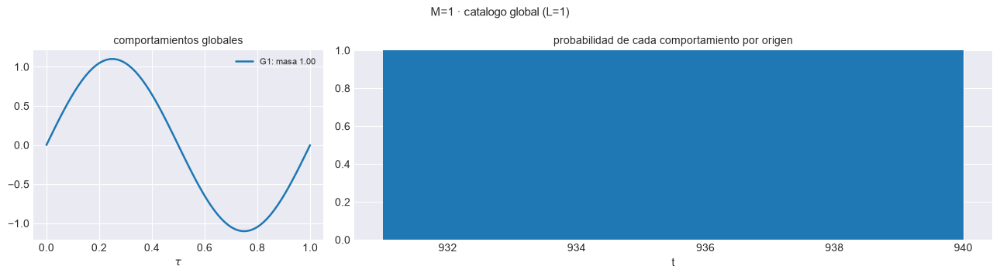

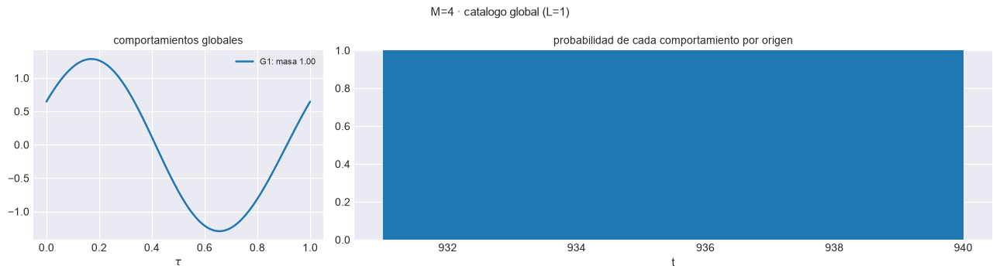

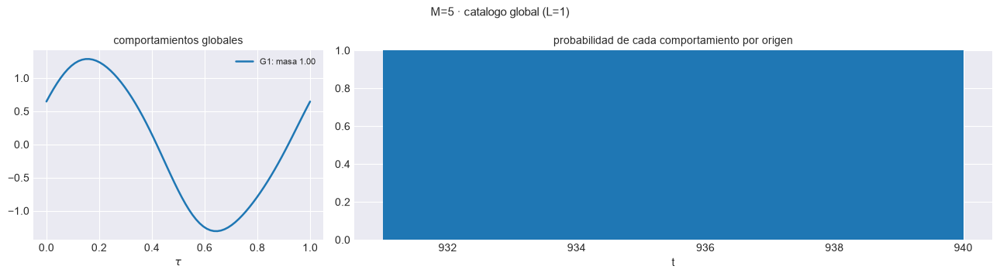

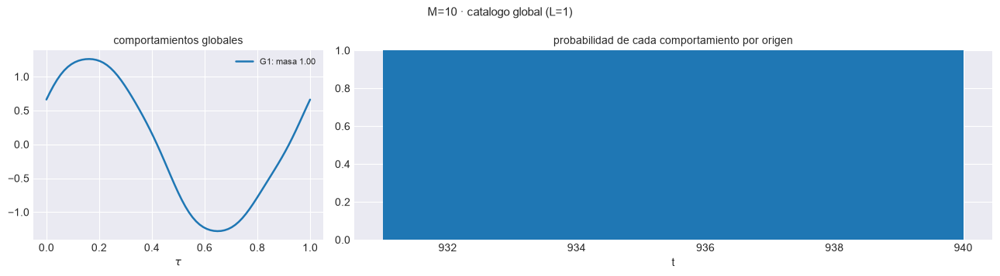

In [30]:
CAT_BAR = catalogo_barrido(EST, M_OK, ORIG_DET, PATH_BARRIDO)
for M in (m for m in M_DETALLE if m in M_OK):
    plot_catalogo(EST[M]["CATALOGO"], grilla, t_orig, M,
                  save_path=EST[M]["paths"]["out_report"] / "64_catalogo_global.png")
    plt.show()

### 12.4 $K$ y banda contra la varianza condicional verdadera

Sin régimen que validar: distribución de $K$ (se espera 1) y, fuera de las diez métricas, el ancho de cada construcción contra la banda oráculo de $h_t$ (`fit/heterocedasticidad.py`): Spearman, razón de anchos y CV.

,1,2,3,4,5,6,7,8,9,10
K,,,,,,,,,,
1,10,9,9,9,9,9,9,9,9,9
2,0,1,1,1,1,1,1,1,1,1
3,0,0,0,0,0,0,0,0,0,0


,,spearman,pearson,ancho_psbp,ancho_oraculo,razon_ancho,cv_psbp,cv_oraculo
intervalo,M,,,,,,,
equicolas,1,0.782,0.811,1.981,1.804,1.098,0.049,0.146
simultanea,1,0.588,0.729,1.984,1.804,1.099,0.040,0.146
hdr,1,0.782,0.822,1.986,1.804,1.100,0.044,0.146
equicolas,2,0.952,0.915,3.287,3.652,0.900,0.248,0.266
simultanea,2,0.939,0.912,4.529,3.652,1.240,0.313,0.266
hdr,2,0.976,0.918,3.292,3.652,0.902,0.245,0.266
equicolas,3,0.915,0.918,3.532,3.836,0.921,0.225,0.242
simultanea,3,0.903,0.902,5.119,3.836,1.334,0.265,0.242
hdr,3,0.915,0.917,3.543,3.836,0.924,0.226,0.242


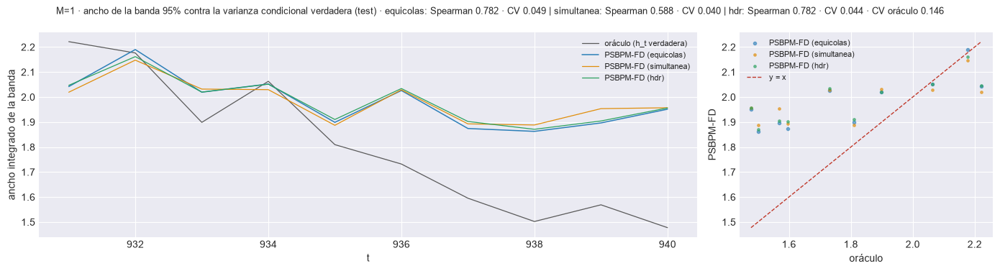

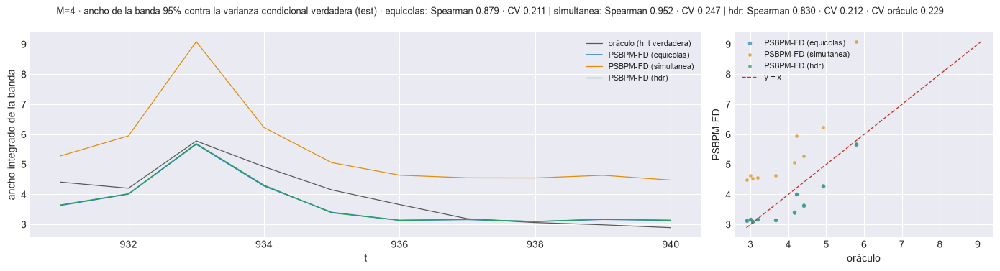

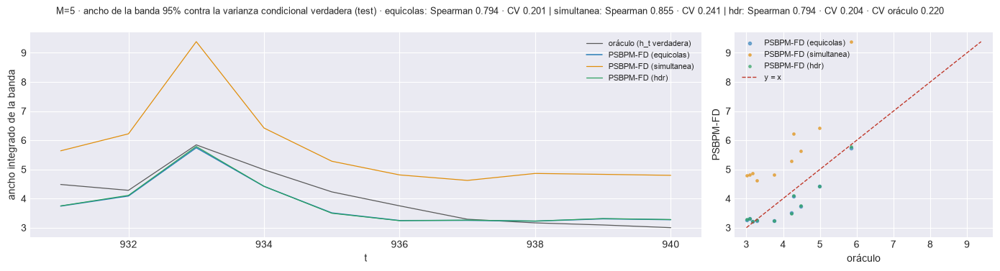

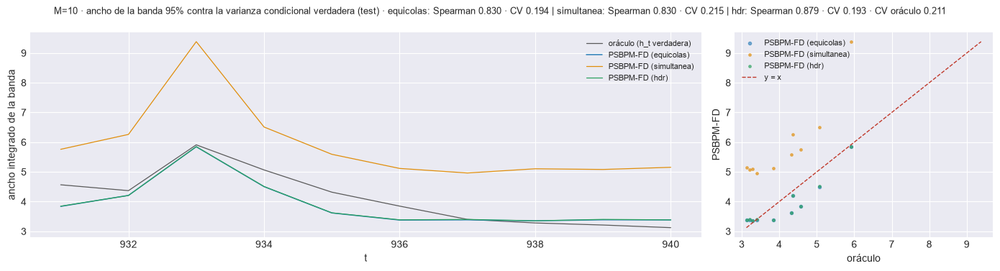

In [31]:
K_DET = pd.DataFrame({M: np.bincount(EST[M]["COMP"]["K"][IDX_DET], minlength=4)[1:] for M in M_OK},
                     index=pd.Index([1, 2, 3], name="K"))
display(K_DET.style.set_caption(f"Ventana de detalle · orígenes (de {N_DETALLE}) con K comportamientos"))

# ORIG_DET: el bloque "test" de la tabla es la ventana; se reetiqueta "detalle".
BANDA_HT = banda_contra_varianza_condicional(EST, M_OK, DIS, ORIG_DET, esc, intervalos=INTERVALOS)
BANDA_HT = BANDA_HT[BANDA_HT.bloque == "test"].assign(bloque="detalle")
BANDA_HT.to_csv(PATH_BARRIDO / "104_banda_vs_varianza_condicional_por_M.csv", index=False)
display(BANDA_HT.pivot_table(index=["objeto", "intervalo"], columns="M", values="spearman").style.format("{:.3f}", na_rep="-")
        .background_gradient(cmap="RdYlGn", vmin=-1, vmax=1, axis=None)
        .set_caption(f"Ventana de detalle ({N_DETALLE} orígenes, descriptivo) · Spearman entre el ancho de la banda del PSBPM-FD y el de la banda con h_t verdadera"))
display(BANDA_HT[BANDA_HT.objeto == "curva"].set_index(["intervalo", "M"])[
            ["spearman", "pearson", "ancho_psbp", "ancho_oraculo", "razon_ancho", "cv_psbp", "cv_oraculo"]]
        .style.format("{:.3f}")
        .set_caption("Ventana de detalle · curva: ancho integrado de la banda contra el oráculo (104_banda_vs_varianza_condicional_por_M.csv)"))
for M in (m for m in M_DETALLE if m in M_OK):
    plot_banda_contra_varianza(EST[M], ORIG_DET, DIS, M,
                               save_path=EST[M]["paths"]["out_report"] / "65_banda_vs_varianza_condicional.png")
    plt.show()

### 12.5 Ventana de detalle, origen por origen

`112_ventana_detalle_por_origen.csv`: $K$ y masas, tramos de la HDR, longitud y cobertura de cada intervalo, verdad del generador y error de cada predictor.

In [32]:
wn, filas = pesos_normalizados(grilla, PESOS_TAU), []
for M in M_OK:
    e, C = EST[M], EST[M]["COMP"]
    nm = {pr: normas_error_por_origen(X_obj_ev[IDX_DET], e["X_PRED"][pr][IDX_DET], grilla,
                                      pesos_tau=PESOS_TAU, verificar=False) for pr in PREDICTORES}
    for j, i in enumerate(IDX_DET):
        fila = {"M": M, "t": int(t_orig[i]), "K": int(C["K"][i]),
                **{f"p_{c + 1}": float(C["masas"][i, c]) for c in range(int(C["K"][i]))},
                "hdr_tramos_max": int(e["hdr_tramos"][i].max())}
        for nombre, (L, U) in e["INTERVALOS"].items():
            fila[f"long_{nombre}"] = float(ancho_tramos(L[i], U[i]) @ wn)
            fila[f"cob_{nombre}"] = float(cobertura_tramos(X_obj_ev[i], L[i], U[i]).mean())
        for pr in PREDICTORES:
            fila[f"mae_{pr}"], fila[f"rmse_{pr}"] = float(nm[pr]["l1"][j]), float(nm[pr]["l2"][j])
        fila.update({k: v[i] for k, v in VERDAD_DET.items()})
        filas.append(fila)
DETALLE = pd.DataFrame(filas)
DETALLE.to_csv(PATH_BARRIDO / "112_ventana_detalle_por_origen.csv", index=False)
for M in (m for m in M_DETALLE if m in M_OK):
    display(DETALLE[DETALLE.M == M].drop(columns="M").set_index("t").style.format(precision=3)
            .set_caption(f"M={M} · ventana de detalle origen por origen (112_ventana_detalle_por_origen.csv)"))

,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,h_agregada,h_1,h_2,h_3,h_4,p_2
t,,,,,,,,,,,,,,,,,,,,,,,
931,1,1.000,1,2.042,0.427,2.019,0.427,2.047,0.427,1.312,1.531,1.296,1.518,1.296,1.518,1.278,1.504,1.281,0.793,2.847,0.409,0.472,nan
932,1,1.000,1,2.190,0.253,2.148,0.253,2.162,0.253,2.812,3.167,2.811,3.165,2.811,3.166,2.809,3.164,1.160,0.761,2.374,0.617,0.401,nan
933,1,1.000,1,2.019,0.293,2.032,0.253,2.020,0.280,1.717,1.850,1.723,1.855,1.723,1.855,1.742,1.873,2.340,0.580,6.985,0.660,0.355,nan
934,1,1.000,1,2.052,0.693,2.029,0.707,2.051,0.693,0.651,0.788,0.657,0.792,0.657,0.792,0.655,0.790,1.636,0.684,4.315,0.510,0.359,nan
935,1,1.000,1,1.899,0.853,1.887,0.867,1.910,0.853,0.415,0.490,0.411,0.485,0.411,0.485,0.417,0.493,1.150,0.526,2.782,0.457,0.627,nan
936,1,1.000,1,2.026,0.840,2.029,0.840,2.034,0.840,0.443,0.491,0.440,0.487,0.440,0.487,0.444,0.492,0.883,0.482,1.798,0.691,0.516,nan
937,1,1.000,1,1.874,0.680,1.893,0.680,1.902,0.680,0.458,0.527,0.471,0.533,0.471,0.533,0.457,0.526,0.667,0.409,1.233,0.527,0.520,nan
938,1,1.000,1,1.863,0.600,1.888,0.613,1.871,0.600,0.631,0.766,0.624,0.757,0.624,0.757,0.638,0.773,0.615,0.363,1.188,0.474,0.425,nan
939,1,1.000,1,1.896,0.733,1.954,0.733,1.904,0.747,0.505,0.629,0.504,0.631,0.504,0.631,0.505,0.630,0.583,0.396,0.879,0.682,0.478,nan


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,h_agregada,h_1,h_2,h_3,h_4,p_2
t,,,,,,,,,,,,,,,,,,,,,,,
931,1,1.000,1,3.636,0.987,5.284,1.000,3.652,0.933,0.918,1.043,0.945,1.077,0.866,0.996,0.995,1.142,1.281,0.793,2.847,0.409,0.472,nan
932,1,1.000,1,4.011,0.440,5.950,0.707,4.023,0.440,2.096,2.355,2.136,2.403,2.190,2.451,2.316,2.587,1.160,0.761,2.374,0.617,0.401,nan
933,2,0.604,1,5.672,1.000,9.087,1.000,5.694,1.000,0.708,0.830,0.620,0.786,0.723,0.875,0.705,0.852,2.340,0.580,6.985,0.660,0.355,0.396
934,1,1.000,1,4.282,1.000,6.226,1.000,4.310,1.000,0.684,0.771,0.646,0.726,0.581,0.661,0.500,0.573,1.636,0.684,4.315,0.510,0.359,nan
935,1,1.000,1,3.402,1.000,5.058,1.000,3.386,1.000,0.513,0.601,0.512,0.598,0.518,0.611,0.576,0.667,1.150,0.526,2.782,0.457,0.627,nan
936,1,1.000,1,3.138,1.000,4.640,1.000,3.139,1.000,0.383,0.426,0.386,0.430,0.405,0.456,0.367,0.420,0.883,0.482,1.798,0.691,0.516,nan
937,1,1.000,1,3.163,1.000,4.553,1.000,3.169,1.000,0.576,0.662,0.583,0.660,0.627,0.717,0.577,0.668,0.667,0.409,1.233,0.527,0.520,nan
938,1,1.000,1,3.097,1.000,4.549,1.000,3.102,1.000,0.529,0.660,0.525,0.651,0.500,0.620,0.566,0.698,0.615,0.363,1.188,0.474,0.425,nan
939,1,1.000,1,3.168,1.000,4.637,1.000,3.176,1.000,0.535,0.696,0.524,0.683,0.541,0.689,0.540,0.689,0.583,0.396,0.879,0.682,0.478,nan


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,h_agregada,h_1,h_2,h_3,h_4,p_2
t,,,,,,,,,,,,,,,,,,,,,,,
931,1,1.000,1,3.741,1.000,5.638,1.000,3.747,1.000,0.926,1.028,0.955,1.062,0.860,0.958,1.006,1.127,1.281,0.793,2.847,0.409,0.472,nan
932,1,1.000,1,4.088,0.453,6.221,0.747,4.109,0.440,2.102,2.354,2.140,2.398,2.194,2.450,2.318,2.586,1.160,0.761,2.374,0.617,0.401,nan
933,2,0.604,1,5.743,1.000,9.383,1.000,5.787,1.000,0.703,0.823,0.621,0.777,0.698,0.833,0.704,0.844,2.340,0.580,6.985,0.660,0.355,0.396
934,1,1.000,1,4.418,1.000,6.418,1.000,4.419,1.000,0.662,0.744,0.626,0.700,0.709,0.797,0.475,0.532,1.636,0.684,4.315,0.510,0.359,nan
935,1,1.000,1,3.507,1.000,5.280,1.000,3.495,1.000,0.488,0.588,0.484,0.582,0.469,0.597,0.550,0.654,1.150,0.526,2.782,0.457,0.627,nan
936,1,1.000,1,3.246,1.000,4.810,1.000,3.241,1.000,0.381,0.424,0.386,0.431,0.406,0.457,0.365,0.418,0.883,0.482,1.798,0.691,0.516,nan
937,1,1.000,1,3.252,1.000,4.622,1.000,3.260,1.000,0.579,0.664,0.583,0.656,0.474,0.571,0.580,0.670,0.667,0.409,1.233,0.527,0.520,nan
938,1,1.000,1,3.225,1.000,4.861,1.000,3.227,1.000,0.526,0.658,0.520,0.645,0.523,0.635,0.566,0.695,0.615,0.363,1.188,0.474,0.425,nan
939,1,1.000,1,3.304,1.000,4.830,1.000,3.314,1.000,0.525,0.686,0.514,0.671,0.579,0.714,0.526,0.677,0.583,0.396,0.879,0.682,0.478,nan


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,h_agregada,h_1,h_2,h_3,h_4,p_2
t,,,,,,,,,,,,,,,,,,,,,,,
931,1,1.000,1,3.838,1.000,5.759,1.000,3.845,1.000,0.917,1.026,0.945,1.059,0.848,0.969,0.998,1.125,1.281,0.793,2.847,0.409,0.472,nan
932,1,1.000,1,4.208,0.493,6.260,0.747,4.206,0.440,2.101,2.355,2.141,2.399,2.167,2.450,2.318,2.586,1.160,0.761,2.374,0.617,0.401,nan
933,2,0.604,1,5.844,1.000,9.382,1.000,5.849,1.000,0.704,0.823,0.622,0.775,0.571,0.775,0.693,0.844,2.340,0.580,6.985,0.660,0.355,0.396
934,1,1.000,1,4.503,1.000,6.509,1.000,4.508,1.000,0.653,0.734,0.624,0.698,0.701,0.786,0.460,0.511,1.636,0.684,4.315,0.510,0.359,nan
935,1,1.000,1,3.618,1.000,5.591,1.000,3.622,1.000,0.483,0.590,0.474,0.579,0.548,0.643,0.541,0.660,1.150,0.526,2.782,0.457,0.627,nan
936,1,1.000,1,3.379,1.000,5.116,1.000,3.386,1.000,0.383,0.432,0.388,0.440,0.387,0.474,0.369,0.429,0.883,0.482,1.798,0.691,0.516,nan
937,1,1.000,1,3.386,1.000,4.963,1.000,3.400,1.000,0.584,0.663,0.582,0.652,0.558,0.649,0.584,0.671,0.667,0.409,1.233,0.527,0.520,nan
938,1,1.000,1,3.353,1.000,5.104,1.000,3.354,1.000,0.529,0.657,0.520,0.648,0.520,0.646,0.568,0.695,0.615,0.363,1.188,0.474,0.425,nan
939,1,1.000,1,3.388,1.000,5.081,1.000,3.401,1.000,0.532,0.684,0.522,0.671,0.475,0.604,0.536,0.678,0.583,0.396,0.879,0.682,0.478,nan
